[info] Using loop corrections up to order: 0


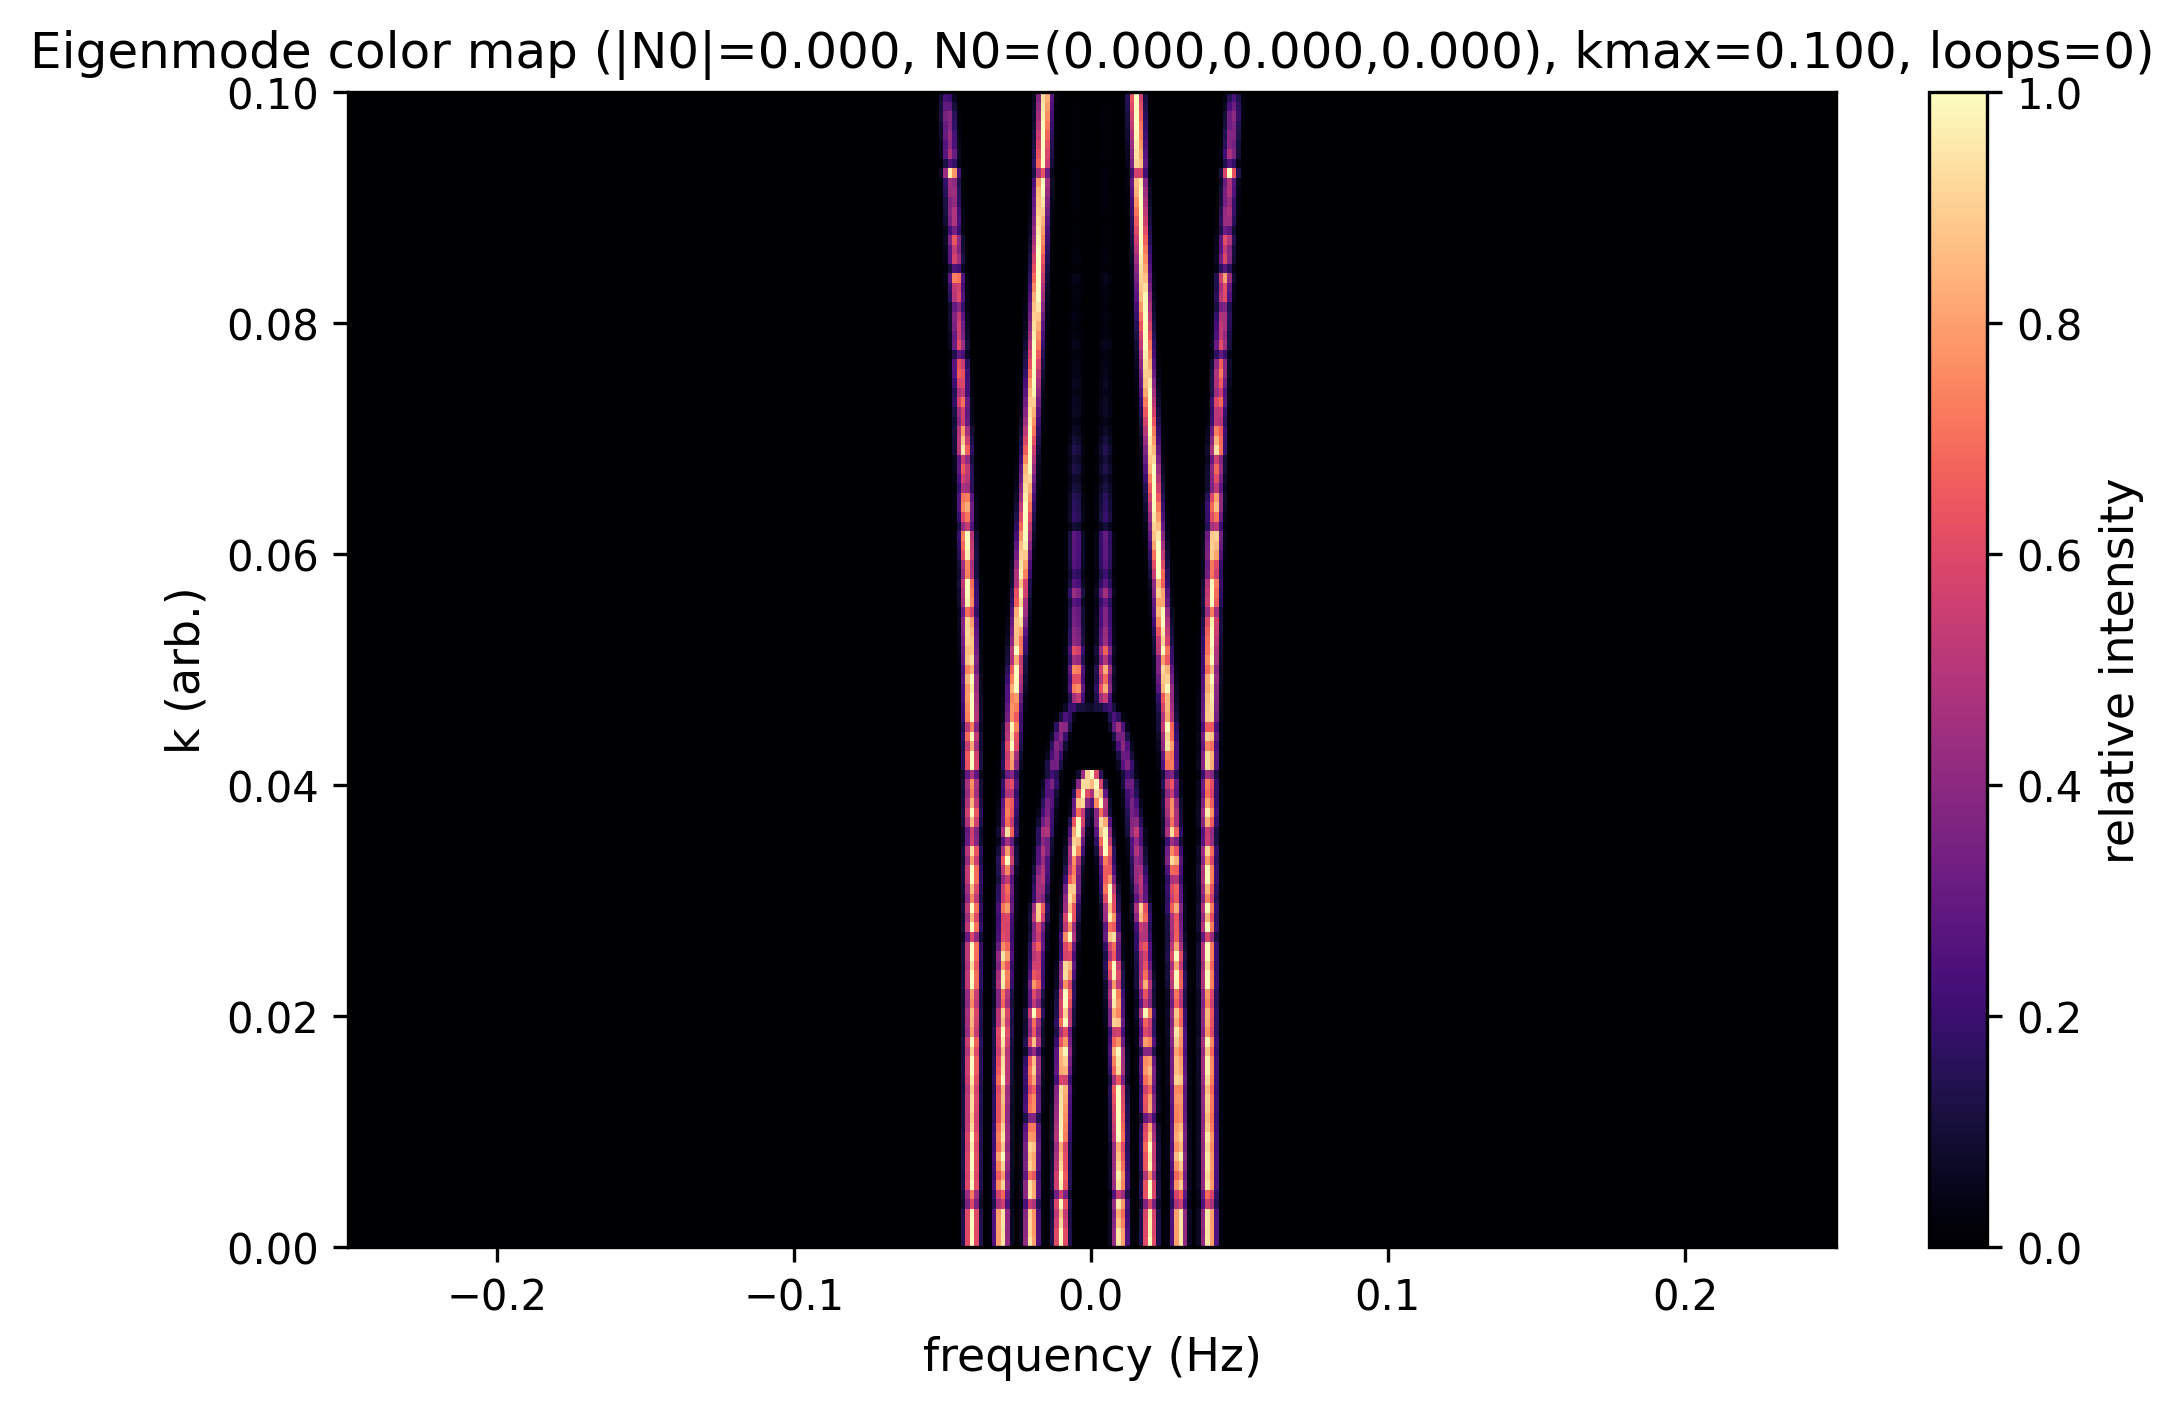

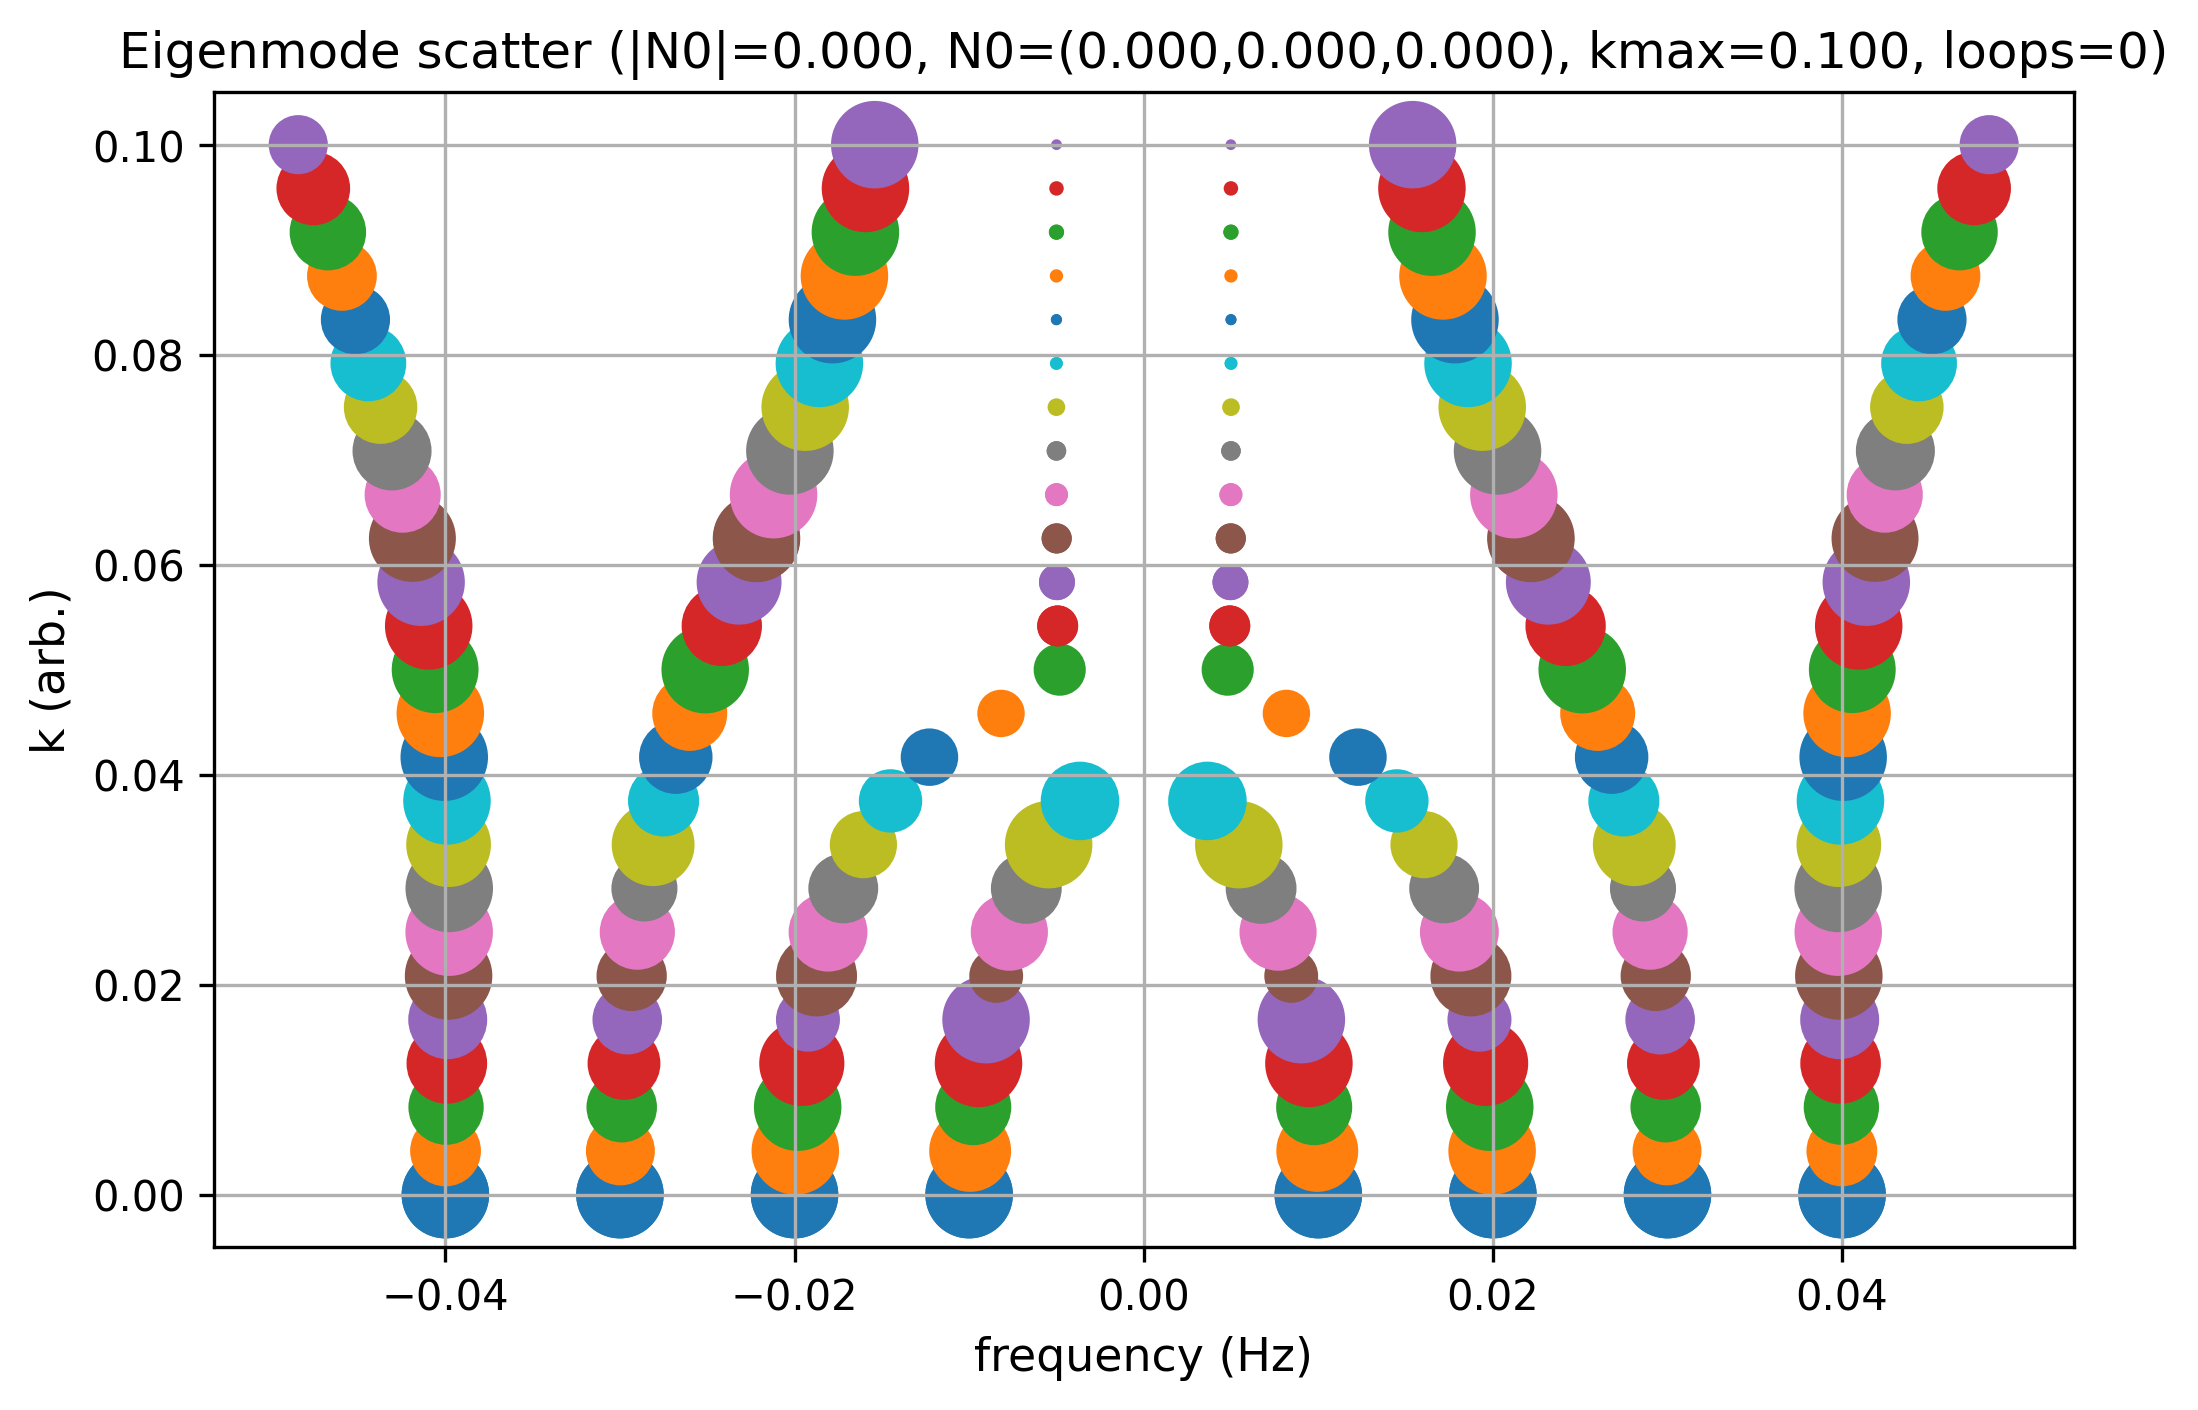

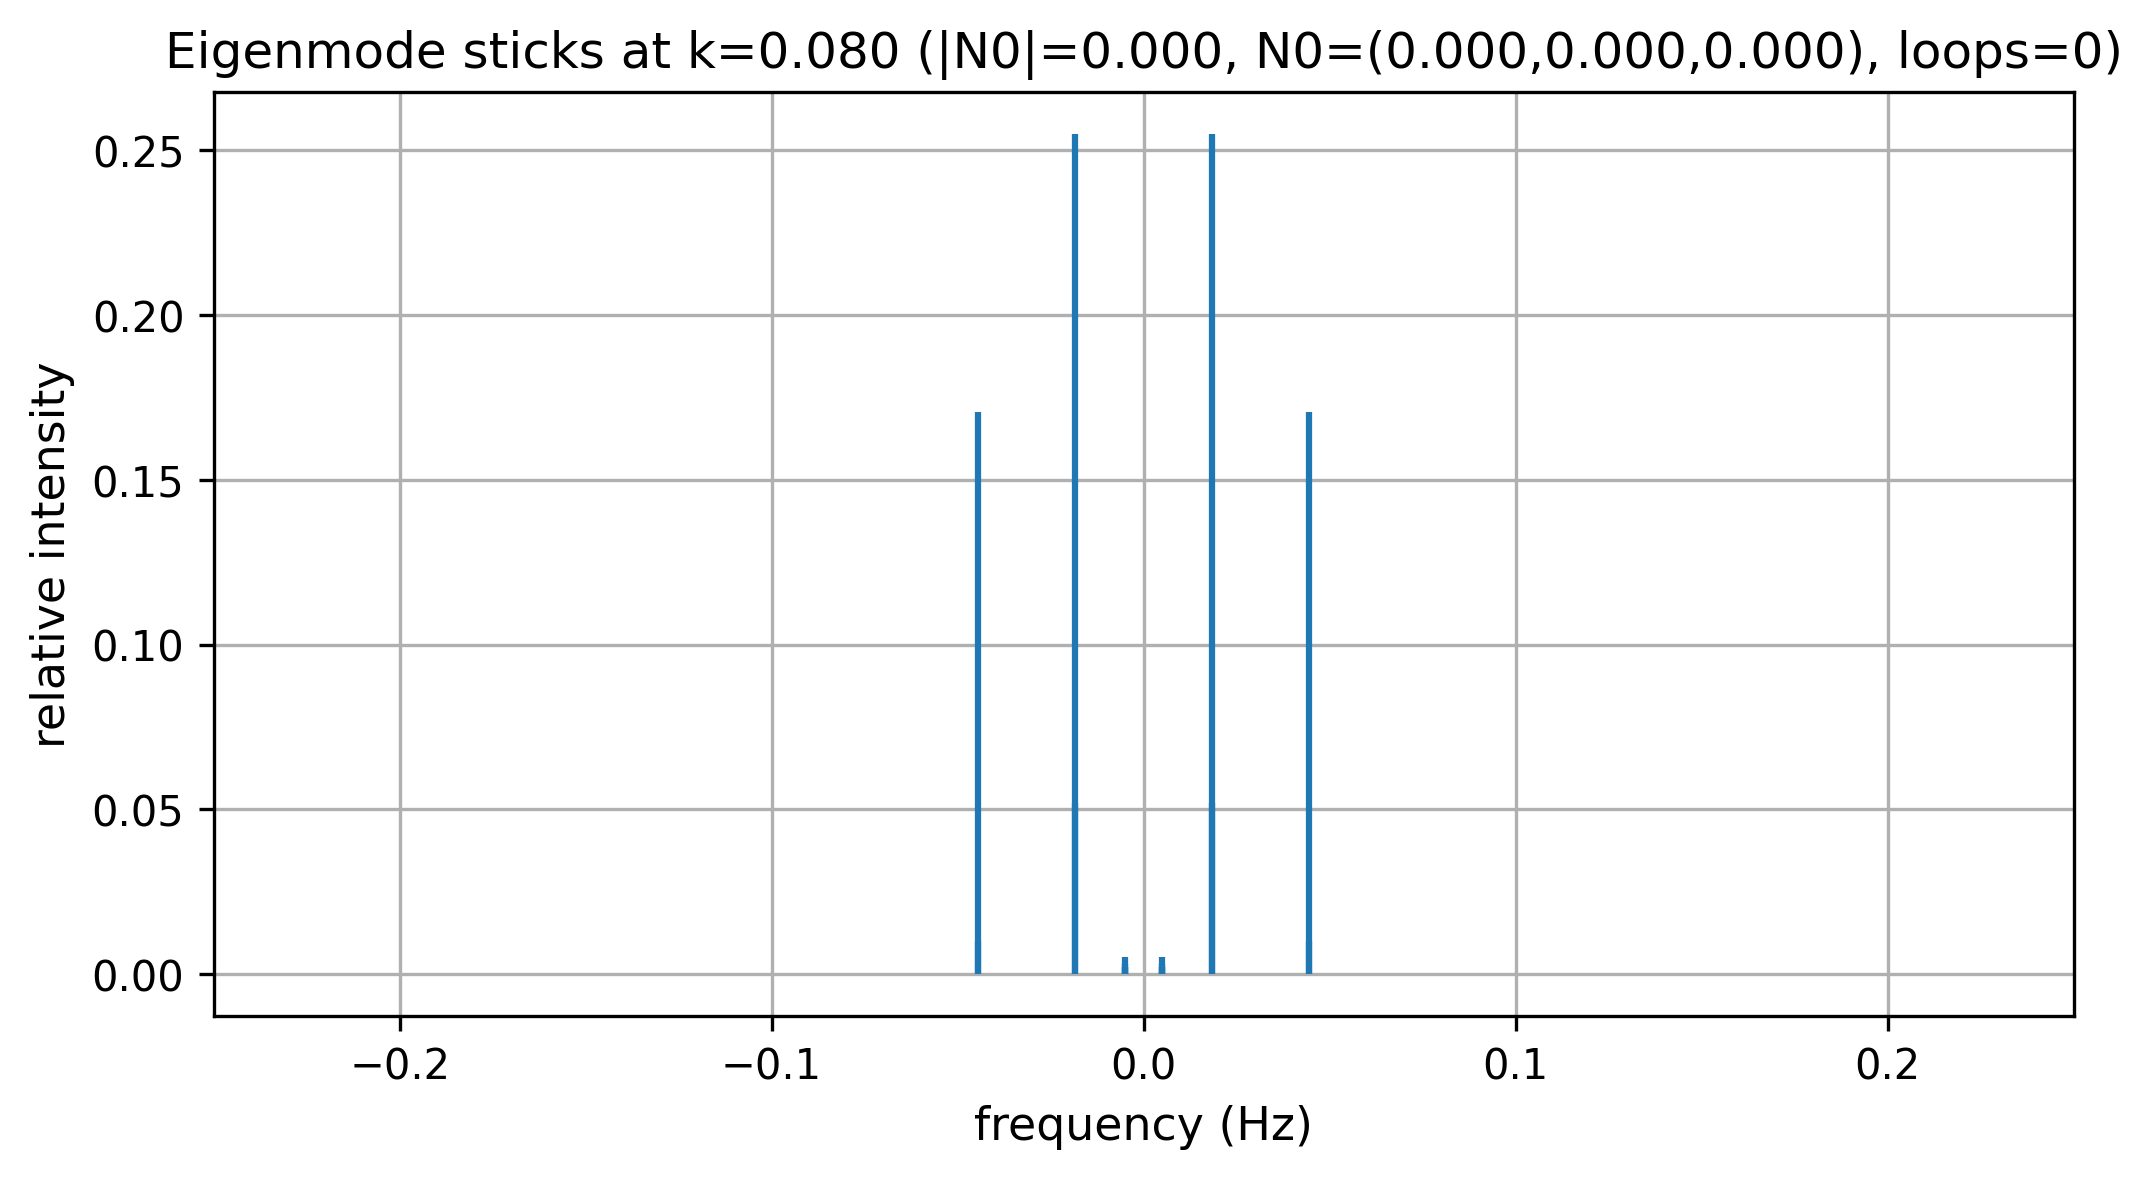

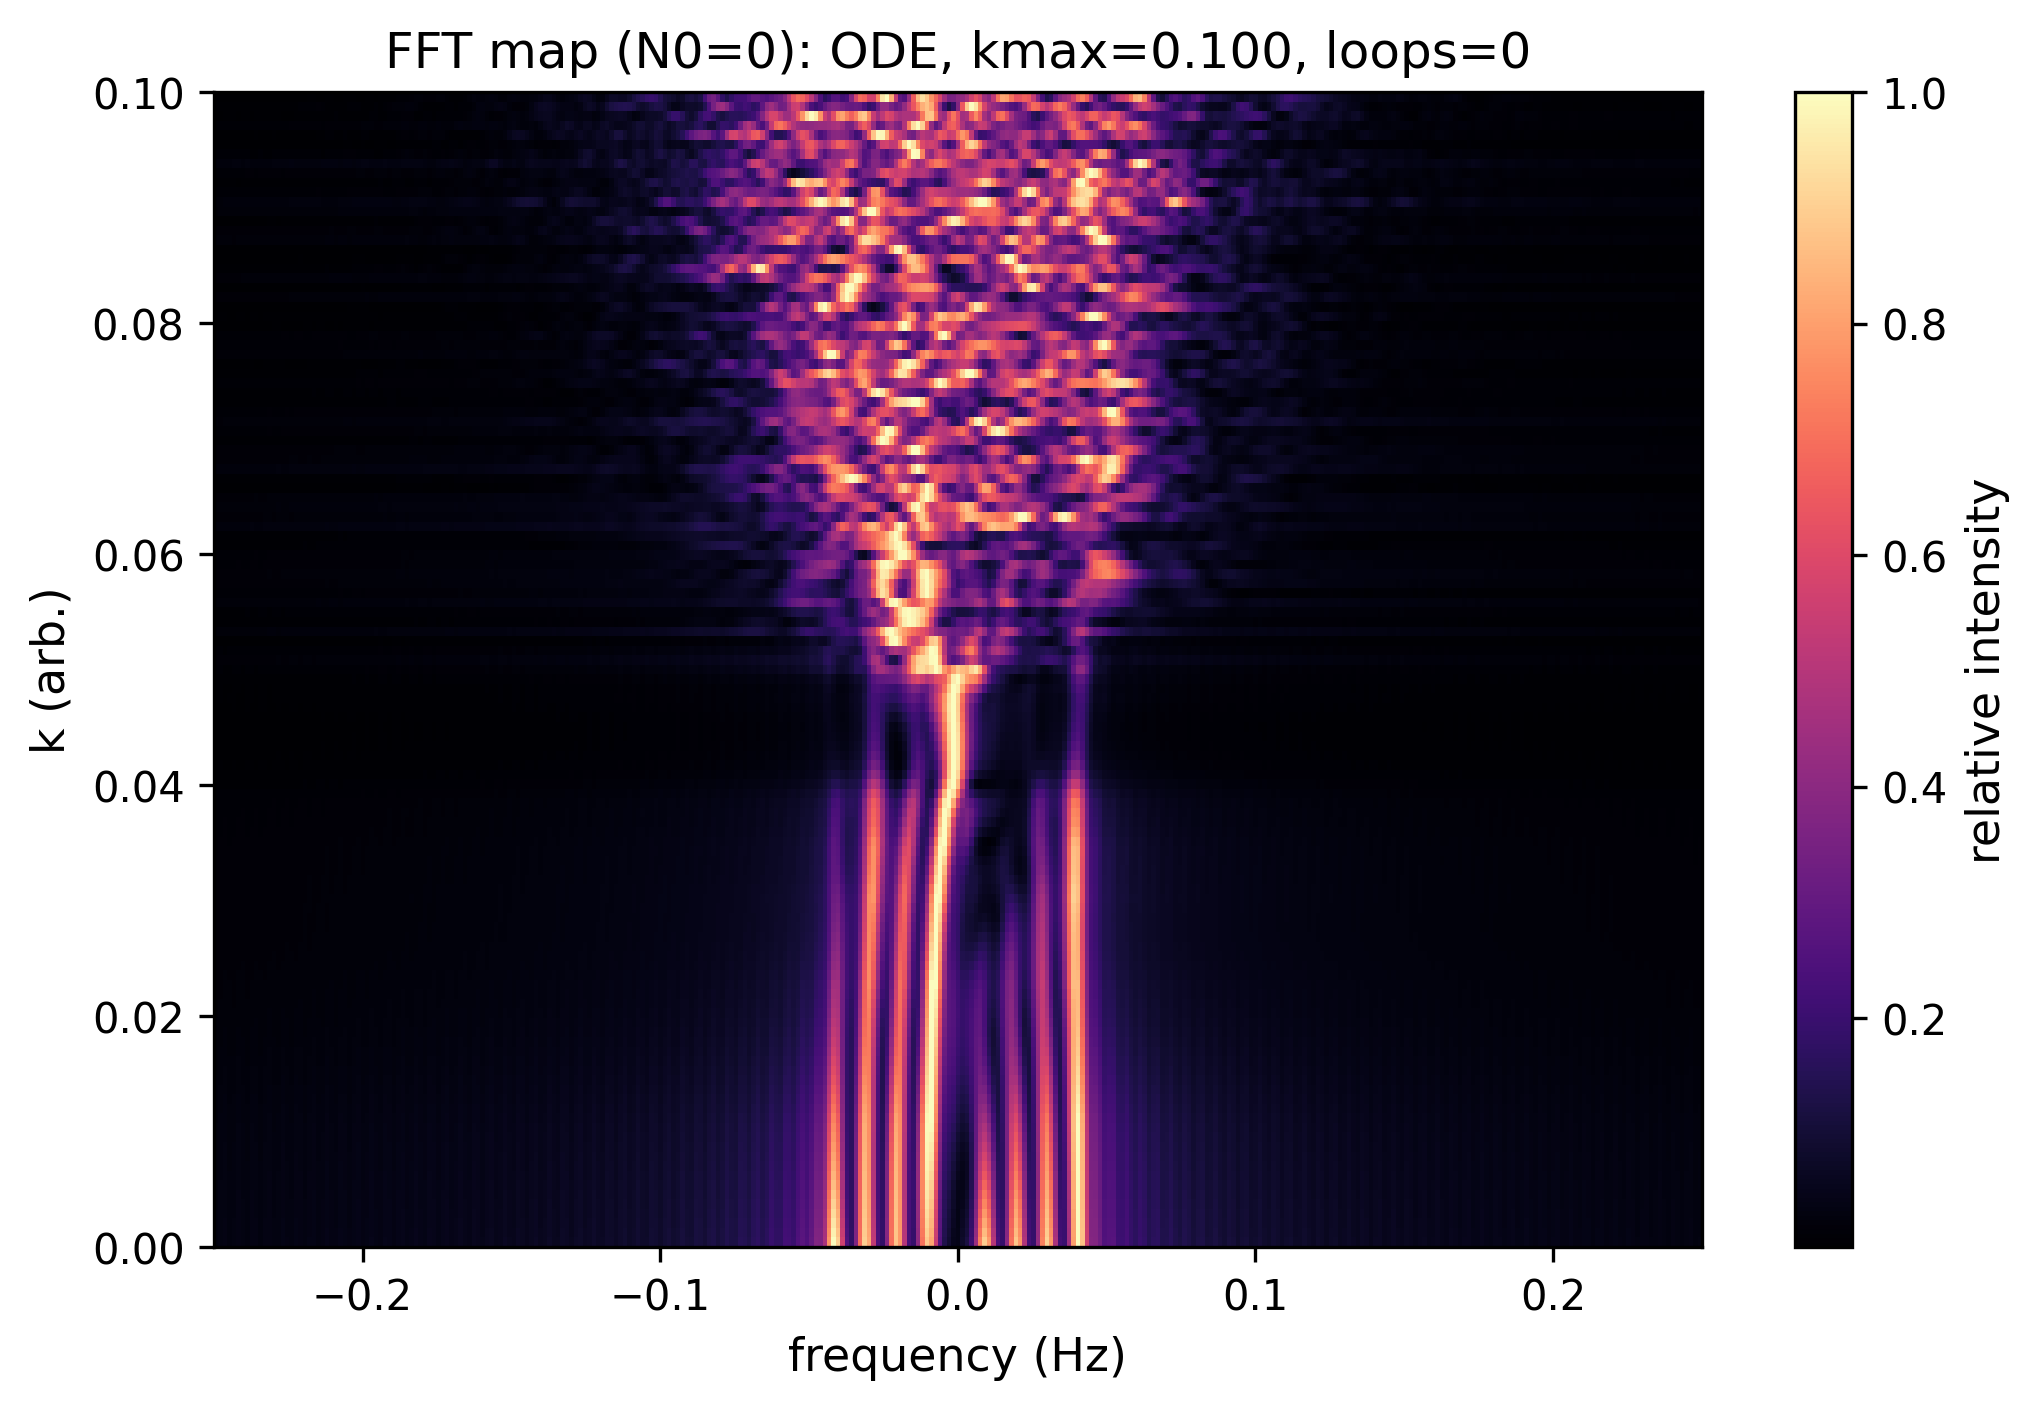

In [33]:
# spinpacket.py

"""
spinpacket.py — Integrated mesoscopic spin packet simulator built from the validated native + Gaussian components of the loop-series, with loop-dressed LLB-like packet dynamics,
optional stochastic torque (SDE) + geometric drift (Itô), short-memory damping (Prony),
strictly validated Gaussian entanglement diagnostics, and an additional engineered
quadratic-Gaussian Hamiltonian layer for squeezing / cluster-state demonstrations.

Core design choices in spinpacket.py:
- The covariance of a classically propagated ensemble of M-trajectories is treated only
  as a diagnostic proxy, not as a quantum covariance matrix.
- Certified entanglement is reported only for a validated Gaussian quantum model. In the
  present code, that validated model is the engineered quadratic-Gaussian layer.
- On the native branch with N(0)=0, the implemented drift/noise/memory terms preserve the
  exact invariant manifold N(t)=0, so certified native entanglement is forced to the
  separable baseline.

Noise is white, Gaussian, tangent-projected; calculus = Itô (Euler–Maruyama + geometric drift)
or Stratonovich (Heun). Defaults reproduce the original deterministic ODE.

Stability: safety clamps prevent blow-ups in N-sector mixing and fields and restore the
exact packet Casimir |M|^2+|N|^2 = R^2 after each step.
"""

import argparse, sys, os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from numpy.linalg import norm, eig
from numpy.random import default_rng
from typing import Tuple, Optional
from scipy.integrate import solve_ivp
from scipy.linalg import expm
import itertools
import shlex

HBAR = 1.0

SPINPACKET_VERSION = "spinpacket"

# Entanglement globals (set from CLI)
ENT_CV_ROT = 0

# Safety/stability
SAFETY_CFG = {
    'clip_kNa': 2.0,            # cap for k*|N| in mixing field (dimensionless)
    'clip_field': 10.0,         # cap for |BN| magnitude (rad/s) per packet
    'renorm_sum_sphere': 1,     # 1 => restore the exact packet Casimir |M|^2+|N|^2 = R^2
    'sphere_radius': 1.0,       # sphere radius for M,N renorm (units of code)
    'max_norm_individual': 1.5  # retained for backward compatibility; not used by the exact sphere projector
}


RENORM_DIAG = {
    'count': 0,
    'sum_abs': 0.0,
    'max_abs': 0.0,
    'count_any': 0,
    'sum_state_rel': 0.0,
    'max_state_rel': 0.0,
    'sum_ortho_rel_pre': 0.0,
    'max_ortho_rel_pre': 0.0,
    'sum_ortho_rel_post': 0.0,
    'max_ortho_rel_post': 0.0,
    'sum_branch_dev_pre': 0.0,
    'max_branch_dev_pre': 0.0,
}

def reset_renorm_diag():
    RENORM_DIAG['count'] = 0
    RENORM_DIAG['sum_abs'] = 0.0
    RENORM_DIAG['max_abs'] = 0.0
    RENORM_DIAG['count_any'] = 0
    RENORM_DIAG['sum_state_rel'] = 0.0
    RENORM_DIAG['max_state_rel'] = 0.0
    RENORM_DIAG['sum_ortho_rel_pre'] = 0.0
    RENORM_DIAG['max_ortho_rel_pre'] = 0.0
    RENORM_DIAG['sum_ortho_rel_post'] = 0.0
    RENORM_DIAG['max_ortho_rel_post'] = 0.0
    RENORM_DIAG['sum_branch_dev_pre'] = 0.0
    RENORM_DIAG['max_branch_dev_pre'] = 0.0

def _safe_unit(v: np.ndarray, fallback: Optional[np.ndarray]=None) -> np.ndarray:
    v = np.asarray(v, float).reshape(3)
    nv = norm(v)
    if np.isfinite(nv) and nv > 1e-15:
        return v / nv
    if fallback is None:
        fallback = np.array([0.0, 0.0, 1.0], float)
    else:
        fallback = np.asarray(fallback, float).reshape(3)
    nf = norm(fallback)
    if np.isfinite(nf) and nf > 1e-15:
        return fallback / nf
    return np.array([0.0, 0.0, 1.0], float)

def renorm_packet(Mj: np.ndarray, Nj: np.ndarray) -> Tuple[np.ndarray,np.ndarray]:
    """
    Geometric restoration of the exact rotated coherent-state constraints
        |M|^2 + |N|^2 = R^2,
        M · N = 0.

    We reconstruct the forward/backward branch vectors
        n^F = (M + N) / R,
        n^B = (M - N) / R,
    normalize those branch vectors separately to unit norm, and then rebuild
    (M,N). This is a numerical constraint restoration, not a physical state
    renormalization.
    """
    Mj = np.asarray(Mj, float).reshape(3).copy()
    Nj = np.asarray(Nj, float).reshape(3).copy()

    R = float(SAFETY_CFG['sphere_radius'])
    if R <= 0.0:
        return Mj, Nj
    if not (np.all(np.isfinite(Mj)) and np.all(np.isfinite(Nj))):
        return Mj, Nj

    s2 = float(Mj.dot(Mj) + Nj.dot(Nj))
    if np.isfinite(s2) and s2 > 0.0:
        corr = abs(np.sqrt(s2) - R)
        if corr > 1e-12:
            RENORM_DIAG['count'] += 1
            RENORM_DIAG['sum_abs'] += corr
            if corr > RENORM_DIAG['max_abs']:
                RENORM_DIAG['max_abs'] = corr

    ortho_rel_pre = abs(float(Mj.dot(Nj))) / (R * R)
    RENORM_DIAG['sum_ortho_rel_pre'] += ortho_rel_pre
    if ortho_rel_pre > RENORM_DIAG['max_ortho_rel_pre']:
        RENORM_DIAG['max_ortho_rel_pre'] = ortho_rel_pre

    nF_raw = (Mj + Nj) / R
    nB_raw = (Mj - Nj) / R
    nf_norm = norm(nF_raw)
    nb_norm = norm(nB_raw)
    if np.isfinite(nf_norm) and np.isfinite(nb_norm):
        branch_dev = max(abs(nf_norm - 1.0), abs(nb_norm - 1.0))
        RENORM_DIAG['sum_branch_dev_pre'] += branch_dev
        if branch_dev > RENORM_DIAG['max_branch_dev_pre']:
            RENORM_DIAG['max_branch_dev_pre'] = branch_dev

    if norm(Mj) > 1e-15:
        base = Mj
    elif norm(Nj) > 1e-15:
        base = Nj
    else:
        base = np.array([0.0, 0.0, 1.0], float)

    nF = _safe_unit(nF_raw, fallback=base + Nj)
    nB = _safe_unit(nB_raw, fallback=base - Nj)

    Mnew = 0.5 * R * (nF + nB)
    Nnew = 0.5 * R * (nF - nB)

    state_rel = float(np.sqrt(np.dot(Mnew - Mj, Mnew - Mj) + np.dot(Nnew - Nj, Nnew - Nj)) / R)
    if state_rel > 1e-12:
        RENORM_DIAG['count_any'] += 1
        RENORM_DIAG['sum_state_rel'] += state_rel
        if state_rel > RENORM_DIAG['max_state_rel']:
            RENORM_DIAG['max_state_rel'] = state_rel

    ortho_rel_post = abs(float(Mnew.dot(Nnew))) / (R * R)
    RENORM_DIAG['sum_ortho_rel_post'] += ortho_rel_post
    if ortho_rel_post > RENORM_DIAG['max_ortho_rel_post']:
        RENORM_DIAG['max_ortho_rel_post'] = ortho_rel_post

    return Mnew, Nnew

# -----------------------------------------------------------------------------
# Geometry and lattice helpers
# -----------------------------------------------------------------------------
def cube_positions():
    return np.array([[0,0,0],[1,0,0],[1,1,0],[0,1,0],
                     [0,0,1],[1,0,1],[1,1,1],[0,1,1]], float)

# def cube_positions():
#     return np.array([[0,0,0],[1,0,0],[0,1,0],[0,0,1],
#                      [0,1,1],[1,0,1],[1,1,0],[1,1,1]], float)

def neighbor_list(pos):
    N = len(pos)
    nbr = {i: [] for i in range(N)}
    for i in range(N):
        for j in range(N):
            if i==j: 
                continue
            if np.isclose(np.sum(np.abs(pos[i]-pos[j])), 1.0):  # cube edges
                nbr[i].append(j)
    return nbr

def dipolar_tensor(rhat):
    rhat = np.asarray(rhat, float); rhat /= norm(rhat)
    return 3.0*np.outer(rhat, rhat) - np.eye(3)

# 2D rotation (ẑ × v_perp)
R2 = np.array([[0, 1],[-1, 0]], float)
I2 = np.eye(2, dtype=float)

def C2(v_perp):
    vx, vy = float(v_perp[0]), float(v_perp[1])
    return np.array([[0.0, vx],[vy, 0.0]], float)

def fmt_vec3(v):
    return f"({v[0]:.3f},{v[1]:.3f},{v[2]:.3f})"


# -----------------------------------------------------------------------------
# Plotting configuration
# -----------------------------------------------------------------------------
PLOT_CFG = {
    'dpi': 300,
    'show': 1,
    'cmap': 'magma',
    'font_size': 11.0,
    'transparent': 0,
    'prefix': '',
    'export_data': 1,
}

def _plot_path(fname: str) -> str:
    prefix = str(PLOT_CFG.get('prefix', '')).strip()
    if prefix == '':
        return fname
    return os.path.join(prefix, fname)

def _savefig(fname: str, save: bool=True):
    if not save:
        return
    os.makedirs(os.path.dirname(_plot_path(fname)) or '.', exist_ok=True)
    plt.savefig(_plot_path(fname), dpi=PLOT_CFG['dpi'], bbox_inches='tight',
                transparent=bool(PLOT_CFG['transparent']))

def _show_or_close():
    if bool(PLOT_CFG['show']):
        plt.show()
    else:
        plt.close()

def _save_npz(base_name: str, payload: dict):
    if not bool(PLOT_CFG.get('export_data', 1)):
        return
    path = _plot_path(base_name)
    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    np.savez(path, **payload)

def apply_plot_cfg(args):
    PLOT_CFG['dpi'] = int(getattr(args, 'fig_dpi', 300))
    PLOT_CFG['cmap'] = str(getattr(args, 'fig_cmap', 'magma'))
    PLOT_CFG['font_size'] = float(getattr(args, 'fig_fontsize', 11.0))
    PLOT_CFG['transparent'] = int(getattr(args, 'fig_transparent', 0))
    PLOT_CFG['prefix'] = str(getattr(args, 'outdir', '') or '')
    PLOT_CFG['export_data'] = int(getattr(args, 'export_data', 1))
    no_show = int(getattr(args, 'no_show', 0))
    backend = matplotlib.get_backend().lower()
    PLOT_CFG['show'] = 0 if (no_show == 1 or 'agg' in backend) else 1

    plt.rcParams.update({
        'font.size': PLOT_CFG['font_size'],
        'axes.labelsize': PLOT_CFG['font_size'],
        'axes.titlesize': PLOT_CFG['font_size'] + 1,
        'legend.fontsize': max(PLOT_CFG['font_size'] - 1, 8),
        'xtick.labelsize': max(PLOT_CFG['font_size'] - 1, 8),
        'ytick.labelsize': max(PLOT_CFG['font_size'] - 1, 8),
        'savefig.dpi': PLOT_CFG['dpi'],
        'figure.dpi': PLOT_CFG['dpi'],
        'image.cmap': PLOT_CFG['cmap'],
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
    })
    if not bool(PLOT_CFG['show']):
        def _noop(*args, **kwargs):
            return None
        plt.show = _noop


# Tangent projector on S^2 (extrinsic)
def tangent_projector(v: np.ndarray) -> np.ndarray:
    nrm = norm(v)
    if nrm == 0.0:
        return np.eye(3)
    u = v / nrm
    return np.eye(3) - np.outer(u, u)

# Utility: ensure shape-(n,) array (avoids scalar indexing)
def ensure_array_like(x, n: int) -> np.ndarray:
    if isinstance(x, np.ndarray):
        if x.ndim == 0:
            return np.zeros(n, float) + float(x)
        if x.shape == (n,):
            return x
        return np.zeros(n, float) + np.squeeze(x)
    else:
        return np.zeros(n, float) + float(x)

# Lattice, offsets, caches
N_SPINS = 8
POS  = cube_positions()
NBR  = neighbor_list(POS)
RHAT = {(j,g): (POS[j]-POS[g]) / norm(POS[j]-POS[g]) for j in range(N_SPINS) for g in NBR[j]}
Tcache = {(j,g): dipolar_tensor(RHAT[(j,g)]) for j in range(N_SPINS) for g in NBR[j]}

# Dense (N,N,3,3) tensor for vectorized einsum in RHS
T4 = np.zeros((N_SPINS, N_SPINS, 3, 3), float)
for j in range(N_SPINS):
    for g in NBR[j]:
        T4[j, g] = Tcache[(j, g)]

# Offsets (Hz) and to rad/s
B_INH_HZ = np.array([-0.04,-0.03,-0.02,-0.01, 0.01,0.02,0.03,0.04], float)
B_INH    = 2*np.pi * B_INH_HZ  # rad/s

# Initial conditions
def initial_M_vectors(tip_rad=0.05):
    Rx  = np.array([[1,0,0],
                    [0,np.cos(tip_rad),-np.sin(tip_rad)],
                    [0,np.sin(tip_rad), np.cos(tip_rad)]], float)
    M_dir = Rx @ np.array([0,0,1.0])
    M0 = M_dir / (norm(M_dir) if norm(M_dir)>0 else 1.0)
    return np.tile(M0, (N_SPINS,1))  # (N,3)

def initial_N_vectors_from_vec(Nvec=(0.0,0.0,0.0), pattern='staggered'):
    Nvec = np.asarray(Nvec, float).reshape(3)
    N = np.zeros((N_SPINS,3), float)
    if norm(Nvec) == 0.0:
        return N
    if pattern == 'uniform':
        N[:] = Nvec
    elif pattern == 'staggered':
        for j,p in enumerate(POS):
            s = (-1)**int(p[0]+p[1]+p[2])  # checkerboard
            N[j] = s * Nvec
    else:  # 'noisy'
        eps = 0.05
        N[:] = (1.0 + eps*np.random.randn(N_SPINS,1)) * Nvec
    return N

# -----------------------------------------------------------------------------
# Loop coefficients and runtime configuration
# -----------------------------------------------------------------------------
LOOP_COEFFS = {
    'alpha': {1: 0.0, 2: 0.0, 3: 0.0, 4: 0.0},  # local coherent z-shift: δB_loc/k = Σ α_m |N|^{2m}
    'beta' : {1: 0.0, 2: 0.0, 3: 0.0, 4: 0.0},  # dissipative damping/noise: λ⊥/k = Σ β_m |N|^{2m}
    'sigma': {1: 0.0, 2: 0.0, 3: 0.0, 4: 0.0},  # coherent dipolar-kernel renorm: Z_MM - 1 = Σ σ_m |N|^{2m}
    'kappa': {2: 0.0, 3: 0.0, 4: 0.0},          # coherent back-action renorm: Z_MN - 1 = Σ κ_m |N|^{2(m-1)} (m>=2)
}

CFG = {
    'alpha_k2': 0.0,   # δω multiplier (1 + alpha_k2 * k^2)
    'beta_k2' : 0.0,   # λ⊥ multiplier (1 + beta_k2 * k^2)
    'beta_anis': 0.0,  # anisotropy for damping: λx=λ(1+ba), λy=λ(1-ba)
    'dynamic_mix': 1,  # use k*|N_a(t)| instead of k*|N0| in N mixing
}

# SDE (noise)
SDE_CFG = {
    'on': 0,                 # 0=deterministic path (default)
    'scheme': 'ito',         # 'ito' or 'strat'
    'target': 'M',           # 'M' or 'MN'
    'noise_scale': 0.0,      # D_perp = noise_scale * lambda_perp  (FDT-like)
    'nreal': 1,              # # realizations to average in FFT maps
    'seed': 12345
}

# Memory (Prony expansion)
MEM_CFG = {
    'on': 0,                 # enable short-memory damping
    'target': 'M',           # 'M' or 'MN'
    'L': 0,                  # number of exponentials
    'tau': [],               # list of tau_l (s)
    'a': [],                 # list of a_l (1/s)
    'tangent_only': 1        # 1 => apply to transverse only
}

# Optional explicit local cubic drift for N sector
NONLIN_CFG = {
    'eta_cubic': 0.0,        # explicit |N|^2 * dN scaling (0 disables)
    'prefer_explicit_cubic_over_vertex': 0
}

# CLI helpers (prompts)
def read_yes_no(prompt: str, default: int=0) -> int:
    try:
        s = input(f"{prompt} [0/1] (default {default}): ").strip()
    except EOFError:
        return default
    if s == '': return default
    return 1 if s.strip() in ('1','y','Y','yes','Yes') else 0

def read_float_list(prompt: str, default=None):
    if default is None: default = []
    try:
        s = input(f"{prompt} comma/space sep (default {default}): ").strip()
    except EOFError:
        return list(default)
    if s == '': return list(default)
    return [float(x) for x in s.replace(',', ' ').split()]

def _stdin_is_interactive() -> bool:
    try:
        return (sys.stdin is not None) and bool(sys.stdin.isatty())
    except Exception:
        return False


def _interactive_enabled(args=None) -> bool:
    flag = int(getattr(args, 'interactive', 0)) if args is not None else 0
    return bool(flag == 1 and _stdin_is_interactive())


# Loop coeff utilities
def apply_cli_coeffs(args):
    def set_series(key, vals, start_m):
        if vals is None: return
        for i, v in enumerate(vals, start=start_m):
            if i in LOOP_COEFFS[key]:
                LOOP_COEFFS[key][i] = float(v)
    set_series('alpha', args.alpha, 1)
    set_series('beta',  args.beta,  1)
    set_series('sigma', args.sigma, 1)
    set_series('kappa', args.kappa, 2)
    # runtime scalars
    CFG['alpha_k2']    = float(args.alpha_k2)
    CFG['beta_k2']     = float(args.beta_k2)
    CFG['beta_anis']   = float(args.beta_anis)
    CFG['dynamic_mix'] = int(args.dynamic_mix)

def _poly_sum(coeffs: dict, order: int, x: np.ndarray, m_start: int):
    """Return array of shape (n,) even if all coefficients are zero."""
    n = x.shape[0]
    out = np.zeros(n, float)
    for m in range(m_start, order+1):
        c = coeffs.get(m, 0.0)
        if c:
            out = out + c * (x**m)
    return out


def loop_scalars_global(loop_order: int, N_amp: float, k: float):
    """Global local-shift, damping, and coherent back-action scalars.

    Physics interpretation in spinpacket.py:
      alpha  -> local coherent z-shift (does not directly create entanglement)
      beta   -> damping / diffusion (typically suppressive)
      sigma  -> coherent renormalization of the nonlocal M-M dipolar bilinear
      kappa  -> coherent renormalization of the nonlocal response-mediated back-action

    Only the nonlocal coherent renormalizations (sigma, kappa) can enhance the
    packet-mode entangling channel. They are handled here as multiplicative
    renormalizations of the projected dipolar kernel rather than as local shifts.
    """
    if loop_order <= 0 or k == 0.0:
        return 0.0, 0.0, 1.0
    x = N_amp**2
    domega = k * sum(LOOP_COEFFS['alpha'].get(m, 0.0) * (x**m) for m in range(1, loop_order+1))
    lam    = k * sum(LOOP_COEFFS['beta' ].get(m, 0.0) * (x**m) for m in range(1, loop_order+1))
    domega = domega * (1.0 + CFG['alpha_k2']*(k**2))
    lam    = lam    * (1.0 + CFG['beta_k2'] *(k**2))
    if loop_order >= 4:
        keff = sum(LOOP_COEFFS['kappa'].get(m, 0.0) * (x**(m-1)) for m in range(2, loop_order+1))
        back = float(np.clip(1.0 + keff, 1e-3, 10.0))
    else:
        back = 1.0
    return domega, lam, back


def loop_dipolar_scale_global(loop_order: int, N_amp: float, k: float) -> float:
    """Global coherent renormalization of the nonlocal M-M dipolar bilinear."""
    if loop_order <= 0 or k == 0.0:
        return 1.0
    x = N_amp**2
    seff = sum(LOOP_COEFFS['sigma'].get(m, 0.0) * (x**m) for m in range(1, loop_order+1))
    return float(np.clip(1.0 + seff, 1e-3, 10.0))


def loop_coherent_local_scales(M: np.ndarray, N: np.ndarray, k: float, loop_order: int) -> Tuple[np.ndarray, np.ndarray]:
    """Per-packet coherent loop renormalizations for diagnostics."""
    n = M.shape[0]
    if loop_order <= 0 or k == 0.0:
        return np.ones(n), np.ones(n)
    N2 = np.einsum('ai,ai->a', N, N)
    x = N2
    gmm_a = 1.0 + _poly_sum(LOOP_COEFFS['sigma'], loop_order, x, 1)
    gmm_a = np.clip(gmm_a, 1e-3, 10.0)
    if loop_order >= 4:
        keff = _poly_sum(LOOP_COEFFS['kappa'], loop_order, x, 2)
        gmn_a = np.clip(1.0 + keff, 1e-3, 10.0)
    else:
        gmn_a = np.ones(n)
    return gmm_a, gmn_a


def loop_edge_coherent_scales(N: np.ndarray, loop_order: int) -> Tuple[np.ndarray, np.ndarray]:
    """Edgewise coherent renormalization of the dipolar bilinear kernels.

    The relevant entangling channel in the Gaussian packet theory is the nonlocal
    bilinear dipolar interaction. Local shifts do not create entanglement and
    dissipative terms generally suppress it. To expose a possible entanglement
    enhancement, loop dressing must therefore renormalize the coherent nonlocal
    dipolar kernel itself.

    We use the edge-averaged response amplitude
        x_{jg} = (|N_j|^2 + |N_g|^2)/2
    to build symmetric edge factors
        Z_MM(jg) = 1 + Σ σ_m x_{jg}^m,
        Z_MN(jg) = 1 + Σ κ_m x_{jg}^{m-1}.
    The first dresses the coherent M-M dipolar bilinear. The second dresses the
    coherent response-mediated back-action before it enters both M and N equations.
    """
    n = N.shape[0]
    Gmm = np.ones((n, n), float)
    Gmn = np.ones((n, n), float)
    if loop_order <= 0:
        return Gmm, Gmn
    N2 = np.einsum('ai,ai->a', N, N)
    for j in range(n):
        for g in NBR[j]:
            xavg = 0.5 * (float(N2[j]) + float(N2[g]))
            seff = sum(LOOP_COEFFS['sigma'].get(m, 0.0) * (xavg**m) for m in range(1, loop_order+1))
            Gmm[j, g] = float(np.clip(1.0 + seff, 1e-3, 10.0))
            if loop_order >= 4:
                keff = sum(LOOP_COEFFS['kappa'].get(m, 0.0) * (xavg**(m-1)) for m in range(2, loop_order+1))
                Gmn[j, g] = float(np.clip(1.0 + keff, 1e-3, 10.0))
    return Gmm, Gmn


def loop_locals_per_packet(M: np.ndarray, N: np.ndarray, k: float, loop_order: int) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Per-packet local shift, damping, and coherent back-action scale."""
    n = M.shape[0]
    if loop_order <= 0 or k == 0.0:
        return np.zeros(n), np.zeros(n), np.ones(n)
    N2 = np.einsum('ai,ai->a', N, N)
    x = N2
    Bshift_a = k * _poly_sum(LOOP_COEFFS['alpha'], loop_order, x, 1)
    lam_a    = k * _poly_sum(LOOP_COEFFS['beta'],  loop_order, x, 1)
    Bshift_a = Bshift_a * (1.0 + CFG['alpha_k2']*(k**2))
    lam_a    = lam_a    * (1.0 + CFG['beta_k2'] *(k**2))
    if loop_order >= 4:
        keff = _poly_sum(LOOP_COEFFS['kappa'], loop_order, x, 2)
        back_a = np.clip(1.0 + keff, 1e-3, 10.0)
    else:
        back_a = np.ones(n)
    return Bshift_a, lam_a, back_a

# -----------------------------------------------------------------------------
# Native deterministic dynamics and simulators
# -----------------------------------------------------------------------------
def rhs_M_only(t, y, k, loop_order=0, N_amp=0.0):
    """M-only dynamics with optional local shift/damping and coherent dipolar-kernel renormalization."""
    M = y.reshape(N_SPINS,3)
    Bshift, lam, _ = loop_scalars_global(loop_order, N_amp, k)
    gmm = loop_dipolar_scale_global(loop_order, N_amp, k)
    BjM = np.einsum('jgik,gk->ji', T4, M)  # (N,3)
    B = np.zeros_like(M); B[:,2] = B_INH + Bshift
    B += (k * gmm) * BjM
    dM = np.cross(M, B)
    if lam != 0.0:
        ba = CFG['beta_anis']
        lam_x = lam*(1.0 + ba)
        lam_y = lam*(1.0 - ba)
        dM -= np.stack([lam_x*M[:,0], lam_y*M[:,1], np.zeros(N_SPINS)], axis=1)
    return dM.ravel()

def simulate_M(k=0.0, T_TOT=200.0, N_PTS=8001, tip=0.05, loop_order=0, N_amp=0.0):
    y0 = initial_M_vectors(tip_rad=tip).ravel()
    t_eval = np.linspace(0, T_TOT, N_PTS)
    sol = solve_ivp(lambda t,y: rhs_M_only(t,y,k,loop_order,N_amp), (0,T_TOT), y0, t_eval=t_eval,
                    method='RK45', rtol=1e-10, atol=1e-12)
    M = sol.y.T.reshape(-1, N_SPINS, 3)
    return t_eval, M

def rhs_MN_full_base(t, y, k, N_amp):
    """Original fast RHS (no loops). Dynamic mixing optional."""
    M = y[:3*N_SPINS].reshape(N_SPINS,3)
    N = y[3*N_SPINS:].reshape(N_SPINS,3)
    BjM = np.einsum('jgik,gk->ji', T4, M)  # (N,3)
    BjN = np.einsum('jgik,gk->ji', T4, N)  # (N,3)
    Bm = np.zeros_like(M); Bm[:,2] = B_INH; Bm += k * BjM
    if CFG['dynamic_mix']:
        N2  = np.einsum('ai,ai->a', N, N)
        kNa = k * np.sqrt(np.maximum(N2, 0.0))
        # clamp kNa
        kNa = np.minimum(kNa, SAFETY_CFG['clip_kNa'])
        Bn  = - (kNa[:,None]) * BjN
    else:
        Bn  = -k * N_amp * BjN
    # clamp Bn magnitude per packet
    for j in range(N_SPINS):
        nb = norm(Bn[j])
        if nb > SAFETY_CFG['clip_field']:
            Bn[j] *= (SAFETY_CFG['clip_field']/nb)
    dM = np.cross(M, Bm) + np.cross(N, Bn)
    dN = np.cross(N, Bm) + np.cross(M, Bn)
    return np.concatenate([dM.ravel(), dN.ravel()])

def rhs_MN_full(t, y, k, N_amp, loop_order=0, disable_vertex: bool=False):
    """Loop-aware RHS with coherent renormalization of the entangling dipolar bilinear.

    In spinpacket.py the coherent loop channels act directly on the nonlocal
    dipolar kernels that generate packet-mode entanglement. This is the minimal
    physics correction needed if one wants loop dressing to enhance, rather than
    only suppress, the entanglement.
    """
    if loop_order <= 0 or k == 0.0:
        return rhs_MN_full_base(t, y, k, N_amp)

    M = y[:3*N_SPINS].reshape(N_SPINS,3)
    N = y[3*N_SPINS:].reshape(N_SPINS,3)

    N2 = np.einsum('ai,ai->a', N, N)
    x  = N2

    Bshift_a = k * _poly_sum(LOOP_COEFFS['alpha'], loop_order, x, 1)
    lam_a    = k * _poly_sum(LOOP_COEFFS['beta'],  loop_order, x, 1)
    Bshift_a *= (1.0 + CFG['alpha_k2']*(k**2))
    lam_a    *= (1.0 + CFG['beta_k2'] *(k**2))

    Gmm, Gmn = loop_edge_coherent_scales(N, loop_order)

    BjM = np.zeros_like(M)
    BjN = np.zeros_like(N)
    for j in range(N_SPINS):
        accM = np.zeros(3, float)
        accN = np.zeros(3, float)
        for g in NBR[j]:
            Tjg = Tcache[(j, g)]
            accM += Gmm[j, g] * (Tjg @ M[g])
            accN += Gmn[j, g] * (Tjg @ N[g])
        BjM[j] = accM
        BjN[j] = accN

    Bm = np.zeros_like(M)
    Bm[:,2] = B_INH + Bshift_a
    Bm += k * BjM

    if CFG['dynamic_mix']:
        kNa = k * np.sqrt(np.maximum(N2, 0.0))
        kNa = np.minimum(kNa, SAFETY_CFG['clip_kNa'])
        Bn  = - (kNa[:,None]) * BjN
    else:
        Bn  = -k * N_amp * BjN

    for j in range(N_SPINS):
        nb = norm(Bn[j])
        if nb > SAFETY_CFG['clip_field']:
            Bn[j] *= (SAFETY_CFG['clip_field']/nb)

    dM = np.cross(M, Bm) + np.cross(N, Bn)
    dN = np.cross(N, Bm) + np.cross(M, Bn)

    if np.any(lam_a):
        ba = CFG['beta_anis']
        lam_x = lam_a*(1.0 + ba)
        lam_y = lam_a*(1.0 - ba)
        dM -= np.stack([lam_x*M[:,0], lam_y*M[:,1], np.zeros(N_SPINS)], axis=1)
        dN -= np.stack([lam_x*N[:,0], lam_y*N[:,1], np.zeros(N_SPINS)], axis=1)

    return np.concatenate([dM.ravel(), dN.ravel()])

def init_MN(Nvec=(0.0,0.0,0.0), tip=0.05, pattern='staggered'):
    M0 = initial_M_vectors(tip_rad=tip)
    N0vec = initial_N_vectors_from_vec(Nvec=Nvec, pattern=pattern)
    y0 = np.concatenate([M0.ravel(), N0vec.ravel()])
    if SAFETY_CFG['renorm_sum_sphere'] == 1:
        y0 = _renorm_state_packets(y0)
    return y0

def simulate_MN(k=0.0, Nvec=(0.0,0.0,0.0), T_TOT=200.0, N_PTS=8001, tip=0.05, pattern='staggered',
                loop_order=0):
    t_eval, Y = _simulate_native_background_states(
        k=k,
        Nvec=Nvec,
        loop_order=loop_order,
        T_TOT=T_TOT,
        N_PTS=N_PTS,
        tip=tip,
        pattern=pattern,
    )
    M = Y[:, :3*N_SPINS].reshape(-1, N_SPINS, 3)
    Nf = Y[:, 3*N_SPINS:].reshape(-1, N_SPINS, 3)
    return t_eval, M, Nf

# Metrics
# Metrics
def purity_entropy_proxy(M: np.ndarray) -> Tuple[float,float]:
    """Return average purity proxy and entropy proxy across packets from |m|."""
    n = M.shape[0]
    m = np.linalg.norm(M, axis=1)
    # clamp to [0,1]
    m = np.clip(m, 0.0, 1.0)
    # eigenvalues for qubit-like density matrix: (1 ± m)/2
    lam_plus  = 0.5*(1.0 + m)
    lam_minus = 0.5*(1.0 - m)
    purity = lam_plus**2 + lam_minus**2      # = 0.5*(1 + m^2)
    with np.errstate(divide='ignore', invalid='ignore'):
        S = -(lam_plus*np.log(lam_plus + 1e-16) + lam_minus*np.log(lam_minus + 1e-16))
    return float(np.mean(purity)), float(np.mean(S))

def dipolar_energy_proxy(M: np.ndarray, k: float) -> float:
    """E ≈ 0.5 * sum_{j,g nn} M_j · (k T_jg M_g). Only M-sector used here."""
    E = 0.0
    for j in range(N_SPINS):
        Bj = np.zeros(3)
        for g in NBR[j]:
            Bj += Tcache[(j,g)] @ M[g]
        E += M[j].dot(k*Bj)
    return 0.5*E

def report_metrics(label: str, M: np.ndarray, N: np.ndarray, k: float):
    Mn = np.linalg.norm(M, axis=1); Nn = np.linalg.norm(N, axis=1)
    purity, entr = purity_entropy_proxy(M)
    Em = dipolar_energy_proxy(M, k)
    print(f"[metrics] {label}: <|M|>={Mn.mean():.4f}  max|M|={Mn.max():.4f}  <|N|>={Nn.mean():.4f}  max|N|={Nn.max():.4f}")
    print(f"[metrics] {label}: purity_proxy={purity:.5f}  entropy_proxy={entr:.5f}  dipE_proxy={Em:.5e}")

# SDE + Memory simulator for FID (fixed-step)
def simulate_MN_SDE_FID(k: float,
                        Nvec=(0.0,0.0,0.0),
                        T_TOT: float=200.0,
                        N_PTS: int=8001,
                        tip: float=0.05,
                        pattern: str='staggered',
                        loop_order: int=0,
                        rng: np.random.Generator=None) -> Tuple[np.ndarray, np.ndarray]:
    """
    Fixed-step SDE integrator (Itô Euler–Maruyama or Stratonovich Heun)
    with optional Prony memory. Returns t_eval and complex FID averaged over nreal.
    """
    assert SDE_CFG['on'] or (MEM_CFG['on'] and MEM_CFG['L']>0), "Call this only when noise or memory is enabled."

    if rng is None:
        rng = default_rng(SDE_CFG['seed'])

    dt = T_TOT / (N_PTS - 1)
    t_eval = np.linspace(0.0, T_TOT, N_PTS)

    y0 = init_MN(Nvec=Nvec, tip=tip, pattern=pattern)
    if SAFETY_CFG['renorm_sum_sphere'] == 1:
        y0 = _renorm_state_packets(y0)
    N_amp_base = norm(np.array(Nvec, float))

    L = MEM_CFG['L'] if MEM_CFG['on'] else 0
    use_mem = (MEM_CFG['on'] == 1 and L > 0)
    tau = np.array(MEM_CFG['tau'], float) if use_mem else np.zeros(0)
    a   = np.array(MEM_CFG['a'],   float) if use_mem else np.zeros(0)
    if use_mem and (len(tau) != L or len(a) != L):
        raise ValueError("MEM: lengths of tau and a must both equal mem-L")

    n = N_SPINS
    nreal = max(1, int(SDE_CFG['nreal']))
    fid_accum = np.zeros(N_PTS, dtype=np.complex128)

    use_noise = (SDE_CFG['on'] == 1 and SDE_CFG['noise_scale'] > 0.0)
    noise_target_M  = (use_noise and (SDE_CFG['target'] in ('M','MN')))
    noise_target_N  = (use_noise and (SDE_CFG['target'] == 'MN'))
    mem_target_M    = (use_mem and MEM_CFG['target'] in ('M','MN'))
    mem_target_N    = (use_mem and MEM_CFG['target'] == 'MN')
    mem_tangent     = (MEM_CFG['tangent_only'] == 1)

    for r in range(nreal):
        y  = y0.copy()
        M  = y[:3*n].reshape(n,3)
        Nf = y[3*n:].reshape(n,3)
        ZM = np.zeros((L, n, 3), float) if mem_target_M else None
        ZN = np.zeros((L, n, 3), float) if mem_target_N else None

        fid = np.zeros(N_PTS, dtype=np.complex128)
        fid[0] = (M[:,0] + 1j*M[:,1]).sum()

        for ti in range(1, N_PTS):
            dY = rhs_MN_full(0.0, y, k, N_amp_base, loop_order,
                             disable_vertex=(NONLIN_CFG['prefer_explicit_cubic_over_vertex'] == 1 and NONLIN_CFG['eta_cubic'] != 0.0))
            dM = dY[:3*n].reshape(n,3)
            dN = dY[3*n:].reshape(n,3)

            if NONLIN_CFG['prefer_explicit_cubic_over_vertex'] == 1 and NONLIN_CFG['eta_cubic'] != 0.0:
                N2 = np.einsum('ai,ai->a', Nf, Nf)
                denom = np.maximum(1.0 - NONLIN_CFG['eta_cubic'] * N2, 1e-3)
                dN = dN / denom[:, None]

            if use_mem:
                if mem_target_M:
                    ZsumM = ZM.sum(axis=0)
                    if mem_tangent:
                        ZsumM = ZsumM * np.array([1.0, 1.0, 0.0])
                    dM -= ZsumM
                if mem_target_N:
                    ZsumN = ZN.sum(axis=0)
                    if mem_tangent:
                        ZsumN = ZsumN * np.array([1.0, 1.0, 0.0])
                    dN -= ZsumN

            if use_noise and SDE_CFG['scheme'] == 'ito':
                _, lam_a_raw, _ = loop_locals_per_packet(M, Nf, k, loop_order)
                lam_a = ensure_array_like(lam_a_raw, n)
                D_a = SDE_CFG['noise_scale'] * np.maximum(lam_a, 0.0)
                if noise_target_M:
                    Mnorm2 = np.einsum('ai,ai->a', M, M) + 1e-12
                    dM += (-2.0 * (D_a / Mnorm2)[:, None]) * M
                if noise_target_N:
                    Nnorm2 = np.einsum('ai,ai->a', Nf, Nf) + 1e-12
                    dN += (-2.0 * (D_a / Nnorm2)[:, None]) * Nf

            if use_noise:
                _, lam_a_raw2, _ = loop_locals_per_packet(M, Nf, k, loop_order)
                lam_a2 = ensure_array_like(lam_a_raw2, n)
                D_a = SDE_CFG['noise_scale'] * np.maximum(lam_a2, 0.0)
                dW_M = rng.normal(size=(n,3)) * np.sqrt(dt) if noise_target_M else None
                dW_N = rng.normal(size=(n,3)) * np.sqrt(dt) if noise_target_N else None

                if SDE_CFG['scheme'] == 'ito':
                    if noise_target_M:
                        for j in range(n):
                            PJ = tangent_projector(M[j])
                            dM[j] += np.sqrt(2.0 * D_a[j]) * (PJ @ dW_M[j])
                    if noise_target_N:
                        for j in range(n):
                            PJ = tangent_projector(Nf[j])
                            dN[j] += np.sqrt(2.0 * D_a[j]) * (PJ @ dW_N[j])

                    M = M + dM*dt
                    Nf = Nf + dN*dt

                else:  # Heun
                    M_p = M + dM*dt
                    N_p = Nf + dN*dt
                    if noise_target_M:
                        for j in range(n):
                            PJ = tangent_projector(M[j])
                            M_p[j] += np.sqrt(2.0 * D_a[j]) * (PJ @ dW_M[j])
                    if noise_target_N:
                        for j in range(n):
                            PJ = tangent_projector(Nf[j])
                            N_p[j] += np.sqrt(2.0 * D_a[j]) * (PJ @ dW_N[j])

                    y_p = np.concatenate([M_p.ravel(), N_p.ravel()])
                    dYp = rhs_MN_full(0.0, y_p, k, N_amp_base, loop_order,
                                      disable_vertex=(NONLIN_CFG['prefer_explicit_cubic_over_vertex'] == 1 and NONLIN_CFG['eta_cubic'] != 0.0))
                    dMp = dYp[:3*n].reshape(n,3)
                    dNp = dYp[3*n:].reshape(n,3)

                    if NONLIN_CFG['prefer_explicit_cubic_over_vertex'] == 1 and NONLIN_CFG['eta_cubic'] != 0.0:
                        N2p = np.einsum('ai,ai->a', N_p, N_p)
                        denp = np.maximum(1.0 - NONLIN_CFG['eta_cubic'] * N2p, 1e-3)
                        dNp = dNp / denp[:, None]

                    M_new = M + 0.5*(dM + dMp)*dt
                    N_new = Nf + 0.5*(dN + dNp)*dt
                    if noise_target_M:
                        for j in range(n):
                            PJ0 = tangent_projector(M[j])
                            PJ1 = tangent_projector(M_p[j])
                            M_new[j] += 0.5*np.sqrt(2.0*D_a[j]) * ((PJ0 + PJ1) @ dW_M[j])
                    if noise_target_N:
                        for j in range(n):
                            PJ0 = tangent_projector(Nf[j])
                            PJ1 = tangent_projector(N_p[j])
                            N_new[j] += 0.5*np.sqrt(2.0*D_a[j]) * ((PJ0 + PJ1) @ dW_N[j])

                    M, Nf = M_new, N_new

            else:
                M = M + dM*dt
                Nf = Nf + dN*dt

            # renorm packets (spherical clamp)
            if SAFETY_CFG['renorm_sum_sphere'] == 1:
                for j in range(n):
                    M[j], Nf[j] = renorm_packet(M[j], Nf[j])

            if use_mem:
                if mem_target_M:
                    X = M.copy()
                    if mem_tangent: X[:,2] = 0.0
                    for ell in range(L):
                        ZM[ell] += (-ZM[ell]/tau[ell] + a[ell]*X) * dt
                if mem_target_N:
                    X = Nf.copy()
                    if mem_tangent: X[:,2] = 0.0
                    for ell in range(L):
                        ZN[ell] += (-ZN[ell]/tau[ell] + a[ell]*X) * dt

            y = np.concatenate([M.ravel(), Nf.ravel()])
            fid[ti] = (M[:,0] + 1j*M[:,1]).sum()

        fid_accum += fid

    fid_mean = fid_accum / nreal
    return t_eval, fid_mean

# Eigenmode generators (loop-aware via base |N0|)
def build_A_M_only(k, loop_order=0, N_amp=0.0):
    A = np.zeros((2*N_SPINS, 2*N_SPINS), float)
    Bshift, lam, _ = loop_scalars_global(loop_order, N_amp, k)
    gmm = loop_dipolar_scale_global(loop_order, N_amp, k)
    for j in range(N_SPINS):
        B = B_INH[j] + Bshift
        A[2*j:2*j+2, 2*j:2*j+2] += np.array([[0,  B],[-B, 0]], float)
        if lam != 0.0:
            A[2*j:2*j+2, 2*j:2*j+2] += -lam * I2
    for j in range(N_SPINS):
        for g in NBR[j]:
            T   = Tcache[(j,g)]
            C   = R2 @ T[:2,:2]
            A[2*j:2*j+2, 2*g:2*g+2] += (k * gmm) * C
    return A

def build_A_MN(k, Nvec=(0.0,0.0,0.0), loop_order=0):
    Nvec = np.asarray(Nvec, float).reshape(3)
    N0 = norm(Nvec)
    if N0 == 0.0:
        A = np.zeros((4*N_SPINS, 4*N_SPINS), float)
        Am = build_A_M_only(k, loop_order=loop_order, N_amp=0.0)
        A[:2*N_SPINS, :2*N_SPINS] = Am
        A[2*N_SPINS:, 2*N_SPINS:] = Am
        return A

    n = Nvec / N0
    n_perp = n[:2]; n_z = float(n[2])
    kN = k * N0
    Bshift, lam, gmn = loop_scalars_global(loop_order, N0, k)
    gmm = loop_dipolar_scale_global(loop_order, N0, k)

    A = np.zeros((4*N_SPINS, 4*N_SPINS), float)
    def mblk(j): return slice(2*j, 2*j+2)
    def nblk(j): return slice(2*N_SPINS+2*j, 2*N_SPINS+2*j+2)

    for j in range(N_SPINS):
        B = B_INH[j] + Bshift
        Rblock = np.array([[0,  B],[-B, 0]], float)
        A[mblk(j), mblk(j)] += Rblock
        A[nblk(j), nblk(j)] += Rblock
        if lam != 0.0:
            A[mblk(j), mblk(j)] += -lam*I2
            A[nblk(j), nblk(j)] += -lam*I2

    for j in range(N_SPINS):
        for g in NBR[j]:
            T = Tcache[(j,g)]
            Txy = T[:2,:2]
            Cmm = R2 @ Txy
            A[mblk(j), mblk(g)] += (k * gmm) * Cmm
            A[nblk(j), nblk(g)] += (k * gmm) * Cmm

    for j in range(N_SPINS):
        c = np.zeros(3, float)
        for g in NBR[j]:
            c += Tcache[(j,g)] @ n
        c_z = -gmn * kN * c[2]
        Rcz = np.array([[0, c_z],[-c_z, 0 ]], float)
        A[mblk(j), nblk(j)] += Rcz
        A[nblk(j), mblk(j)] += Rcz

    Rn = R2 @ n_perp.reshape(2,)
    Cn = C2(n_perp)
    for j in range(N_SPINS):
        for g in NBR[j]:
            T = Tcache[(j,g)]
            j_zperp = T[2,0:2]
            Txy     = T[:2,:2]
            K1 = np.outer(Rn, j_zperp)
            K2 = (n_z * R2 + Cn) @ Txy
            K  = K1 + K2
            A[mblk(j), nblk(g)] += gmn * (kN * K)
            A[nblk(j), mblk(g)] += gmn * (kN * K)
    return A

def eigen_spectrum(k=0.0, Nvec=(0.0,0.0,0.0), loop_order=0):
    N0 = norm(Nvec)
    if N0 == 0.0:
        A = build_A_M_only(k, loop_order=loop_order, N_amp=0.0)
        w, V = eig(A)
        sel = np.abs(np.imag(w))>1e-12
        f = np.imag(w[sel])/(2*np.pi)
        Vsel = V[:,sel]; Vsel /= np.linalg.norm(Vsel, axis=0, keepdims=True)
        d = np.zeros(2*N_SPINS, complex); d[0::2] = 1.0
        I = np.abs(d.conj().T @ Vsel)**2; I /= (I.sum() if I.sum()>0 else 1.0)
        idx = np.argsort(f)
        return f[idx], I[idx]
    else:
        A = build_A_MN(k, Nvec=Nvec, loop_order=loop_order)
        w, V = eig(A)
        sel = np.abs(np.imag(w))>1e-12
        f = np.imag(w[sel])/(2*np.pi)
        Vsel = V[:,sel]; Vsel /= np.linalg.norm(Vsel, axis=0, keepdims=True)
        d = np.zeros(4*N_SPINS, complex); d[0:2*N_SPINS:2] = 1.0
        I = np.abs(d.conj().T @ Vsel)**2; I /= (I.sum() if I.sum()>0 else 1.0)
        idx = np.argsort(f)
        return f[idx], I[idx]

def eigen_growth_map(Nvec=(0.0,0.0,0.0), kmax=0.1, NK=121, grange=None, save=True, loop_order=0):
    k_values = np.linspace(0.0, max(kmax, 0.0), NK)
    growth = np.zeros_like(k_values)
    for i, k in enumerate(k_values):
        if norm(Nvec) > 0.0:
            A = build_A_MN(k, Nvec=Nvec, loop_order=loop_order)
        else:
            A = build_A_M_only(k, loop_order=loop_order, N_amp=0.0)
        w = eig(A)[0]                       # complex eigenvalues
        growth[i] = np.max(np.real(w))      # max growth rate
    plt.figure(figsize=(7,4))
    plt.plot(k_values, growth, lw=2)
    plt.axhline(0.0, color='k', lw=0.8)
    if grange is not None:
        plt.ylim(-abs(grange), abs(grange))
    plt.xlabel('k (arb.)')
    plt.ylabel('max Re(λ) [1/s]')
    plt.title(f'Max growth vs k (|N0|={norm(Nvec):.3f}, loops={loop_order})')
    if save:
        tag = fmt_vec3(Nvec).replace(",","_").replace("(","").replace(")","")
        _savefig(f'eigen_growth_Nvec_{tag}_kmax_{kmax:.3f}_loops_{loop_order}.png', save=True)
        _save_npz(f'eigen_growth_Nvec_{tag}_kmax_{kmax:.3f}_loops_{loop_order}.npz', {'k_values': k_values, 'growth': growth})
    _show_or_close()

# Plot routines (row-normalization toggle + frange/plotsigma/NK/NFFT)
def eigen_color_map(Nvec=(0.0,0.0,0.0), kmax=0.1, NK=121, frange=0.25, plotsigma=0.0015,
                    save=True, loop_order=0):
    k_values = np.linspace(0.0, max(kmax, 0.0), NK)
    f_grid = np.arange(-frange, frange+plotsigma, plotsigma)
    Smap = np.zeros((len(k_values), f_grid.size), float)
    for i,k in enumerate(k_values):
        f, I = eigen_spectrum(k=k, Nvec=Nvec, loop_order=loop_order)
        for fj, Ij in zip(f, I):
            if -frange-5*plotsigma <= fj <= frange+5*plotsigma:
                Smap[i] += Ij*np.exp(-0.5*((f_grid-fj)/plotsigma)**2)
        rmax = Smap[i].max()
        if rmax>0: Smap[i] /= rmax
    plt.figure(figsize=(8,5))
    extent = [f_grid[0], f_grid[-1], 0.0, max(kmax, 0.0)]
    plt.imshow(Smap, extent=extent, origin='lower', aspect='auto')
    plt.xlabel('frequency (Hz)'); plt.ylabel('k (arb.)')
    plt.title(f'Eigenmode color map (|N0|={norm(Nvec):.3f}, N0={fmt_vec3(Nvec)}, kmax={kmax:.3f}, loops={loop_order})')
    plt.colorbar(label='relative intensity'); plt.grid(False)
    if save:
        tag = fmt_vec3(Nvec).replace(",","_").replace("(","").replace(")","")
        _savefig(f'eigen_map_Nvec_{tag}_kmax_{kmax:.3f}_loops_{loop_order}.png', save=True)
        _save_npz(f'eigen_map_Nvec_{tag}_kmax_{kmax:.3f}_loops_{loop_order}.npz', {'k_values': k_values, 'f_grid': f_grid, 'Smap': Smap})
    _show_or_close()

def eigen_scatter_map_points(Nvec=(0.0,0.0,0.0), kmax=0.1, k_values=None, frange=0.25, save=True, loop_order=0):
    if k_values is None:
        k_values = np.linspace(0.0, max(kmax, 0.0), 25)
    plt.figure(figsize=(8,5))
    for k in k_values:
        f, I = eigen_spectrum(k=k, Nvec=Nvec, loop_order=loop_order)
        sel = (f > -frange) & (f < frange)
        if not np.any(sel): continue
        Irow = I[sel]; Irow /= (Irow.max() if Irow.max()>0 else 1.0)
        s = 400 * Irow
        plt.scatter(f[sel], np.full(np.count_nonzero(sel), k), s=s)
    plt.xlabel('frequency (Hz)'); plt.ylabel('k (arb.)')
    plt.title(f'Eigenmode scatter (|N0|={norm(Nvec):.3f}, N0={fmt_vec3(Nvec)}, kmax={kmax:.3f}, loops={loop_order})')
    plt.grid(True)
    if save:
        tag = fmt_vec3(Nvec).replace(",","_").replace("(","").replace(")","")
        _savefig(f'eigen_scatter_Nvec_{tag}_kmax_{kmax:.3f}_loops_{loop_order}.png', save=True)
        _save_npz(f'eigen_scatter_Nvec_{tag}_kmax_{kmax:.3f}_loops_{loop_order}.npz', {'k_values': np.asarray(k_values, float)})
    _show_or_close()

def eigen_sticks(k=0.08, Nvec=(0.0,0.0,0.0), frange=0.25, save=True, loop_order=0):
    f, I = eigen_spectrum(k=k, Nvec=Nvec, loop_order=loop_order)
    plt.figure(figsize=(8,4))
    for fr, Ir in zip(f, I):
        if -frange <= fr <= frange:
            plt.vlines(fr, 0, Ir)
    plt.xlim(-frange, frange); plt.grid(True)
    plt.title(f'Eigenmode sticks at k={k:.3f} (|N0|={norm(Nvec):.3f}, N0={fmt_vec3(Nvec)}, loops={loop_order})')
    plt.xlabel('frequency (Hz)'); plt.ylabel('relative intensity')
    if save:
        tag = fmt_vec3(Nvec).replace(",","_").replace("(","").replace(")","")
        _savefig(f'eigen_sticks_k_{k:.3f}_Nvec_{tag}_loops_{loop_order}.png', save=True)
        _save_npz(f'eigen_sticks_k_{k:.3f}_Nvec_{tag}_loops_{loop_order}.npz', {'f': f, 'I': I, 'k': np.array([k], float)})
    _show_or_close()

def fft_color_map_M(kmax=0.1, NK=121, T_TOT=200.0, N_PTS=8001,
                    frange=0.25, plotsigma=0.0015, N_FFT=131072, tip=0.05, save=True,
                    loop_order=0, normalize_rows=True):
    k_values = np.linspace(0.0, max(kmax, 0.0), NK)
    f_grid = np.arange(-frange, frange+plotsigma, plotsigma)
    Smap = np.zeros((len(k_values), f_grid.size), float)

    use_sde = (SDE_CFG['on'] == 1 and SDE_CFG['noise_scale'] > 0.0)
    use_mem = (MEM_CFG['on'] == 1 and MEM_CFG['L'] > 0)
    use_stoch_or_mem = (use_sde or use_mem)

    rng = default_rng(SDE_CFG['seed'])

    for i,k in enumerate(k_values):
        if use_stoch_or_mem:
            t_eval, fid = simulate_MN_SDE_FID(k=k, Nvec=(0.0,0.0,0.0), T_TOT=T_TOT, N_PTS=N_PTS,
                                              tip=tip, pattern='staggered', loop_order=loop_order, rng=rng)
            dt = t_eval[1]-t_eval[0]
            freq = np.fft.fftshift(np.fft.fftfreq(N_FFT, dt))
            S = np.fft.fftshift(np.fft.fft(fid, n=N_FFT))
        else:
            t_eval, M = simulate_M(k=k, T_TOT=T_TOT, N_PTS=N_PTS, tip=tip, loop_order=loop_order, N_amp=0.0)
            dt = t_eval[1]-t_eval[0]
            freq = np.fft.fftshift(np.fft.fftfreq(N_FFT, dt))
            fid = (M[:,:,0] + 1j*M[:,:,1]).sum(axis=1)
            S = np.fft.fftshift(np.fft.fft(fid, n=N_FFT))

        fsel = (freq>=-frange-5*plotsigma) & (freq<=frange+5*plotsigma)
        freq = freq[fsel]; Sabs = np.abs(S[fsel])
        if Sabs.max()>0: Sabs /= Sabs.max()
        for fj, Ij in zip(freq, Sabs):
            Smap[i] += Ij*np.exp(-0.5*((f_grid-fj)/plotsigma)**2)
        if normalize_rows:
            rmax = Smap[i].max()
            if rmax>0: Smap[i] /= rmax

    plt.figure(figsize=(8,5))
    extent = [-frange, frange, 0.0, max(kmax, 0.0)]
    plt.imshow(Smap, extent=extent, origin='lower', aspect='auto')
    title_mode = "SDE/memory" if use_stoch_or_mem else "ODE"
    plt.xlabel('frequency (Hz)'); plt.ylabel('k (arb.)')
    plt.title(f'FFT map (N0=0): {title_mode}, kmax={kmax:.3f}, loops={loop_order}')
    plt.colorbar(label='relative intensity'); plt.grid(False)
    if save:
        tag = "sde" if use_stoch_or_mem else "ode"
        _savefig(f'fft_map_N0_0_kmax_{kmax:.3f}_loops_{loop_order}_{tag}.png', save=True)
        _save_npz(f'fft_map_N0_0_kmax_{kmax:.3f}_loops_{loop_order}_{tag}.npz', {'k_values': k_values, 'f_grid': f_grid, 'Smap': Smap})
    _show_or_close()

def fft_color_map_MN(Nvec=(0.0,0.0,0.0), kmax=0.1, NK=31, T_TOT=200.0, N_PTS=8001,
                     frange=0.25, plotsigma=0.0015, N_FFT=131072,
                     tip=0.05, pattern='staggered', save=True, loop_order=0, normalize_rows=True):
    k_values = np.linspace(0.0, max(kmax, 0.0), NK)
    f_grid = np.arange(-frange, frange+plotsigma, plotsigma)
    Smap = np.zeros((len(k_values), f_grid.size), float)

    use_sde = (SDE_CFG['on'] == 1 and SDE_CFG['noise_scale'] > 0.0)
    use_mem = (MEM_CFG['on'] == 1 and MEM_CFG['L'] > 0)
    use_stoch_or_mem = (use_sde or use_mem)

    rng = default_rng(SDE_CFG['seed'])

    for i,k in enumerate(k_values):
        if use_stoch_or_mem:
            t_eval, fid = simulate_MN_SDE_FID(k=k, Nvec=Nvec, T_TOT=T_TOT, N_PTS=N_PTS,
                                              tip=tip, pattern=pattern, loop_order=loop_order, rng=rng)
            dt = t_eval[1]-t_eval[0]
            freq = np.fft.fftshift(np.fft.fftfreq(N_FFT, dt))
            S = np.fft.fftshift(np.fft.fft(fid, n=N_FFT))
        else:
            t_eval, M, _ = simulate_MN(k=k, Nvec=Nvec, T_TOT=T_TOT, N_PTS=N_PTS, tip=tip, pattern=pattern,
                                       loop_order=loop_order)
            dt = t_eval[1]-t_eval[0]
            freq = np.fft.fftshift(np.fft.fftfreq(N_FFT, dt))
            fid = (M[:,:,0] + 1j*M[:,:,1]).sum(axis=1)
            S = np.fft.fftshift(np.fft.fft(fid, n=N_FFT))

        fsel = (freq>=-frange-5*plotsigma) & (freq<=frange+5*plotsigma)
        freq = freq[fsel]; Sabs = np.abs(S[fsel])
        if Sabs.max()>0: Sabs /= Sabs.max()
        for fj, Ij in zip(freq, Sabs):
            Smap[i] += Ij*np.exp(-0.5*((f_grid-fj)/plotsigma)**2)
        if normalize_rows:
            rmax = Smap[i].max()
            if rmax>0: Smap[i] /= rmax

    plt.figure(figsize=(8,5))
    extent = [-frange, frange, 0.0, max(kmax, 0.0)]
    plt.imshow(Smap, extent=extent, origin='lower', aspect='auto')
    title_mode = "SDE/memory" if use_stoch_or_mem else "ODE"
    plt.xlabel('frequency (Hz)'); plt.ylabel('k (arb.)')
    plt.title(f'FFT map (|N0|={norm(Nvec):.3f}, N0={fmt_vec3(Nvec)}, kmax={kmax:.3f}, loops={loop_order}) [{title_mode}]')
    plt.colorbar(label='relative intensity'); plt.grid(False)
    if save:
        tag = fmt_vec3(Nvec).replace(",","_").replace("(","").replace(")","")
        kind = "sde" if use_stoch_or_mem else "ode"
        _savefig(f'fft_map_Nvec_{tag}_kmax_{kmax:.3f}_loops_{loop_order}_{kind}.png', save=True)
        _save_npz(f'fft_map_Nvec_{tag}_kmax_{kmax:.3f}_loops_{loop_order}_{kind}.npz', {'k_values': k_values, 'f_grid': f_grid, 'Smap': Smap})
    _show_or_close()


# Entanglement utilities

def _parse_time_window(spec: str) -> Tuple[float,float]:
    try:
        a, b = spec.split(':')
        t0 = float(a)
        t1 = float(b)
        t0 = max(0.0, min(1.0, t0))
        t1 = max(0.0, min(1.0, t1))
        if t1 <= t0:
            t1 = min(1.0, t0 + 0.1)
        return t0, t1
    except Exception:
        return 0.8, 1.0


def _neighbor_pairs() -> list:
    pairs = set()
    for j in range(N_SPINS):
        for g in NBR[j]:
            if j < g:
                pairs.add((j, g))
    return sorted(list(pairs))


def _all_pairs() -> list:
    return [(i, j) for i in range(N_SPINS) for j in range(i + 1, N_SPINS)]


def _custom_pairs_from_string(s: str) -> list:
    out = []
    s = s.strip()
    if not s:
        return out
    for token in s.split(','):
        token = token.strip()
        if '-' not in token:
            continue
        try:
            a, b = token.split('-')
            i = int(a)
            j = int(b)
        except Exception:
            continue
        if 0 <= i < N_SPINS and 0 <= j < N_SPINS and i < j:
            out.append((i, j))
    return out


def _subset_combinations(size: int) -> list:
    size = int(size)
    if size < 2 or size > N_SPINS:
        return []
    return [tuple(c) for c in itertools.combinations(range(N_SPINS), size)]


def _custom_subsets_from_string(s: str) -> list:
    """
    Parse subsets separated by ';'. Inside a subset, indices may be separated by
    '-', ',' or whitespace. Example: '0-1-2; 0 1 4 5'.
    """
    out = []
    s = s.strip()
    if not s:
        return out
    for token in s.split(';'):
        token = token.strip()
        if not token:
            continue
        try:
            vals = sorted(set(int(x) for x in token.replace('-', ' ').replace(',', ' ').split()))
        except Exception:
            continue
        if len(vals) < 2:
            continue
        if all(0 <= v < N_SPINS for v in vals):
            out.append(tuple(vals))
    return out


def _subset_bipartitions(subset: tuple, mode: str='all') -> list:
    subset = tuple(sorted(subset))
    m = len(subset)
    if m < 2:
        return []
    if mode == '1vr':
        return [((subset[i],), tuple(subset[j] for j in range(m) if j != i)) for i in range(m)]

    out = []
    anchor = subset[0]
    for r in range(1, m):
        for left in itertools.combinations(subset, r):
            if anchor not in left:
                continue
            right = tuple(x for x in subset if x not in left)
            if len(right) == 0:
                continue
            if len(left) > len(right):
                continue
            out.append((tuple(left), right))
    return out


def _orthonormal_tangent_basis(nhat: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    nhat = np.asarray(nhat, float).reshape(3)
    nn = norm(nhat)
    if nn < 1e-12:
        nhat = np.array([0.0, 0.0, 1.0], float)
    else:
        nhat = nhat / nn
    ref = np.array([0.0, 0.0, 1.0], float) if abs(nhat[2]) < 0.9 else np.array([1.0, 0.0, 0.0], float)
    e1 = ref - nhat * np.dot(ref, nhat)
    if norm(e1) < 1e-12:
        ref = np.array([0.0, 1.0, 0.0], float)
        e1 = ref - nhat * np.dot(ref, nhat)
    e1 = e1 / (norm(e1) if norm(e1) > 0.0 else 1.0)
    e2 = np.cross(nhat, e1)
    e2 = e2 / (norm(e2) if norm(e2) > 0.0 else 1.0)
    return e1, e2


def _sample_initial_coherent_M(M0: np.ndarray, S_eff: float, rng: np.random.Generator) -> np.ndarray:
    """
    Sample local spin-coherent vacuum fluctuations in the packet tangent plane.
    In dimensionless m = M/R units, Var(m_perp) = 1 / (2 S_eff).
    """
    M = np.array(M0, float, copy=True)
    if S_eff <= 0.0:
        return M
    R = float(SAFETY_CFG['sphere_radius'])
    sigma = 1.0 / np.sqrt(2.0 * S_eff)
    for j in range(M.shape[0]):
        m0 = M[j] / R
        n0 = m0 / (norm(m0) if norm(m0) > 0.0 else 1.0)
        e1, e2 = _orthonormal_tangent_basis(n0)
        xi = rng.normal(loc=0.0, scale=sigma, size=2)
        m = m0 + xi[0] * e1 + xi[1] * e2
        m = m / (norm(m) if norm(m) > 0.0 else 1.0)
        M[j] = R * m
    return M


def _build_ent_initial_state(Nvec, tip, pattern, S_eff: float, init_mode: str,
                             rng: np.random.Generator) -> np.ndarray:
    y0 = init_MN(Nvec=Nvec, tip=tip, pattern=pattern)
    M0 = y0[:3 * N_SPINS].reshape(N_SPINS, 3).copy()
    N0 = y0[3 * N_SPINS:].reshape(N_SPINS, 3).copy()
    if init_mode == 'coherent':
        M0 = _sample_initial_coherent_M(M0, S_eff, rng)
    y0 = np.concatenate([M0.ravel(), N0.ravel()])
    if SAFETY_CFG['renorm_sum_sphere'] == 1:
        y0 = _renorm_state_packets(y0)
    return y0

def _rhs_MN_drift(y_state: np.ndarray, k: float, N_amp_base: float, loop_order: int) -> np.ndarray:
    dY = rhs_MN_full(
        0.0,
        y_state,
        k,
        N_amp_base,
        loop_order,
        disable_vertex=(NONLIN_CFG['prefer_explicit_cubic_over_vertex'] == 1 and NONLIN_CFG['eta_cubic'] != 0.0),
    )
    if NONLIN_CFG['prefer_explicit_cubic_over_vertex'] == 1 and NONLIN_CFG['eta_cubic'] != 0.0:
        dM = dY[:3 * N_SPINS].reshape(N_SPINS, 3)
        dN = dY[3 * N_SPINS:].reshape(N_SPINS, 3)
        Nf = y_state[3 * N_SPINS:].reshape(N_SPINS, 3)
        N2 = np.einsum('ai,ai->a', Nf, Nf)
        denom = np.maximum(1.0 - NONLIN_CFG['eta_cubic'] * N2, 1e-3)
        dN = dN / denom[:, None]
        dY = np.concatenate([dM.ravel(), dN.ravel()])
    return dY


def _simulate_MN_record_bins(k: float,
                             y0: np.ndarray,
                             Nvec=(0.0, 0.0, 0.0),
                             T_TOT: float=200.0,
                             N_PTS: int=8001,
                             t_idx: np.ndarray=None,
                             loop_order: int=0,
                             rng: np.random.Generator=None) -> Tuple[np.ndarray, np.ndarray]:
    """
    Simulate one realization and return M,N snapshots at the requested integer
    time-bin indices t_idx.

    Deterministic trajectories use fixed-step RK4 on the same grid used by the
    SDE integrator. Stochastic and/or memory trajectories use the same EM/Heun
    stepping as the FID path. After every step we geometrically project each
    packet back to the exact rotated coherent-state constraint surface.
    """
    if rng is None:
        rng = default_rng(SDE_CFG['seed'])
    if t_idx is None:
        t_idx = np.arange(N_PTS, dtype=int)
    t_idx = np.asarray(t_idx, int)
    if t_idx.ndim != 1:
        raise ValueError('t_idx must be a 1D integer array')

    dt = T_TOT / (N_PTS - 1)
    n = N_SPINS
    nbins = len(t_idx)
    t_lookup = {int(ti): ib for ib, ti in enumerate(t_idx.tolist())}
    Mbins = np.zeros((nbins, n, 3), float)
    Nbins = np.zeros((nbins, n, 3), float)

    y = np.array(y0, float, copy=True)
    if SAFETY_CFG['renorm_sum_sphere'] == 1:
        y = _renorm_state_packets(y)
    M = y[:3 * n].reshape(n, 3).copy()
    Nf = y[3 * n:].reshape(n, 3).copy()
    if 0 in t_lookup:
        ib = t_lookup[0]
        Mbins[ib] = M
        Nbins[ib] = Nf

    N_amp_base = norm(np.asarray(Nvec, float).reshape(3))

    use_noise = (SDE_CFG['on'] == 1 and SDE_CFG['noise_scale'] > 0.0)
    use_mem = (MEM_CFG['on'] == 1 and MEM_CFG['L'] > 0)

    if not use_noise and not use_mem:
        for ti in range(1, N_PTS):
            k1 = _rhs_MN_drift(y, k, N_amp_base, loop_order)
            k2 = _rhs_MN_drift(y + 0.5 * dt * k1, k, N_amp_base, loop_order)
            k3 = _rhs_MN_drift(y + 0.5 * dt * k2, k, N_amp_base, loop_order)
            k4 = _rhs_MN_drift(y + dt * k3, k, N_amp_base, loop_order)
            y = y + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)
            M = y[:3 * n].reshape(n, 3)
            Nf = y[3 * n:].reshape(n, 3)
            if SAFETY_CFG['renorm_sum_sphere'] == 1:
                for j in range(n):
                    M[j], Nf[j] = renorm_packet(M[j], Nf[j])
                y = np.concatenate([M.ravel(), Nf.ravel()])
            if ti in t_lookup:
                ib = t_lookup[ti]
                Mbins[ib] = M
                Nbins[ib] = Nf
        return Mbins, Nbins

    L = MEM_CFG['L'] if use_mem else 0
    tau = np.array(MEM_CFG['tau'], float) if use_mem else np.zeros(0)
    a_mem = np.array(MEM_CFG['a'], float) if use_mem else np.zeros(0)
    ZM = np.zeros((L, n, 3), float) if use_mem and (MEM_CFG['target'] in ('M', 'MN')) else None
    ZN = np.zeros((L, n, 3), float) if use_mem and (MEM_CFG['target'] == 'MN') else None
    mem_target_M = (use_mem and MEM_CFG['target'] in ('M', 'MN'))
    mem_target_N = (use_mem and MEM_CFG['target'] == 'MN')
    mem_tangent = (MEM_CFG['tangent_only'] == 1)

    noise_target_M = (use_noise and SDE_CFG['target'] in ('M', 'MN'))
    noise_target_N = (use_noise and SDE_CFG['target'] == 'MN')
    scheme = SDE_CFG['scheme']

    for ti in range(1, N_PTS):
        y_state = np.concatenate([M.ravel(), Nf.ravel()])
        dY = _rhs_MN_drift(y_state, k, N_amp_base, loop_order)
        dM = dY[:3 * n].reshape(n, 3)
        dN = dY[3 * n:].reshape(n, 3)

        if use_mem:
            if mem_target_M:
                ZsumM = ZM.sum(axis=0)
                if mem_tangent:
                    ZsumM = ZsumM * np.array([1.0, 1.0, 0.0])
                dM -= ZsumM
            if mem_target_N:
                ZsumN = ZN.sum(axis=0)
                if mem_tangent:
                    ZsumN = ZsumN * np.array([1.0, 1.0, 0.0])
                dN -= ZsumN

        if use_noise:
            _, lam_a_raw, _ = loop_locals_per_packet(M, Nf, k, loop_order)
            lam_a = ensure_array_like(lam_a_raw, n)
            D_a = SDE_CFG['noise_scale'] * np.maximum(lam_a, 0.0)
            dW_M = rng.normal(size=(n, 3)) * np.sqrt(dt) if noise_target_M else None
            dW_N = rng.normal(size=(n, 3)) * np.sqrt(dt) if noise_target_N else None

            if scheme == 'ito':
                if noise_target_M:
                    Mnorm2 = np.einsum('ai,ai->a', M, M) + 1e-12
                    dM += (-2.0 * (D_a / Mnorm2)[:, None]) * M
                if noise_target_N:
                    Nnorm2 = np.einsum('ai,ai->a', Nf, Nf) + 1e-12
                    dN += (-2.0 * (D_a / Nnorm2)[:, None]) * Nf

                if noise_target_M:
                    for j in range(n):
                        PJ = tangent_projector(M[j])
                        dM[j] += np.sqrt(2.0 * D_a[j]) * (PJ @ dW_M[j])
                if noise_target_N:
                    for j in range(n):
                        PJ = tangent_projector(Nf[j])
                        dN[j] += np.sqrt(2.0 * D_a[j]) * (PJ @ dW_N[j])
                M = M + dM * dt
                Nf = Nf + dN * dt
            else:
                M_p = M + dM * dt
                N_p = Nf + dN * dt
                if noise_target_M:
                    for j in range(n):
                        PJ = tangent_projector(M[j])
                        M_p[j] += np.sqrt(2.0 * D_a[j]) * (PJ @ dW_M[j])
                if noise_target_N:
                    for j in range(n):
                        PJ = tangent_projector(Nf[j])
                        N_p[j] += np.sqrt(2.0 * D_a[j]) * (PJ @ dW_N[j])

                dYp = _rhs_MN_drift(np.concatenate([M_p.ravel(), N_p.ravel()]), k, N_amp_base, loop_order)
                dMp = dYp[:3 * n].reshape(n, 3)
                dNp = dYp[3 * n:].reshape(n, 3)
                if use_mem:
                    if mem_target_M:
                        ZsumM = ZM.sum(axis=0)
                        if mem_tangent:
                            ZsumM = ZsumM * np.array([1.0, 1.0, 0.0])
                        dMp -= ZsumM
                    if mem_target_N:
                        ZsumN = ZN.sum(axis=0)
                        if mem_tangent:
                            ZsumN = ZsumN * np.array([1.0, 1.0, 0.0])
                        dNp -= ZsumN
                M_new = M + 0.5 * (dM + dMp) * dt
                N_new = Nf + 0.5 * (dN + dNp) * dt
                if noise_target_M:
                    for j in range(n):
                        PJ0 = tangent_projector(M[j])
                        PJ1 = tangent_projector(M_p[j])
                        M_new[j] += 0.5 * np.sqrt(2.0 * D_a[j]) * ((PJ0 + PJ1) @ dW_M[j])
                if noise_target_N:
                    for j in range(n):
                        PJ0 = tangent_projector(Nf[j])
                        PJ1 = tangent_projector(N_p[j])
                        N_new[j] += 0.5 * np.sqrt(2.0 * D_a[j]) * ((PJ0 + PJ1) @ dW_N[j])
                M, Nf = M_new, N_new
        else:
            M = M + dM * dt
            Nf = Nf + dN * dt

        if SAFETY_CFG['renorm_sum_sphere'] == 1:
            for j in range(n):
                M[j], Nf[j] = renorm_packet(M[j], Nf[j])

        if use_mem:
            if mem_target_M:
                X = M.copy()
                if mem_tangent:
                    X[:, 2] = 0.0
                for ell in range(L):
                    ZM[ell] += (-ZM[ell] / tau[ell] + a_mem[ell] * X) * dt
            if mem_target_N:
                X = Nf.copy()
                if mem_tangent:
                    X[:, 2] = 0.0
                for ell in range(L):
                    ZN[ell] += (-ZN[ell] / tau[ell] + a_mem[ell] * X) * dt

        if ti in t_lookup:
            ib = t_lookup[ti]
            Mbins[ib] = M
            Nbins[ib] = Nf

    return Mbins, Nbins


def _quadratures_from_M_samples(M_samples: np.ndarray,
                                S_eff: float,
                                frame: str='mean') -> Tuple[np.ndarray, np.ndarray]:
    """
    Convert an ensemble of packet magnetizations at a fixed time into packet
    quadratures in local tangent planes.

    Parameters
    ----------
    M_samples : array, shape (nsamp, N_SPINS, 3)
        Physical packet magnetization samples.
    S_eff : float
        Collective spin length per packet.
    frame : 'mean' or 'lab'
        'mean' uses the instantaneous ensemble-mean packet direction to define
        the tangent frame. 'lab' uses fixed x/y axes.
    """
    R = float(SAFETY_CFG['sphere_radius'])
    nsamp, n, _ = M_samples.shape
    m_samples = M_samples / R
    mean_m = np.mean(m_samples, axis=0)
    qp = np.zeros((nsamp, n, 2), float)
    scale = np.sqrt(max(S_eff, 0.0))
    for j in range(n):
        if frame == 'lab':
            e1 = np.array([1.0, 0.0, 0.0])
            e2 = np.array([0.0, 1.0, 0.0])
        else:
            nhat = mean_m[j]
            nhat = nhat / (norm(nhat) if norm(nhat) > 0.0 else 1.0)
            e1, e2 = _orthonormal_tangent_basis(nhat)
        delta = m_samples[:, j, :] - mean_m[j][None, :]
        qp[:, j, 0] = scale * (delta @ e1)
        qp[:, j, 1] = scale * (delta @ e2)
    return qp, mean_m


def _covariance_from_qp_samples(qp_samples: np.ndarray) -> np.ndarray:
    nsamp, n, _ = qp_samples.shape
    dim = 2 * n
    if nsamp < 2:
        return np.zeros((dim, dim), float)
    X = np.zeros((nsamp, dim), float)
    for j in range(n):
        X[:, 2 * j] = qp_samples[:, j, 0]
        X[:, 2 * j + 1] = qp_samples[:, j, 1]
    V = np.cov(X, rowvar=False, bias=False)
    return 0.5 * (V + V.T)


def _symplectic_form(nmodes: int) -> np.ndarray:
    J = np.array([[0.0, 1.0], [-1.0, 0.0]], float)
    Om = np.zeros((2 * nmodes, 2 * nmodes), float)
    for j in range(nmodes):
        Om[2 * j:2 * j + 2, 2 * j:2 * j + 2] = J
    return Om


def _symplectic_eigenvalues(V: np.ndarray) -> np.ndarray:
    """
    Symplectic eigenvalues of a real covariance matrix.

    Here we use the absolute eigenvalues of iΩV, which is substantially more stable in the
    large-squeezing regime relevant to engineered Gaussian controls.
    """
    V = 0.5 * (V + V.T)
    nmodes = V.shape[0] // 2
    Om = _symplectic_form(nmodes)
    ew = np.linalg.eigvals(1j * Om @ V)
    ew = np.sort(np.abs(np.real_if_close(ew)))
    if ew.size % 2 != 0:
        raise ValueError('symplectic spectrum requires an even-dimensional covariance matrix')
    return 0.5 * (ew[0::2] + ew[1::2])


def _covariance_physicality_margin(V: np.ndarray) -> float:
    nu = _symplectic_eigenvalues(V)
    return float(np.min(nu) - 0.5)


def _regularize_covariance_if_needed(V: np.ndarray,
                                     regularize: bool=True,
                                     eps: float=1e-9) -> Tuple[np.ndarray, float, float]:
    """
    Ensure quantum physicality V + iΩ/2 >= 0. If regularize=True and the sample
    covariance violates the uncertainty bound by finite-sample noise, add the
    smallest isotropic noise term δ I that restores physicality. This is
    conservative: isotropic noise cannot create entanglement.
    """
    V = 0.5 * (V + V.T)
    margin = _covariance_physicality_margin(V)
    if margin >= 0.0 or not regularize:
        return V, margin, 0.0
    delta = -margin + eps
    Vreg = V + delta * np.eye(V.shape[0])
    margin_reg = _covariance_physicality_margin(Vreg)
    return Vreg, margin_reg, delta


def _partial_transpose_cov(V: np.ndarray, transpose_modes: list) -> np.ndarray:
    nmodes = V.shape[0] // 2
    Lambda = np.eye(2 * nmodes)
    for m in transpose_modes:
        Lambda[2 * m + 1, 2 * m + 1] = -1.0
    return Lambda @ V @ Lambda


def _gaussian_logneg_from_cov(V: np.ndarray, transpose_modes: list) -> Tuple[float, float]:
    Vpt = _partial_transpose_cov(V, transpose_modes)
    nu = _symplectic_eigenvalues(Vpt)
    nu = np.clip(np.real_if_close(nu).real, 0.0, None)
    logneg = np.sum(np.maximum(0.0, -np.log2(np.maximum(2.0 * nu, 1e-16))))
    return float(np.min(nu)), float(logneg)


def _apply_local_phase_rot_pair(V: np.ndarray, thetaA: float, thetaB: float) -> np.ndarray:
    cA, sA = np.cos(thetaA), np.sin(thetaA)
    cB, sB = np.cos(thetaB), np.sin(thetaB)
    RA = np.array([[cA, sA], [-sA, cA]], float)
    RB = np.array([[cB, sB], [-sB, cB]], float)
    S = np.zeros((4, 4), float)
    S[:2, :2] = RA
    S[2:, 2:] = RB
    return S @ V @ S.T


def _duan_sum_from_cov_pair(V: np.ndarray) -> float:
    e = np.array([1.0, 0.0, 1.0, 0.0], float)
    f = np.array([0.0, 1.0, 0.0, -1.0], float)
    return float(e @ V @ e + f @ V @ f)


def _optimize_duan_pair(V: np.ndarray, Ngrid: int) -> float:
    thetas = np.linspace(0.0, np.pi, max(1, int(Ngrid)), endpoint=False)
    best = np.inf
    for thA in thetas:
        for thB in thetas:
            Vrot = _apply_local_phase_rot_pair(V, thA, thB)
            best = min(best, _duan_sum_from_cov_pair(Vrot))
    return float(best)


def _subcovariance(V_full: np.ndarray, modes: tuple) -> np.ndarray:
    idx = []
    for m in modes:
        idx.extend([2 * m, 2 * m + 1])
    return V_full[np.ix_(idx, idx)]


def _pair_metrics_from_cov(V_pair: np.ndarray, duan_grid: int=0) -> dict:
    nu_pt, ln = _gaussian_logneg_from_cov(V_pair, [0])
    duan = _optimize_duan_pair(V_pair, duan_grid) if duan_grid > 0 else _duan_sum_from_cov_pair(V_pair)
    return {'NU_PT': nu_pt, 'LN': ln, 'DUAN': duan}


def _multimode_metrics_from_cov(V_sub: np.ndarray,
                                subset: tuple,
                                partition_mode: str='all') -> dict:
    parts = _subset_bipartitions(subset, mode=partition_mode)
    if not parts:
        return {'LN_MIN': np.nan, 'LN_MEAN': np.nan, 'NU_WORST': np.nan, 'FI_SCORE': np.nan}
    mode_to_local = {m: i for i, m in enumerate(subset)}
    ln_vals = []
    nu_vals = []
    for left, _right in parts:
        left_local = [mode_to_local[m] for m in left]
        nu_pt, ln = _gaussian_logneg_from_cov(V_sub, left_local)
        ln_vals.append(ln)
        nu_vals.append(nu_pt)
    ln_vals = np.asarray(ln_vals, float)
    nu_vals = np.asarray(nu_vals, float)
    nu_worst = float(np.max(nu_vals))
    fi_score = float(max(0.0, 0.5 - nu_worst))
    return {
        'LN_MIN': float(np.min(ln_vals)),
        'LN_MEAN': float(np.mean(ln_vals)),
        'NU_WORST': nu_worst,
        'FI_SCORE': fi_score,
    }


def _aggregate_metric(values, mode: str, kind: str) -> float:
    arr = np.asarray(values, float)
    arr = arr[np.isfinite(arr)]
    if arr.size == 0:
        return np.nan
    if mode == 'mean':
        return float(np.mean(arr))
    # mode == 'max' is interpreted as "best entanglement".
    if kind in ('LN', 'FI'):
        return float(np.max(arr))
    if kind in ('DUAN', 'NU_PT', 'NU_WORST'):
        return float(np.min(arr))
    return float(np.max(arr))


def _max_hp_occupation_fraction(V_full: np.ndarray, S_eff: float) -> float:
    if S_eff <= 0.0:
        return np.nan
    nmodes = V_full.shape[0] // 2
    occ_frac = []
    for j in range(nmodes):
        qv = float(max(V_full[2 * j, 2 * j], 0.0))
        pv = float(max(V_full[2 * j + 1, 2 * j + 1], 0.0))
        nbar = max(0.0, 0.5 * (qv + pv - 1.0))
        occ_frac.append(nbar / S_eff)
    return float(max(occ_frac)) if occ_frac else np.nan


def ent_collect_gaussian_over_kt(Nvec,
                                 k_values,
                                 T_TOT,
                                 N_PTS,
                                 tip,
                                 pattern,
                                 loop_order,
                                 rng,
                                 time_window_frac,
                                 ent_NT,
                                 pairs,
                                 ent_S,
                                 ent_nreal,
                                 pair_enabled=True,
                                 multi_enabled=True,
                                 multi_subsets=None,
                                 multi_partition_mode='all',
                                 aggregate_mode='max',
                                 init_mode='coherent',
                                 frame='mean',
                                 regularize_cov=True):
    t0_frac, t1_frac = time_window_frac
    t_idx = np.linspace(int(t0_frac * (N_PTS - 1)), int(t1_frac * (N_PTS - 1)), ent_NT).astype(int)
    times_frac = t_idx / (N_PTS - 1)

    NK = len(k_values)
    pair_ln = np.full((NK, ent_NT), np.nan)
    pair_nu = np.full((NK, ent_NT), np.nan)
    pair_du = np.full((NK, ent_NT), np.nan)
    multi_ln_min = np.full((NK, ent_NT), np.nan)
    multi_ln_mean = np.full((NK, ent_NT), np.nan)
    multi_nu_worst = np.full((NK, ent_NT), np.nan)
    multi_fi = np.full((NK, ent_NT), np.nan)
    diag_phys = np.full((NK, ent_NT), np.nan)
    diag_added = np.full((NK, ent_NT), np.nan)
    diag_hp = np.full((NK, ent_NT), np.nan)
    diag_maxN = np.full((NK, ent_NT), np.nan)

    ent_nreal = max(2, int(ent_nreal))
    multi_subsets = [] if multi_subsets is None else list(multi_subsets)

    for ik, k in enumerate(k_values):
        M_samples = np.zeros((ent_nreal, ent_NT, N_SPINS, 3), float)
        maxN_bins = np.zeros(ent_NT, float)
        for r in range(ent_nreal):
            y0 = _build_ent_initial_state(
                Nvec=Nvec,
                tip=tip,
                pattern=pattern,
                S_eff=ent_S,
                init_mode=init_mode,
                rng=rng,
            )
            Mbins, _Nbins = _simulate_MN_record_bins(
                k=k,
                y0=y0,
                Nvec=Nvec,
                T_TOT=T_TOT,
                N_PTS=N_PTS,
                t_idx=t_idx,
                loop_order=loop_order,
                rng=rng,
            )
            M_samples[r] = Mbins
            maxN_bins = np.maximum(maxN_bins, np.max(np.linalg.norm(_Nbins, axis=2), axis=1))

        diag_maxN[ik] = maxN_bins
        for jbin in range(ent_NT):
            qp_samples, _mean_m = _quadratures_from_M_samples(M_samples[:, jbin], ent_S, frame=frame)
            V_full = _covariance_from_qp_samples(qp_samples)
            V_full, phys_margin, added_noise = _regularize_covariance_if_needed(V_full, regularize=regularize_cov)
            diag_phys[ik, jbin] = phys_margin
            diag_added[ik, jbin] = added_noise
            diag_hp[ik, jbin] = _max_hp_occupation_fraction(V_full, ent_S)

            if pair_enabled and len(pairs) > 0:
                ln_vals = []
                nu_vals = []
                du_vals = []
                for A, B in pairs:
                    V_pair = _subcovariance(V_full, (A, B))
                    pm = _pair_metrics_from_cov(V_pair, duan_grid=ENT_CV_ROT)
                    ln_vals.append(pm['LN'])
                    nu_vals.append(pm['NU_PT'])
                    du_vals.append(pm['DUAN'])
                pair_ln[ik, jbin] = _aggregate_metric(ln_vals, aggregate_mode, 'LN')
                pair_nu[ik, jbin] = _aggregate_metric(nu_vals, aggregate_mode, 'NU_PT')
                pair_du[ik, jbin] = _aggregate_metric(du_vals, aggregate_mode, 'DUAN')

            if multi_enabled and len(multi_subsets) > 0:
                lnmin_vals = []
                lnmean_vals = []
                nuw_vals = []
                fi_vals = []
                for subset in multi_subsets:
                    if len(subset) < 3:
                        continue
                    V_sub = _subcovariance(V_full, tuple(subset))
                    mm = _multimode_metrics_from_cov(V_sub, tuple(subset), partition_mode=multi_partition_mode)
                    lnmin_vals.append(mm['LN_MIN'])
                    lnmean_vals.append(mm['LN_MEAN'])
                    nuw_vals.append(mm['NU_WORST'])
                    fi_vals.append(mm['FI_SCORE'])
                multi_ln_min[ik, jbin] = _aggregate_metric(lnmin_vals, aggregate_mode, 'LN')
                multi_ln_mean[ik, jbin] = _aggregate_metric(lnmean_vals, aggregate_mode, 'LN')
                multi_nu_worst[ik, jbin] = _aggregate_metric(nuw_vals, aggregate_mode, 'NU_WORST')
                multi_fi[ik, jbin] = _aggregate_metric(fi_vals, aggregate_mode, 'FI')

    return {
        'times_frac': times_frac,
        'pair': {
            'LN': pair_ln,
            'NU_PT': pair_nu,
            'DUAN': pair_du,
        },
        'multi': {
            'LN_MIN': multi_ln_min,
            'LN_MEAN': multi_ln_mean,
            'NU_WORST': multi_nu_worst,
            'FI_SCORE': multi_fi,
        },
        'diag': {
            'phys_margin': diag_phys,
            'added_noise': diag_added,
            'hp_occ_frac': diag_hp,
            'max_N_norm': diag_maxN,
            'basis_symplectic_error': diag_basis_symp,
            'basis_reconstruction_error': diag_basis_recon,
            'basis_certified': diag_basis_cert,
            'packet_drift_generator_norm': diag_pkt_drift_norm,
            'packet_diffusion_trace': diag_pkt_D_trace,
            'packet_diffusion_maxeig': diag_pkt_D_maxeig,
            'packet_step_noise_trace': diag_pkt_Q_trace,
            'packet_step_noise_maxeig': diag_pkt_Q_maxeig,
            'packet_damping_max': diag_pkt_lam_max,
            'packet_Bshift_max': diag_pkt_bshift_max,
            'packet_dipolar_MM_max': diag_pkt_mm_max,
            'packet_dipolar_MM_dev_max': diag_pkt_mm_dev,
            'packet_backaction_max': diag_pkt_back_max,
            'packet_backaction_dev_max': diag_pkt_back_dev,
            'packet_vertex_max': diag_pkt_vertex_max,
            'packet_vertex_dev_max': diag_pkt_vertex_dev,
            'packet_drift_map_mismatch': diag_pkt_phi_mismatch,
        }
    }


def native_maxN_over_kt(Nvec,
                        k_values,
                        T_TOT,
                        N_PTS,
                        tip,
                        pattern,
                        loop_order,
                        rng,
                        time_window_frac,
                        ent_NT,
                        nreal_diag: int=1) -> np.ndarray:
    """Record the actual native N-sector amplitude on the requested k/time grid."""
    t0_frac, t1_frac = time_window_frac
    t_idx = np.linspace(int(t0_frac * (N_PTS - 1)), int(t1_frac * (N_PTS - 1)), ent_NT).astype(int)
    NK = len(k_values)
    diag_maxN = np.zeros((NK, ent_NT), float)
    nreal_eff = max(1, int(nreal_diag))

    for ik, k in enumerate(k_values):
        maxN_bins = np.zeros(ent_NT, float)
        for _r in range(nreal_eff):
            y0 = init_MN(Nvec=Nvec, tip=tip, pattern=pattern)
            _Mbins, Nbins = _simulate_MN_record_bins(
                k=k,
                y0=y0,
                Nvec=Nvec,
                T_TOT=T_TOT,
                N_PTS=N_PTS,
                t_idx=t_idx,
                loop_order=loop_order,
                rng=rng,
            )
            maxN_bins = np.maximum(maxN_bins, np.max(np.linalg.norm(Nbins, axis=2), axis=1))
        diag_maxN[ik] = maxN_bins
    return diag_maxN



def _resolve_pair_selection(args) -> list:
    if args.ent_pairs == 'nn':
        return _neighbor_pairs()
    if args.ent_pairs == 'all':
        return _all_pairs()
    pairs = _custom_pairs_from_string(args.ent_custom_pairs)
    return pairs if pairs else _neighbor_pairs()

def _resolve_multi_selection(args) -> list:
    if str(args.ent_multi_subsets).strip():
        subs = _custom_subsets_from_string(args.ent_multi_subsets)
    else:
        subs = _subset_combinations(int(args.ent_multi_size))
    return subs if subs else _subset_combinations(3)


def _plot_ent_heatmap(Z, k_values, times_frac, title, fname, save=True, vlabel=''):
    plt.figure(figsize=(8, 5))
    extent = [times_frac[0], times_frac[-1], k_values[0], k_values[-1]]
    plt.imshow(Z, extent=extent, origin='lower', aspect='auto')
    plt.xlabel('time (fraction of T)')
    plt.ylabel('k (arb.)')
    plt.title(title)
    plt.colorbar(label=vlabel)
    _savefig(fname, save=save)
    _show_or_close()



def _native_initial_covariance_mn(nth_M: float=0.0, nth_N: float=0.0) -> np.ndarray:
    """Initial covariance in the canonical packet tangent-mode basis.

    Ordering is X = (Q_1, P_1, ..., Q_8, P_8). The nth_N argument is retained only
    for CLI backward compatibility and is ignored in this canonical packet-mode model.
    """
    dim = 2 * N_SPINS
    V = np.zeros((dim, dim), float)
    qv = float(max(nth_M, 0.0) + 0.5)
    for j in range(N_SPINS):
        V[2*j, 2*j] = qv
        V[2*j+1, 2*j+1] = qv
    return V




def _cross_matrix(v: np.ndarray) -> np.ndarray:
    v = np.asarray(v, float).reshape(3)
    return np.array([[0.0, -v[2],  v[1]],
                     [v[2],  0.0, -v[0]],
                     [-v[1], v[0],  0.0]], float)


def _state_tangent_basis_packet(y_state: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """Canonical tangent-packet basis for the physical M fluctuations.

    Returns
    -------
    inject : (6N, 2N)
        Columns are physical state-space perturbations corresponding to unit
        canonical displacements dQ_j and dP_j at the current background.
    proj : (2N, 3N)
        Projection from the next-step M difference vector onto canonical packet
        coordinates (Q_j, P_j).
    """
    y = np.asarray(y_state, float)
    M = y[:3 * N_SPINS].reshape(N_SPINS, 3)
    inject = np.zeros((6 * N_SPINS, 2 * N_SPINS), float)
    proj = np.zeros((2 * N_SPINS, 3 * N_SPINS), float)
    for j in range(N_SPINS):
        e1, e2 = _orthonormal_tangent_basis(M[j])
        scale = float(np.sqrt(max(HBAR * norm(M[j]), 1e-15)))
        rm = slice(3*j, 3*j+3)
        cm = 2*j
        inject[rm, cm] = scale * e1
        inject[rm, cm+1] = scale * e2
        proj[cm, rm] = e1 / scale
        proj[cm+1, rm] = e2 / scale
    return inject, proj


def _packet_basis_diagnostics(y_state: np.ndarray,
                              inject: Optional[np.ndarray]=None,
                              proj: Optional[np.ndarray]=None,
                              tol: float=1e-8) -> dict:
    """Certify the canonical packet basis against the Berry-phase symplectic form.

    The packet entanglement theory requires the packet tangent basis to be canonical.
    We verify two things at the current background state:
      1. The projection/injection pair is biorthogonal on the physical M tangent space.
      2. The pulled-back Berry symplectic form equals the canonical Ω block matrix.
    """
    y = np.asarray(y_state, float)
    M = y[:3 * N_SPINS].reshape(N_SPINS, 3)
    if inject is None or proj is None:
        inject, proj = _state_tangent_basis_packet(y)
    Minj = np.asarray(inject[:3 * N_SPINS, :], float)
    proj = np.asarray(proj, float)
    Ican = np.eye(2 * N_SPINS, dtype=float)
    recon_err = float(np.linalg.norm(proj @ Minj - Ican, ord=np.inf))

    Om_phys = np.zeros((3 * N_SPINS, 3 * N_SPINS), float)
    min_m = np.inf
    for j in range(N_SPINS):
        rm = slice(3*j, 3*j+3)
        mj = float(norm(M[j]))
        min_m = min(min_m, mj)
        if mj <= 1e-15:
            continue
        nhat = M[j] / mj
        # Pull back the Berry two-form on the tangent plane. The minus sign fixes
        # the orientation so that (Q_j, P_j) obey the standard canonical Ω block.
        Om_phys[rm, rm] = -(1.0 / (HBAR * mj)) * _cross_matrix(nhat)

    Om_pull = Minj.T @ Om_phys @ Minj
    Om_can = _symplectic_form(N_SPINS)
    symp_err = float(np.linalg.norm(Om_pull - Om_can, ord=np.inf))
    certified = bool((min_m > 1e-15) and (recon_err <= float(tol)) and (symp_err <= float(tol)))
    return {
        'reconstruction_error': recon_err,
        'symplectic_error': symp_err,
        'min_M_norm': float(min_m if np.isfinite(min_m) else 0.0),
        'certified': certified,
    }


def _native_packet_diffusion_matrix(y_state: np.ndarray,
                                    k: float,
                                    loop_order: int,
                                    nbath: float,
                                    inject: Optional[np.ndarray]=None,
                                    proj: Optional[np.ndarray]=None) -> np.ndarray:
    """Markovian packet-mode diffusion matrix in the canonical tangent basis.

    Here we project the lab-frame damping tensor into the canonical packet basis so
    that the packet diffusion follows the actual tangent geometry and respects
    the optional x/y damping anisotropy ``beta_anis``.
    """
    y = np.asarray(y_state, float)
    M = y[:3 * N_SPINS].reshape(N_SPINS, 3)
    Nf = y[3 * N_SPINS:].reshape(N_SPINS, 3)
    if inject is None or proj is None:
        inject, proj = _state_tangent_basis_packet(y)
    _Bshift_a, lam_a, _back_a = loop_locals_per_packet(M, Nf, float(k), int(loop_order))
    lam_a = np.maximum(np.asarray(lam_a, float), 0.0)
    nth = float(max(nbath, 0.0))
    therm = 2.0 * nth + 1.0
    ba = float(CFG.get('beta_anis', 0.0))
    D = np.zeros((2 * N_SPINS, 2 * N_SPINS), float)
    for j in range(N_SPINS):
        rm = slice(3 * j, 3 * j + 3)
        blk = slice(2 * j, 2 * j + 2)
        Jm = np.asarray(inject[rm, blk], float)
        Pj = np.asarray(proj[blk, rm], float)
        lamx = max(lam_a[j] * (1.0 + ba), 0.0)
        lamy = max(lam_a[j] * (1.0 - ba), 0.0)
        D_lab = therm * np.diag([lamx, lamy, 0.0])
        D_blk = Pj @ D_lab @ Jm
        D[blk, blk] = 0.5 * (D_blk + D_blk.T)
    return D


def _native_packet_drift_matrix(y_state: np.ndarray,
                                k: float,
                                N_amp_base: float,
                                loop_order: int,
                                fd_eps: float=1e-6,
                                inject: Optional[np.ndarray]=None,
                                proj: Optional[np.ndarray]=None) -> np.ndarray:
    """Local packet-mode drift generator projected from the native M,N drift.

    This finite-differences the instantaneous deterministic native vector field
    around the current packet background and projects the resulting M-sector
    tangent dynamics into the canonical packet coordinates (Q_j, P_j).
    """
    y = np.asarray(y_state, float)
    if inject is None or proj is None:
        inject, proj = _state_tangent_basis_packet(y)
    dim = 2 * N_SPINS
    eps = float(max(fd_eps, 1e-9))
    A = np.zeros((dim, dim), float)
    for a in range(dim):
        dy = eps * inject[:, a]
        yp = _renorm_state_packets(y + dy)
        ym = _renorm_state_packets(y - dy)
        fp = _rhs_MN_drift(yp, k, N_amp_base, loop_order)
        fm = _rhs_MN_drift(ym, k, N_amp_base, loop_order)
        dMdot = (fp[:3 * N_SPINS] - fm[:3 * N_SPINS]) / (2.0 * eps)
        A[:, a] = proj @ dMdot
    return A


def _native_packet_exact_step(y_state: np.ndarray,
                              dt: float,
                              k: float,
                              N_amp_base: float,
                              loop_order: int,
                              nbath: float,
                              fd_eps: float=1e-6) -> Tuple[np.ndarray, Optional[np.ndarray], dict]:
    """Exact discrete packet Gaussian step from a local packet drift/diffusion model."""
    inject, proj = _state_tangent_basis_packet(y_state)
    A = _native_packet_drift_matrix(y_state, k, N_amp_base, loop_order, fd_eps=fd_eps,
                                    inject=inject, proj=proj)
    D = _native_packet_diffusion_matrix(y_state, k, loop_order, nbath,
                                        inject=inject, proj=proj)
    Phi, Qd = _engineered_exact_step_operator(A, D, dt)
    y = np.asarray(y_state, float)
    M = y[:3 * N_SPINS].reshape(N_SPINS, 3)
    Nf = y[3 * N_SPINS:].reshape(N_SPINS, 3)
    Bshift_a, lam_a, back_a = loop_locals_per_packet(M, Nf, float(k), int(loop_order))
    gmm_a, gmn_a = loop_coherent_local_scales(M, Nf, float(k), int(loop_order))
    Bshift_a = np.asarray(Bshift_a, float)
    lam_a = np.maximum(np.asarray(lam_a, float), 0.0)
    back_a = np.asarray(back_a, float)
    gmm_a = np.asarray(gmm_a, float)
    gmn_a = np.asarray(gmn_a, float)
    Dsym = 0.5 * (D + D.T)
    if Qd is None:
        q_trace = 0.0
        q_maxeig = 0.0
    else:
        Qsym = 0.5 * (Qd + Qd.T)
        q_trace = float(np.trace(Qsym))
        q_eigs = np.linalg.eigvalsh(Qsym)
        q_maxeig = float(np.max(q_eigs)) if q_eigs.size else 0.0
    d_eigs = np.linalg.eigvalsh(Dsym)
    diag = {
        'packet_drift_generator_norm': float(np.linalg.norm(A, ord=np.inf)),
        'packet_diffusion_trace': float(np.trace(Dsym)),
        'packet_diffusion_maxeig': float(np.max(d_eigs)) if d_eigs.size else 0.0,
        'packet_step_noise_trace': q_trace,
        'packet_step_noise_maxeig': q_maxeig,
        'packet_damping_max': float(np.max(lam_a)) if lam_a.size else 0.0,
        'packet_Bshift_max': float(np.max(np.abs(Bshift_a))) if Bshift_a.size else 0.0,
        'packet_dipolar_MM_max': float(np.max(gmm_a)) if gmm_a.size else 1.0,
        'packet_dipolar_MM_dev_max': float(np.max(np.abs(gmm_a - 1.0))) if gmm_a.size else 0.0,
        'packet_backaction_max': float(np.max(gmn_a)) if gmn_a.size else 1.0,
        'packet_backaction_dev_max': float(np.max(np.abs(gmn_a - 1.0))) if gmn_a.size else 0.0,
        'packet_vertex_max': float(np.max(back_a)) if back_a.size else 1.0,
        'packet_vertex_dev_max': float(np.max(np.abs(back_a - 1.0))) if back_a.size else 0.0,
    }
    return Phi, Qd, diag


def simulate_native_trajectory_covariance_bins(k: float,
                                               Nvec,
                                               loop_order: int,
                                               T_TOT: float,
                                               N_PTS: int,
                                               t_idx: np.ndarray,
                                               nth_M: float=0.0,
                                               nth_N: float=0.0,
                                               nbath: float=0.0,
                                               source_mode: str='full',
                                               tip: float=0.05,
                                               pattern: str='staggered',
                                               fd_eps: float=1e-6,
                                               return_diag: bool=False):
    """Canonical packet-mode covariance from the full deterministic native trajectory map.

    The deterministic drift still uses the exact one-step nonlinear native map,
    projected onto the canonical packet tangent basis. The packet diffusion is
    now converted to a discrete covariance increment through a local projected
    packet generator, rather than the first-order surrogate ``Q_d = dt D``.
    This keeps the working spinpacket deterministic core intact while making the
    bath/damping sector substantially more faithful and easier to diagnose.
    """
    if str(source_mode).strip().lower() != 'full':
        print('[ent][warn] --ent-native-source is ignored in the canonical packet-mode native model; using the full physical packet tangent map.')
    t_idx = np.asarray(t_idx, int)
    if t_idx.ndim != 1:
        raise ValueError('t_idx must be a 1D integer array')
    dt = float(T_TOT) / float(max(N_PTS - 1, 1))
    dim = 2 * N_SPINS
    out = np.zeros((len(t_idx), dim, dim), float)
    lookup = {int(ti): ib for ib, ti in enumerate(t_idx.tolist())}
    V = _native_initial_covariance_mn(nth_M=nth_M, nth_N=nth_N)
    basis_symp = np.full(len(t_idx), np.nan)
    basis_recon = np.full(len(t_idx), np.nan)
    basis_cert = np.zeros(len(t_idx), float)
    diag_drift_norm = np.full(len(t_idx), np.nan)
    diag_D_trace = np.full(len(t_idx), np.nan)
    diag_D_maxeig = np.full(len(t_idx), np.nan)
    diag_Q_trace = np.full(len(t_idx), np.nan)
    diag_Q_maxeig = np.full(len(t_idx), np.nan)
    diag_lam_max = np.full(len(t_idx), np.nan)
    diag_pkt_bshift_max = np.full(len(t_idx), np.nan)
    diag_pkt_mm_max = np.full(len(t_idx), np.nan)
    diag_pkt_mm_dev = np.full(len(t_idx), np.nan)
    diag_pkt_back_max = np.full(len(t_idx), np.nan)
    diag_pkt_back_dev = np.full(len(t_idx), np.nan)
    diag_pkt_vertex_max = np.full(len(t_idx), np.nan)
    diag_pkt_vertex_dev = np.full(len(t_idx), np.nan)
    diag_phi_mismatch = np.full(len(t_idx), np.nan)

    _t_bg, Ybg = _simulate_native_background_states(k=k, Nvec=Nvec, loop_order=loop_order,
                                                    T_TOT=T_TOT, N_PTS=N_PTS, tip=tip, pattern=pattern)
    N_amp_base = float(norm(np.asarray(Nvec, float).reshape(3)))
    eps = float(max(fd_eps, 1e-9))

    if 0 in lookup:
        inject0, proj0 = _state_tangent_basis_packet(Ybg[0])
        d0 = _packet_basis_diagnostics(Ybg[0], inject=inject0, proj=proj0)
        _Phi0, _Qd0, s0 = _native_packet_exact_step(Ybg[0], dt, k, N_amp_base, loop_order, nbath, fd_eps=eps)
        out[lookup[0]] = V
        basis_symp[lookup[0]] = d0['symplectic_error']
        basis_recon[lookup[0]] = d0['reconstruction_error']
        basis_cert[lookup[0]] = 1.0 if d0['certified'] else 0.0
        diag_drift_norm[lookup[0]] = s0['packet_drift_generator_norm']
        diag_D_trace[lookup[0]] = s0['packet_diffusion_trace']
        diag_D_maxeig[lookup[0]] = s0['packet_diffusion_maxeig']
        diag_Q_trace[lookup[0]] = s0['packet_step_noise_trace']
        diag_Q_maxeig[lookup[0]] = s0['packet_step_noise_maxeig']
        diag_lam_max[lookup[0]] = s0['packet_damping_max']
        diag_pkt_bshift_max[lookup[0]] = s0['packet_Bshift_max']
        diag_pkt_mm_max[lookup[0]] = s0.get('packet_dipolar_MM_max', np.nan)
        diag_pkt_mm_dev[lookup[0]] = s0.get('packet_dipolar_MM_dev_max', np.nan)
        diag_pkt_back_max[lookup[0]] = s0.get('packet_backaction_max', np.nan)
        diag_pkt_back_dev[lookup[0]] = s0.get('packet_backaction_dev_max', np.nan)
        diag_pkt_vertex_max[lookup[0]] = s0['packet_vertex_max']
        diag_pkt_vertex_dev[lookup[0]] = s0['packet_vertex_dev_max']
        diag_phi_mismatch[lookup[0]] = 0.0

    for ti in range(1, int(N_PTS)):
        y0 = Ybg[ti - 1]
        y1 = Ybg[ti]
        J0, _P0 = _state_tangent_basis_packet(y0)
        J1, P1 = _state_tangent_basis_packet(y1)
        Phi_map = np.zeros((dim, dim), float)
        for a in range(dim):
            dy = eps * J0[:, a]
            yp = _renorm_state_packets(y0 + dy)
            ym = _renorm_state_packets(y0 - dy)
            yp1 = _rk4_step_native_state(yp, dt, k, N_amp_base, loop_order)
            ym1 = _rk4_step_native_state(ym, dt, k, N_amp_base, loop_order)
            dMnext = (yp1[:3*N_SPINS] - ym1[:3*N_SPINS]) / (2.0 * eps)
            Phi_map[:, a] = P1 @ dMnext
        ymid = 0.5 * (y0 + y1)
        Phi_loc, Qd, step_diag = _native_packet_exact_step(ymid, dt, k, N_amp_base, loop_order, nbath, fd_eps=eps)
        phi_mismatch = float(np.linalg.norm(Phi_map - Phi_loc, ord=np.inf))
        V = _engineered_apply_exact_step(V, Phi_map, Qd)
        V = 0.5 * (V + V.T)
        if ti in lookup:
            d1 = _packet_basis_diagnostics(y1, inject=J1, proj=P1)
            out[lookup[ti]] = V
            basis_symp[lookup[ti]] = d1['symplectic_error']
            basis_recon[lookup[ti]] = d1['reconstruction_error']
            basis_cert[lookup[ti]] = 1.0 if d1['certified'] else 0.0
            diag_drift_norm[lookup[ti]] = step_diag['packet_drift_generator_norm']
            diag_D_trace[lookup[ti]] = step_diag['packet_diffusion_trace']
            diag_D_maxeig[lookup[ti]] = step_diag['packet_diffusion_maxeig']
            diag_Q_trace[lookup[ti]] = step_diag['packet_step_noise_trace']
            diag_Q_maxeig[lookup[ti]] = step_diag['packet_step_noise_maxeig']
            diag_lam_max[lookup[ti]] = step_diag['packet_damping_max']
            diag_pkt_bshift_max[lookup[ti]] = step_diag['packet_Bshift_max']
            diag_pkt_mm_max[lookup[ti]] = step_diag.get('packet_dipolar_MM_max', np.nan)
            diag_pkt_mm_dev[lookup[ti]] = step_diag.get('packet_dipolar_MM_dev_max', np.nan)
            diag_pkt_back_max[lookup[ti]] = step_diag.get('packet_backaction_max', np.nan)
            diag_pkt_back_dev[lookup[ti]] = step_diag.get('packet_backaction_dev_max', np.nan)
            diag_pkt_vertex_max[lookup[ti]] = step_diag['packet_vertex_max']
            diag_pkt_vertex_dev[lookup[ti]] = step_diag['packet_vertex_dev_max']
            diag_phi_mismatch[lookup[ti]] = phi_mismatch
    if return_diag:
        return out, {
            'basis_symplectic_error': basis_symp,
            'basis_reconstruction_error': basis_recon,
            'basis_certified': basis_cert,
            'packet_drift_generator_norm': diag_drift_norm,
            'packet_diffusion_trace': diag_D_trace,
            'packet_diffusion_maxeig': diag_D_maxeig,
            'packet_step_noise_trace': diag_Q_trace,
            'packet_step_noise_maxeig': diag_Q_maxeig,
            'packet_damping_max': diag_lam_max,
            'packet_Bshift_max': diag_pkt_bshift_max,
            'packet_dipolar_MM_max': diag_pkt_mm_max,
            'packet_dipolar_MM_dev_max': diag_pkt_mm_dev,
            'packet_backaction_max': diag_pkt_back_max,
            'packet_backaction_dev_max': diag_pkt_back_dev,
            'packet_vertex_max': diag_pkt_vertex_max,
            'packet_vertex_dev_max': diag_pkt_vertex_dev,
            'packet_drift_map_mismatch': diag_phi_mismatch,
        }
    return out


def simulate_native_linearized_covariance_bins(k: float,
                                               Nvec,
                                               loop_order: int,
                                               T_TOT: float,
                                               N_PTS: int,
                                               t_idx: np.ndarray,
                                               nth_M: float=0.0,
                                               nth_N: float=0.0,
                                               nbath: float=0.0,
                                               source_mode: str='full',
                                               dynamic_background: bool=True,
                                               tip: float=0.05,
                                               pattern: str='staggered',
                                               return_diag: bool=False):
    """Frozen projected packet-mode covariance in the canonical tangent basis.

    """
    if str(source_mode).strip().lower() != 'full':
        print('[ent][warn] --ent-native-source is ignored in the canonical packet-mode frozen model; using the full projected packet tangent dynamics.')
    t_idx = np.asarray(t_idx, int)
    if t_idx.ndim != 1:
        raise ValueError('t_idx must be a 1D integer array')
    dt = float(T_TOT) / float(max(N_PTS - 1, 1))
    V = _native_initial_covariance_mn(nth_M=nth_M, nth_N=nth_N)
    dim = 2 * N_SPINS
    out = np.zeros((len(t_idx), dim, dim), float)
    lookup = {int(ti): ib for ib, ti in enumerate(t_idx.tolist())}

    y_ref = init_MN(Nvec=Nvec, tip=tip, pattern=pattern)
    Jref, Pref = _state_tangent_basis_packet(y_ref)
    dref = _packet_basis_diagnostics(y_ref, inject=Jref, proj=Pref)
    basis_symp = np.full(len(t_idx), dref['symplectic_error'], float)
    basis_recon = np.full(len(t_idx), dref['reconstruction_error'], float)
    basis_cert = np.full(len(t_idx), 1.0 if dref['certified'] else 0.0, float)

    Nmid = np.asarray(Nvec, float).reshape(3)
    N_amp_base = float(norm(Nmid))
    Phi, Qd, step_diag = _native_packet_exact_step(y_ref, dt, k, N_amp_base, loop_order, nbath)
    diag_drift_norm = np.full(len(t_idx), step_diag['packet_drift_generator_norm'], float)
    diag_D_trace = np.full(len(t_idx), step_diag['packet_diffusion_trace'], float)
    diag_D_maxeig = np.full(len(t_idx), step_diag['packet_diffusion_maxeig'], float)
    diag_Q_trace = np.full(len(t_idx), step_diag['packet_step_noise_trace'], float)
    diag_Q_maxeig = np.full(len(t_idx), step_diag['packet_step_noise_maxeig'], float)
    diag_lam_max = np.full(len(t_idx), step_diag['packet_damping_max'], float)
    diag_pkt_bshift_max = np.full(len(t_idx), step_diag['packet_Bshift_max'], float)
    diag_pkt_mm_max = np.full(len(t_idx), step_diag.get('packet_dipolar_MM_max', np.nan), float)
    diag_pkt_mm_dev = np.full(len(t_idx), step_diag.get('packet_dipolar_MM_dev_max', np.nan), float)
    diag_pkt_back_max = np.full(len(t_idx), step_diag.get('packet_backaction_max', np.nan), float)
    diag_pkt_back_dev = np.full(len(t_idx), step_diag.get('packet_backaction_dev_max', np.nan), float)
    diag_pkt_vertex_max = np.full(len(t_idx), step_diag['packet_vertex_max'], float)
    diag_pkt_vertex_dev = np.full(len(t_idx), step_diag['packet_vertex_dev_max'], float)
    diag_phi_mismatch = np.zeros(len(t_idx), float)

    if 0 in lookup:
        out[lookup[0]] = V
    for ti in range(1, int(N_PTS)):
        V = _engineered_apply_exact_step(V, Phi, Qd)
        V = 0.5 * (V + V.T)
        if ti in lookup:
            out[lookup[ti]] = V
    if return_diag:
        return out, {
            'basis_symplectic_error': basis_symp,
            'basis_reconstruction_error': basis_recon,
            'basis_certified': basis_cert,
            'packet_drift_generator_norm': diag_drift_norm,
            'packet_diffusion_trace': diag_D_trace,
            'packet_diffusion_maxeig': diag_D_maxeig,
            'packet_step_noise_trace': diag_Q_trace,
            'packet_step_noise_maxeig': diag_Q_maxeig,
            'packet_damping_max': diag_lam_max,
            'packet_Bshift_max': diag_pkt_bshift_max,
            'packet_dipolar_MM_max': diag_pkt_mm_max,
            'packet_dipolar_MM_dev_max': diag_pkt_mm_dev,
            'packet_backaction_max': diag_pkt_back_max,
            'packet_backaction_dev_max': diag_pkt_back_dev,
            'packet_vertex_max': diag_pkt_vertex_max,
            'packet_vertex_dev_max': diag_pkt_vertex_dev,
            'packet_drift_map_mismatch': diag_phi_mismatch,
        }
    return out


def native_linearized_collect_metrics_over_kt(Nvec,
                                              k_values,
                                              T_TOT,
                                              N_PTS,
                                              tip,
                                              pattern,
                                              loop_order,
                                              rng,
                                              time_window_frac,
                                              ent_NT,
                                              pairs,
                                              ent_S,
                                              pair_enabled=True,
                                              multi_enabled=True,
                                              multi_subsets=None,
                                              multi_partition_mode='all',
                                              aggregate_mode='max',
                                              regularize_cov=True,
                                              native_nth: float=0.0,
                                              native_nbath: float=0.0,
                                              source_mode: str='full',
                                              dynamic_background: bool=True) -> dict:
    """Certified native Gaussian metrics from the linearized M,N covariance model.

    The full 4N covariance of native fluctuation variables is propagated under a
    native Gaussian generator linearized around either the actual deterministic
    native background trajectory (dynamic_background=True) or a frozen initial
    background (dynamic_background=False). Entanglement is evaluated on the
    physical packet M-sector subcovariance only.
    """
    t0_frac, t1_frac = time_window_frac
    t_idx = np.linspace(int(t0_frac * (N_PTS - 1)), int(t1_frac * (N_PTS - 1)), ent_NT).astype(int)
    times_frac = t_idx / (N_PTS - 1)

    NK = len(k_values)
    pair_ln = np.full((NK, ent_NT), np.nan)
    pair_nu = np.full((NK, ent_NT), np.nan)
    pair_du = np.full((NK, ent_NT), np.nan)
    multi_ln_min = np.full((NK, ent_NT), np.nan)
    multi_ln_mean = np.full((NK, ent_NT), np.nan)
    multi_nu_worst = np.full((NK, ent_NT), np.nan)
    multi_fi = np.full((NK, ent_NT), np.nan)
    diag_phys = np.full((NK, ent_NT), np.nan)
    diag_added = np.full((NK, ent_NT), np.nan)
    diag_hp = np.full((NK, ent_NT), np.nan)
    diag_basis_symp = np.full((NK, ent_NT), np.nan)
    diag_basis_recon = np.full((NK, ent_NT), np.nan)
    diag_basis_cert = np.full((NK, ent_NT), np.nan)
    diag_pkt_drift_norm = np.full((NK, ent_NT), np.nan)
    diag_pkt_D_trace = np.full((NK, ent_NT), np.nan)
    diag_pkt_D_maxeig = np.full((NK, ent_NT), np.nan)
    diag_pkt_Q_trace = np.full((NK, ent_NT), np.nan)
    diag_pkt_Q_maxeig = np.full((NK, ent_NT), np.nan)
    diag_pkt_lam_max = np.full((NK, ent_NT), np.nan)
    diag_pkt_bshift_max = np.full((NK, ent_NT), np.nan)
    diag_pkt_mm_max = np.full((NK, ent_NT), np.nan)
    diag_pkt_mm_dev = np.full((NK, ent_NT), np.nan)
    diag_pkt_back_max = np.full((NK, ent_NT), np.nan)
    diag_pkt_back_dev = np.full((NK, ent_NT), np.nan)
    diag_pkt_vertex_max = np.full((NK, ent_NT), np.nan)
    diag_pkt_vertex_dev = np.full((NK, ent_NT), np.nan)
    diag_pkt_phi_mismatch = np.full((NK, ent_NT), np.nan)
    diag_maxN = native_maxN_over_kt(
        Nvec=Nvec,
        k_values=k_values,
        T_TOT=T_TOT,
        N_PTS=N_PTS,
        tip=tip,
        pattern=pattern,
        loop_order=loop_order,
        rng=rng,
        time_window_frac=time_window_frac,
        ent_NT=ent_NT,
        nreal_diag=1,
    )

    multi_subsets = [] if multi_subsets is None else list(multi_subsets)

    for ik, k in enumerate(k_values):
        if dynamic_background:
            Vbins, sim_diag = simulate_native_trajectory_covariance_bins(
                k=k,
                Nvec=Nvec,
                loop_order=loop_order,
                T_TOT=T_TOT,
                N_PTS=N_PTS,
                t_idx=t_idx,
                nth_M=native_nth,
                nth_N=native_nth,
                nbath=native_nbath,
                source_mode=source_mode,
                tip=tip,
                pattern=pattern,
                return_diag=True,
            )
        else:
            Vbins, sim_diag = simulate_native_linearized_covariance_bins(
                k=k,
                Nvec=Nvec,
                loop_order=loop_order,
                T_TOT=T_TOT,
                N_PTS=N_PTS,
                t_idx=t_idx,
                nth_M=native_nth,
                nth_N=native_nth,
                nbath=native_nbath,
                source_mode=source_mode,
                dynamic_background=False,
                tip=tip,
                pattern=pattern,
                return_diag=True,
            )
        diag_basis_symp[ik] = np.asarray(sim_diag['basis_symplectic_error'], float)
        diag_basis_recon[ik] = np.asarray(sim_diag['basis_reconstruction_error'], float)
        diag_basis_cert[ik] = np.asarray(sim_diag['basis_certified'], float)
        diag_pkt_drift_norm[ik] = np.asarray(sim_diag.get('packet_drift_generator_norm', np.full(ent_NT, np.nan)), float)
        diag_pkt_D_trace[ik] = np.asarray(sim_diag.get('packet_diffusion_trace', np.full(ent_NT, np.nan)), float)
        diag_pkt_D_maxeig[ik] = np.asarray(sim_diag.get('packet_diffusion_maxeig', np.full(ent_NT, np.nan)), float)
        diag_pkt_Q_trace[ik] = np.asarray(sim_diag.get('packet_step_noise_trace', np.full(ent_NT, np.nan)), float)
        diag_pkt_Q_maxeig[ik] = np.asarray(sim_diag.get('packet_step_noise_maxeig', np.full(ent_NT, np.nan)), float)
        diag_pkt_lam_max[ik] = np.asarray(sim_diag.get('packet_damping_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_bshift_max[ik] = np.asarray(sim_diag.get('packet_Bshift_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_mm_max[ik] = np.asarray(sim_diag.get('packet_dipolar_MM_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_mm_dev[ik] = np.asarray(sim_diag.get('packet_dipolar_MM_dev_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_back_max[ik] = np.asarray(sim_diag.get('packet_backaction_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_back_dev[ik] = np.asarray(sim_diag.get('packet_backaction_dev_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_vertex_max[ik] = np.asarray(sim_diag.get('packet_vertex_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_vertex_dev[ik] = np.asarray(sim_diag.get('packet_vertex_dev_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_phi_mismatch[ik] = np.asarray(sim_diag.get('packet_drift_map_mismatch', np.full(ent_NT, np.nan)), float)
        for jt in range(ent_NT):
            Vfull = 0.5 * (Vbins[jt] + Vbins[jt].T)
            Vfull, phys_margin, added_noise = _regularize_covariance_if_needed(Vfull, regularize=regularize_cov)
            Vphys = Vfull[:2 * N_SPINS, :2 * N_SPINS]
            diag_phys[ik, jt] = phys_margin
            diag_added[ik, jt] = added_noise
            diag_hp[ik, jt] = _max_hp_occupation_fraction(Vphys, ent_S)

            if pair_enabled and len(pairs) > 0:
                ln_vals = []
                nu_vals = []
                du_vals = []
                for Aidx, Bidx in pairs:
                    V_pair = _subcovariance(Vphys, (Aidx, Bidx))
                    pm = _pair_metrics_from_cov(V_pair, duan_grid=ENT_CV_ROT)
                    ln_vals.append(pm['LN'])
                    nu_vals.append(pm['NU_PT'])
                    du_vals.append(pm['DUAN'])
                pair_ln[ik, jt] = _aggregate_metric(ln_vals, aggregate_mode, 'LN')
                pair_nu[ik, jt] = _aggregate_metric(nu_vals, aggregate_mode, 'NU_PT')
                pair_du[ik, jt] = _aggregate_metric(du_vals, aggregate_mode, 'DUAN')

            if multi_enabled and len(multi_subsets) > 0:
                lnmin_vals = []
                lnmean_vals = []
                nuw_vals = []
                fi_vals = []
                for subset in multi_subsets:
                    if len(subset) < 3:
                        continue
                    V_sub = _subcovariance(Vphys, tuple(subset))
                    mm = _multimode_metrics_from_cov(V_sub, tuple(subset), partition_mode=multi_partition_mode)
                    lnmin_vals.append(mm['LN_MIN'])
                    lnmean_vals.append(mm['LN_MEAN'])
                    nuw_vals.append(mm['NU_WORST'])
                    fi_vals.append(mm['FI_SCORE'])
                multi_ln_min[ik, jt] = _aggregate_metric(lnmin_vals, aggregate_mode, 'LN')
                multi_ln_mean[ik, jt] = _aggregate_metric(lnmean_vals, aggregate_mode, 'LN')
                multi_nu_worst[ik, jt] = _aggregate_metric(nuw_vals, aggregate_mode, 'NU_WORST')
                multi_fi[ik, jt] = _aggregate_metric(fi_vals, aggregate_mode, 'FI')

    return {
        'times_frac': times_frac,
        'pair': {
            'LN': pair_ln,
            'NU_PT': pair_nu,
            'DUAN': pair_du,
        },
        'multi': {
            'LN_MIN': multi_ln_min,
            'LN_MEAN': multi_ln_mean,
            'NU_WORST': multi_nu_worst,
            'FI_SCORE': multi_fi,
        },
        'diag': {
            'phys_margin': diag_phys,
            'added_noise': diag_added,
            'hp_occ_frac': diag_hp,
            'max_N_norm': diag_maxN,
            'basis_symplectic_error': diag_basis_symp,
            'basis_reconstruction_error': diag_basis_recon,
            'basis_certified': diag_basis_cert,
            'packet_drift_generator_norm': diag_pkt_drift_norm,
            'packet_diffusion_trace': diag_pkt_D_trace,
            'packet_diffusion_maxeig': diag_pkt_D_maxeig,
            'packet_step_noise_trace': diag_pkt_Q_trace,
            'packet_step_noise_maxeig': diag_pkt_Q_maxeig,
            'packet_damping_max': diag_pkt_lam_max,
            'packet_Bshift_max': diag_pkt_bshift_max,
            'packet_dipolar_MM_max': diag_pkt_mm_max,
            'packet_dipolar_MM_dev_max': diag_pkt_mm_dev,
            'packet_backaction_max': diag_pkt_back_max,
            'packet_backaction_dev_max': diag_pkt_back_dev,
            'packet_vertex_max': diag_pkt_vertex_max,
            'packet_vertex_dev_max': diag_pkt_vertex_dev,
            'packet_drift_map_mismatch': diag_pkt_phi_mismatch,
        }
    }


def _native_invariant_manifold_active(Nvec, tol: float=1e-15) -> bool:
    """
    Detect the exact classical branch N(t)=0 of the implemented native solver.

    In the present equations and integrators, N=0 remains invariant because
      - deterministic drift has dN = N x B_M + M x B_N with B_N built from N,
      - multiplicative noise strength vanishes with lambda_perp(N=0) = 0, and
      - memory terms are homogeneous in N.
    Therefore Nvec=0 implies N(t)=0 for all t in the native module.
    """
    Nvec = np.asarray(Nvec, float).reshape(3)
    return bool(norm(Nvec) <= float(tol))


def _native_entanglement_status(Nvec, args=None, tol: float=1e-15) -> dict:
    classical = _native_invariant_manifold_active(Nvec, tol=tol)
    native_model = 'linearized' if args is None else str(getattr(args, 'ent_native_model', 'linearized')).strip().lower()
    if classical:
        reason = ('Certified native entanglement is forced to the separable baseline: '
                  'N(0)=0 activates the exact invariant manifold N(t)=0 of the implemented '
                  'native drift/noise/memory terms, so the native dynamics remain on the '
                  'classical Jeener/LLB branch.')
        code = 1
        certified = False
    elif native_model in ('linearized','frozen'):
        if native_model == 'linearized':
            reason = ('Certified native entanglement is computed within a time-dependent native linearized Gaussian M,N '
                      'model in spinpacket.py. The full 4N covariance of native packet-fluctuation variables is '
                      'propagated under the native generator build_A_MN(k, Nbar(t), loops) linearized around the actual '
                      'deterministic native background trajectory, and Gaussian entanglement is evaluated on the physical '
                      'canonical tangent-plane packet-mode covariance only. This is a controlled small-fluctuation Gaussian model in the packet tangent-mode basis, not a classical trajectory proxy.')
        else:
            reason = ('Certified native entanglement is computed within a frozen-background native linearized Gaussian M,N '
                      'model in spinpacket.py. The full 4N covariance is propagated under build_A_MN(k, N0, loops) using the '
                      'initial background only; this mode is useful for provenance checks against the time-dependent model.')
        code = 2
        certified = True
    else:
        reason = ('Certified native entanglement is withheld: no validated native Gaussian quantum model '
                  'was requested. The classically propagated M-only covariance is retained only as an '
                  'optional proxy.')
        code = 3
        certified = False
    return {
        'certified': bool(certified),
        'classical_invariant': classical,
        'reason': reason,
        'reason_code': int(code),
        'native_model': native_model,
    }


def _build_separable_ent_output(k_values, times_frac, status: dict,
                                diag_maxN: Optional[np.ndarray]=None) -> dict:
    NK = len(k_values)
    NT = len(times_frac)
    z = np.zeros((NK, NT), float)
    half = 0.5 * np.ones((NK, NT), float)
    two = 2.0 * np.ones((NK, NT), float)
    code = float(status.get('reason_code', 0))
    classical = 1.0 if bool(status.get('classical_invariant', False)) else 0.0
    certified = 1.0 if bool(status.get('certified', False)) else 0.0
    if diag_maxN is None:
        maxN = z.copy()
    else:
        maxN = np.asarray(diag_maxN, float).copy()
        if maxN.shape != (NK, NT):
            raise ValueError('diag_maxN must have shape (len(k_values), len(times_frac))')
    return {
        'times_frac': np.asarray(times_frac, float),
        'pair': {
            'LN': z.copy(),
            'NU_PT': half.copy(),
            'DUAN': two.copy(),
        },
        'multi': {
            'LN_MIN': z.copy(),
            'LN_MEAN': z.copy(),
            'NU_WORST': half.copy(),
            'FI_SCORE': z.copy(),
        },
        'diag': {
            'phys_margin': z.copy(),
            'added_noise': z.copy(),
            'hp_occ_frac': z.copy(),
            'max_N_norm': maxN,
            'basis_symplectic_error': z.copy(),
            'basis_reconstruction_error': z.copy(),
            'basis_certified': np.ones((NK, NT), float),
            'certified_flag': certified * np.ones((NK, NT), float),
            'classical_invariant': classical * np.ones((NK, NT), float),
            'reason_code': code * np.ones((NK, NT), float),
        }
    }


def _print_pairwise_ent_summary(tag: str, ent_out: dict, k_values: np.ndarray,
                                valid_mask: Optional[np.ndarray]=None,
                                xlabel: str='k'):
    print()
    if valid_mask is None:
        print(f'{tag} === Pairwise Gaussian summary ===')
        LN_end = ent_out['pair']['LN'][:, -1]
        NU_end = ent_out['pair']['NU_PT'][:, -1]
        DU_end = ent_out['pair']['DUAN'][:, -1]
        print(f'{tag} at window end (entanglement requires nu_PT < 0.5 or Duan < 2):')
        for ik, x in enumerate(k_values):
            print(f'  {xlabel}={x:.4f}  E_N={LN_end[ik]:.4f}  nu_PT={NU_end[ik]:.4f}  Duan={DU_end[ik]:.4f}')
        LN_max = np.nanmax(ent_out['pair']['LN'], axis=1)
        NU_min = np.nanmin(ent_out['pair']['NU_PT'], axis=1)
        DU_min = np.nanmin(ent_out['pair']['DUAN'], axis=1)
        print(f'{tag} best over time window:')
        for ik, x in enumerate(k_values):
            print(f'  {xlabel}={x:.4f}  E_N,max={LN_max[ik]:.4f}  nu_PT,min={NU_min[ik]:.4f}  Duan,min={DU_min[ik]:.4f}')
        return

    valid_mask = np.asarray(valid_mask, bool)
    LN = np.asarray(ent_out['pair']['LN'], float)
    NU = np.asarray(ent_out['pair']['NU_PT'], float)
    DU = np.asarray(ent_out['pair']['DUAN'], float)
    LN_end = _row_last_with_mask(LN, valid_mask)
    NU_end = _row_last_with_mask(NU, valid_mask)
    DU_end = _row_last_with_mask(DU, valid_mask)
    LN_max = _row_max_with_mask(LN, valid_mask)
    NU_min = _row_min_with_mask(NU, valid_mask)
    DU_min = _row_min_with_mask(DU, valid_mask)
    n_valid = _row_valid_count(LN, valid_mask)
    print(f'{tag} === Pairwise Gaussian summary (certified valid bins) ===')
    print(f'{tag} last valid sampled bin in the selected window (entanglement requires nu_PT < 0.5 or Duan < 2):')
    for ik, x in enumerate(k_values):
        print(f'  {xlabel}={x:.4f}  E_N={LN_end[ik]:.4f}  nu_PT={NU_end[ik]:.4f}  Duan={DU_end[ik]:.4f}  n_valid={n_valid[ik]}')
    print(f'{tag} best over certified valid bins in the selected window:')
    for ik, x in enumerate(k_values):
        print(f'  {xlabel}={x:.4f}  E_N,max={LN_max[ik]:.4f}  nu_PT,min={NU_min[ik]:.4f}  Duan,min={DU_min[ik]:.4f}  n_valid={n_valid[ik]}')


def _print_multi_ent_summary(tag: str, ent_out: dict, k_values: np.ndarray,
                             valid_mask: Optional[np.ndarray]=None,
                             xlabel: str='k'):
    print()
    if valid_mask is None:
        print(f'{tag} === Multipartite Gaussian summary ===')
        LN_end = ent_out['multi']['LN_MIN'][:, -1]
        FI_end = ent_out['multi']['FI_SCORE'][:, -1]
        NU_end = ent_out['multi']['NU_WORST'][:, -1]
        print(f'{tag} at window end: min E_N is the weakest bipartition log-negativity inside the selected subset; FI_score > 0 means every tested bipartition is PPT-nonpositive within the Gaussian model.')
        for ik, x in enumerate(k_values):
            print(f'  {xlabel}={x:.4f}  minE_N={LN_end[ik]:.4f}  FI_score={FI_end[ik]:.4f}  worst_nu_PT={NU_end[ik]:.4f}')
        LN_best = np.nanmax(ent_out['multi']['LN_MIN'], axis=1)
        FI_best = np.nanmax(ent_out['multi']['FI_SCORE'], axis=1)
        NU_best = np.nanmin(ent_out['multi']['NU_WORST'], axis=1)
        print(f'{tag} best over time window:')
        for ik, x in enumerate(k_values):
            print(f'  {xlabel}={x:.4f}  minE_N,max={LN_best[ik]:.4f}  FI_score,max={FI_best[ik]:.4f}  worst_nu_PT,min={NU_best[ik]:.4f}')
        return

    valid_mask = np.asarray(valid_mask, bool)
    LN = np.asarray(ent_out['multi']['LN_MIN'], float)
    FI = np.asarray(ent_out['multi']['FI_SCORE'], float)
    NU = np.asarray(ent_out['multi']['NU_WORST'], float)
    LN_end = _row_last_with_mask(LN, valid_mask)
    FI_end = _row_last_with_mask(FI, valid_mask)
    NU_end = _row_last_with_mask(NU, valid_mask)
    LN_best = _row_max_with_mask(LN, valid_mask)
    FI_best = _row_max_with_mask(FI, valid_mask)
    NU_best = _row_min_with_mask(NU, valid_mask)
    n_valid = _row_valid_count(LN, valid_mask)
    print(f'{tag} === Multipartite Gaussian summary (certified valid bins) ===')
    print(f'{tag} last valid sampled bin in the selected window: min E_N is the weakest bipartition log-negativity inside the selected subset; FI_score > 0 means every tested bipartition is PPT-nonpositive within the Gaussian model.')
    for ik, x in enumerate(k_values):
        print(f'  {xlabel}={x:.4f}  minE_N={LN_end[ik]:.4f}  FI_score={FI_end[ik]:.4f}  worst_nu_PT={NU_end[ik]:.4f}  n_valid={n_valid[ik]}')
    print(f'{tag} best over certified valid bins in the selected window:')
    for ik, x in enumerate(k_values):
        print(f'  {xlabel}={x:.4f}  minE_N,max={LN_best[ik]:.4f}  FI_score,max={FI_best[ik]:.4f}  worst_nu_PT,min={NU_best[ik]:.4f}  n_valid={n_valid[ik]}')




def _valid_time_mask_from_added_noise(diag_added_noise: np.ndarray, thresh: float) -> np.ndarray:
    arr = np.asarray(diag_added_noise, float)
    if arr.ndim != 2:
        raise ValueError('diag_added_noise must be a 2D array')
    thr = float(max(thresh, 0.0))
    mask = np.isfinite(arr) & (arr <= thr)
    return mask


def _row_mean_with_mask(Z: np.ndarray, mask: np.ndarray) -> np.ndarray:
    Z = np.asarray(Z, float)
    out = np.full(Z.shape[0], np.nan)
    for i in range(Z.shape[0]):
        m = mask[i] & np.isfinite(Z[i])
        if np.any(m):
            out[i] = float(np.mean(Z[i, m]))
    return out


def _row_max_with_mask(Z: np.ndarray, mask: np.ndarray) -> np.ndarray:
    Z = np.asarray(Z, float)
    out = np.full(Z.shape[0], np.nan)
    for i in range(Z.shape[0]):
        m = mask[i] & np.isfinite(Z[i])
        if np.any(m):
            out[i] = float(np.max(Z[i, m]))
    return out


def _row_min_with_mask(Z: np.ndarray, mask: np.ndarray) -> np.ndarray:
    Z = np.asarray(Z, float)
    out = np.full(Z.shape[0], np.nan)
    for i in range(Z.shape[0]):
        m = mask[i] & np.isfinite(Z[i])
        if np.any(m):
            out[i] = float(np.min(Z[i, m]))
    return out


def _row_entangled_fraction(Z: np.ndarray, mask: np.ndarray, sense: str, threshold: float) -> np.ndarray:
    Z = np.asarray(Z, float)
    out = np.full(Z.shape[0], np.nan)
    thr = float(threshold)
    for i in range(Z.shape[0]):
        m = mask[i] & np.isfinite(Z[i])
        if not np.any(m):
            continue
        vals = Z[i, m]
        if sense == 'gt':
            out[i] = float(np.mean(vals > thr))
        elif sense == 'lt':
            out[i] = float(np.mean(vals < thr))
        else:
            raise ValueError("sense must be 'gt' or 'lt'")
    return out


def _row_peak_time(Z: np.ndarray, mask: np.ndarray, times_frac: np.ndarray, sense: str='max') -> np.ndarray:
    Z = np.asarray(Z, float)
    tf = np.asarray(times_frac, float)
    out = np.full(Z.shape[0], np.nan)
    for i in range(Z.shape[0]):
        m = mask[i] & np.isfinite(Z[i])
        if not np.any(m):
            continue
        idx = np.flatnonzero(m)
        vals = Z[i, idx]
        if np.allclose(vals, vals[0]) and abs(float(vals[0])) < 1e-15:
            out[i] = np.nan
            continue
        jloc = int(np.argmax(vals)) if sense == 'max' else int(np.argmin(vals))
        out[i] = float(tf[idx[jloc]])
    return out


def _row_last_with_mask(Z: np.ndarray, mask: np.ndarray) -> np.ndarray:
    Z = np.asarray(Z, float)
    out = np.full(Z.shape[0], np.nan)
    for i in range(Z.shape[0]):
        idx = np.flatnonzero(mask[i] & np.isfinite(Z[i]))
        if idx.size > 0:
            out[i] = float(Z[i, idx[-1]])
    return out


def _row_valid_count(Z: np.ndarray, mask: np.ndarray) -> np.ndarray:
    Z = np.asarray(Z, float)
    out = np.zeros(Z.shape[0], int)
    for i in range(Z.shape[0]):
        out[i] = int(np.sum(mask[i] & np.isfinite(Z[i])))
    return out


def _print_pairwise_window_summary(tag: str, ent_out: dict, x_values: np.ndarray,
                                   valid_mask: Optional[np.ndarray]=None,
                                   xlabel: str='k'):
    LN = np.asarray(ent_out['pair']['LN'], float)
    NU = np.asarray(ent_out['pair']['NU_PT'], float)
    DU = np.asarray(ent_out['pair']['DUAN'], float)
    tf = np.asarray(ent_out['times_frac'], float)
    if valid_mask is None:
        valid_mask = np.isfinite(LN)
    valid_mask = np.asarray(valid_mask, bool)
    ln_mean = _row_mean_with_mask(LN, valid_mask)
    ln_max = _row_max_with_mask(LN, valid_mask)
    ln_frac = _row_entangled_fraction(LN, valid_mask, 'gt', 0.0)
    ln_tpk = _row_peak_time(LN, valid_mask, tf, sense='max')
    nu_min = _row_min_with_mask(NU, valid_mask)
    nu_frac = _row_entangled_fraction(NU, valid_mask, 'lt', 0.5)
    du_min = _row_min_with_mask(DU, valid_mask)
    du_frac = _row_entangled_fraction(DU, valid_mask, 'lt', 2.0)
    print()
    print(f'{tag} === Whole-window pairwise summary ===')
    print(f'{tag} averages and support fractions are computed over all valid time bins in the selected window.')
    for i, x in enumerate(x_values):
        print(f'  {xlabel}={x:.4f}  E_N,mean={ln_mean[i]:.4f}  E_N,max={ln_max[i]:.4f}  frac(E_N>0)={ln_frac[i]:.3f}  t_peak={ln_tpk[i]:.3f}  nu_PT,min={nu_min[i]:.4f}  frac(nu_PT<0.5)={nu_frac[i]:.3f}  Duan,min={du_min[i]:.4f}  frac(Duan<2)={du_frac[i]:.3f}')


def _print_multi_window_summary(tag: str, ent_out: dict, x_values: np.ndarray,
                                valid_mask: Optional[np.ndarray]=None,
                                xlabel: str='k',
                                include_full: bool=False):
    LN = np.asarray(ent_out['multi']['LN_MIN'], float)
    FI = np.asarray(ent_out['multi']['FI_SCORE'], float)
    NU = np.asarray(ent_out['multi']['NU_WORST'], float)
    tf = np.asarray(ent_out['times_frac'], float)
    if valid_mask is None:
        valid_mask = np.isfinite(FI)
    valid_mask = np.asarray(valid_mask, bool)
    fi_mean = _row_mean_with_mask(FI, valid_mask)
    fi_max = _row_max_with_mask(FI, valid_mask)
    fi_frac = _row_entangled_fraction(FI, valid_mask, 'gt', 0.0)
    fi_tpk = _row_peak_time(FI, valid_mask, tf, sense='max')
    ln_max = _row_max_with_mask(LN, valid_mask)
    nu_min = _row_min_with_mask(NU, valid_mask)
    nu_frac = _row_entangled_fraction(NU, valid_mask, 'lt', 0.5)
    print()
    print(f'{tag} === Whole-window multipartite summary ===')
    print(f'{tag} averages and support fractions are computed over all valid time bins in the selected window.')
    for i, x in enumerate(x_values):
        line = f'  {xlabel}={x:.4f}  FI,mean={fi_mean[i]:.4f}  FI,max={fi_max[i]:.4f}  frac(FI>0)={fi_frac[i]:.3f}  t_peak={fi_tpk[i]:.3f}  minE_N,max={ln_max[i]:.4f}  worst_nu_PT,min={nu_min[i]:.4f}  frac(worst_nu_PT<0.5)={nu_frac[i]:.3f}'
        if include_full and ('full' in ent_out):
            FFI = np.asarray(ent_out['full']['FI_SCORE'], float)
            ffi_mean = _row_mean_with_mask(FFI, valid_mask)
            ffi_max = _row_max_with_mask(FFI, valid_mask)
            ffi_frac = _row_entangled_fraction(FFI, valid_mask, 'gt', 0.0)
            line += f'  fullFI,mean={ffi_mean[i]:.4f}  fullFI,max={ffi_max[i]:.4f}  frac(fullFI>0)={ffi_frac[i]:.3f}'
        print(line)


def _print_renorm_diag(prefix: str):
    count_any = int(RENORM_DIAG['count_any'])
    count_rad = int(RENORM_DIAG['count'])
    mean_state = (RENORM_DIAG['sum_state_rel'] / count_any) if count_any > 0 else 0.0
    mean_ortho_pre = (RENORM_DIAG['sum_ortho_rel_pre'] / count_any) if count_any > 0 else 0.0
    mean_ortho_post = (RENORM_DIAG['sum_ortho_rel_post'] / count_any) if count_any > 0 else 0.0
    mean_branch_dev = (RENORM_DIAG['sum_branch_dev_pre'] / count_any) if count_any > 0 else 0.0
    print(f"{prefix}[diag] geometric restorations applied = {count_any}")
    print(f"{prefix}[diag] max packet Casimir drift before restoration |sqrt(|M|^2+|N|^2)-R| = {RENORM_DIAG['max_abs']:.3e}")
    print(f"{prefix}[diag] max packet orthogonality drift before restoration |M·N|/R^2 = {RENORM_DIAG['max_ortho_rel_pre']:.3e}")
    print(f"{prefix}[diag] max packet branch-norm drift before restoration = {RENORM_DIAG['max_branch_dev_pre']:.3e}")
    print(f"{prefix}[diag] max packet orthogonality defect after restoration |M·N|/R^2 = {RENORM_DIAG['max_ortho_rel_post']:.3e}")
    if count_any > 0:
        print(f"{prefix}[diag] mean ||Δ(M,N)||/R per restoration = {mean_state:.3e}")
        print(f"{prefix}[diag] max ||Δ(M,N)||/R per restoration = {RENORM_DIAG['max_state_rel']:.3e}")
        print(f"{prefix}[diag] mean packet orthogonality drift before restoration |M·N|/R^2 = {mean_ortho_pre:.3e}")
        print(f"{prefix}[diag] mean packet branch-norm drift before restoration = {mean_branch_dev:.3e}")
        print(f"{prefix}[diag] mean packet orthogonality defect after restoration |M·N|/R^2 = {mean_ortho_post:.3e}")
    if count_rad > 0:
        mean_rad = RENORM_DIAG['sum_abs'] / count_rad
        print(f"{prefix}[diag] restorations with nonzero Casimir drift = {count_rad}  mean|Δr|={mean_rad:.3e}  max|Δr|={RENORM_DIAG['max_abs']:.3e}")

def run_native_entanglement_analysis(args, Nvec):
    ent_mode = args.ent_layer
    if ent_mode in ('encoded', 'legacy-encoded'):
        print('[ent][warn] The encoded-qubit reconstruction from (N_x,N_y,M_z) was removed from the default workflow. spinpacket.py treats native M-only ensemble covariances as optional proxies, not certified entanglement.')
        ent_mode = 'pair'
    elif ent_mode == 'gaussian':
        ent_mode = 'pair'
    do_pair = ent_mode in ('pair', 'both')
    do_multi = ent_mode in ('multi', 'both')

    pairs = _resolve_pair_selection(args)
    if do_pair:
        print(f'[ent] Pair set ({len(pairs)} pairs): {pairs}')

    multi_subsets = _resolve_multi_selection(args)
    if do_multi:
        print(f'[ent] Multipartite subset count: {len(multi_subsets)}  partition mode: {args.ent_multi_partitions}')
        if len(multi_subsets) <= 12:
            print(f'[ent] Multipartite subsets: {multi_subsets}')

    ent_NK = args.ent_NK if args.ent_NK is not None else (args.NK if args.NK is not None else 31)
    k_values = np.linspace(0.0, max(args.kmax, 0.0), ent_NK)
    t0_frac, t1_frac = _parse_time_window(args.ent_window)
    time_window_frac = (t0_frac, t1_frac)
    ent_NT = max(3, int(args.ent_NT))
    times_frac = np.linspace(t0_frac, t1_frac, ent_NT)
    ent_S = float(args.ent_S)
    if ent_S <= 0.0:
        raise ValueError('--ent-S must be positive for the Gaussian HP mapping.')

    if args.ent_nreal is not None:
        ent_nreal = max(2, int(args.ent_nreal))
    else:
        ent_nreal = max(int(args.nreal), 64) if args.ent_init == 'coherent' else max(int(args.nreal), 2)

    status = _native_entanglement_status(Nvec, args=args, tol=float(args.ent_native_tol))

    print(f'[ent] Native certification status: certified={int(status["certified"])}  classical_invariant={int(status["classical_invariant"])}  reason_code={status["reason_code"]}')
    print(f'[ent] {status["reason"]}')

    reset_renorm_diag()

    if bool(status['certified']):
        print('[ent] Certified native output is computed from the selected native linearized Gaussian M,N model on the selected time window.')
        print(f'[ent] Native Gaussian model settings: model={args.ent_native_model}  source={args.ent_native_source}  nth={float(args.ent_native_nth):.3f}  nbath={float(args.ent_native_nbath):.3f}')
        rng_lin = default_rng(SDE_CFG['seed'])
        ent_out = native_linearized_collect_metrics_over_kt(
            Nvec=Nvec,
            k_values=k_values,
            T_TOT=args.T,
            N_PTS=args.npts,
            tip=args.tip,
            pattern=args.pattern,
            loop_order=args.loops,
            rng=rng_lin,
            time_window_frac=time_window_frac,
            ent_NT=ent_NT,
            pairs=pairs,
            ent_S=ent_S,
            pair_enabled=do_pair,
            multi_enabled=do_multi,
            multi_subsets=multi_subsets,
            multi_partition_mode=args.ent_multi_partitions,
            aggregate_mode=args.ent_aggregate,
            regularize_cov=bool(args.ent_phys_regularize),
            native_nth=float(args.ent_native_nth),
            native_nbath=float(args.ent_native_nbath),
            source_mode=str(args.ent_native_source),
            dynamic_background=(str(args.ent_native_model).strip().lower() == 'linearized'),
        )
    else:
        print(f'[ent] Certified native output therefore uses the separable baseline: E_N=0, nu_PT=0.5, Duan=2, FI_score=0.')
        if bool(status['classical_invariant']):
            diag_maxN = np.zeros((len(k_values), ent_NT), float)
        else:
            rng_diag = default_rng(SDE_CFG['seed'])
            diag_nreal = int(SDE_CFG['nreal']) if (SDE_CFG['on'] == 1 and SDE_CFG['noise_scale'] > 0.0) else 1
            diag_maxN = native_maxN_over_kt(
                Nvec=Nvec,
                k_values=k_values,
                T_TOT=args.T,
                N_PTS=args.npts,
                tip=args.tip,
                pattern=args.pattern,
                loop_order=args.loops,
                rng=rng_diag,
                time_window_frac=time_window_frac,
                ent_NT=ent_NT,
                nreal_diag=diag_nreal,
            )
        ent_out = _build_separable_ent_output(k_values, times_frac, status, diag_maxN=diag_maxN)

    native_valid_mask = np.isfinite(ent_out['pair']['LN'])
    if bool(status['certified']):
        native_valid_mask = _valid_time_mask_from_added_noise(
            ent_out['diag']['added_noise'],
            float(args.ent_native_reg_warn)
        )

    def _mask_for_plot(Z, mask):
        Zp = np.array(Z, copy=True)
        Zp[~mask] = np.nan
        return Zp

    if do_pair:
        _plot_ent_heatmap(
            _mask_for_plot(ent_out['pair']['LN'], native_valid_mask),
            k_values, ent_out['times_frac'],
            f'Certified native pairwise log-negativity',
            'ent_pairwise_gaussian_logneg_heatmap.png',
            save=bool(args.ent_save), vlabel='E_N'
        )
        # _plot_ent_heatmap(
        #     _mask_for_plot(ent_out['pair']['NU_PT'], native_valid_mask),
        #     k_values, ent_out['times_frac'],
        #     f'Certified native pairwise PPT symplectic eigenvalue',
        #     'ent_pairwise_gaussian_nupt_heatmap.png',
        #     save=bool(args.ent_save), vlabel='nu_PT,min'
        # )
        # _plot_ent_heatmap(
        #     _mask_for_plot(ent_out['pair']['DUAN'], native_valid_mask),
        #     k_values, ent_out['times_frac'],
        #     f'Certified native pairwise Duan witness',
        #     'ent_pairwise_gaussian_duan_heatmap.png',
        #     save=bool(args.ent_save), vlabel='Duan'
        # )

    if do_multi:
        # _plot_ent_heatmap(
        #     _mask_for_plot(ent_out['multi']['LN_MIN'], native_valid_mask),
        #     k_values, ent_out['times_frac'],
        #     f'Certified native multipartite min log-negativity',
        #     'ent_multipartite_lnmin_heatmap.png',
        #     save=bool(args.ent_save), vlabel='min E_N'
        # )
        _plot_ent_heatmap(
            _mask_for_plot(ent_out['multi']['FI_SCORE'], native_valid_mask),
            k_values, ent_out['times_frac'],
            f'Certified native full-inseparability score',
            'ent_multipartite_full_insep_heatmap.png',
            save=bool(args.ent_save), vlabel='max(0, 0.5 - worst nu_PT)'
        )

    
    if do_pair:
        _print_pairwise_ent_summary('[ent][certified]', ent_out, k_values, valid_mask=native_valid_mask, xlabel='k')
        if bool(getattr(args, 'window_summary', 1)):
            _print_pairwise_window_summary('[ent][certified]', ent_out, k_values, valid_mask=native_valid_mask, xlabel='k')
    if do_multi:
        _print_multi_ent_summary('[ent][certified]', ent_out, k_values, valid_mask=native_valid_mask, xlabel='k')
        if bool(getattr(args, 'window_summary', 1)):
            _print_multi_window_summary('[ent][certified]', ent_out, k_values, valid_mask=native_valid_mask, xlabel='k', include_full=False)

    print()
    print('[ent][certified] === Diagnostics ===')
    print(f"[ent][certified][diag] max isotropic covariance regularization added = {np.nanmax(ent_out['diag']['added_noise']):.3e}")
    print(f"[ent][certified][diag] worst HP occupation fraction n/S_eff = {np.nanmax(ent_out['diag']['hp_occ_frac']):.3e}")
    print(f"[ent][certified][diag] minimum covariance physicality margin after regularization = {np.nanmin(ent_out['diag']['phys_margin']):.3e}")
    print(f"[ent][certified][diag] max native |N| encountered = {np.nanmax(ent_out['diag']['max_N_norm']):.3e}")
    print(f"[ent][certified][diag] max packet-basis symplectic error = {np.nanmax(ent_out['diag']['basis_symplectic_error']):.3e}")
    print(f"[ent][certified][diag] max packet-basis reconstruction error = {np.nanmax(ent_out['diag']['basis_reconstruction_error']):.3e}")
    if 'packet_damping_max' in ent_out['diag']:
        print(f"[ent][certified][diag] max packet damping rate used in Gaussian step = {np.nanmax(ent_out['diag']['packet_damping_max']):.3e}")
        print(f"[ent][certified][diag] max packet loop field shift used in Gaussian step = {np.nanmax(ent_out['diag']['packet_Bshift_max']):.3e}")
        if 'packet_dipolar_MM_max' in ent_out['diag']:
            print(f"[ent][certified][diag] max packet coherent dipolar-kernel renormalization = {np.nanmax(ent_out['diag']['packet_dipolar_MM_max']):.3e}")
            print(f"[ent][certified][diag] max packet coherent dipolar-kernel deviation from unity = {np.nanmax(ent_out['diag']['packet_dipolar_MM_dev_max']):.3e}")
        if 'packet_backaction_max' in ent_out['diag']:
            print(f"[ent][certified][diag] max packet coherent back-action renormalization = {np.nanmax(ent_out['diag']['packet_backaction_max']):.3e}")
            print(f"[ent][certified][diag] max packet coherent back-action deviation from unity = {np.nanmax(ent_out['diag']['packet_backaction_dev_max']):.3e}")
        print(f"[ent][certified][diag] max packet vertex renormalization = {np.nanmax(ent_out['diag']['packet_vertex_max']):.3e}")
        print(f"[ent][certified][diag] max packet vertex deviation from unity = {np.nanmax(ent_out['diag']['packet_vertex_dev_max']):.3e}")
        print(f"[ent][certified][diag] max packet diffusion trace = {np.nanmax(ent_out['diag']['packet_diffusion_trace']):.3e}")
        print(f"[ent][certified][diag] max packet step-noise trace = {np.nanmax(ent_out['diag']['packet_step_noise_trace']):.3e}")
        print(f"[ent][certified][diag] max packet drift-generator norm = {np.nanmax(ent_out['diag']['packet_drift_generator_norm']):.3e}")
        print(f"[ent][certified][diag] max packet drift map/generator mismatch = {np.nanmax(ent_out['diag']['packet_drift_map_mismatch']):.3e}")
    _print_renorm_diag('[ent][certified]')
    if bool(status['certified']):
        print(f"[ent][certified][diag] bins with covariance regularization > {float(args.ent_native_reg_warn):.1e} = {int(np.sum(np.asarray(ent_out['diag']['added_noise']) > float(args.ent_native_reg_warn)))}")
        print(f"[ent][certified][diag] bins failing packet-basis certification = {int(np.sum(np.asarray(ent_out['diag']['basis_certified']) < 0.5))}")
        if np.any(np.asarray(ent_out['diag']['added_noise']) > float(args.ent_native_reg_warn)):
            print('[ent][certified][warn] Some native-linearized bins required non-negligible covariance repair. Prefer regions where the added isotropic noise is negligible.')
        if np.any(np.asarray(ent_out['diag']['basis_certified']) < 0.5):
            print('[ent][certified][warn] Some sampled bins failed the packet-basis symplectic certification check. Treat entanglement in those bins as uncertified.')

    proxy_out = None
    if int(getattr(args, 'ent_native_proxy', 0)) == 1:
        print()
        print('[ent][proxy] Computing optional native Gaussian proxy diagnostics from the M-only ensemble covariance. These numbers are NOT certified entanglement.')
        if args.ent_init == 'none' and SDE_CFG['on'] == 0 and MEM_CFG['on'] == 0:
            print('[ent][proxy][warn] --ent-init none with deterministic dynamics supplies no ensemble fluctuations. Proxy covariances collapse to the regularized vacuum floor.')
        print(f'[ent][proxy] Proxy settings: S_eff={ent_S:.3f}, init={args.ent_init}, frame={args.ent_frame}, nreal={ent_nreal}.')
        if SAFETY_CFG['renorm_sum_sphere'] == 1:
            print('[ent][proxy] Packet normalization is treated as a geometric constraint restoration on |M|^2+|N|^2=R^2. It is not used as an entanglement renormalization.')
        reset_renorm_diag()
        rng = default_rng(SDE_CFG['seed'])
        proxy_out = ent_collect_gaussian_over_kt(
            Nvec=Nvec,
            k_values=k_values,
            T_TOT=args.T,
            N_PTS=args.npts,
            tip=args.tip,
            pattern=args.pattern,
            loop_order=args.loops,
            rng=rng,
            time_window_frac=time_window_frac,
            ent_NT=ent_NT,
            pairs=pairs,
            ent_S=ent_S,
            ent_nreal=ent_nreal,
            pair_enabled=do_pair,
            multi_enabled=do_multi,
            multi_subsets=multi_subsets,
            multi_partition_mode=args.ent_multi_partitions,
            aggregate_mode=args.ent_aggregate,
            init_mode=args.ent_init,
            frame=args.ent_frame,
            regularize_cov=bool(args.ent_phys_regularize),
        )
        if do_pair:
            _plot_ent_heatmap(proxy_out['pair']['LN'], k_values, proxy_out['times_frac'],
                              f'Native Gaussian proxy log-negativity (UNCERTIFIED)',
                              'native_proxy_pairwise_gaussian_logneg_heatmap.png', save=bool(args.ent_save), vlabel='proxy E_N')
            _plot_ent_heatmap(proxy_out['pair']['NU_PT'], k_values, proxy_out['times_frac'],
                              f'Native Gaussian proxy PPT symplectic eigenvalue (UNCERTIFIED)',
                              'native_proxy_pairwise_gaussian_nupt_heatmap.png', save=bool(args.ent_save), vlabel='proxy nu_PT,min')
            _plot_ent_heatmap(proxy_out['pair']['DUAN'], k_values, proxy_out['times_frac'],
                              f'Native Gaussian proxy Duan witness (UNCERTIFIED)',
                              'native_proxy_pairwise_gaussian_duan_heatmap.png', save=bool(args.ent_save), vlabel='proxy Duan')
        if do_multi:
            _plot_ent_heatmap(proxy_out['multi']['LN_MIN'], k_values, proxy_out['times_frac'],
                              f'Native Gaussian proxy min log-negativity (UNCERTIFIED)',
                              'native_proxy_multipartite_lnmin_heatmap.png', save=bool(args.ent_save), vlabel='proxy min E_N')
            _plot_ent_heatmap(proxy_out['multi']['FI_SCORE'], k_values, proxy_out['times_frac'],
                              f'Native Gaussian proxy full-inseparability score (UNCERTIFIED)',
                              'native_proxy_multipartite_full_insep_heatmap.png', save=bool(args.ent_save), vlabel='proxy FI')
        if do_pair:
            _print_pairwise_ent_summary('[ent][proxy]', proxy_out, k_values)
            if bool(getattr(args, 'window_summary', 1)):
                vmask = np.isfinite(proxy_out['pair']['LN'])
                if 'diag' in proxy_out and 'added_noise' in proxy_out['diag']:
                    vmask &= np.isfinite(proxy_out['diag']['added_noise'])
                _print_pairwise_window_summary('[ent][proxy]', proxy_out, k_values, valid_mask=vmask, xlabel='k')
        if do_multi:
            _print_multi_ent_summary('[ent][proxy]', proxy_out, k_values)
            if bool(getattr(args, 'window_summary', 1)):
                vmask = np.isfinite(proxy_out['multi']['FI_SCORE'])
                if 'diag' in proxy_out and 'added_noise' in proxy_out['diag']:
                    vmask &= np.isfinite(proxy_out['diag']['added_noise'])
                _print_multi_window_summary('[ent][proxy]', proxy_out, k_values, valid_mask=vmask, xlabel='k', include_full=False)
        print()
        print('[ent][proxy] === Diagnostics ===')
        print(f"[ent][proxy][diag] max isotropic covariance regularization added = {np.nanmax(proxy_out['diag']['added_noise']):.3e}")
        print(f"[ent][proxy][diag] worst HP occupation fraction n/S_eff = {np.nanmax(proxy_out['diag']['hp_occ_frac']):.3e}")
        print(f"[ent][proxy][diag] minimum covariance physicality margin after regularization = {np.nanmin(proxy_out['diag']['phys_margin']):.3e}")
        print(f"[ent][proxy][diag] max native |N| encountered = {np.nanmax(proxy_out['diag']['max_N_norm']):.3e}")
        _print_renorm_diag('[ent][proxy]')

    return ent_out, proxy_out


# Engineered Gaussian Hamiltonians and resource diagnostics

def _parse_weighted_edges(spec: str) -> list:
    out = []
    if spec is None:
        return out
    for token in str(spec).split(','):
        token = token.strip()
        if token == '':
            continue
        w = 1.0
        pair = token
        if ':' in token:
            pair, wstr = token.split(':', 1)
            try:
                w = float(wstr)
            except Exception:
                w = 1.0
        if '-' not in pair:
            continue
        try:
            a, b = pair.split('-', 1)
            i = int(a); j = int(b)
        except Exception:
            continue
        if i == j or not (0 <= i < N_SPINS and 0 <= j < N_SPINS):
            continue
        if i > j:
            i, j = j, i
        out.append((i, j, float(w)))
    return out

def _adjacency_from_edges(edges: list, weight_scale: float=1.0) -> np.ndarray:
    A = np.zeros((N_SPINS, N_SPINS), float)
    for item in edges:
        if len(item) == 2:
            i, j = item
            w = 1.0
        else:
            i, j, w = item
        A[i, j] += weight_scale * float(w)
        A[j, i] += weight_scale * float(w)
    return A

def _graph_adjacency(name: str='cube-nn', weight: float=1.0, custom_edges: str='') -> np.ndarray:
    name = str(name).strip().lower()
    if name in ('cube', 'cube-nn', 'native'):
        edges = [(i, j, 1.0) for (i, j) in _neighbor_pairs()]
        return _adjacency_from_edges(edges, weight)
    if name in ('all', 'complete'):
        edges = [(i, j, 1.0) for (i, j) in _all_pairs()]
        return _adjacency_from_edges(edges, weight)
    if name == 'line':
        edges = [(i, i + 1, 1.0) for i in range(N_SPINS - 1)]
        return _adjacency_from_edges(edges, weight)
    if name == 'ring':
        edges = [(i, (i + 1) % N_SPINS, 1.0) for i in range(N_SPINS)]
        return _adjacency_from_edges(edges, weight)
    if name == 'star':
        edges = [(0, j, 1.0) for j in range(1, N_SPINS)]
        return _adjacency_from_edges(edges, weight)
    if name == 'custom':
        edges = _parse_weighted_edges(custom_edges)
        return _adjacency_from_edges(edges, weight)
    if name in ('none', 'off'):
        return np.zeros((N_SPINS, N_SPINS), float)
    edges = [(i, j, 1.0) for (i, j) in _neighbor_pairs()]
    return _adjacency_from_edges(edges, weight)

def _collective_mode_vector(kind: str='uniform', custom: str='') -> np.ndarray:
    kind = str(kind).strip().lower()
    if kind in ('uniform', 'bright'):
        u = np.ones(N_SPINS, float)
    elif kind in ('checker', 'staggered'):
        u = np.array([(-1)**int(p[0] + p[1] + p[2]) for p in POS], float)
    elif kind in ('x', 'xlayer'):
        u = np.array([1.0 if p[0] > 0.5 else -1.0 for p in POS], float)
    elif kind in ('y', 'ylayer'):
        u = np.array([1.0 if p[1] > 0.5 else -1.0 for p in POS], float)
    elif kind in ('z', 'zlayer'):
        u = np.array([1.0 if p[2] > 0.5 else -1.0 for p in POS], float)
    elif kind == 'custom':
        vals = []
        for tok in str(custom).replace(';', ' ').replace(',', ' ').split():
            try:
                vals.append(float(tok))
            except Exception:
                pass
        if len(vals) == N_SPINS:
            u = np.array(vals, float)
        else:
            u = np.ones(N_SPINS, float)
    else:
        u = np.ones(N_SPINS, float)
    nu = norm(u)
    return u / (nu if nu > 0 else 1.0)

def _qp_selector_vectors(u: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    u = np.asarray(u, float).reshape(N_SPINS)
    q = np.zeros(2 * N_SPINS, float)
    p = np.zeros(2 * N_SPINS, float)
    for j, uj in enumerate(u):
        q[2 * j] = uj
        p[2 * j + 1] = uj
    return q, p

def _add_edge_bs(G: np.ndarray, A: np.ndarray, coeff: float):
    if coeff == 0.0:
        return
    for i in range(N_SPINS):
        for j in range(i + 1, N_SPINS):
            w = coeff * A[i, j]
            if w == 0.0:
                continue
            G[2 * i, 2 * j] += w
            G[2 * j, 2 * i] += w
            G[2 * i + 1, 2 * j + 1] += w
            G[2 * j + 1, 2 * i + 1] += w

def _add_edge_tms(G: np.ndarray, A: np.ndarray, coeff: float):
    if coeff == 0.0:
        return
    for i in range(N_SPINS):
        for j in range(i + 1, N_SPINS):
            w = coeff * A[i, j]
            if w == 0.0:
                continue
            G[2 * i, 2 * j] += w
            G[2 * j, 2 * i] += w
            G[2 * i + 1, 2 * j + 1] -= w
            G[2 * j + 1, 2 * i + 1] -= w

def _add_edge_cz(G: np.ndarray, A: np.ndarray, coeff: float):
    if coeff == 0.0:
        return
    # Sign convention: positive coeff implements U = exp(+i q_i q_j) after
    # Schrödinger evolution U = exp(-i H t), which requires H = - coeff * q_i q_j.
    # This matches the standard CV cluster-state nullifiers p_j - sum_k A_jk q_k.
    for i in range(N_SPINS):
        for j in range(i + 1, N_SPINS):
            w = coeff * A[i, j]
            if w == 0.0:
                continue
            G[2 * i, 2 * j] -= w
            G[2 * j, 2 * i] -= w

def _add_local_oscillator(G: np.ndarray, omega: float):
    if omega == 0.0:
        return
    for j in range(N_SPINS):
        G[2 * j, 2 * j] += omega
        G[2 * j + 1, 2 * j + 1] += omega

def _add_local_sms(G: np.ndarray, coeff: float):
    if coeff == 0.0:
        return
    for j in range(N_SPINS):
        G[2 * j, 2 * j + 1] += coeff
        G[2 * j + 1, 2 * j] += coeff

def _add_collective_q2(G: np.ndarray, u: np.ndarray, coeff: float):
    if coeff == 0.0:
        return
    q, _ = _qp_selector_vectors(u)
    G += coeff * np.outer(q, q)

def _add_collective_p2(G: np.ndarray, u: np.ndarray, coeff: float):
    if coeff == 0.0:
        return
    _, p = _qp_selector_vectors(u)
    G += coeff * np.outer(p, p)

def _add_collective_squeeze(G: np.ndarray, u: np.ndarray, coeff: float):
    if coeff == 0.0:
        return
    q, p = _qp_selector_vectors(u)
    G += coeff * (np.outer(q, p) + np.outer(p, q))

def _build_engineered_preset_dict(preset: str) -> dict:
    preset = str(preset).strip().lower()
    out = {
        'graph': 'cube-nn',
        'bs': 0.0,
        'tms': 0.0,
        'cz': 0.0,
        'sms': 0.0,
        'tact': 0.0,
        'oatq': 0.0,
        'oatp': 0.0,
        'omega': 0.0,
        'init': 'coherent',
        'r': 0.0,
        'mode': 'uniform',
    }
    if preset in ('none', ''):
        return out
    if preset in ('cube-tms', 'tms'):
        out.update({'tms': 1.0, 'graph': 'cube-nn', 'init': 'coherent'})
        return out
    if preset in ('cube-cluster', 'cluster', 'graph-cz'):
        out.update({'cz': 1.0, 'graph': 'cube-nn', 'init': 'p-sq', 'r': 1.0})
        return out
    if preset in ('tact-uniform', 'tact'):
        out.update({'tact': 1.0, 'mode': 'uniform', 'init': 'coherent'})
        return out
    if preset in ('tact-checker',):
        out.update({'tact': 1.0, 'mode': 'checker', 'init': 'coherent'})
        return out
    if preset in ('oat-q', 'oatq'):
        out.update({'oatq': 1.0, 'mode': 'uniform', 'init': 'coherent'})
        return out
    if preset in ('oat-p', 'oatp'):
        out.update({'oatp': 1.0, 'mode': 'uniform', 'init': 'coherent'})
        return out
    if preset in ('hybrid-cluster', 'hybrid'):
        out.update({'cz': 1.0, 'tms': 0.35, 'graph': 'cube-nn', 'init': 'p-sq', 'r': 1.0})
        return out
    return out

def _engineered_cfg_from_args(args) -> dict:
    preset_name = str(getattr(args, 'eng_preset', 'none'))
    preset = _build_engineered_preset_dict(preset_name)

    def choose(argval, presetval, defaultval):
        if str(preset_name).strip().lower() in ('none', ''):
            return argval
        try:
            same = (argval == defaultval)
        except Exception:
            same = False
        return presetval if same else argval

    cfg = {
        'graph_name': str(choose(getattr(args, 'eng_graph', 'cube-nn'), preset['graph'], 'cube-nn')),
        'graph_weight': float(getattr(args, 'eng_graph_weight', 1.0)),
        'custom_edges': str(getattr(args, 'eng_edges', '')),
        'bs': float(choose(getattr(args, 'eng_bs', 0.0), preset['bs'], 0.0)),
        'tms': float(choose(getattr(args, 'eng_tms', 0.0), preset['tms'], 0.0)),
        'cz': float(choose(getattr(args, 'eng_cz', 0.0), preset['cz'], 0.0)),
        'sms': float(choose(getattr(args, 'eng_sms', 0.0), preset['sms'], 0.0)),
        'tact': float(choose(getattr(args, 'eng_tact', 0.0), preset['tact'], 0.0)),
        'oatq': float(choose(getattr(args, 'eng_oatq', 0.0), preset['oatq'], 0.0)),
        'oatp': float(choose(getattr(args, 'eng_oatp', 0.0), preset['oatp'], 0.0)),
        'omega': float(choose(getattr(args, 'eng_omega', 0.0), preset['omega'], 0.0)),
        'mode_kind': str(choose(getattr(args, 'eng_mode', 'uniform'), preset['mode'], 'uniform')),
        'mode_custom': str(getattr(args, 'eng_mode_custom', '')),
        'gamma': float(getattr(args, 'eng_gamma', 0.0)),
        'nbath': float(getattr(args, 'eng_nbath', 0.0)),
        'profile': str(getattr(args, 'eng_profile', 'constant')),
        'ramp_frac': float(getattr(args, 'eng_ramp_frac', 0.2)),
        'hold_frac': float(getattr(args, 'eng_hold_frac', 0.8)),
        'pulse_on': float(getattr(args, 'eng_pulse_on', 0.0)),
        'pulse_off': float(getattr(args, 'eng_pulse_off', 1.0)),
        'echo_frac': float(getattr(args, 'eng_echo_frac', 0.5)),
        'init': str(choose(getattr(args, 'eng_init', 'coherent'), preset['init'], 'coherent')),
        'r': float(choose(getattr(args, 'eng_r', 0.0), preset['r'], 0.0)),
        'nth_init': float(getattr(args, 'eng_nth_init', 0.0)),
    }
    cfg['A_graph'] = _graph_adjacency(cfg['graph_name'], cfg['graph_weight'], cfg['custom_edges'])
    cfg['u_mode'] = _collective_mode_vector(cfg['mode_kind'], cfg['mode_custom'])
    return cfg

def _engineered_profile_value(x: float, cfg: dict) -> float:
    x = float(np.clip(x, 0.0, 1.0))
    profile = str(cfg.get('profile', 'constant')).strip().lower()
    if profile in ('constant', 'const'):
        return 1.0
    if profile == 'ramp':
        return x
    if profile in ('sin2', 'sin^2'):
        return float(np.sin(np.pi * x)**2)
    if profile == 'pulse':
        on = float(np.clip(cfg.get('pulse_on', 0.0), 0.0, 1.0))
        off = float(np.clip(cfg.get('pulse_off', 1.0), 0.0, 1.0))
        if off < on:
            off = on
        return 1.0 if (on <= x <= off) else 0.0
    if profile in ('ramphold', 'ramp-hold', 'rampholdquench'):
        rf = float(np.clip(cfg.get('ramp_frac', 0.2), 1e-6, 1.0))
        hf = float(np.clip(cfg.get('hold_frac', 0.8), rf, 1.0))
        if x <= rf:
            return x / rf
        if x <= hf:
            return 1.0
        if hf >= 1.0:
            return 1.0
        return max(0.0, 1.0 - (x - hf) / max(1.0 - hf, 1e-6))
    if profile == 'echo':
        ef = float(np.clip(cfg.get('echo_frac', 0.5), 0.0, 1.0))
        return 1.0 if x <= ef else -1.0
    return 1.0

def _engineered_G_matrices(cfg: dict) -> Tuple[np.ndarray, np.ndarray]:
    dim = 2 * N_SPINS
    G_static = np.zeros((dim, dim), float)
    G_control = np.zeros((dim, dim), float)
    A = cfg['A_graph']
    _add_local_oscillator(G_static, float(cfg.get('omega', 0.0)))
    _add_edge_bs(G_control, A, float(cfg.get('bs', 0.0)))
    _add_edge_tms(G_control, A, float(cfg.get('tms', 0.0)))
    _add_edge_cz(G_control, A, float(cfg.get('cz', 0.0)))
    _add_local_sms(G_control, float(cfg.get('sms', 0.0)))
    u = cfg['u_mode']
    _add_collective_squeeze(G_control, u, float(cfg.get('tact', 0.0)))
    _add_collective_q2(G_control, u, float(cfg.get('oatq', 0.0)))
    _add_collective_p2(G_control, u, float(cfg.get('oatp', 0.0)))
    return 0.5 * (G_static + G_static.T), 0.5 * (G_control + G_control.T)

def _engineered_initial_cov(cfg: dict) -> np.ndarray:
    dim = 2 * N_SPINS
    V = np.zeros((dim, dim), float)
    init = str(cfg.get('init', 'coherent')).strip().lower()
    r = float(cfg.get('r', 0.0))
    nth = float(cfg.get('nth_init', 0.0))
    if init in ('coherent', 'vacuum'):
        qvar = pvar = 0.5
    elif init in ('thermal',):
        qvar = pvar = nth + 0.5
    elif init in ('p-sq', 'psq', 'momentum-squeezed', 'cluster-p'):
        qvar = 0.5 * np.exp(+2.0 * r)
        pvar = 0.5 * np.exp(-2.0 * r)
    elif init in ('q-sq', 'qsq', 'position-squeezed'):
        qvar = 0.5 * np.exp(-2.0 * r)
        pvar = 0.5 * np.exp(+2.0 * r)
    else:
        qvar = pvar = 0.5
    for j in range(N_SPINS):
        V[2 * j, 2 * j] = qvar
        V[2 * j + 1, 2 * j + 1] = pvar
    return V

def _engineered_linear_matrices(tfrac: float, g: float, cfg: dict,
                                Om: np.ndarray, G_static: np.ndarray, G_control: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    amp = g * _engineered_profile_value(tfrac, cfg)
    G = G_static + amp * G_control
    gamma = float(max(cfg.get('gamma', 0.0), 0.0))
    nbath = float(max(cfg.get('nbath', 0.0), 0.0))
    A = Om @ G
    if gamma != 0.0:
        A = A - 0.5 * gamma * np.eye(A.shape[0])
        D = gamma * (nbath + 0.5) * np.eye(A.shape[0])
    else:
        D = np.zeros_like(A)
    return A, D



def _engineered_exact_step_operator(A: np.ndarray, D: np.ndarray, dt: float) -> Tuple[np.ndarray, Optional[np.ndarray]]:
    """Exact covariance step for Vdot = A V + V A^T + D with constant A,D over dt."""
    n = A.shape[0]
    if dt <= 0.0:
        return np.eye(n), (None if np.allclose(D, 0.0) else np.zeros((n, n), float))
    if np.allclose(D, 0.0):
        Phi = expm(A * dt)
        return Phi, None
    M = np.zeros((2 * n, 2 * n), float)
    M[:n, :n] = A
    M[:n, n:] = D
    M[n:, n:] = -A.T
    E = expm(M * dt)
    Phi = E[:n, :n]
    Qd = E[:n, n:] @ Phi.T
    Qd = 0.5 * (Qd + Qd.T)
    return Phi, Qd


def _engineered_apply_exact_step(V: np.ndarray, Phi: np.ndarray, Qd: Optional[np.ndarray]) -> np.ndarray:
    Vn = Phi @ V @ Phi.T
    if Qd is not None:
        Vn = Vn + Qd
    return 0.5 * (Vn + Vn.T)


def simulate_engineered_covariance_bins(g: float,
                                        cfg: dict,
                                        T_TOT: float=40.0,
                                        N_PTS: int=801,
                                        t_idx: np.ndarray=None) -> np.ndarray:
    if t_idx is None:
        t_idx = np.arange(N_PTS, dtype=int)
    t_idx = np.asarray(t_idx, int)
    dt = T_TOT / max(N_PTS - 1, 1)
    dim = 2 * N_SPINS
    Om = _symplectic_form(N_SPINS)
    G_static, G_control = _engineered_G_matrices(cfg)
    V = _engineered_initial_cov(cfg)
    lookup = {int(ti): ib for ib, ti in enumerate(t_idx.tolist())}
    Vbins = np.zeros((len(t_idx), dim, dim), float)
    if 0 in lookup:
        Vbins[lookup[0]] = V

    profile_name = str(cfg.get('profile', 'constant')).lower().replace('-', '')
    constant_profile = profile_name in ('constant', 'const')
    if constant_profile:
        A0, D0 = _engineered_linear_matrices(0.0, g, cfg, Om, G_static, G_control)
        Phi_const, Qd_const = _engineered_exact_step_operator(A0, D0, dt)
    else:
        Phi_const = Qd_const = None

    for ti in range(1, N_PTS):
        if constant_profile:
            V = _engineered_apply_exact_step(V, Phi_const, Qd_const)
        else:
            t_mid = (ti - 0.5) * dt
            tfrac_mid = 0.0 if T_TOT <= 0.0 else t_mid / T_TOT
            A_mid, D_mid = _engineered_linear_matrices(tfrac_mid, g, cfg, Om, G_static, G_control)
            Phi_mid, Qd_mid = _engineered_exact_step_operator(A_mid, D_mid, dt)
            V = _engineered_apply_exact_step(V, Phi_mid, Qd_mid)
        if ti in lookup:
            Vbins[lookup[ti]] = V
    return Vbins

def _graph_nullifier_stats(V_full: np.ndarray, A_graph: np.ndarray) -> dict:
    vars_ = []
    for j in range(N_SPINS):
        c = np.zeros(2 * N_SPINS, float)
        c[2 * j + 1] = 1.0
        for k in range(N_SPINS):
            c[2 * k] -= A_graph[j, k]
        vars_.append(float(c @ V_full @ c))
    arr = np.asarray(vars_, float)
    arr_clip = np.maximum(arr, 1e-16)
    db = -10.0 * np.log10(arr_clip / 0.5)
    return {
        'NULL_MEAN': float(np.mean(arr)),
        'NULL_MAX': float(np.max(arr)),
        'NULL_MIN': float(np.min(arr)),
        'NULL_DB_MEAN': float(np.mean(db)),
        'NULL_DB_MIN': float(np.min(db)),
        'GRAPH_SCORE': float(max(0.0, 0.5 - np.max(arr))),
    }

def _collective_mode_squeezing(V_full: np.ndarray, u: np.ndarray) -> dict:
    q, p = _qp_selector_vectors(u)
    V2 = np.array([[q @ V_full @ q, q @ V_full @ p],
                   [p @ V_full @ q, p @ V_full @ p]], float)
    V2 = 0.5 * (V2 + V2.T)
    ew = np.linalg.eigvalsh(V2)
    vmin = float(max(ew[0], 0.0))
    vmax = float(max(ew[1], 0.0))
    xi = float(2.0 * vmin)
    db = float(-10.0 * np.log10(max(vmin, 1e-16) / 0.5))
    return {'MODE_VMIN': vmin, 'MODE_VMAX': vmax, 'MODE_XI': xi, 'MODE_DB': db}

def engineered_collect_metrics_over_gt(k_values,
                                       cfg: dict,
                                       T_TOT: float,
                                       N_PTS: int,
                                       time_window_frac: tuple,
                                       ent_NT: int,
                                       pairs: list,
                                       multi_subsets: list,
                                       multi_partition_mode: str='all',
                                       full_enabled: bool=True,
                                       aggregate_mode: str='max',
                                       regularize_cov: bool=True):
    t0_frac, t1_frac = time_window_frac
    t_idx = np.linspace(int(t0_frac * (N_PTS - 1)), int(t1_frac * (N_PTS - 1)), ent_NT).astype(int)
    times_frac = t_idx / max(N_PTS - 1, 1)
    NK = len(k_values)

    out = {
        'times_frac': times_frac,
        'pair': {'LN': np.full((NK, ent_NT), np.nan),
                 'NU_PT': np.full((NK, ent_NT), np.nan),
                 'DUAN': np.full((NK, ent_NT), np.nan)},
        'multi': {'LN_MIN': np.full((NK, ent_NT), np.nan),
                  'LN_MEAN': np.full((NK, ent_NT), np.nan),
                  'NU_WORST': np.full((NK, ent_NT), np.nan),
                  'FI_SCORE': np.full((NK, ent_NT), np.nan)},
        'full': {'LN_MIN': np.full((NK, ent_NT), np.nan),
                 'NU_WORST': np.full((NK, ent_NT), np.nan),
                 'FI_SCORE': np.full((NK, ent_NT), np.nan)},
        'graph': {'NULL_MEAN': np.full((NK, ent_NT), np.nan),
                  'NULL_MAX': np.full((NK, ent_NT), np.nan),
                  'NULL_DB_MIN': np.full((NK, ent_NT), np.nan),
                  'GRAPH_SCORE': np.full((NK, ent_NT), np.nan)},
        'mode': {'VMIN': np.full((NK, ent_NT), np.nan),
                 'XI': np.full((NK, ent_NT), np.nan),
                 'DB': np.full((NK, ent_NT), np.nan)},
        'diag': {'phys_margin': np.full((NK, ent_NT), np.nan),
                 'added_noise': np.full((NK, ent_NT), np.nan)}
    }

    full_subset = tuple(range(N_SPINS))

    for ik, g in enumerate(k_values):
        Vbins = simulate_engineered_covariance_bins(g=g, cfg=cfg, T_TOT=T_TOT, N_PTS=N_PTS, t_idx=t_idx)
        for jt in range(ent_NT):
            V = 0.5 * (Vbins[jt] + Vbins[jt].T)
            V, phys_margin, added_noise = _regularize_covariance_if_needed(V, regularize=regularize_cov)
            out['diag']['phys_margin'][ik, jt] = phys_margin
            out['diag']['added_noise'][ik, jt] = added_noise

            if len(pairs) > 0:
                ln_vals = []; nu_vals = []; du_vals = []
                for A, B in pairs:
                    V_pair = _subcovariance(V, (A, B))
                    pm = _pair_metrics_from_cov(V_pair, duan_grid=ENT_CV_ROT)
                    ln_vals.append(pm['LN'])
                    nu_vals.append(pm['NU_PT'])
                    du_vals.append(pm['DUAN'])
                out['pair']['LN'][ik, jt] = _aggregate_metric(ln_vals, aggregate_mode, 'LN')
                out['pair']['NU_PT'][ik, jt] = _aggregate_metric(nu_vals, aggregate_mode, 'NU_PT')
                out['pair']['DUAN'][ik, jt] = _aggregate_metric(du_vals, aggregate_mode, 'DUAN')

            if len(multi_subsets) > 0:
                lnmin_vals = []; lnmean_vals = []; nu_vals = []; fi_vals = []
                for subset in multi_subsets:
                    if len(subset) < 3:
                        continue
                    V_sub = _subcovariance(V, tuple(subset))
                    mm = _multimode_metrics_from_cov(V_sub, tuple(subset), partition_mode=multi_partition_mode)
                    lnmin_vals.append(mm['LN_MIN'])
                    lnmean_vals.append(mm['LN_MEAN'])
                    nu_vals.append(mm['NU_WORST'])
                    fi_vals.append(mm['FI_SCORE'])
                out['multi']['LN_MIN'][ik, jt] = _aggregate_metric(lnmin_vals, aggregate_mode, 'LN')
                out['multi']['LN_MEAN'][ik, jt] = _aggregate_metric(lnmean_vals, aggregate_mode, 'LN')
                out['multi']['NU_WORST'][ik, jt] = _aggregate_metric(nu_vals, aggregate_mode, 'NU_WORST')
                out['multi']['FI_SCORE'][ik, jt] = _aggregate_metric(fi_vals, aggregate_mode, 'FI')

            if full_enabled:
                fullm = _multimode_metrics_from_cov(V, full_subset, partition_mode='all')
                out['full']['LN_MIN'][ik, jt] = fullm['LN_MIN']
                out['full']['NU_WORST'][ik, jt] = fullm['NU_WORST']
                out['full']['FI_SCORE'][ik, jt] = fullm['FI_SCORE']

            gm = _graph_nullifier_stats(V, cfg['A_graph'])
            out['graph']['NULL_MEAN'][ik, jt] = gm['NULL_MEAN']
            out['graph']['NULL_MAX'][ik, jt] = gm['NULL_MAX']
            out['graph']['NULL_DB_MIN'][ik, jt] = gm['NULL_DB_MIN']
            out['graph']['GRAPH_SCORE'][ik, jt] = gm['GRAPH_SCORE']

            ms = _collective_mode_squeezing(V, cfg['u_mode'])
            out['mode']['VMIN'][ik, jt] = ms['MODE_VMIN']
            out['mode']['XI'][ik, jt] = ms['MODE_XI']
            out['mode']['DB'][ik, jt] = ms['MODE_DB']

    return out

def _plot_metric_heatmap(Z, xvals, yvals, xlabel, ylabel, title, fname, save=True, vlabel=''):
    plt.figure(figsize=(8, 5))
    extent = [xvals[0], xvals[-1], yvals[0], yvals[-1]]
    plt.imshow(Z, extent=extent, origin='lower', aspect='auto', cmap=PLOT_CFG['cmap'])
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.colorbar(label=vlabel)
    _savefig(fname, save=save)
    _show_or_close()

def _plot_end_best_lines(xvals, end_vals, best_vals, xlabel, ylabel, title, fname, save=True, threshold: Optional[float]=None):
    plt.figure(figsize=(7.2, 4.4))
    plt.plot(xvals, end_vals, lw=2.0, label='window end')
    plt.plot(xvals, best_vals, lw=2.0, ls='--', label='best in window')
    if threshold is not None:
        plt.axhline(float(threshold), color='k', lw=0.9, ls=':')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(frameon=False)
    plt.grid(True, alpha=0.25)
    _savefig(fname, save=save)
    _show_or_close()

def run_engineered_analysis(args, pairs: list, multi_subsets: list):
    cfg = _engineered_cfg_from_args(args)
    print()
    print('[eng] === Engineered Gaussian analysis ===')
    print(f"[eng] preset={args.eng_preset}  graph={cfg['graph_name']}  bs={cfg['bs']:.3f}  tms={cfg['tms']:.3f}  cz={cfg['cz']:.3f}  sms={cfg['sms']:.3f}  tact={cfg['tact']:.3f}  oatq={cfg['oatq']:.3f}  oatp={cfg['oatp']:.3f}")
    print(f"[eng] init={cfg['init']}  r={cfg['r']:.3f}  gamma={cfg['gamma']:.3f}  n_bath={cfg['nbath']:.3f}  profile={cfg['profile']}  mode={cfg['mode_kind']}")
    print('[eng] Physics: this layer propagates the packet-fluctuation covariance exactly under an engineered quadratic Hamiltonian H_eff = (1/2) X^T G X with optional linear damping and diffusion. It is a controlled small-fluctuation Gaussian model, appropriate for demonstrating squeezing, EPR resources, and cluster-state pathways without simulating the microscopic pulses.')

    g_values = np.linspace(0.0, max(float(args.eng_gmax), 0.0), int(args.eng_NG))
    t0_frac, t1_frac = _parse_time_window(args.eng_window)
    ent_NT = max(3, int(args.eng_NT))
    out = engineered_collect_metrics_over_gt(
        k_values=g_values,
        cfg=cfg,
        T_TOT=float(args.eng_T),
        N_PTS=int(args.eng_npts),
        time_window_frac=(t0_frac, t1_frac),
        ent_NT=ent_NT,
        pairs=pairs,
        multi_subsets=multi_subsets,
        multi_partition_mode=args.ent_multi_partitions,
        full_enabled=bool(args.eng_full),
        aggregate_mode=args.ent_aggregate,
        regularize_cov=bool(args.ent_phys_regularize),
    )
    times_frac = out['times_frac']

    _plot_metric_heatmap(out['pair']['LN'], times_frac, g_values,
                         'time (fraction of T)', 'g (engineered strength)',
                         'Engineered pairwise Gaussian log-negativity',
                         'eng_pair_ln_heatmap.png', save=bool(args.eng_save), vlabel='E_N')
    _plot_metric_heatmap(out['multi']['FI_SCORE'], times_frac, g_values,
                         'time (fraction of T)', 'g (engineered strength)',
                         'Engineered multipartite full-inseparability score',
                         'eng_multi_fi_heatmap.png', save=bool(args.eng_save), vlabel='FI score')
    if bool(args.eng_full):
        _plot_metric_heatmap(out['full']['FI_SCORE'], times_frac, g_values,
                             'time (fraction of T)', 'g (engineered strength)',
                             'Engineered full 8-mode inseparability score',
                             'eng_full_fi_heatmap.png', save=bool(args.eng_save), vlabel='FI score')
    _plot_metric_heatmap(out['graph']['NULL_MAX'], times_frac, g_values,
                         'time (fraction of T)', 'g (engineered strength)',
                         'Graph nullifier max variance (smaller is better)',
                         'eng_graph_nullmax_heatmap.png', save=bool(args.eng_save), vlabel='max Var(δ_j)')
    _plot_metric_heatmap(out['graph']['GRAPH_SCORE'], times_frac, g_values,
                         'time (fraction of T)', 'g (engineered strength)',
                         'Graph-resource score max(0, 0.5 - max Var(δ_j))',
                         'eng_graph_score_heatmap.png', save=bool(args.eng_save), vlabel='graph score')
    _plot_metric_heatmap(out['mode']['DB'], times_frac, g_values,
                         'time (fraction of T)', 'g (engineered strength)',
                         'Collective-mode squeezing (dB below vacuum)',
                         'eng_mode_db_heatmap.png', save=bool(args.eng_save), vlabel='dB')

    jend = -1
    _plot_end_best_lines(g_values, out['pair']['LN'][:, jend], np.nanmax(out['pair']['LN'], axis=1),
                         'g (engineered strength)', 'pair E_N',
                         'Engineered pairwise log-negativity',
                         'eng_pair_ln_summary.png', save=bool(args.eng_save), threshold=0.0)
    _plot_end_best_lines(g_values, out['graph']['NULL_MAX'][:, jend], np.nanmin(out['graph']['NULL_MAX'], axis=1),
                         'g (engineered strength)', 'max Var(δ_j)',
                         'Engineered graph nullifier max variance',
                         'eng_graph_nullmax_summary.png', save=bool(args.eng_save), threshold=0.5)
    _plot_end_best_lines(g_values, out['mode']['DB'][:, jend], np.nanmax(out['mode']['DB'], axis=1),
                         'g (engineered strength)', 'dB below vacuum',
                         'Engineered collective-mode squeezing',
                         'eng_mode_db_summary.png', save=bool(args.eng_save), threshold=0.0)

    if bool(PLOT_CFG.get('export_data', 1)):
        _save_npz('engineered_metrics.npz', {
            'g_values': g_values,
            'times_frac': times_frac,
            'pair_LN': out['pair']['LN'],
            'pair_NU_PT': out['pair']['NU_PT'],
            'pair_DUAN': out['pair']['DUAN'],
            'multi_LN_MIN': out['multi']['LN_MIN'],
            'multi_FI_SCORE': out['multi']['FI_SCORE'],
            'full_LN_MIN': out['full']['LN_MIN'],
            'full_FI_SCORE': out['full']['FI_SCORE'],
            'graph_NULL_MEAN': out['graph']['NULL_MEAN'],
            'graph_NULL_MAX': out['graph']['NULL_MAX'],
            'graph_GRAPH_SCORE': out['graph']['GRAPH_SCORE'],
            'mode_DB': out['mode']['DB'],
            'diag_phys_margin': out['diag']['phys_margin'],
            'diag_added_noise': out['diag']['added_noise'],
            'A_graph': cfg['A_graph'],
            'u_mode': cfg['u_mode'],
        })

    print('[eng] Summary at window end:')
    for ig, g in enumerate(g_values):
        full_fi = out['full']['FI_SCORE'][ig, jend] if bool(args.eng_full) else np.nan
        print(f"  g={g:.4f}  pair_E_N={out['pair']['LN'][ig, jend]:.4f}  multi_FI={out['multi']['FI_SCORE'][ig, jend]:.4f}  full_FI={full_fi:.4f}  null_max={out['graph']['NULL_MAX'][ig, jend]:.4f}  mode_dB={out['mode']['DB'][ig, jend]:.2f}")

    print('[eng] Best over time window:')
    pair_best = np.nanmax(out['pair']['LN'], axis=1)
    multi_best = np.nanmax(out['multi']['FI_SCORE'], axis=1)
    full_best = np.nanmax(out['full']['FI_SCORE'], axis=1) if bool(args.eng_full) else np.full_like(pair_best, np.nan)
    null_best = np.nanmin(out['graph']['NULL_MAX'], axis=1)
    mode_best = np.nanmax(out['mode']['DB'], axis=1)
    for ig, g in enumerate(g_values):
        print(f"  g={g:.4f}  pair_E_N,max={pair_best[ig]:.4f}  multi_FI,max={multi_best[ig]:.4f}  full_FI,max={full_best[ig]:.4f}  null_max,min={null_best[ig]:.4f}  mode_dB,max={mode_best[ig]:.2f}")

    if bool(getattr(args, 'window_summary', 1)):
        valid_mask = _valid_time_mask_from_added_noise(out['diag']['added_noise'], float(max(getattr(args, 'eng_reg_warn', 1e-6), 0.0)))
        _print_pairwise_window_summary('[eng]', out, g_values, valid_mask=valid_mask, xlabel='g')
        _print_multi_window_summary('[eng]', out, g_values, valid_mask=valid_mask, xlabel='g', include_full=bool(args.eng_full))

    print('[eng] Diagnostics:')
    reg_max = float(np.nanmax(out['diag']['added_noise']))
    phys_min = float(np.nanmin(out['diag']['phys_margin']))
    reg_warn = float(max(getattr(args, 'eng_reg_warn', 1e-6), 0.0))
    n_reg_bad = int(np.sum(np.nan_to_num(out['diag']['added_noise'], nan=0.0) > reg_warn))
    print(f"  max covariance regularization added = {reg_max:.3e}")
    print(f"  min physicality margin after regularization = {phys_min:.3e}")
    print(f"  bins with covariance regularization > {reg_warn:.1e} = {n_reg_bad}")
    if n_reg_bad > 0:
        print('[eng][warn] Some engineered bins required non-negligible covariance repair. Treat entanglement claims in those bins cautiously and prefer parameter regions where the added isotropic noise is negligible.')

    if cfg['cz'] != 0.0 and cfg['init'].lower() in ('p-sq', 'psq', 'momentum-squeezed', 'cluster-p'):
        print('[eng] Interpretation: p-squeezed input packets evolved under a Q_i Q_j graph-coupling (CZ-like) Hamiltonian are the standard Gaussian route to CV cluster states. The graph nullifier plots quantify how close the evolved state is to a useful graph resource.')
    if cfg['tms'] != 0.0:
        print('[eng] Interpretation: edge two-mode squeezing directly amplifies EPR-type correlations and is the most direct route in this model to large pairwise Gaussian entanglement.')
    if cfg['tact'] != 0.0 or cfg['oatq'] != 0.0 or cfg['oatp'] != 0.0:
        print('[eng] Interpretation: collective OAT/TACT terms act on a selected packet supermode. They provide an effective demonstration of pulse/Floquet-engineered squeezing without explicitly simulating the control sequence.')

    return out, cfg


# CLI / main
def read_Nvec_interactive(default=(0.0,0.0,0.0)):
    d = np.asarray(default, float).reshape(3)
    try:
        s = input(f"Enter N0 vector components as 'Nx Ny Nz' (default {fmt_vec3(d)}): ").strip()
        if s == '':
            return d
        parts = s.replace(',', ' ').split()
        vals = [float(x) for x in parts]
        if len(vals) == 2:
            vals.append(0.0)
        if len(vals) != 3:
            print("Expected 2 or 3 numbers; using default.")
            return d
        return np.array(vals, float)
    except Exception:
        print("Invalid input; using default N0 vector = (0,0,0)")
        return d

def read_kmax_interactive(default=0.1):
    try:
        s = input(f"Enter kmax (max coupling sweep value, default {default}): ").strip()
        if s == '':
            return float(default)
        val = float(s)
        if val < 0:
            print("kmax must be nonnegative; using default.")
            return float(default)
        return val
    except Exception:
        print("Invalid input; using default kmax=0.1")
        return float(default)

def read_loop_order_interactive(default=0):
    try:
        s = input(f"How many loop corrections? (0=no, 1..4 yes; default {default}): ").strip()
        if s == '':
            return int(default)
        val = int(s)
        if val < 0 or val > 4:
            print("Loop order must be in [0,4]; using default.")
            return int(default)
        return val
    except Exception:
        print("Invalid input; using default loop order 0")
        return int(default)

def coerce_Nvec_from_args(args):
    if args.Nvec is not None:
        vals = [float(v) for v in args.Nvec]
        if len(vals) == 2:
            vals.append(0.0)
        if len(vals) > 3:
            vals = vals[:3]
        return np.array(vals, float)
    if args.N0 is not None:
        nlist = args.n_hat if args.n_hat is not None else [1.0, 0.0, 0.0]
        vals = [float(v) for v in nlist]
        if len(vals) == 2:
            vals.append(0.0)
        if len(vals) > 3:
            vals = vals[:3]
        n = np.array(vals, float)
        if norm(n) == 0.0:
            n = np.array([1.0,0.0,0.0], float)
        n = n / norm(n)
        return float(args.N0) * n
    if _interactive_enabled(args):
        return read_Nvec_interactive(default=(0.0,0.0,0.0))
    return np.array([0.0, 0.0, 0.0], float)

def pick_k_for_sticks(kmax, k=None):
    if (k is None) or (k < 0):
        return 0.8 * kmax
    return min(k, kmax)

def warn_if_all_loop_coeffs_zero(loop_order: int, N0: float):
    if loop_order <= 0: return
    x = N0**2
    a_sum = sum(LOOP_COEFFS['alpha'].get(m,0.0)*(x**m) for m in range(1, loop_order+1))
    b_sum = sum(LOOP_COEFFS['beta' ].get(m,0.0)*(x**m) for m in range(1, loop_order+1))
    s_sum = sum(LOOP_COEFFS['sigma'].get(m,0.0)*(x**m) for m in range(1, loop_order+1))
    k_sum = sum(LOOP_COEFFS['kappa'].get(m,0.0)*(x**(m-1)) for m in range(2, loop_order+1))
    if abs(a_sum)+abs(b_sum)+abs(s_sum)+abs(k_sum) == 0.0:
        print("[warn] loops>0 but alpha/beta/sigma/kappa sums at |N0| are all zero; spectra and packet-mode entanglement will look unchanged. Pass --alpha/--beta/--sigma/--kappa to activate coherent kernel/back-action or dissipative loop effects.")


def report_loop_coeff_activity(loop_order: int, N0: float):
    if loop_order <= 0:
        return
    x = N0**2
    a_sum = sum(LOOP_COEFFS['alpha'].get(m,0.0)*(x**m) for m in range(1, loop_order+1))
    b_sum = sum(LOOP_COEFFS['beta' ].get(m,0.0)*(x**m) for m in range(1, loop_order+1))
    s_sum = sum(LOOP_COEFFS['sigma'].get(m,0.0)*(x**m) for m in range(1, loop_order+1))
    k_sum = sum(LOOP_COEFFS['kappa'].get(m,0.0)*(x**(m-1)) for m in range(2, loop_order+1))
    if abs(a_sum)+abs(b_sum)+abs(s_sum)+abs(k_sum) > 0.0:
        print(f"[info] loop local sums at |N0|: alpha={a_sum:.3e} beta={b_sum:.3e} sigma={s_sum:.3e} kappa={k_sum:.3e}")

def main():
    parser = argparse.ArgumentParser(description='Jeener 8-spin spectral clustering with optional coherence N, loop corrections, SDE noise, memory, native Gaussian packet-fluctuation entanglement, and engineered quadratic Gaussian Hamiltonians (spinpacket.py)')
    parser.add_argument('--mode', choices=['none','all','eigen','map','fft','growth'], default='all',
                        help="all: eigen+sticks+scatter(+growth?) + one FFT map; eigen: eigen plots only; map: FFT map; fft: per-spin FFT at k=0; growth: max Re(λ) vs k")    

    parser.add_argument('--grange', type=float, default=None, help='y-limit (±grange) for growth plot (1/s); default auto')
    parser.add_argument('--show-growth', type=int, choices=[0,1], default=0, help='When mode=all, also plot growth curve if 1 (default 0)')

    parser.add_argument('--k', type=float, default=None, help='representative k for eigen stick spectrum (defaults to 0.8*kmax)')
    parser.add_argument('--kmax', type=float, default=None, help='max k value for all k-swept plots (prompted if omitted; default 0.1)')

    # N0 vector
    parser.add_argument('--Nvec', nargs='+', type=float, default=None, help='base N vector: Nx Ny [Nz]')
    parser.add_argument('--N0', type=float, default=None, help='magnitude of base N (deprecated; use --Nvec)')
    parser.add_argument('--n_hat', nargs='+', type=float, default=None, help='direction of base N when using --N0')
    parser.add_argument('--pattern', choices=['staggered','uniform','noisy'], default='staggered')
    parser.add_argument('--T', type=float, default=200.0, help='time-domain duration (arb.)')
    parser.add_argument('--npts', type=int, default=8001, help='number of time samples')
    parser.add_argument('--tip', type=float, default=0.05, help='small tip angle (rad) for M in time-domain')

    # Loop control + coefficients
    parser.add_argument('--loops', type=int, default=None, help='number of loop corrections (0..4). If omitted, you will be prompted.')
    parser.add_argument('--alpha', nargs='+', type=float, help='δω/k coeffs α1 [α2 α3 α4]')
    parser.add_argument('--beta',  nargs='+', type=float, help='λ⊥/k coeffs β1 [β2 β3 β4]')
    parser.add_argument('--sigma', nargs='+', type=float, help='coherent dipolar-kernel coeffs σ1 [σ2 σ3 σ4]')
    parser.add_argument('--kappa', nargs='+', type=float, help='coherent back-action coeffs κ2 [κ3 κ4]')
    parser.add_argument('--alpha-k2', type=float, default=0.0, help='extra scaling for δω: multiply by (1 + a_k2 * k^2)')
    parser.add_argument('--beta-k2',  type=float, default=0.0, help='extra scaling for λ⊥: multiply by (1 + b_k2 * k^2)')
    parser.add_argument('--beta-anis', type=float, default=0.0, help='anisotropy for damping: λx=λ(1+ba), λy=λ(1-ba)')
    parser.add_argument('--dynamic-mix', type=int, choices=[0,1], default=1, help='use k*|N_a(t)| (1) or k*|N0| (0) in N mixing')

    # FFT plotting controls
    parser.add_argument('--fft-norm', type=int, choices=[0,1], default=1, help='normalize each k-row in FFT maps (1=yes, 0=no)')
    parser.add_argument('--frange', type=float, default=0.25, help='frequency span for FFT maps (Hz)')
    parser.add_argument('--plotsigma', type=float, default=0.0015, help='Gaussian smear std for FFT maps (Hz)')
    parser.add_argument('--NK', type=int, default=None, help='number of k samples in FFT maps (override defaults)')
    parser.add_argument('--NFFT', type=int, default=131072, help='FFT zero-pad length')

    # SDE controls
    parser.add_argument('--noise', type=int, choices=[0,1], default=None, help='Enable stochastic torque (0/1). Default prompted; 0 keeps deterministic.')
    parser.add_argument('--sde-scheme', choices=['ito','strat'], default='ito', help='SDE calculus: ito (Euler–Maruyama + geom drift) or strat (Heun).')
    parser.add_argument('--noise-scale', type=float, default=0.0, help='FDT-like scale: D_perp = noise_scale * lambda_perp.')
    parser.add_argument('--noise-target', choices=['M','MN'], default='M', help='Apply noise on M only or on both M and N.')
    parser.add_argument('--nreal', type=int, default=1, help='# of stochastic realizations for FFT averaging.')
    parser.add_argument('--seed', type=int, default=12345, help='RNG seed.')

    # Memory kernel (Prony)
    parser.add_argument('--mem', type=int, choices=[0,1], default=None, help='Enable short-memory damping via Prony expansion (0/1).')
    parser.add_argument('--mem-target', choices=['M','MN'], default='M', help='Apply memory on M only or on both M and N.')
    parser.add_argument('--mem-L', type=int, default=0, help='Number of exponentials for memory kernel.')
    parser.add_argument('--mem-tau', nargs='+', type=float, help='Tau list for memory poles (seconds).')
    parser.add_argument('--mem-a',   nargs='+', type=float, help='a list for memory poles (1/s).')
    parser.add_argument('--mem-tangent', type=int, choices=[0,1], default=1, help='Apply memory to transverse components only (1) or full 3D (0).')

    # Explicit local cubic drift for N-sector (optional)
    parser.add_argument('--cubic-eta', type=float, default=0.0, help='Explicit |N|^2 * dN inertia correction coefficient eta (0 disables).')
    parser.add_argument('--prefer-cubic', type=int, choices=[0,1], default=0, help='1 => use explicit cubic eta and ignore multiplicative vertex in rhs.')

    # Metrics
    parser.add_argument('--metrics', type=int, choices=[0,1], default=0, help='Print metrics (1) after generating figures.')
    parser.add_argument('--metrics-k', type=float, default=0.8, help='k fraction in [0,1] for metrics run (deterministic baseline).')



    # Entanglement analysis (physically controlled Gaussian packet fluctuations)
    parser.add_argument('--ent', type=int, choices=[0,1], default=0,
                        help='Enable entanglement analysis.')
    parser.add_argument('--ent-layer', choices=['pair','multi','both','gaussian','encoded','legacy-encoded'], default='both',
                        help='pair/gaussian: pairwise Gaussian metrics from packet magnetization fluctuations; multi: multipartite Gaussian bipartition metrics; both: compute both. encoded/legacy-encoded are deprecated aliases and are remapped to pairwise Gaussian metrics.')
    parser.add_argument('--ent-pairs', choices=['nn','all','custom'], default='nn',
                        help='Pair set for pairwise Gaussian metrics: nearest-neighbor edges (nn), all pairs (all), or custom list.')
    parser.add_argument('--ent-custom-pairs', type=str, default='',
                        help="Custom pairs like '0-1,2-5,...' (0-based indices). Used when --ent-pairs custom.")
    parser.add_argument('--ent-window', type=str, default='0.8:1.0',
                        help='Time window fraction t0:t1 (e.g., 0.8:1.0) sampled for entanglement heatmaps.')
    parser.add_argument('--ent-S', type=float, default=100.0,
                        help='Effective packet spin length S_eff used in the Holstein-Primakoff normalization Q=sqrt(S_eff) δm1, P=sqrt(S_eff) δm2 with m=M/sphere_radius and δm taken in the packet-local tangent plane.')
    parser.add_argument('--ent-init', choices=['coherent','none'], default='coherent',
                        help='Initial ensemble for entanglement analysis. coherent: sample packet-local spin-coherent vacuum fluctuations in M. none: reuse the same deterministic initial condition in every realization.')
    parser.add_argument('--ent-frame', choices=['mean','lab'], default='mean',
                        help='Quadrature frame: mean uses the instantaneous ensemble-mean packet direction; lab uses fixed x/y axes.')
    parser.add_argument('--ent-nreal', type=int, default=None,
                        help='Number of realizations used to estimate the covariance matrix for entanglement. Defaults to max(--nreal, 64) when --ent-init coherent, else max(--nreal, 2).')
    parser.add_argument('--ent-aggregate', choices=['max','mean'], default='max',
                        help='Across selected pairs/subsets, max means best entanglement: max for log-negativity/full-inseparability scores and min for Duan or PPT symplectic eigenvalues. mean averages over all selected pairs/subsets.')
    parser.add_argument('--ent-NK', type=int, default=None,
                        help='Number of k samples for entanglement heatmaps; defaults to --NK or 31 if not set.')
    parser.add_argument('--ent-NT', type=int, default=41,
                        help='Number of time bins used for entanglement heatmaps inside the chosen window.')
    parser.add_argument('--ent-save', type=int, choices=[0,1], default=1,
                        help='Save entanglement heatmap figures (1=yes).')
    parser.add_argument('--ent-cv-rot', type=int, default=0,
                        help='If >0, optimize the pairwise Duan witness over local phase rotations using an N×N grid.')
    parser.add_argument('--ent-phys-regularize', type=int, choices=[0,1], default=1,
                        help='If 1, add the smallest isotropic noise term needed to make the sampled covariance quantum-physical before evaluating Gaussian entanglement. This is conservative and can only reduce entanglement.')
    parser.add_argument('--ent-cv-vac', type=int, choices=[0,1], default=0,
                        help='Deprecated. Ignored in spinpacket.py because vacuum normalization is now fixed by the HP mapping and coherent-state sampling.')
    parser.add_argument('--ent-logical-renorm', type=int, choices=[0,1], default=0,
                        help='Deprecated. Ignored in spinpacket.py. The ad hoc logical-subspace normalization was removed from the physical entanglement workflow.')
    parser.add_argument('--ent-multi-size', type=int, default=3,
                        help='Subset size for multipartite Gaussian analysis when --ent-multi-subsets is empty.')
    parser.add_argument('--ent-multi-subsets', type=str, default='',
                        help="Custom multipartite subsets separated by ';', e.g. '0-1-2;0-1-4-5'. Empty => all combinations of --ent-multi-size.")
    parser.add_argument('--ent-multi-partitions', choices=['1vr','all'], default='all',
                        help='Bipartitions tested inside each selected multipartite subset: one-vs-rest only (1vr) or all unique bipartitions (all).')
    parser.add_argument('--ent-native-proxy', type=int, choices=[0,1], default=0,
                        help='If 1, also compute the old native M-only Gaussian covariance diagnostics as explicitly uncertified proxy metrics. Certified native entanglement remains zero unless a validated native quantum model is implemented.')
    parser.add_argument('--ent-native-tol', type=float, default=1e-15,
                        help='Tolerance used to detect the exact native invariant manifold N(t)=0.')
    parser.add_argument('--ent-native-model', choices=['linearized','frozen','none'], default='linearized',
                        help='Certified native entanglement model. linearized propagates the native 4N Gaussian covariance with a time-dependent tangent-map model obtained by finite-differencing the actual one-step nonlinear native map around the deterministic background trajectory; frozen uses the initial build_A_MN generator only; none keeps the certified native output at the separable baseline away from the invariant manifold.')
    parser.add_argument('--ent-native-source', choices=['full','diag','cross','mm-only'], default='full',
                        help='Source-diagnostic block selection for the native Gaussian generator: full uses all blocks; diag removes M<->N cross blocks; cross keeps on-site self blocks plus M<->N cross blocks but removes same-sector packet-to-packet couplings; mm-only keeps only the physical M-sector drift.')
    parser.add_argument('--ent-native-nth', type=float, default=0.0,
                        help='Initial thermal occupancy per native Gaussian mode used by the certified native linearized model.')
    parser.add_argument('--ent-native-nbath', type=float, default=0.0,
                        help='Bath thermal occupancy used for the explicit native local damping terms in the certified native linearized model.')
    parser.add_argument('--ent-native-reg-warn', type=float, default=1e-6,
                        help='Threshold above which native-linearized covariance repair is flagged as non-negligible in whole-window summaries.')

    # Plot/output configuration
    parser.add_argument('--fig-dpi', type=int, default=300, help='DPI for saved figures.')
    parser.add_argument('--fig-cmap', type=str, default='magma', help='Default colormap for heatmaps.')
    parser.add_argument('--fig-fontsize', type=float, default=11.0, help='Base matplotlib font size.')
    parser.add_argument('--fig-transparent', type=int, choices=[0,1], default=0, help='Save figures with transparent background.')
    parser.add_argument('--no-show', type=int, choices=[0,1], default=0, help='Disable plt.show() calls. Useful with Agg / batch runs.')
    parser.add_argument('--outdir', type=str, default='', help='Optional output directory for figures and exported data.')
    parser.add_argument('--export-data', type=int, choices=[0,1], default=1, help='Export npz data files for paper plots when available.')

    # Engineered Gaussian Hamiltonians (effective small-fluctuation model)
    parser.add_argument('--eng', type=int, choices=[0,1], default=0,
                        help='Enable engineered Gaussian Hamiltonian analysis.')
    parser.add_argument('--eng-preset', choices=['none','cube-tms','cube-cluster','graph-cz','tact','tact-uniform','tact-checker','oatq','oatp','hybrid'], default='none',
                        help='Convenience preset for common engineered Hamiltonians.')
    parser.add_argument('--eng-graph', choices=['cube-nn','cube','line','ring','star','complete','custom','none'], default='cube-nn',
                        help='Graph/adjacency used by engineered edge Hamiltonians and graph-state diagnostics.')
    parser.add_argument('--eng-edges', type=str, default='',
                        help="Custom weighted edges like '0-1:1,1-2:0.5'. Used when --eng-graph custom.")
    parser.add_argument('--eng-graph-weight', type=float, default=1.0,
                        help='Overall scale factor applied to graph-edge weights.')
    parser.add_argument('--eng-bs', type=float, default=0.0,
                        help='Beam-splitter edge term coefficient in H_eff.')
    parser.add_argument('--eng-tms', type=float, default=0.0,
                        help='Two-mode squeezing edge term coefficient in H_eff.')
    parser.add_argument('--eng-cz', type=float, default=0.0,
                        help='Controlled-Z / Q_i Q_j graph interaction coefficient in H_eff.')
    parser.add_argument('--eng-sms', type=float, default=0.0,
                        help='Local single-mode squeezing coefficient applied equally on all packets.')
    parser.add_argument('--eng-tact', type=float, default=0.0,
                        help='Collective TACT-like squeezing coefficient on the selected supermode.')
    parser.add_argument('--eng-oatq', type=float, default=0.0,
                        help='Collective OAT-like Q_u^2 coefficient on the selected supermode.')
    parser.add_argument('--eng-oatp', type=float, default=0.0,
                        help='Collective OAT-like P_u^2 coefficient on the selected supermode.')
    parser.add_argument('--eng-omega', type=float, default=0.0,
                        help='Local harmonic rotation frequency added equally to all packet modes.')
    parser.add_argument('--eng-mode', choices=['uniform','bright','checker','staggered','x','y','z','xlayer','ylayer','zlayer','custom'], default='uniform',
                        help='Collective supermode used by engineered OAT/TACT terms.')
    parser.add_argument('--eng-mode-custom', type=str, default='',
                        help='Eight custom supermode weights for --eng-mode custom.')
    parser.add_argument('--eng-init', choices=['coherent','vacuum','thermal','p-sq','q-sq'], default='coherent',
                        help='Initial Gaussian state for engineered analysis.')
    parser.add_argument('--eng-r', type=float, default=0.0,
                        help='Single-mode squeezing parameter for p-sq or q-sq initial states.')
    parser.add_argument('--eng-nth-init', type=float, default=0.0,
                        help='Initial thermal occupancy per packet mode when --eng-init thermal.')
    parser.add_argument('--eng-gamma', type=float, default=0.0,
                        help='Uniform linear damping rate for engineered Gaussian evolution.')
    parser.add_argument('--eng-nbath', type=float, default=0.0,
                        help='Bath thermal occupancy used with --eng-gamma.')
    parser.add_argument('--eng-profile', choices=['constant','const','ramp','pulse','ramphold','ramp-hold','rampholdquench','sin2','echo'], default='constant',
                        help='Envelope for the engineered interaction strength.')
    parser.add_argument('--eng-ramp-frac', type=float, default=0.2,
                        help='Ramp fraction for --eng-profile ramphold.')
    parser.add_argument('--eng-hold-frac', type=float, default=0.8,
                        help='Hold-end fraction for --eng-profile ramphold.')
    parser.add_argument('--eng-pulse-on', type=float, default=0.0,
                        help='Turn-on fraction for --eng-profile pulse.')
    parser.add_argument('--eng-pulse-off', type=float, default=1.0,
                        help='Turn-off fraction for --eng-profile pulse.')
    parser.add_argument('--eng-echo-frac', type=float, default=0.5,
                        help='Sign-flip fraction for --eng-profile echo.')
    parser.add_argument('--eng-T', type=float, default=40.0,
                        help='Total evolution time for engineered Gaussian analysis.')
    parser.add_argument('--eng-npts', type=int, default=801,
                        help='Number of time steps for engineered Gaussian analysis.')
    parser.add_argument('--eng-window', type=str, default='0.0:1.0',
                        help='Time window fraction t0:t1 used for engineered metric heatmaps.')
    parser.add_argument('--eng-gmax', type=float, default=1.0,
                        help='Maximum engineered interaction scale g.')
    parser.add_argument('--eng-NG', type=int, default=21,
                        help='Number of engineered interaction samples.')
    parser.add_argument('--eng-NT', type=int, default=41,
                        help='Number of time bins used inside the engineered analysis window.')
    parser.add_argument('--eng-full', type=int, choices=[0,1], default=1,
                        help='Compute full 8-mode bipartition metrics for engineered Gaussian states.')
    parser.add_argument('--eng-save', type=int, choices=[0,1], default=1,
                        help='Save engineered-analysis figures.')
    parser.add_argument('--eng-reg-warn', type=float, default=1e-6,
                        help='Print a warning when engineered covariance regularization exceeds this isotropic-noise threshold in any sampled bin.')
    parser.add_argument('--interactive', type=int, choices=[0,1], default=0,
                        help='If 1, prompt for omitted parameters in a terminal. Default 0 makes batch runs fully noninteractive.')

    # args = parser.parse_args()
    args, _unknown = parser.parse_known_args()
    apply_plot_cfg(args)
    
    global ENT_CV_ROT
    ENT_CV_ROT = int(getattr(args, 'ent_cv_rot', 0))

    # Coerce N0 vector and kmax
    Nvec = coerce_Nvec_from_args(args)
    if args.kmax is None:
        args.kmax = read_kmax_interactive(default=0.1) if _interactive_enabled(args) else 0.1
    if args.kmax < 0:
        print("kmax must be nonnegative; setting to 0.1")
        args.kmax = 0.1

    # Loop order default / prompt if needed
    if args.loops is None:
        args.loops = read_loop_order_interactive(default=0) if _interactive_enabled(args) else 0
    if args.loops < 0 or args.loops > 4:
        print("Invalid --loops; clamping to [0,4].")
        args.loops = max(0, min(4, int(args.loops)))
    print(f"[info] Using loop corrections up to order: {args.loops}")

    # Apply CLI loop coefficients and runtime toggles
    apply_cli_coeffs(args)
    warn_if_all_loop_coeffs_zero(args.loops, norm(Nvec))
    report_loop_coeff_activity(args.loops, norm(Nvec))

    # SDE/noise defaults / prompts
    if args.noise is None:
        args.noise = read_yes_no("Enable stochastic torque (noise)?", default=0) if _interactive_enabled(args) else 0
    SDE_CFG['on']         = int(args.noise)
    SDE_CFG['scheme']     = args.sde_scheme
    SDE_CFG['target']     = args.noise_target
    SDE_CFG['noise_scale']= float(args.noise_scale)
    SDE_CFG['nreal']      = int(args.nreal)
    SDE_CFG['seed']       = int(args.seed)

    # Memory defaults / prompts
    if args.mem is None:
        args.mem = read_yes_no("Enable short-memory damping (Prony)?", default=0) if _interactive_enabled(args) else 0
    MEM_CFG['on']     = int(args.mem)
    MEM_CFG['target'] = args.mem_target
    MEM_CFG['L']      = int(args.mem_L)
    if MEM_CFG['on'] and MEM_CFG['L'] > 0:
        if args.mem_tau is not None:
            MEM_CFG['tau'] = args.mem_tau
        elif _interactive_enabled(args):
            MEM_CFG['tau'] = read_float_list("Enter mem tau list", default=[2.0])
        else:
            MEM_CFG['tau'] = [2.0]
        if args.mem_a is not None:
            MEM_CFG['a'] = args.mem_a
        elif _interactive_enabled(args):
            MEM_CFG['a'] = read_float_list("Enter mem a list",   default=[0.05])
        else:
            MEM_CFG['a'] = [0.05]
        MEM_CFG['tangent_only'] = int(args.mem_tangent)
    else:
        MEM_CFG['tau'] = []
        MEM_CFG['a']   = []
        MEM_CFG['tangent_only'] = int(args.mem_tangent)

    # Explicit cubic drift vs vertex
    NONLIN_CFG['eta_cubic'] = float(args.cubic_eta)
    NONLIN_CFG['prefer_explicit_cubic_over_vertex'] = int(args.prefer_cubic)

    # Banner
    use_sde = (SDE_CFG['on']==1 and SDE_CFG['noise_scale']>0.0)
    use_mem = (MEM_CFG['on']==1 and MEM_CFG['L']>0)
    if use_sde or use_mem:
        print(f"[info] SDE on={int(use_sde)} scheme={SDE_CFG['scheme']} target={SDE_CFG['target']} noise_scale={SDE_CFG['noise_scale']} nreal={SDE_CFG['nreal']}")
        if use_mem:
            print(f"[info] Memory: L={MEM_CFG['L']} target={MEM_CFG['target']} tangent_only={MEM_CFG['tangent_only']} tau={MEM_CFG['tau']} a={MEM_CFG['a']}")
        if NONLIN_CFG['prefer_explicit_cubic_over_vertex'] and NONLIN_CFG['eta_cubic']!=0.0:
            print(f"[info] Using explicit cubic drift eta={NONLIN_CFG['eta_cubic']} (vertex multiplier bypassed in RHS).")

    # Choose NK defaults per mode
    NK_eig  = 121
    NK_fftM = args.NK if args.NK is not None else 121
    NK_fftN = args.NK if args.NK is not None else 31

    # Run selected mode
    if args.mode != 'none':
        if args.mode == 'fft':
            t_eval, M = simulate_M(k=0.0, T_TOT=args.T, N_PTS=args.npts, tip=args.tip,
                                   loop_order=args.loops, N_amp=0.0)
            dt = t_eval[1] - t_eval[0]
            freq = np.fft.fftshift(np.fft.fftfreq(args.NFFT, dt))
            fid = M[:,:,0] + 1j*M[:,:,1]
            S = np.fft.fftshift(np.fft.fft(fid, n=args.NFFT, axis=0), axes=0)
            Sabs = np.abs(S)
            plt.figure(figsize=(8,4))
            mask = (freq>-args.frange) & (freq<args.frange)
            for j in range(N_SPINS):
                Sj = Sabs[:,j]; Sj /= (Sj.max() if Sj.max()>0 else 1.0)
                plt.plot(freq[mask], Sj[mask])
            plt.xlim(-args.frange, args.frange); plt.grid(True)
            plt.xlabel('frequency (Hz)'); plt.ylabel('normalized amplitude')
            plt.title(f'Per-spin FFT (k=0): FID→FFT (N0=0, loops={args.loops})')
            _savefig('per_spin_fft_k0.png', save=True)
            _save_npz('per_spin_fft_k0.npz', {'freq': freq, 'Sabs': Sabs, 'mask': mask.astype(int)})
            _show_or_close()

        elif args.mode == 'growth':
            NK_eig = 121 if args.NK is None else args.NK
            eigen_growth_map(Nvec=Nvec, kmax=args.kmax, NK=NK_eig,
                             grange=args.grange, save=True, loop_order=args.loops)
            
        elif args.mode == 'eigen':
            eigen_color_map(Nvec=Nvec, kmax=args.kmax, NK=NK_eig, frange=args.frange, plotsigma=args.plotsigma,
                            save=True, loop_order=args.loops)
            eigen_scatter_map_points(Nvec=Nvec, kmax=args.kmax, k_values=None, frange=args.frange,
                                     save=True, loop_order=args.loops)
            k_plot = pick_k_for_sticks(args.kmax, args.k)
            eigen_sticks(k=k_plot, Nvec=Nvec, frange=args.frange, save=True, loop_order=args.loops)
    
            if args.show_growth == 1:
                NK_eig = 121 if args.NK is None else args.NK
                eigen_growth_map(Nvec=Nvec, kmax=args.kmax, NK=NK_eig,
                                 grange=args.grange, save=True, loop_order=args.loops)
            
        elif args.mode == 'map':
            if norm(Nvec) <= 0.0:
                fft_color_map_M(kmax=args.kmax, NK=NK_fftM, T_TOT=args.T, N_PTS=args.npts,
                                frange=args.frange, plotsigma=args.plotsigma, N_FFT=args.NFFT,
                                tip=args.tip, save=True, loop_order=args.loops, normalize_rows=bool(args.fft_norm))
            else:
                fft_color_map_MN(Nvec=Nvec, kmax=args.kmax, NK=NK_fftN, T_TOT=args.T, N_PTS=args.npts,
                                 frange=args.frange, plotsigma=args.plotsigma, N_FFT=args.NFFT,
                                 tip=args.tip, pattern=args.pattern, save=True,
                                 loop_order=args.loops, normalize_rows=bool(args.fft_norm))

        else:  # args.mode == 'all'
            eigen_color_map(Nvec=Nvec, kmax=args.kmax, NK=NK_eig, frange=args.frange, plotsigma=args.plotsigma,
                            save=True, loop_order=args.loops)
            eigen_scatter_map_points(Nvec=Nvec, kmax=args.kmax, k_values=None, frange=args.frange,
                                     save=True, loop_order=args.loops)
            k_plot = pick_k_for_sticks(args.kmax, args.k)
            eigen_sticks(k=k_plot, Nvec=Nvec, frange=args.frange, save=True, loop_order=args.loops)
            if args.show_growth == 1:
                NK_eig = 121 if args.NK is None else args.NK
                eigen_growth_map(Nvec=Nvec, kmax=args.kmax, NK=NK_eig,
                                 grange=args.grange, save=True, loop_order=args.loops)
    
            if norm(Nvec) <= 0.0:
                fft_color_map_M(kmax=args.kmax, NK=NK_fftM, T_TOT=args.T, N_PTS=args.npts,
                                frange=args.frange, plotsigma=args.plotsigma, N_FFT=args.NFFT,
                                tip=args.tip, save=True, loop_order=args.loops, normalize_rows=bool(args.fft_norm))
            else:
                fft_color_map_MN(Nvec=Nvec, kmax=args.kmax, NK=NK_fftN, T_TOT=args.T, N_PTS=args.npts,
                                 frange=args.frange, plotsigma=args.plotsigma, N_FFT=args.NFFT,
                                 tip=args.tip, pattern=args.pattern, save=True,
                                 loop_order=args.loops, normalize_rows=bool(args.fft_norm))

    # optional metrics (deterministic baseline at metrics-k fraction)
    if args.metrics == 1:
        k_met = max(0.0, min(1.0, float(args.metrics_k))) * args.kmax
        print(f"[metrics] computing deterministic metrics at k={k_met:.4f} ...")
        t_eval, M_det, N_det = simulate_MN(k=k_met, Nvec=Nvec, T_TOT=min(args.T, 80.0), N_PTS=min(args.npts, 2001),
                                           tip=args.tip, pattern=args.pattern, loop_order=args.loops)
        report_metrics("deterministic", M_det[-1], N_det[-1], k_met)



    # Entanglement analysis
    if args.ent == 1:
        if args.ent_cv_vac != 0:
            print('[ent][warn] --ent-cv-vac is deprecated in spinpacket.py and will be ignored. Vacuum normalization is set by the validated Gaussian model, not by an ad hoc native ensemble reinterpretation.')
        if args.ent_logical_renorm != 0:
            print('[ent][warn] --ent-logical-renorm is deprecated in spinpacket.py and will be ignored.')
        run_native_entanglement_analysis(args, Nvec)

    # Engineered Gaussian Hamiltonian analysis
    if args.eng == 1:
        pairs_eng = _resolve_pair_selection(args)
        multi_subsets_eng = _resolve_multi_selection(args)
        run_engineered_analysis(args, pairs_eng, multi_subsets_eng)





def _renorm_state_packets(y_state: np.ndarray) -> np.ndarray:
    """Restore each packet to the exact rotated coherent-state constraint surface."""
    y = np.asarray(y_state, float).copy()
    M = y[:3 * N_SPINS].reshape(N_SPINS, 3)
    Nf = y[3 * N_SPINS:].reshape(N_SPINS, 3)
    for j in range(N_SPINS):
        M[j], Nf[j] = renorm_packet(M[j], Nf[j])
    return np.concatenate([M.ravel(), Nf.ravel()])


def _rk4_step_native_state(y_state: np.ndarray, dt: float, k: float, N_amp_base: float, loop_order: int) -> np.ndarray:
    """Deterministic native RK4 step with exact packet constraint restoration."""
    y = np.asarray(y_state, float)
    k1 = _rhs_MN_drift(y, k, N_amp_base, loop_order)
    k2 = _rhs_MN_drift(y + 0.5 * dt * k1, k, N_amp_base, loop_order)
    k3 = _rhs_MN_drift(y + 0.5 * dt * k2, k, N_amp_base, loop_order)
    k4 = _rhs_MN_drift(y + dt * k3, k, N_amp_base, loop_order)
    y1 = y + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
    if SAFETY_CFG['renorm_sum_sphere'] == 1:
        y1 = _renorm_state_packets(y1)
    return y1


def _simulate_native_background_states(k: float,
                                       Nvec,
                                       loop_order: int,
                                       T_TOT: float,
                                       N_PTS: int,
                                       tip: float,
                                       pattern: str) -> Tuple[np.ndarray, np.ndarray]:
    """Deterministic native background trajectory sampled on the analysis grid."""
    y = init_MN(Nvec=Nvec, tip=tip, pattern=pattern)
    if SAFETY_CFG['renorm_sum_sphere'] == 1:
        y = _renorm_state_packets(y)
    t_eval = np.linspace(0.0, float(T_TOT), int(N_PTS))
    Y = np.zeros((int(N_PTS), y.size), float)
    Y[0] = y
    if int(N_PTS) <= 1:
        return t_eval, Y
    dt = float(T_TOT) / float(max(int(N_PTS) - 1, 1))
    N_amp_base = float(norm(np.asarray(Nvec, float).reshape(3)))
    for ti in range(1, int(N_PTS)):
        y = _rk4_step_native_state(y, dt, k, N_amp_base, loop_order)
        Y[ti] = y
    return t_eval, Y

# spinpacket.py canonical packet-mode native Gaussian overrides 

def _native_initial_covariance_mn(nth_M: float=0.0, nth_N: float=0.0) -> np.ndarray:
    """Initial covariance in the canonical packet tangent-mode basis.

    Ordering is X = (Q_1, P_1, ..., Q_8, P_8). The nth_N argument is retained only
    for CLI backward compatibility and is ignored in this canonical packet-mode model.
    """
    dim = 2 * N_SPINS
    V = np.zeros((dim, dim), float)
    qv = float(max(nth_M, 0.0) + 0.5)
    for j in range(N_SPINS):
        V[2*j, 2*j] = qv
        V[2*j+1, 2*j+1] = qv
    return V


def _cross_matrix(v: np.ndarray) -> np.ndarray:
    v = np.asarray(v, float).reshape(3)
    return np.array([[0.0, -v[2],  v[1]],
                     [v[2],  0.0, -v[0]],
                     [-v[1], v[0],  0.0]], float)


def _state_tangent_basis_packet(y_state: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """Canonical tangent-packet basis for the physical M fluctuations.

    Returns
    -------
    inject : (6N, 2N)
        Columns are physical state-space perturbations corresponding to unit
        canonical displacements dQ_j and dP_j at the current background.
    proj : (2N, 3N)
        Projection from the next-step M difference vector onto canonical packet
        coordinates (Q_j, P_j).
    """
    y = np.asarray(y_state, float)
    M = y[:3 * N_SPINS].reshape(N_SPINS, 3)
    inject = np.zeros((6 * N_SPINS, 2 * N_SPINS), float)
    proj = np.zeros((2 * N_SPINS, 3 * N_SPINS), float)
    for j in range(N_SPINS):
        e1, e2 = _orthonormal_tangent_basis(M[j])
        scale = float(np.sqrt(max(HBAR * norm(M[j]), 1e-15)))
        rm = slice(3*j, 3*j+3)
        cm = 2*j
        inject[rm, cm] = scale * e1
        inject[rm, cm+1] = scale * e2
        proj[cm, rm] = e1 / scale
        proj[cm+1, rm] = e2 / scale
    return inject, proj


def _packet_basis_diagnostics(y_state: np.ndarray,
                              inject: Optional[np.ndarray]=None,
                              proj: Optional[np.ndarray]=None,
                              tol: float=1e-8) -> dict:
    """Certify the canonical packet basis against the Berry-phase symplectic form.

    The packet entanglement theory requires the packet tangent basis to be canonical.
    We verify two things at the current background state:
      1. The projection/injection pair is biorthogonal on the physical M tangent space.
      2. The pulled-back Berry symplectic form equals the canonical Ω block matrix.
    """
    y = np.asarray(y_state, float)
    M = y[:3 * N_SPINS].reshape(N_SPINS, 3)
    if inject is None or proj is None:
        inject, proj = _state_tangent_basis_packet(y)
    Minj = np.asarray(inject[:3 * N_SPINS, :], float)
    proj = np.asarray(proj, float)
    Ican = np.eye(2 * N_SPINS, dtype=float)
    recon_err = float(np.linalg.norm(proj @ Minj - Ican, ord=np.inf))

    Om_phys = np.zeros((3 * N_SPINS, 3 * N_SPINS), float)
    min_m = np.inf
    for j in range(N_SPINS):
        rm = slice(3*j, 3*j+3)
        mj = float(norm(M[j]))
        min_m = min(min_m, mj)
        if mj <= 1e-15:
            continue
        nhat = M[j] / mj
        Om_phys[rm, rm] = -(1.0 / (HBAR * mj)) * _cross_matrix(nhat)

    Om_pull = Minj.T @ Om_phys @ Minj
    Om_can = _symplectic_form(N_SPINS)
    symp_err = float(np.linalg.norm(Om_pull - Om_can, ord=np.inf))
    certified = bool((min_m > 1e-15) and (recon_err <= float(tol)) and (symp_err <= float(tol)))
    return {
        'reconstruction_error': recon_err,
        'symplectic_error': symp_err,
        'min_M_norm': float(min_m if np.isfinite(min_m) else 0.0),
        'certified': certified,
    }


def _native_packet_diffusion_matrix(y_state: np.ndarray,
                                    k: float,
                                    loop_order: int,
                                    nbath: float,
                                    inject: Optional[np.ndarray]=None,
                                    proj: Optional[np.ndarray]=None) -> np.ndarray:
    """Markovian packet-mode diffusion matrix in the canonical tangent basis.

    The prev implementation used an isotropic per-packet surrogate
    ``lambda_j (2 n_bath + 1) I_2``. Here we keep the same locality assumption,
    but project the lab-frame damping tensor into the canonical packet basis so
    that the packet diffusion follows the actual tangent geometry and respects
    the optional x/y damping anisotropy ``beta_anis``.
    """
    y = np.asarray(y_state, float)
    M = y[:3 * N_SPINS].reshape(N_SPINS, 3)
    Nf = y[3 * N_SPINS:].reshape(N_SPINS, 3)
    if inject is None or proj is None:
        inject, proj = _state_tangent_basis_packet(y)
    _Bshift_a, lam_a, _back_a = loop_locals_per_packet(M, Nf, float(k), int(loop_order))
    lam_a = np.maximum(np.asarray(lam_a, float), 0.0)
    nth = float(max(nbath, 0.0))
    therm = 2.0 * nth + 1.0
    ba = float(CFG.get('beta_anis', 0.0))
    D = np.zeros((2 * N_SPINS, 2 * N_SPINS), float)
    for j in range(N_SPINS):
        rm = slice(3 * j, 3 * j + 3)
        blk = slice(2 * j, 2 * j + 2)
        Jm = np.asarray(inject[rm, blk], float)
        Pj = np.asarray(proj[blk, rm], float)
        lamx = max(lam_a[j] * (1.0 + ba), 0.0)
        lamy = max(lam_a[j] * (1.0 - ba), 0.0)
        D_lab = therm * np.diag([lamx, lamy, 0.0])
        D_blk = Pj @ D_lab @ Jm
        D[blk, blk] = 0.5 * (D_blk + D_blk.T)
    return D


def _native_packet_drift_matrix(y_state: np.ndarray,
                                k: float,
                                N_amp_base: float,
                                loop_order: int,
                                fd_eps: float=1e-6,
                                inject: Optional[np.ndarray]=None,
                                proj: Optional[np.ndarray]=None) -> np.ndarray:
    """Local packet-mode drift generator projected from the native M,N drift."""
    y = np.asarray(y_state, float)
    if inject is None or proj is None:
        inject, proj = _state_tangent_basis_packet(y)
    dim = 2 * N_SPINS
    eps = float(max(fd_eps, 1e-9))
    A = np.zeros((dim, dim), float)
    for a in range(dim):
        dy = eps * inject[:, a]
        yp = _renorm_state_packets(y + dy)
        ym = _renorm_state_packets(y - dy)
        fp = _rhs_MN_drift(yp, k, N_amp_base, loop_order)
        fm = _rhs_MN_drift(ym, k, N_amp_base, loop_order)
        dMdot = (fp[:3 * N_SPINS] - fm[:3 * N_SPINS]) / (2.0 * eps)
        A[:, a] = proj @ dMdot
    return A


def _native_packet_exact_step(y_state: np.ndarray,
                              dt: float,
                              k: float,
                              N_amp_base: float,
                              loop_order: int,
                              nbath: float,
                              fd_eps: float=1e-6) -> Tuple[np.ndarray, Optional[np.ndarray], dict]:
    """Exact discrete packet Gaussian step from a local packet drift/diffusion model."""
    inject, proj = _state_tangent_basis_packet(y_state)
    A = _native_packet_drift_matrix(y_state, k, N_amp_base, loop_order, fd_eps=fd_eps,
                                    inject=inject, proj=proj)
    D = _native_packet_diffusion_matrix(y_state, k, loop_order, nbath,
                                        inject=inject, proj=proj)
    Phi, Qd = _engineered_exact_step_operator(A, D, dt)
    y = np.asarray(y_state, float)
    M = y[:3 * N_SPINS].reshape(N_SPINS, 3)
    Nf = y[3 * N_SPINS:].reshape(N_SPINS, 3)
    Bshift_a, lam_a, back_a = loop_locals_per_packet(M, Nf, float(k), int(loop_order))
    gmm_a, gmn_a = loop_coherent_local_scales(M, Nf, float(k), int(loop_order))
    Bshift_a = np.asarray(Bshift_a, float)
    lam_a = np.maximum(np.asarray(lam_a, float), 0.0)
    back_a = np.asarray(back_a, float)
    gmm_a = np.asarray(gmm_a, float)
    gmn_a = np.asarray(gmn_a, float)
    Dsym = 0.5 * (D + D.T)
    if Qd is None:
        q_trace = 0.0
        q_maxeig = 0.0
    else:
        Qsym = 0.5 * (Qd + Qd.T)
        q_trace = float(np.trace(Qsym))
        q_eigs = np.linalg.eigvalsh(Qsym)
        q_maxeig = float(np.max(q_eigs)) if q_eigs.size else 0.0
    d_eigs = np.linalg.eigvalsh(Dsym)
    diag = {
        'packet_drift_generator_norm': float(np.linalg.norm(A, ord=np.inf)),
        'packet_diffusion_trace': float(np.trace(Dsym)),
        'packet_diffusion_maxeig': float(np.max(d_eigs)) if d_eigs.size else 0.0,
        'packet_step_noise_trace': q_trace,
        'packet_step_noise_maxeig': q_maxeig,
        'packet_damping_max': float(np.max(lam_a)) if lam_a.size else 0.0,
        'packet_Bshift_max': float(np.max(np.abs(Bshift_a))) if Bshift_a.size else 0.0,
        'packet_dipolar_MM_max': float(np.max(gmm_a)) if gmm_a.size else 1.0,
        'packet_dipolar_MM_dev_max': float(np.max(np.abs(gmm_a - 1.0))) if gmm_a.size else 0.0,
        'packet_backaction_max': float(np.max(gmn_a)) if gmn_a.size else 1.0,
        'packet_backaction_dev_max': float(np.max(np.abs(gmn_a - 1.0))) if gmn_a.size else 0.0,
        'packet_vertex_max': float(np.max(back_a)) if back_a.size else 1.0,
        'packet_vertex_dev_max': float(np.max(np.abs(back_a - 1.0))) if back_a.size else 0.0,
    }
    return Phi, Qd, diag


def simulate_native_trajectory_covariance_bins(k: float,
                                               Nvec,
                                               loop_order: int,
                                               T_TOT: float,
                                               N_PTS: int,
                                               t_idx: np.ndarray,
                                               nth_M: float=0.0,
                                               nth_N: float=0.0,
                                               nbath: float=0.0,
                                               source_mode: str='full',
                                               tip: float=0.05,
                                               pattern: str='staggered',
                                               fd_eps: float=1e-6,
                                               return_diag: bool=False):
    """Canonical packet-mode covariance from the full deterministic native trajectory map.

    The deterministic drift still uses the exact one-step nonlinear native map,
    projected onto the canonical packet tangent basis. The packet diffusion is
    converted to a discrete covariance increment through a local projected packet
    generator, rather than the first-order surrogate ``Q_d = dt D``.
    """
    if str(source_mode).strip().lower() != 'full':
        print('[ent][warn] --ent-native-source is ignored in the canonical packet-mode native model; using the full physical packet tangent map.')
    t_idx = np.asarray(t_idx, int)
    if t_idx.ndim != 1:
        raise ValueError('t_idx must be a 1D integer array')
    dt = float(T_TOT) / float(max(N_PTS - 1, 1))
    dim = 2 * N_SPINS
    out = np.zeros((len(t_idx), dim, dim), float)
    lookup = {int(ti): ib for ib, ti in enumerate(t_idx.tolist())}
    V = _native_initial_covariance_mn(nth_M=nth_M, nth_N=nth_N)
    basis_symp = np.full(len(t_idx), np.nan)
    basis_recon = np.full(len(t_idx), np.nan)
    basis_cert = np.zeros(len(t_idx), float)
    diag_drift_norm = np.full(len(t_idx), np.nan)
    diag_D_trace = np.full(len(t_idx), np.nan)
    diag_D_maxeig = np.full(len(t_idx), np.nan)
    diag_Q_trace = np.full(len(t_idx), np.nan)
    diag_Q_maxeig = np.full(len(t_idx), np.nan)
    diag_lam_max = np.full(len(t_idx), np.nan)
    diag_pkt_bshift_max = np.full(len(t_idx), np.nan)
    diag_pkt_mm_max = np.full(len(t_idx), np.nan)
    diag_pkt_mm_dev = np.full(len(t_idx), np.nan)
    diag_pkt_back_max = np.full(len(t_idx), np.nan)
    diag_pkt_back_dev = np.full(len(t_idx), np.nan)
    diag_pkt_vertex_max = np.full(len(t_idx), np.nan)
    diag_pkt_vertex_dev = np.full(len(t_idx), np.nan)
    diag_phi_mismatch = np.full(len(t_idx), np.nan)

    _t_bg, Ybg = _simulate_native_background_states(k=k, Nvec=Nvec, loop_order=loop_order,
                                                    T_TOT=T_TOT, N_PTS=N_PTS, tip=tip, pattern=pattern)
    N_amp_base = float(norm(np.asarray(Nvec, float).reshape(3)))
    eps = float(max(fd_eps, 1e-9))

    if 0 in lookup:
        inject0, proj0 = _state_tangent_basis_packet(Ybg[0])
        d0 = _packet_basis_diagnostics(Ybg[0], inject=inject0, proj=proj0)
        _Phi0, _Qd0, s0 = _native_packet_exact_step(Ybg[0], dt, k, N_amp_base, loop_order, nbath, fd_eps=eps)
        out[lookup[0]] = V
        basis_symp[lookup[0]] = d0['symplectic_error']
        basis_recon[lookup[0]] = d0['reconstruction_error']
        basis_cert[lookup[0]] = 1.0 if d0['certified'] else 0.0
        diag_drift_norm[lookup[0]] = s0['packet_drift_generator_norm']
        diag_D_trace[lookup[0]] = s0['packet_diffusion_trace']
        diag_D_maxeig[lookup[0]] = s0['packet_diffusion_maxeig']
        diag_Q_trace[lookup[0]] = s0['packet_step_noise_trace']
        diag_Q_maxeig[lookup[0]] = s0['packet_step_noise_maxeig']
        diag_lam_max[lookup[0]] = s0['packet_damping_max']
        diag_pkt_bshift_max[lookup[0]] = s0['packet_Bshift_max']
        diag_pkt_mm_max[lookup[0]] = s0.get('packet_dipolar_MM_max', np.nan)
        diag_pkt_mm_dev[lookup[0]] = s0.get('packet_dipolar_MM_dev_max', np.nan)
        diag_pkt_back_max[lookup[0]] = s0.get('packet_backaction_max', np.nan)
        diag_pkt_back_dev[lookup[0]] = s0.get('packet_backaction_dev_max', np.nan)
        diag_pkt_vertex_max[lookup[0]] = s0['packet_vertex_max']
        diag_pkt_vertex_dev[lookup[0]] = s0['packet_vertex_dev_max']
        diag_phi_mismatch[lookup[0]] = 0.0

    for ti in range(1, int(N_PTS)):
        y0 = Ybg[ti - 1]
        y1 = Ybg[ti]
        J0, _P0 = _state_tangent_basis_packet(y0)
        J1, P1 = _state_tangent_basis_packet(y1)
        Phi_map = np.zeros((dim, dim), float)
        for a in range(dim):
            dy = eps * J0[:, a]
            yp = _renorm_state_packets(y0 + dy)
            ym = _renorm_state_packets(y0 - dy)
            yp1 = _rk4_step_native_state(yp, dt, k, N_amp_base, loop_order)
            ym1 = _rk4_step_native_state(ym, dt, k, N_amp_base, loop_order)
            dMnext = (yp1[:3*N_SPINS] - ym1[:3*N_SPINS]) / (2.0 * eps)
            Phi_map[:, a] = P1 @ dMnext
        ymid = 0.5 * (y0 + y1)
        Phi_loc, Qd, step_diag = _native_packet_exact_step(ymid, dt, k, N_amp_base, loop_order, nbath, fd_eps=eps)
        phi_mismatch = float(np.linalg.norm(Phi_map - Phi_loc, ord=np.inf))
        V = _engineered_apply_exact_step(V, Phi_map, Qd)
        V = 0.5 * (V + V.T)
        if ti in lookup:
            d1 = _packet_basis_diagnostics(y1, inject=J1, proj=P1)
            out[lookup[ti]] = V
            basis_symp[lookup[ti]] = d1['symplectic_error']
            basis_recon[lookup[ti]] = d1['reconstruction_error']
            basis_cert[lookup[ti]] = 1.0 if d1['certified'] else 0.0
            diag_drift_norm[lookup[ti]] = step_diag['packet_drift_generator_norm']
            diag_D_trace[lookup[ti]] = step_diag['packet_diffusion_trace']
            diag_D_maxeig[lookup[ti]] = step_diag['packet_diffusion_maxeig']
            diag_Q_trace[lookup[ti]] = step_diag['packet_step_noise_trace']
            diag_Q_maxeig[lookup[ti]] = step_diag['packet_step_noise_maxeig']
            diag_lam_max[lookup[ti]] = step_diag['packet_damping_max']
            diag_pkt_bshift_max[lookup[ti]] = step_diag['packet_Bshift_max']
            diag_pkt_mm_max[lookup[ti]] = step_diag.get('packet_dipolar_MM_max', np.nan)
            diag_pkt_mm_dev[lookup[ti]] = step_diag.get('packet_dipolar_MM_dev_max', np.nan)
            diag_pkt_back_max[lookup[ti]] = step_diag.get('packet_backaction_max', np.nan)
            diag_pkt_back_dev[lookup[ti]] = step_diag.get('packet_backaction_dev_max', np.nan)
            diag_pkt_vertex_max[lookup[ti]] = step_diag['packet_vertex_max']
            diag_pkt_vertex_dev[lookup[ti]] = step_diag['packet_vertex_dev_max']
            diag_phi_mismatch[lookup[ti]] = phi_mismatch
    if return_diag:
        return out, {
            'basis_symplectic_error': basis_symp,
            'basis_reconstruction_error': basis_recon,
            'basis_certified': basis_cert,
            'packet_drift_generator_norm': diag_drift_norm,
            'packet_diffusion_trace': diag_D_trace,
            'packet_diffusion_maxeig': diag_D_maxeig,
            'packet_step_noise_trace': diag_Q_trace,
            'packet_step_noise_maxeig': diag_Q_maxeig,
            'packet_damping_max': diag_lam_max,
            'packet_Bshift_max': diag_pkt_bshift_max,
            'packet_dipolar_MM_max': diag_pkt_mm_max,
            'packet_dipolar_MM_dev_max': diag_pkt_mm_dev,
            'packet_backaction_max': diag_pkt_back_max,
            'packet_backaction_dev_max': diag_pkt_back_dev,
            'packet_vertex_max': diag_pkt_vertex_max,
            'packet_vertex_dev_max': diag_pkt_vertex_dev,
            'packet_drift_map_mismatch': diag_phi_mismatch,
        }
    return out


def simulate_native_linearized_covariance_bins(k: float,
                                               Nvec,
                                               loop_order: int,
                                               T_TOT: float,
                                               N_PTS: int,
                                               t_idx: np.ndarray,
                                               nth_M: float=0.0,
                                               nth_N: float=0.0,
                                               nbath: float=0.0,
                                               source_mode: str='full',
                                               dynamic_background: bool=True,
                                               tip: float=0.05,
                                               pattern: str='staggered',
                                               return_diag: bool=False):
    """Frozen projected packet-mode covariance in the canonical tangent basis.

    spinpacket used the upper-left MM block of the raw native linearized M,N
    generator as a surrogate packet drift. Here we replace that with the actual
    packet-projected drift generator obtained by finite-differencing the native
    drift around the frozen packet background.
    """
    if str(source_mode).strip().lower() != 'full':
        print('[ent][warn] --ent-native-source is ignored in the canonical packet-mode frozen model; using the full projected packet tangent dynamics.')
    t_idx = np.asarray(t_idx, int)
    if t_idx.ndim != 1:
        raise ValueError('t_idx must be a 1D integer array')
    dt = float(T_TOT) / float(max(N_PTS - 1, 1))
    V = _native_initial_covariance_mn(nth_M=nth_M, nth_N=nth_N)
    dim = 2 * N_SPINS
    out = np.zeros((len(t_idx), dim, dim), float)
    lookup = {int(ti): ib for ib, ti in enumerate(t_idx.tolist())}

    y_ref = init_MN(Nvec=Nvec, tip=tip, pattern=pattern)
    Jref, Pref = _state_tangent_basis_packet(y_ref)
    dref = _packet_basis_diagnostics(y_ref, inject=Jref, proj=Pref)
    basis_symp = np.full(len(t_idx), dref['symplectic_error'], float)
    basis_recon = np.full(len(t_idx), dref['reconstruction_error'], float)
    basis_cert = np.full(len(t_idx), 1.0 if dref['certified'] else 0.0, float)

    N_amp_base = float(norm(np.asarray(Nvec, float).reshape(3)))
    Phi, Qd, step_diag = _native_packet_exact_step(y_ref, dt, k, N_amp_base, loop_order, nbath)
    diag_drift_norm = np.full(len(t_idx), step_diag['packet_drift_generator_norm'], float)
    diag_D_trace = np.full(len(t_idx), step_diag['packet_diffusion_trace'], float)
    diag_D_maxeig = np.full(len(t_idx), step_diag['packet_diffusion_maxeig'], float)
    diag_Q_trace = np.full(len(t_idx), step_diag['packet_step_noise_trace'], float)
    diag_Q_maxeig = np.full(len(t_idx), step_diag['packet_step_noise_maxeig'], float)
    diag_lam_max = np.full(len(t_idx), step_diag['packet_damping_max'], float)
    diag_pkt_bshift_max = np.full(len(t_idx), step_diag['packet_Bshift_max'], float)
    diag_pkt_mm_max = np.full(len(t_idx), step_diag.get('packet_dipolar_MM_max', np.nan), float)
    diag_pkt_mm_dev = np.full(len(t_idx), step_diag.get('packet_dipolar_MM_dev_max', np.nan), float)
    diag_pkt_back_max = np.full(len(t_idx), step_diag.get('packet_backaction_max', np.nan), float)
    diag_pkt_back_dev = np.full(len(t_idx), step_diag.get('packet_backaction_dev_max', np.nan), float)
    diag_pkt_vertex_max = np.full(len(t_idx), step_diag['packet_vertex_max'], float)
    diag_pkt_vertex_dev = np.full(len(t_idx), step_diag['packet_vertex_dev_max'], float)
    diag_phi_mismatch = np.zeros(len(t_idx), float)

    if 0 in lookup:
        out[lookup[0]] = V
    for ti in range(1, int(N_PTS)):
        V = _engineered_apply_exact_step(V, Phi, Qd)
        V = 0.5 * (V + V.T)
        if ti in lookup:
            out[lookup[ti]] = V
    if return_diag:
        return out, {
            'basis_symplectic_error': basis_symp,
            'basis_reconstruction_error': basis_recon,
            'basis_certified': basis_cert,
            'packet_drift_generator_norm': diag_drift_norm,
            'packet_diffusion_trace': diag_D_trace,
            'packet_diffusion_maxeig': diag_D_maxeig,
            'packet_step_noise_trace': diag_Q_trace,
            'packet_step_noise_maxeig': diag_Q_maxeig,
            'packet_damping_max': diag_lam_max,
            'packet_Bshift_max': diag_pkt_bshift_max,
            'packet_dipolar_MM_max': diag_pkt_mm_max,
            'packet_dipolar_MM_dev_max': diag_pkt_mm_dev,
            'packet_backaction_max': diag_pkt_back_max,
            'packet_backaction_dev_max': diag_pkt_back_dev,
            'packet_vertex_max': diag_pkt_vertex_max,
            'packet_vertex_dev_max': diag_pkt_vertex_dev,
            'packet_drift_map_mismatch': diag_phi_mismatch,
        }
    return out


def native_linearized_collect_metrics_over_kt(Nvec,
                                              k_values,
                                              T_TOT,
                                              N_PTS,
                                              tip,
                                              pattern,
                                              loop_order,
                                              rng,
                                              time_window_frac,
                                              ent_NT,
                                              pairs,
                                              ent_S,
                                              pair_enabled=True,
                                              multi_enabled=True,
                                              multi_subsets=None,
                                              multi_partition_mode='all',
                                              aggregate_mode='max',
                                              regularize_cov=True,
                                              native_nth: float=0.0,
                                              native_nbath: float=0.0,
                                              source_mode: str='full',
                                              dynamic_background: bool=True) -> dict:
    """Certified native Gaussian metrics in the canonical packet tangent-mode basis."""
    t0_frac, t1_frac = time_window_frac
    t_idx = np.linspace(int(t0_frac * (N_PTS - 1)), int(t1_frac * (N_PTS - 1)), ent_NT).astype(int)
    times_frac = t_idx / (N_PTS - 1)

    NK = len(k_values)
    pair_ln = np.full((NK, ent_NT), np.nan)
    pair_nu = np.full((NK, ent_NT), np.nan)
    pair_du = np.full((NK, ent_NT), np.nan)
    multi_ln_min = np.full((NK, ent_NT), np.nan)
    multi_ln_mean = np.full((NK, ent_NT), np.nan)
    multi_nu_worst = np.full((NK, ent_NT), np.nan)
    multi_fi = np.full((NK, ent_NT), np.nan)
    diag_phys = np.full((NK, ent_NT), np.nan)
    diag_added = np.full((NK, ent_NT), np.nan)
    diag_hp = np.full((NK, ent_NT), np.nan)
    diag_basis_symp = np.full((NK, ent_NT), np.nan)
    diag_basis_recon = np.full((NK, ent_NT), np.nan)
    diag_basis_cert = np.full((NK, ent_NT), np.nan)
    diag_pkt_drift_norm = np.full((NK, ent_NT), np.nan)
    diag_pkt_D_trace = np.full((NK, ent_NT), np.nan)
    diag_pkt_D_maxeig = np.full((NK, ent_NT), np.nan)
    diag_pkt_Q_trace = np.full((NK, ent_NT), np.nan)
    diag_pkt_Q_maxeig = np.full((NK, ent_NT), np.nan)
    diag_pkt_lam_max = np.full((NK, ent_NT), np.nan)
    diag_pkt_bshift_max = np.full((NK, ent_NT), np.nan)
    diag_pkt_mm_max = np.full((NK, ent_NT), np.nan)
    diag_pkt_mm_dev = np.full((NK, ent_NT), np.nan)
    diag_pkt_back_max = np.full((NK, ent_NT), np.nan)
    diag_pkt_back_dev = np.full((NK, ent_NT), np.nan)
    diag_pkt_vertex_max = np.full((NK, ent_NT), np.nan)
    diag_pkt_vertex_dev = np.full((NK, ent_NT), np.nan)
    diag_pkt_phi_mismatch = np.full((NK, ent_NT), np.nan)
    diag_maxN = native_maxN_over_kt(
        Nvec=Nvec,
        k_values=k_values,
        T_TOT=T_TOT,
        N_PTS=N_PTS,
        tip=tip,
        pattern=pattern,
        loop_order=loop_order,
        rng=rng,
        time_window_frac=time_window_frac,
        ent_NT=ent_NT,
        nreal_diag=1,
    )

    multi_subsets = [] if multi_subsets is None else list(multi_subsets)

    for ik, k in enumerate(k_values):
        if dynamic_background:
            Vbins, sim_diag = simulate_native_trajectory_covariance_bins(
                k=k,
                Nvec=Nvec,
                loop_order=loop_order,
                T_TOT=T_TOT,
                N_PTS=N_PTS,
                t_idx=t_idx,
                nth_M=native_nth,
                nth_N=native_nth,
                nbath=native_nbath,
                source_mode=source_mode,
                tip=tip,
                pattern=pattern,
                return_diag=True,
            )
        else:
            Vbins, sim_diag = simulate_native_linearized_covariance_bins(
                k=k,
                Nvec=Nvec,
                loop_order=loop_order,
                T_TOT=T_TOT,
                N_PTS=N_PTS,
                t_idx=t_idx,
                nth_M=native_nth,
                nth_N=native_nth,
                nbath=native_nbath,
                source_mode=source_mode,
                dynamic_background=False,
                tip=tip,
                pattern=pattern,
                return_diag=True,
            )
        diag_basis_symp[ik] = np.asarray(sim_diag['basis_symplectic_error'], float)
        diag_basis_recon[ik] = np.asarray(sim_diag['basis_reconstruction_error'], float)
        diag_basis_cert[ik] = np.asarray(sim_diag['basis_certified'], float)
        diag_pkt_drift_norm[ik] = np.asarray(sim_diag.get('packet_drift_generator_norm', np.full(ent_NT, np.nan)), float)
        diag_pkt_D_trace[ik] = np.asarray(sim_diag.get('packet_diffusion_trace', np.full(ent_NT, np.nan)), float)
        diag_pkt_D_maxeig[ik] = np.asarray(sim_diag.get('packet_diffusion_maxeig', np.full(ent_NT, np.nan)), float)
        diag_pkt_Q_trace[ik] = np.asarray(sim_diag.get('packet_step_noise_trace', np.full(ent_NT, np.nan)), float)
        diag_pkt_Q_maxeig[ik] = np.asarray(sim_diag.get('packet_step_noise_maxeig', np.full(ent_NT, np.nan)), float)
        diag_pkt_lam_max[ik] = np.asarray(sim_diag.get('packet_damping_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_bshift_max[ik] = np.asarray(sim_diag.get('packet_Bshift_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_mm_max[ik] = np.asarray(sim_diag.get('packet_dipolar_MM_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_mm_dev[ik] = np.asarray(sim_diag.get('packet_dipolar_MM_dev_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_back_max[ik] = np.asarray(sim_diag.get('packet_backaction_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_back_dev[ik] = np.asarray(sim_diag.get('packet_backaction_dev_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_vertex_max[ik] = np.asarray(sim_diag.get('packet_vertex_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_vertex_dev[ik] = np.asarray(sim_diag.get('packet_vertex_dev_max', np.full(ent_NT, np.nan)), float)
        diag_pkt_phi_mismatch[ik] = np.asarray(sim_diag.get('packet_drift_map_mismatch', np.full(ent_NT, np.nan)), float)
        for jt in range(ent_NT):
            Vphys = 0.5 * (Vbins[jt] + Vbins[jt].T)
            Vphys, phys_margin, added_noise = _regularize_covariance_if_needed(Vphys, regularize=regularize_cov)
            diag_phys[ik, jt] = phys_margin
            diag_added[ik, jt] = added_noise
            diag_hp[ik, jt] = _max_hp_occupation_fraction(Vphys, ent_S)
            if pair_enabled and len(pairs) > 0:
                ln_vals = []
                nu_vals = []
                du_vals = []
                for Aidx, Bidx in pairs:
                    V_pair = _subcovariance(Vphys, (Aidx, Bidx))
                    pm = _pair_metrics_from_cov(V_pair, duan_grid=ENT_CV_ROT)
                    ln_vals.append(pm['LN'])
                    nu_vals.append(pm['NU_PT'])
                    du_vals.append(pm['DUAN'])
                pair_ln[ik, jt] = _aggregate_metric(ln_vals, aggregate_mode, 'LN')
                pair_nu[ik, jt] = _aggregate_metric(nu_vals, aggregate_mode, 'NU_PT')
                pair_du[ik, jt] = _aggregate_metric(du_vals, aggregate_mode, 'DUAN')
            if multi_enabled and len(multi_subsets) > 0:
                lnmin_vals = []
                lnmean_vals = []
                nuw_vals = []
                fi_vals = []
                for subset in multi_subsets:
                    if len(subset) < 3:
                        continue
                    V_sub = _subcovariance(Vphys, tuple(subset))
                    mm = _multimode_metrics_from_cov(V_sub, tuple(subset), partition_mode=multi_partition_mode)
                    lnmin_vals.append(mm['LN_MIN'])
                    lnmean_vals.append(mm['LN_MEAN'])
                    nuw_vals.append(mm['NU_WORST'])
                    fi_vals.append(mm['FI_SCORE'])
                multi_ln_min[ik, jt] = _aggregate_metric(lnmin_vals, aggregate_mode, 'LN')
                multi_ln_mean[ik, jt] = _aggregate_metric(lnmean_vals, aggregate_mode, 'LN')
                multi_nu_worst[ik, jt] = _aggregate_metric(nuw_vals, aggregate_mode, 'NU_WORST')
                multi_fi[ik, jt] = _aggregate_metric(fi_vals, aggregate_mode, 'FI')

    return {
        'times_frac': times_frac,
        'pair': {'LN': pair_ln, 'NU_PT': pair_nu, 'DUAN': pair_du},
        'multi': {'LN_MIN': multi_ln_min, 'LN_MEAN': multi_ln_mean, 'NU_WORST': multi_nu_worst, 'FI_SCORE': multi_fi},
        'diag': {
            'phys_margin': diag_phys,
            'added_noise': diag_added,
            'hp_occ_frac': diag_hp,
            'max_N_norm': diag_maxN,
            'basis_symplectic_error': diag_basis_symp,
            'basis_reconstruction_error': diag_basis_recon,
            'basis_certified': diag_basis_cert,
            'packet_drift_generator_norm': diag_pkt_drift_norm,
            'packet_diffusion_trace': diag_pkt_D_trace,
            'packet_diffusion_maxeig': diag_pkt_D_maxeig,
            'packet_step_noise_trace': diag_pkt_Q_trace,
            'packet_step_noise_maxeig': diag_pkt_Q_maxeig,
            'packet_damping_max': diag_pkt_lam_max,
            'packet_Bshift_max': diag_pkt_bshift_max,
            'packet_dipolar_MM_max': diag_pkt_mm_max,
            'packet_dipolar_MM_dev_max': diag_pkt_mm_dev,
            'packet_backaction_max': diag_pkt_back_max,
            'packet_backaction_dev_max': diag_pkt_back_dev,
            'packet_vertex_max': diag_pkt_vertex_max,
            'packet_vertex_dev_max': diag_pkt_vertex_dev,
            'packet_drift_map_mismatch': diag_pkt_phi_mismatch,
        }
    }


def _native_entanglement_status(Nvec, args=None, tol: float=1e-15) -> dict:
    classical = _native_invariant_manifold_active(Nvec, tol=tol)
    native_model = 'linearized' if args is None else str(getattr(args, 'ent_native_model', 'linearized')).strip().lower()
    if classical:
        reason = ('Certified native entanglement is forced to the separable baseline: '
                  'N(0)=0 activates the exact invariant manifold N(t)=0 of the implemented '
                  'native drift/noise/memory terms, so the native dynamics remain on the '
                  'classical Jeener/LLB branch.')
        code = 1
        certified = False
    elif native_model in ('linearized','frozen'):
        if native_model == 'linearized':
            reason = ('Certified native entanglement is computed within a time-dependent canonical packet-mode Gaussian native model in spinpacket.py. '
                      'The packet background is integrated from the native nonlinear dynamics, the physical tangent-plane packet modes '
                      '(Q_j,P_j) are constructed from the M-field tangent fluctuations, and their covariance is propagated directly in this '
                      'canonical basis by finite-differencing the actual native one-step map. A Berry-symplectic packet-basis certification '
                      'diagnostic is reported for every sampled bin.')
        else:
            reason = ('Certified native entanglement is computed within a frozen-background canonical packet-mode Gaussian native model in spinpacket.py. '
                      'The covariance is propagated directly in the packet tangent-mode basis (Q_j,P_j), with the frozen projected native packet generator '
                      'used only as a comparison to the time-dependent packet-mode model. A packet-basis symplectic certification diagnostic is reported.')
        code = 2
        certified = True
    else:
        reason = ('Certified native entanglement is withheld: no validated native Gaussian quantum model '
                  'was requested.')
        code = 3
        certified = False
    return {'certified': bool(certified), 'classical_invariant': classical, 'reason': reason, 'reason_code': int(code), 'native_model': native_model}

if __name__ == '__main__':
    main()


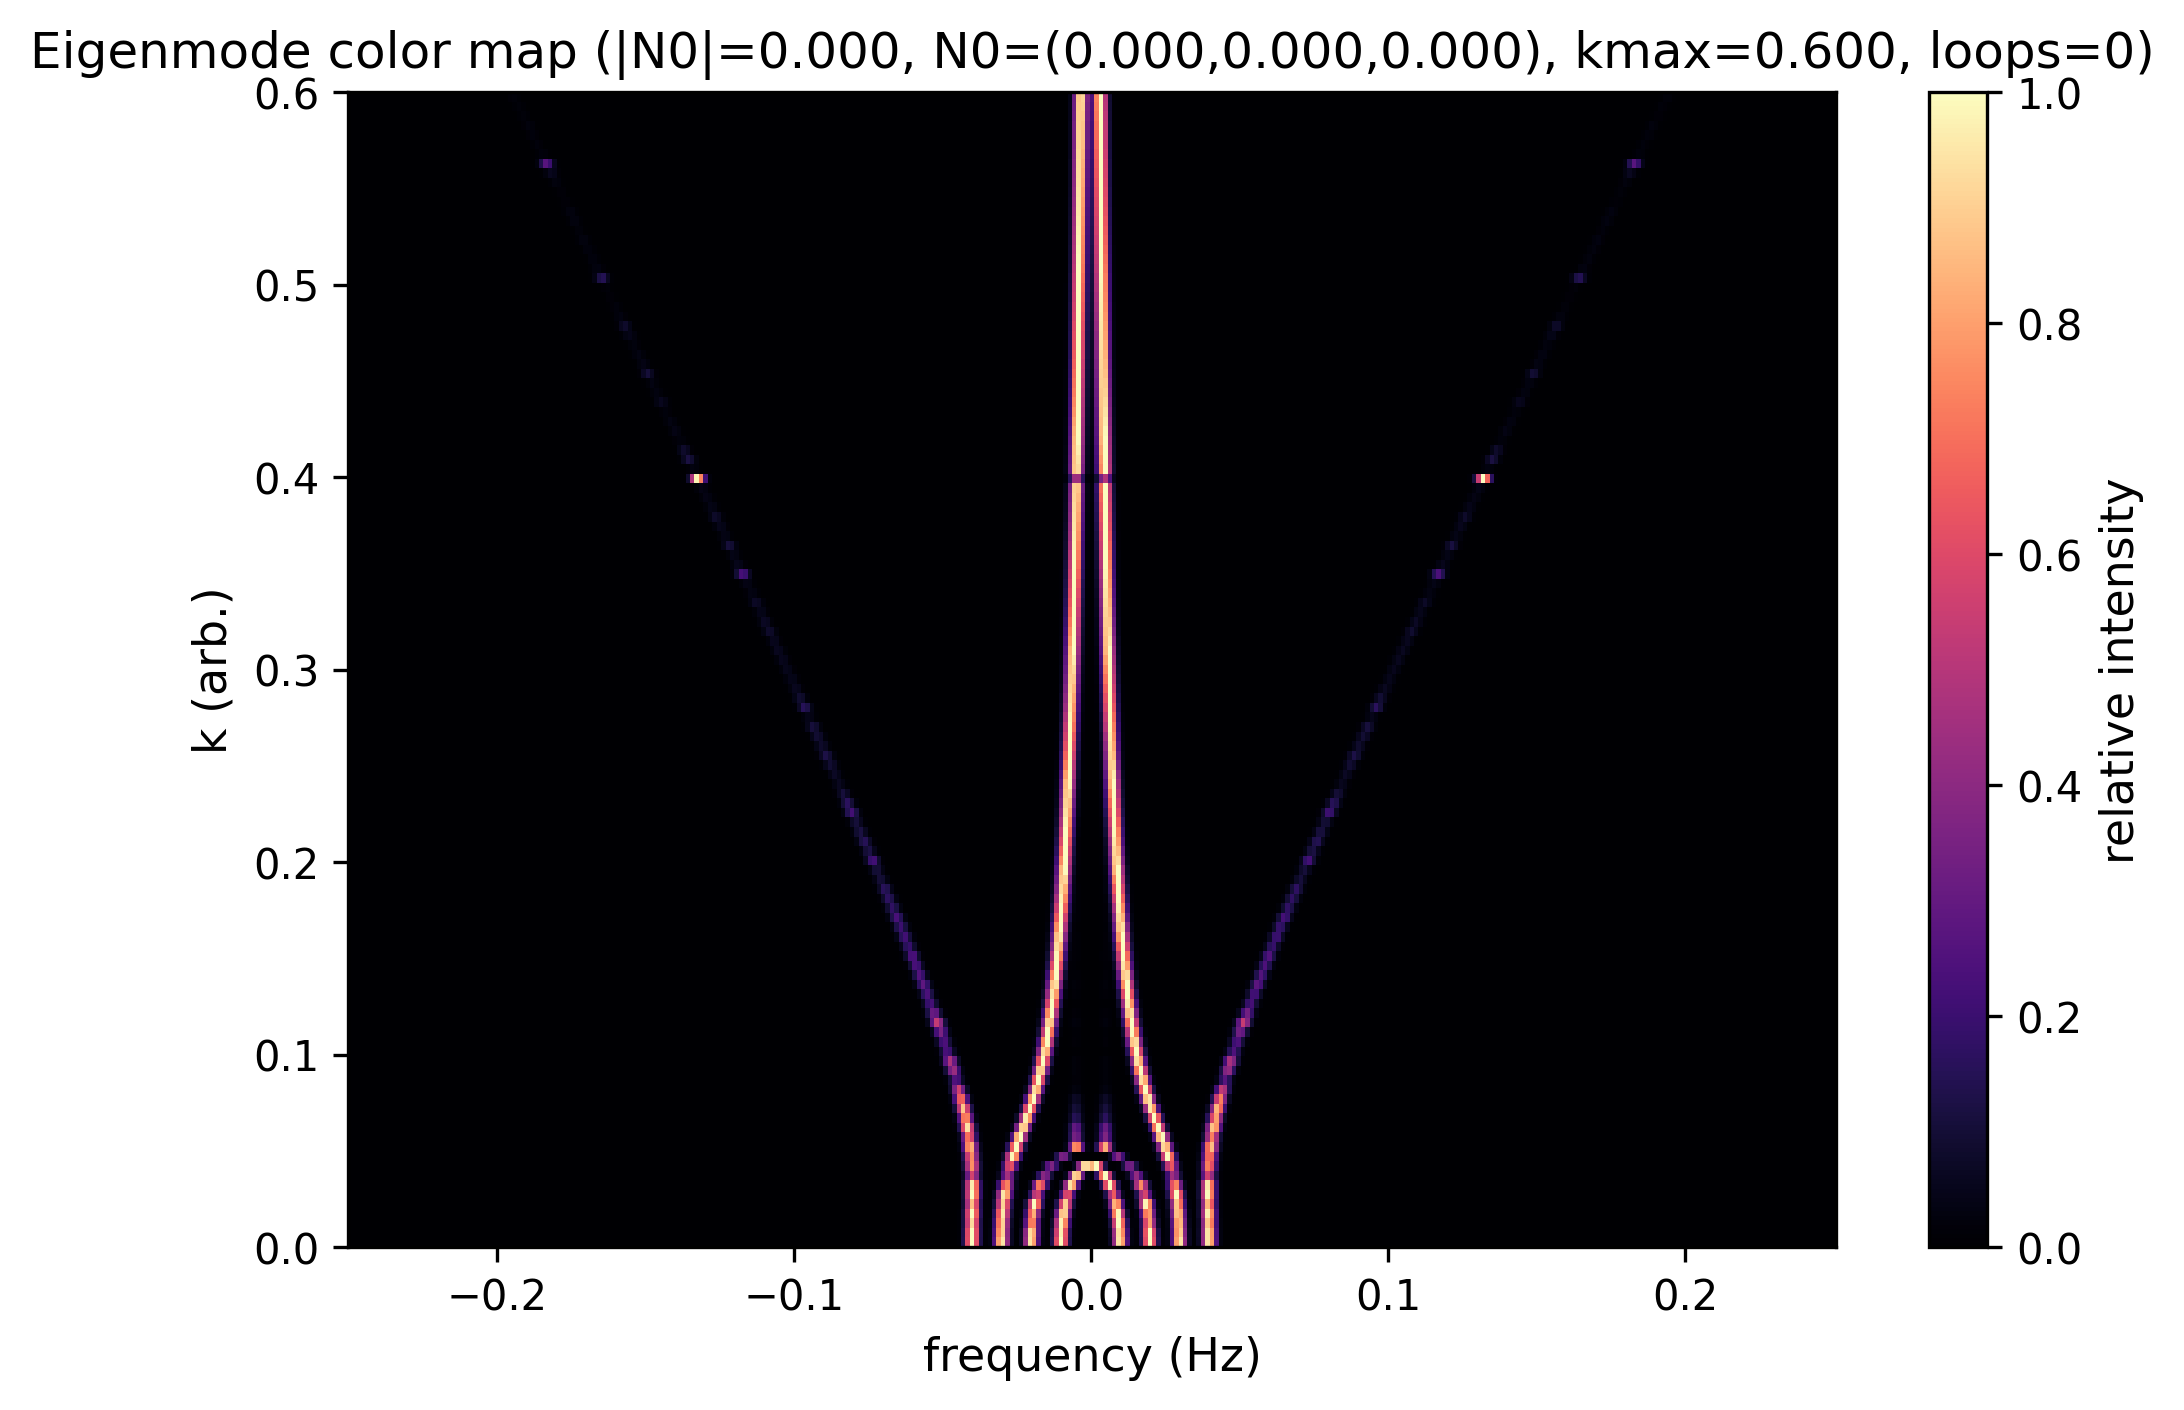

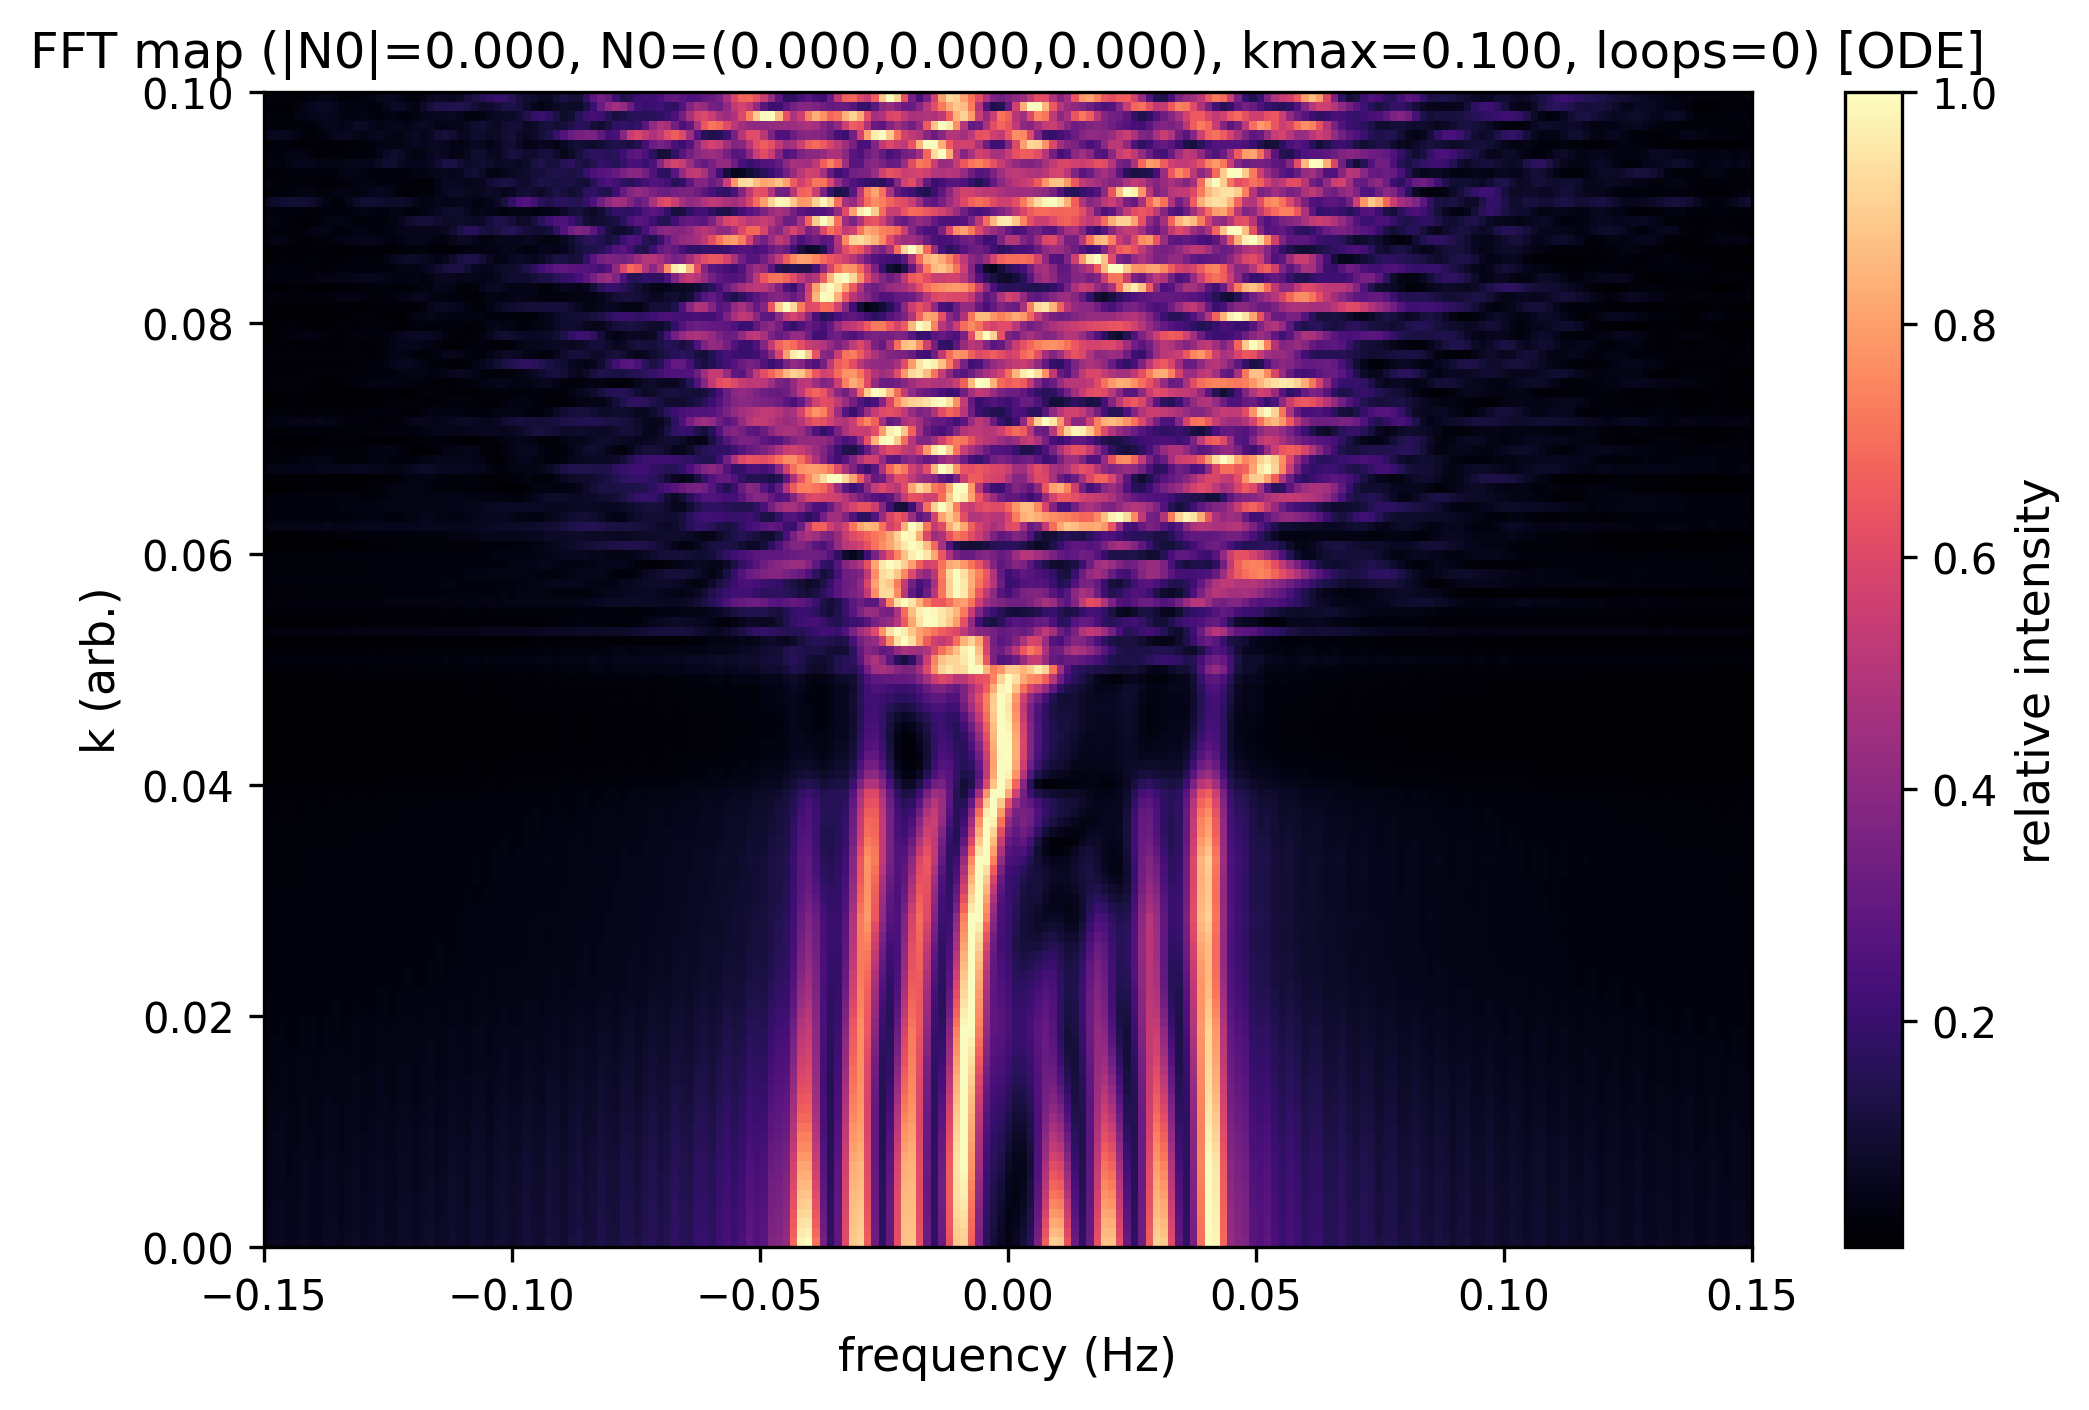

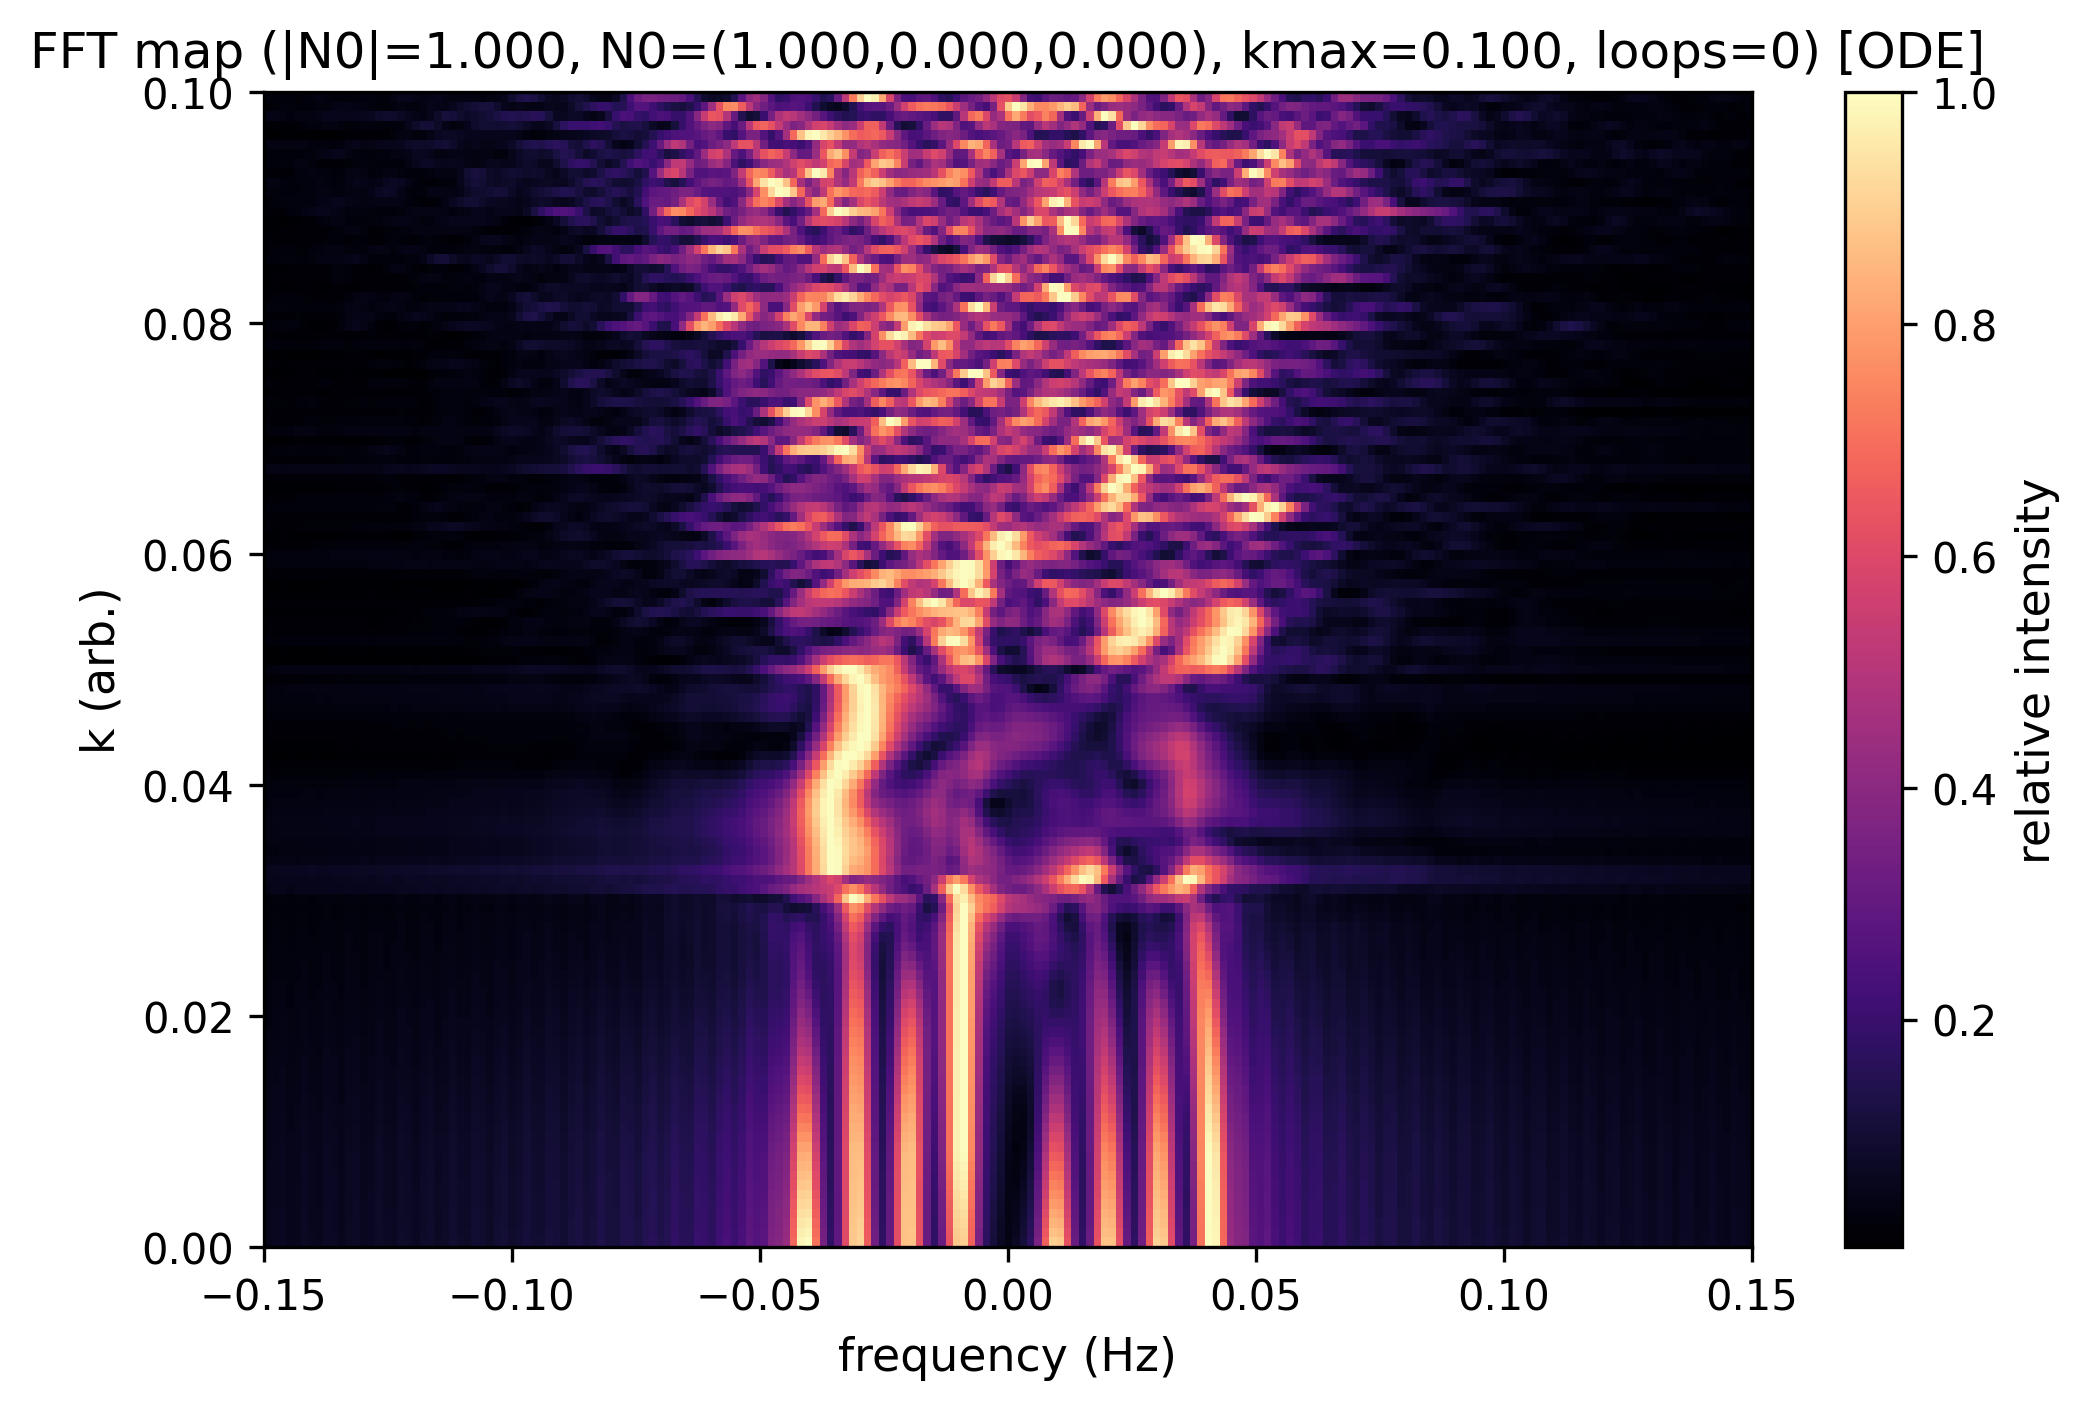

In [37]:
# Figure 1 and 2

PLOT_CFG['dpi'] = 800
PLOT_CFG['cmap'] = 'magma'
PLOT_CFG['font_size'] = 12
PLOT_CFG['transparent'] = 0
PLOT_CFG['prefix'] = ''  
PLOT_CFG['export_data'] = 1  
PLOT_CFG['show'] = 1    

# 1) Linearized spectral map with N0 = (0,0,0)
eigen_color_map(
    Nvec=(0.0, 0.0, 0.0),
    kmax=0.6,
    NK=121,
    frange=0.25,
    plotsigma=0.0015,
    save=True,
    loop_order=0,
)

# 2) Full ODE FFT map with N0 = (0,0,0)
fft_color_map_MN(
    Nvec=(0.0, 0.0, 0.0),
    pattern='uniform',
    kmax=0.1,
    NK=121,
    T_TOT=200.0,
    N_PTS=8001,
    frange=0.15,
    plotsigma=0.0015,
    N_FFT=131072,
    tip=0.05,
    save=True,
    loop_order=0,
    normalize_rows=True,
)

# 3) Full ODE FFT map with N0 = (1,0,0)
fft_color_map_MN(
    Nvec=(1.0, 0.0, 0.0),
    pattern='uniform',
    kmax=0.1,
    NK=121,
    T_TOT=200.0,
    N_PTS=8001,
    frange=0.15,
    plotsigma=0.0015,
    N_FFT=131072,
    tip=0.05,
    save=True,
    loop_order=0,
    normalize_rows=True,
)


[info] Using loop corrections up to order: 0
[ent] Pair set (12 pairs): [(0, 1), (0, 3), (0, 4), (1, 2), (1, 5), (2, 3), (2, 6), (3, 7), (4, 5), (4, 7), (5, 6), (6, 7)]
[ent] Multipartite subset count: 56  partition mode: all
[ent] Native certification status: certified=1  classical_invariant=0  reason_code=2
[ent] Certified native entanglement is computed within a frozen-background canonical packet-mode Gaussian native model in spinpacket.py. The covariance is propagated directly in the packet tangent-mode basis (Q_j,P_j), with the frozen projected native packet generator used only as a comparison to the time-dependent packet-mode model. A packet-basis symplectic certification diagnostic is reported.
[ent] Certified native output is computed from the selected native linearized Gaussian M,N model on the selected time window.
[ent] Native Gaussian model settings: model=frozen  source=full  nth=0.000  nbath=0.000

[ent][certified] === Pairwise Gaussian summary (certified valid bins) ===


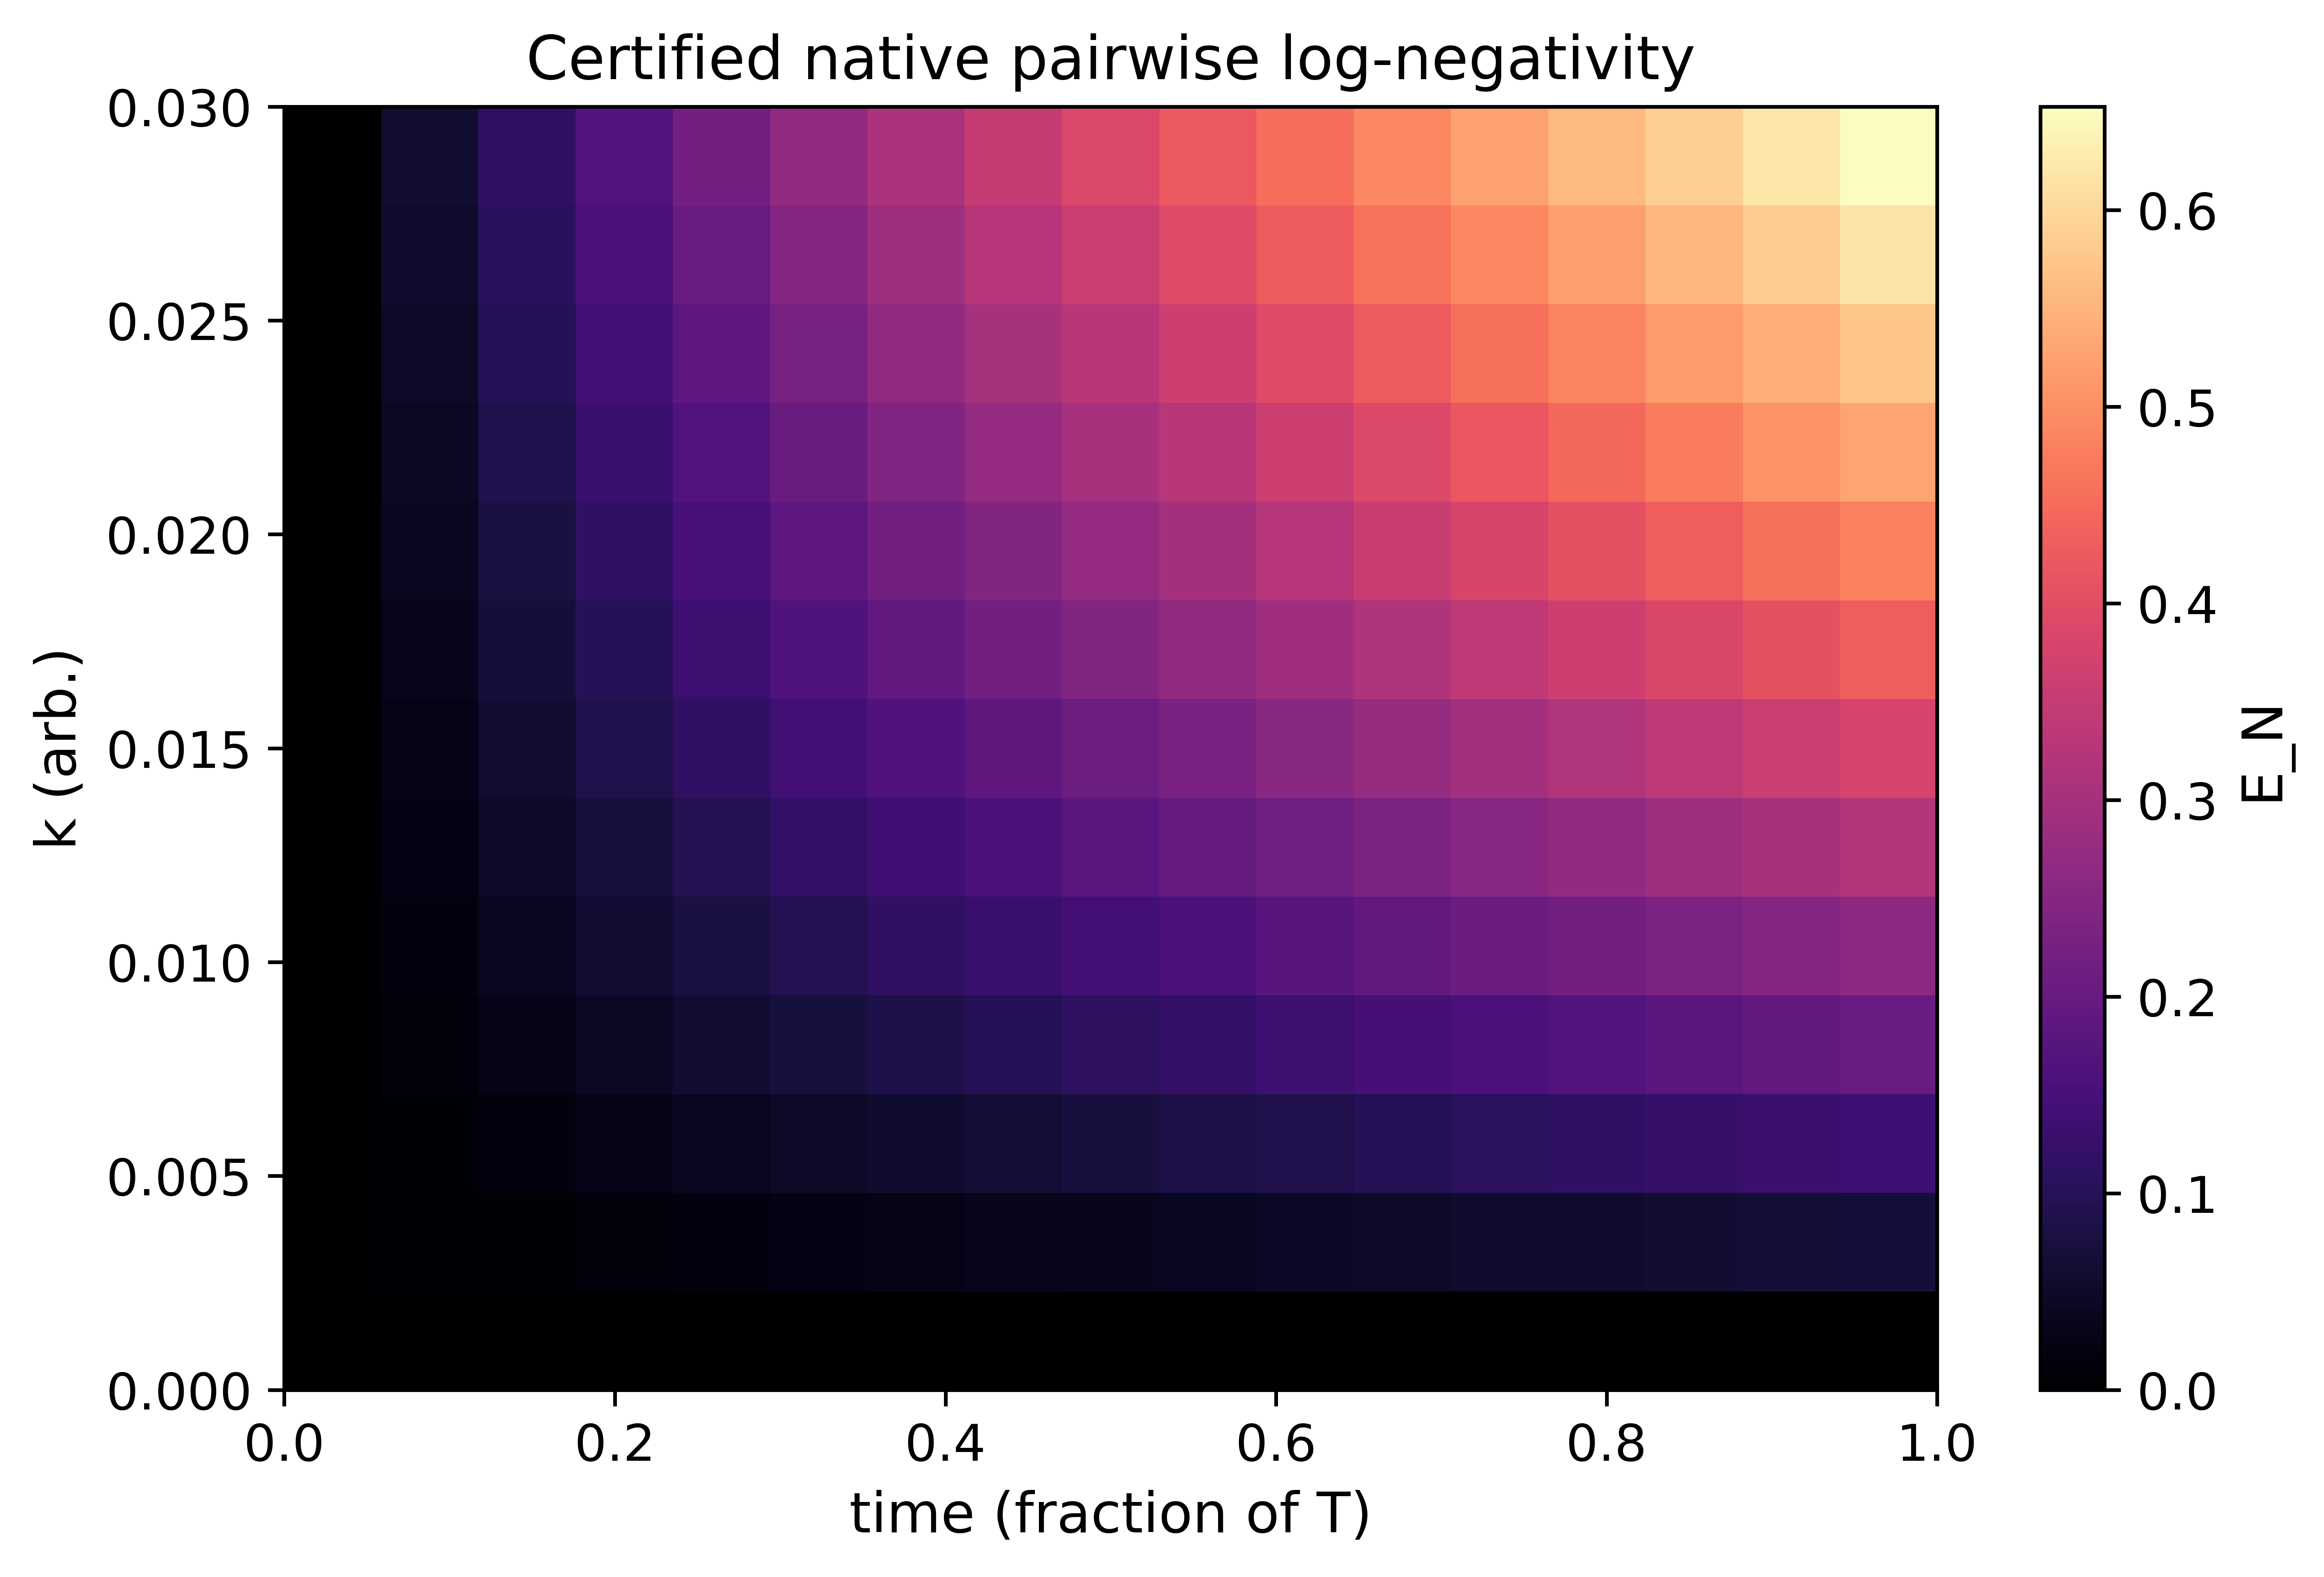

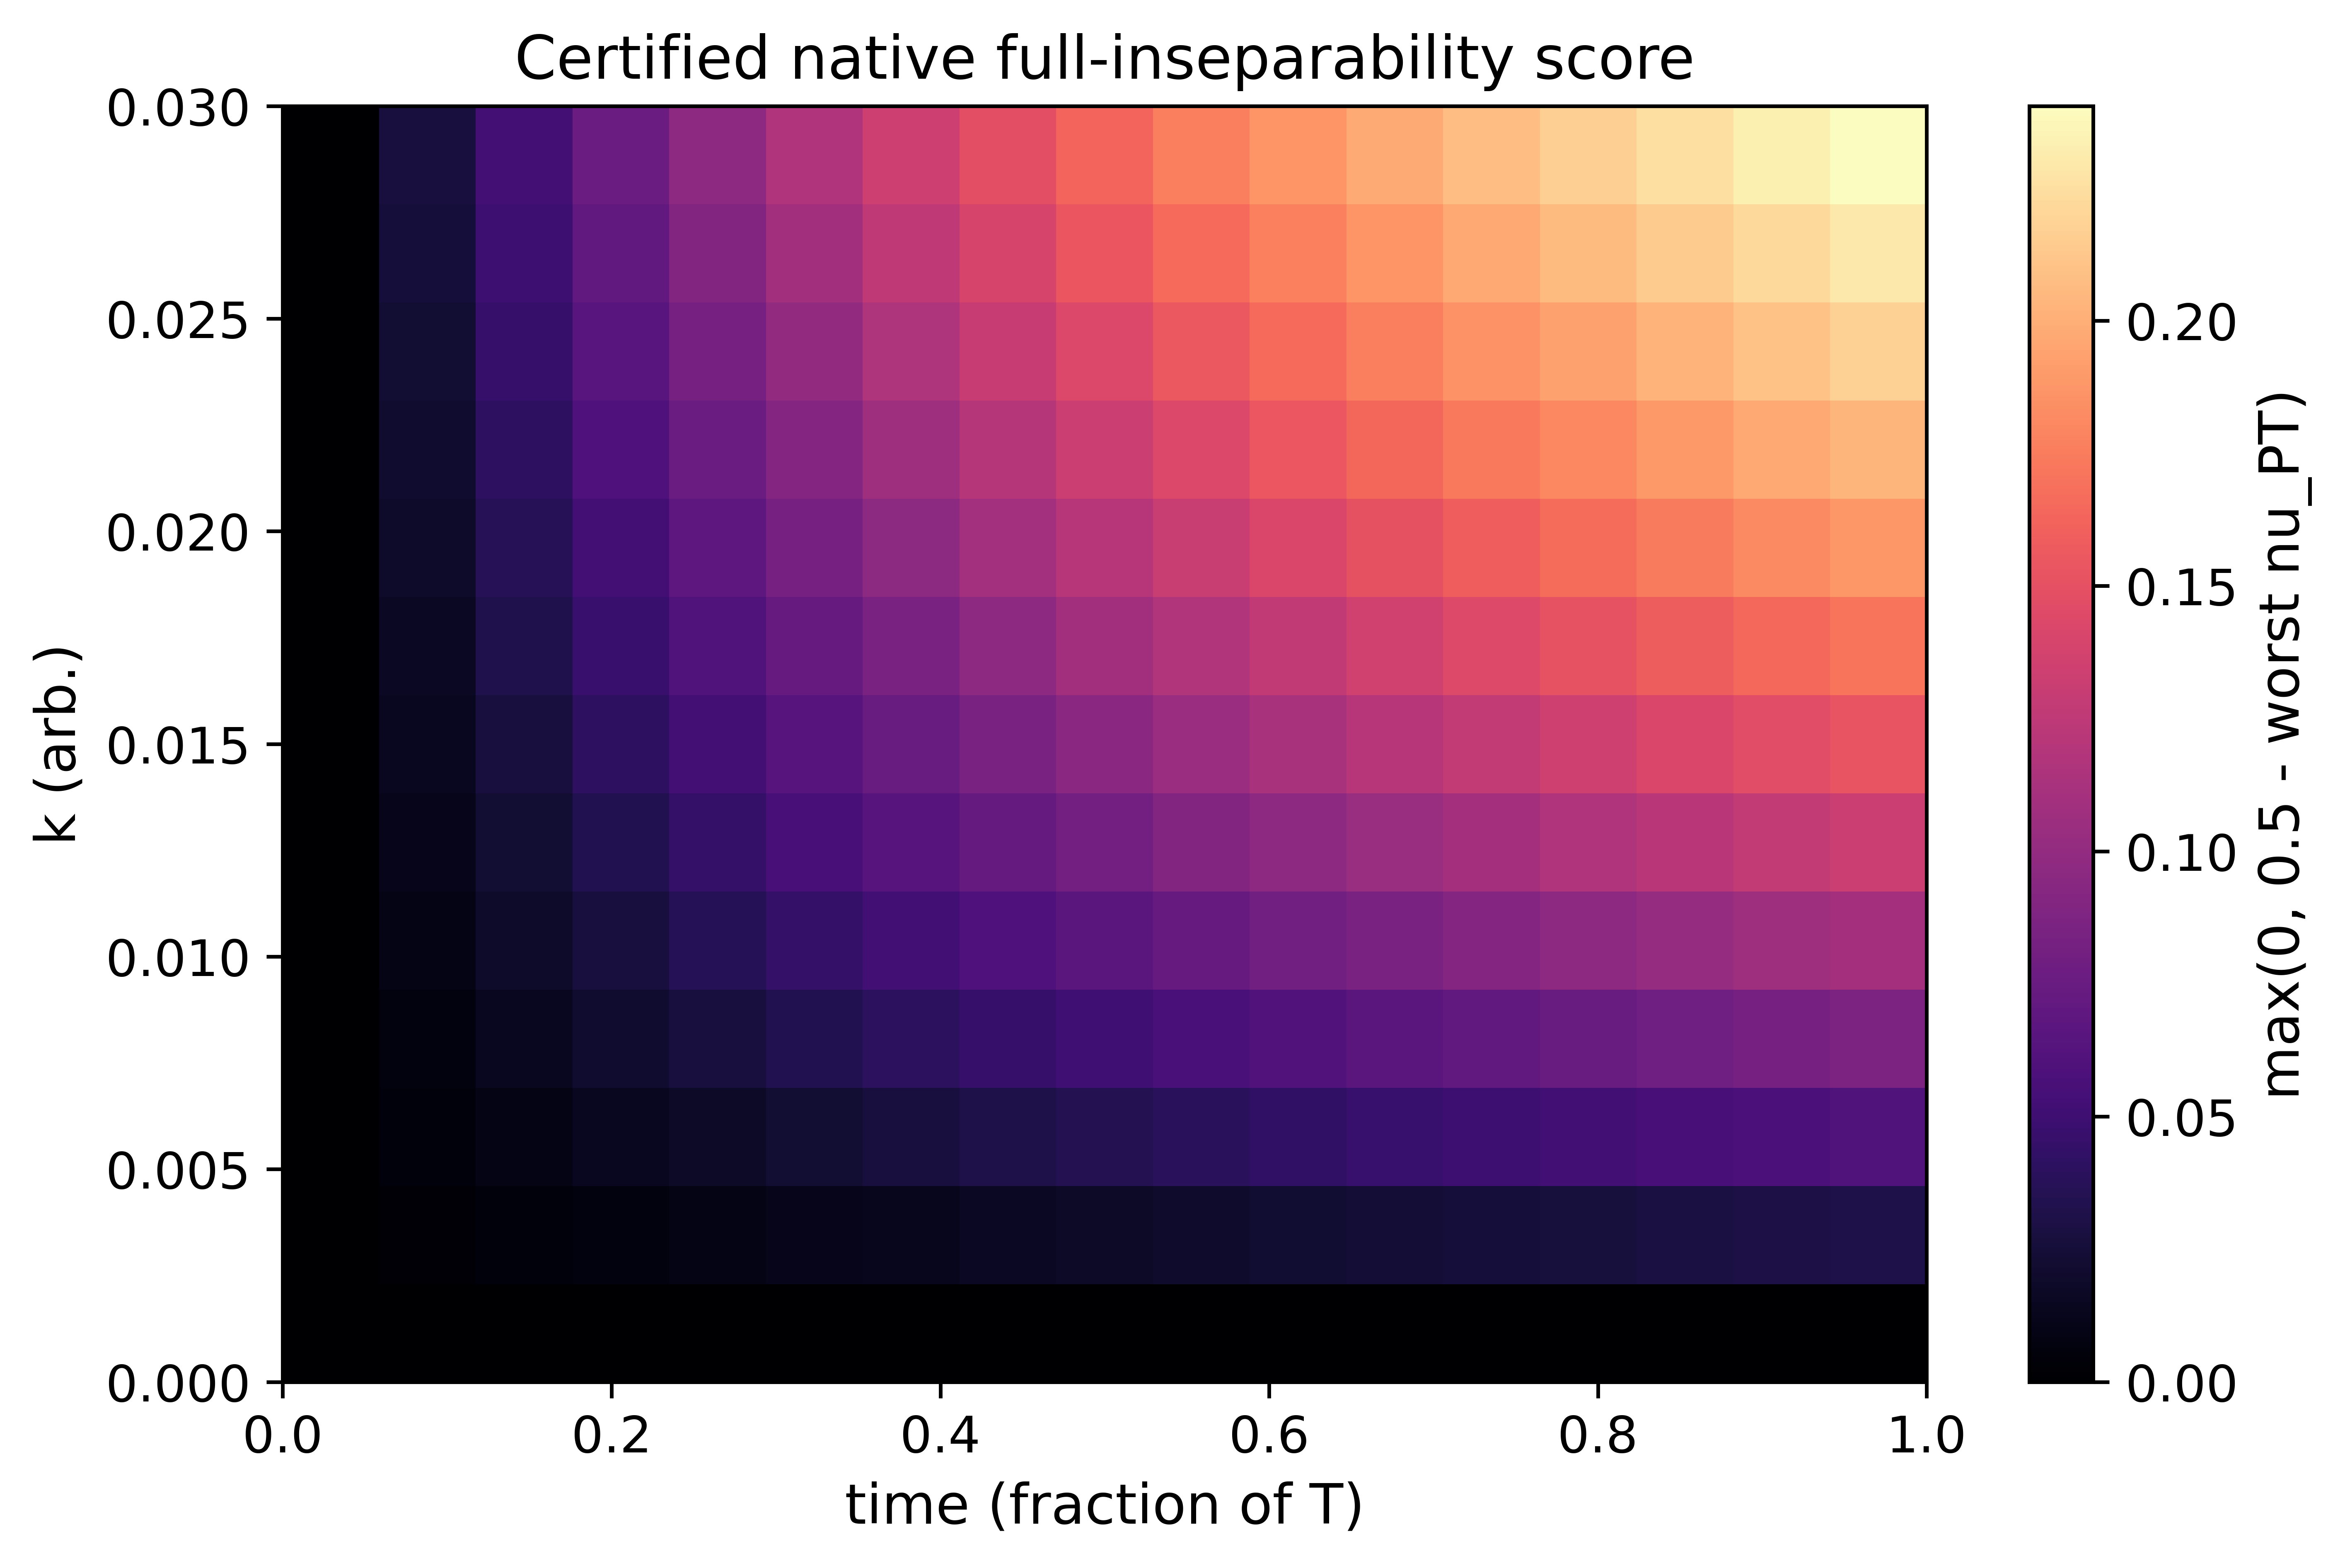

In [38]:
# Figure 3
args_str = """
  --mode none \
  --kmax 0.03 \
  --loops 0 \
  --Nvec 0.30 0 0 \
  --tip 0.05 \
  --pattern staggered \
  --ent 1 \
  --ent-save 1 \
  --ent-layer both
  --ent-native-proxy 0
  --eng 0
  --ent-native-model frozen \
  --ent-native-source full \
  --ent-window 0.0:1.0 \
  --ent-NK 13 \
  --ent-NT 17 \
  --T 8.0 \
  --npts 2401 \
  --fig-dpi 800 \
  --fig-fontsize 12 \
  --fig-cmap magma \
  --fig-transparent 0 \
  --no-show 0
"""

_prev_argv = sys.argv[:] 
try:
    sys.argv = [sys.argv[0]] + shlex.split(args_str)
    main()
finally:
    sys.argv = _prev_argv

[info] Using loop corrections up to order: 4
[info] loop local sums at |N0|: alpha=0.000e+00 beta=0.000e+00 sigma=2.278e-01 kappa=0.000e+00
[ent] Pair set (12 pairs): [(0, 1), (0, 3), (0, 4), (1, 2), (1, 5), (2, 3), (2, 6), (3, 7), (4, 5), (4, 7), (5, 6), (6, 7)]
[ent] Multipartite subset count: 56  partition mode: all
[ent] Native certification status: certified=1  classical_invariant=0  reason_code=2
[ent] Certified native entanglement is computed within a frozen-background canonical packet-mode Gaussian native model in spinpacket.py. The covariance is propagated directly in the packet tangent-mode basis (Q_j,P_j), with the frozen projected native packet generator used only as a comparison to the time-dependent packet-mode model. A packet-basis symplectic certification diagnostic is reported.
[ent] Certified native output is computed from the selected native linearized Gaussian M,N model on the selected time window.
[ent] Native Gaussian model settings: model=frozen  source=full  nth

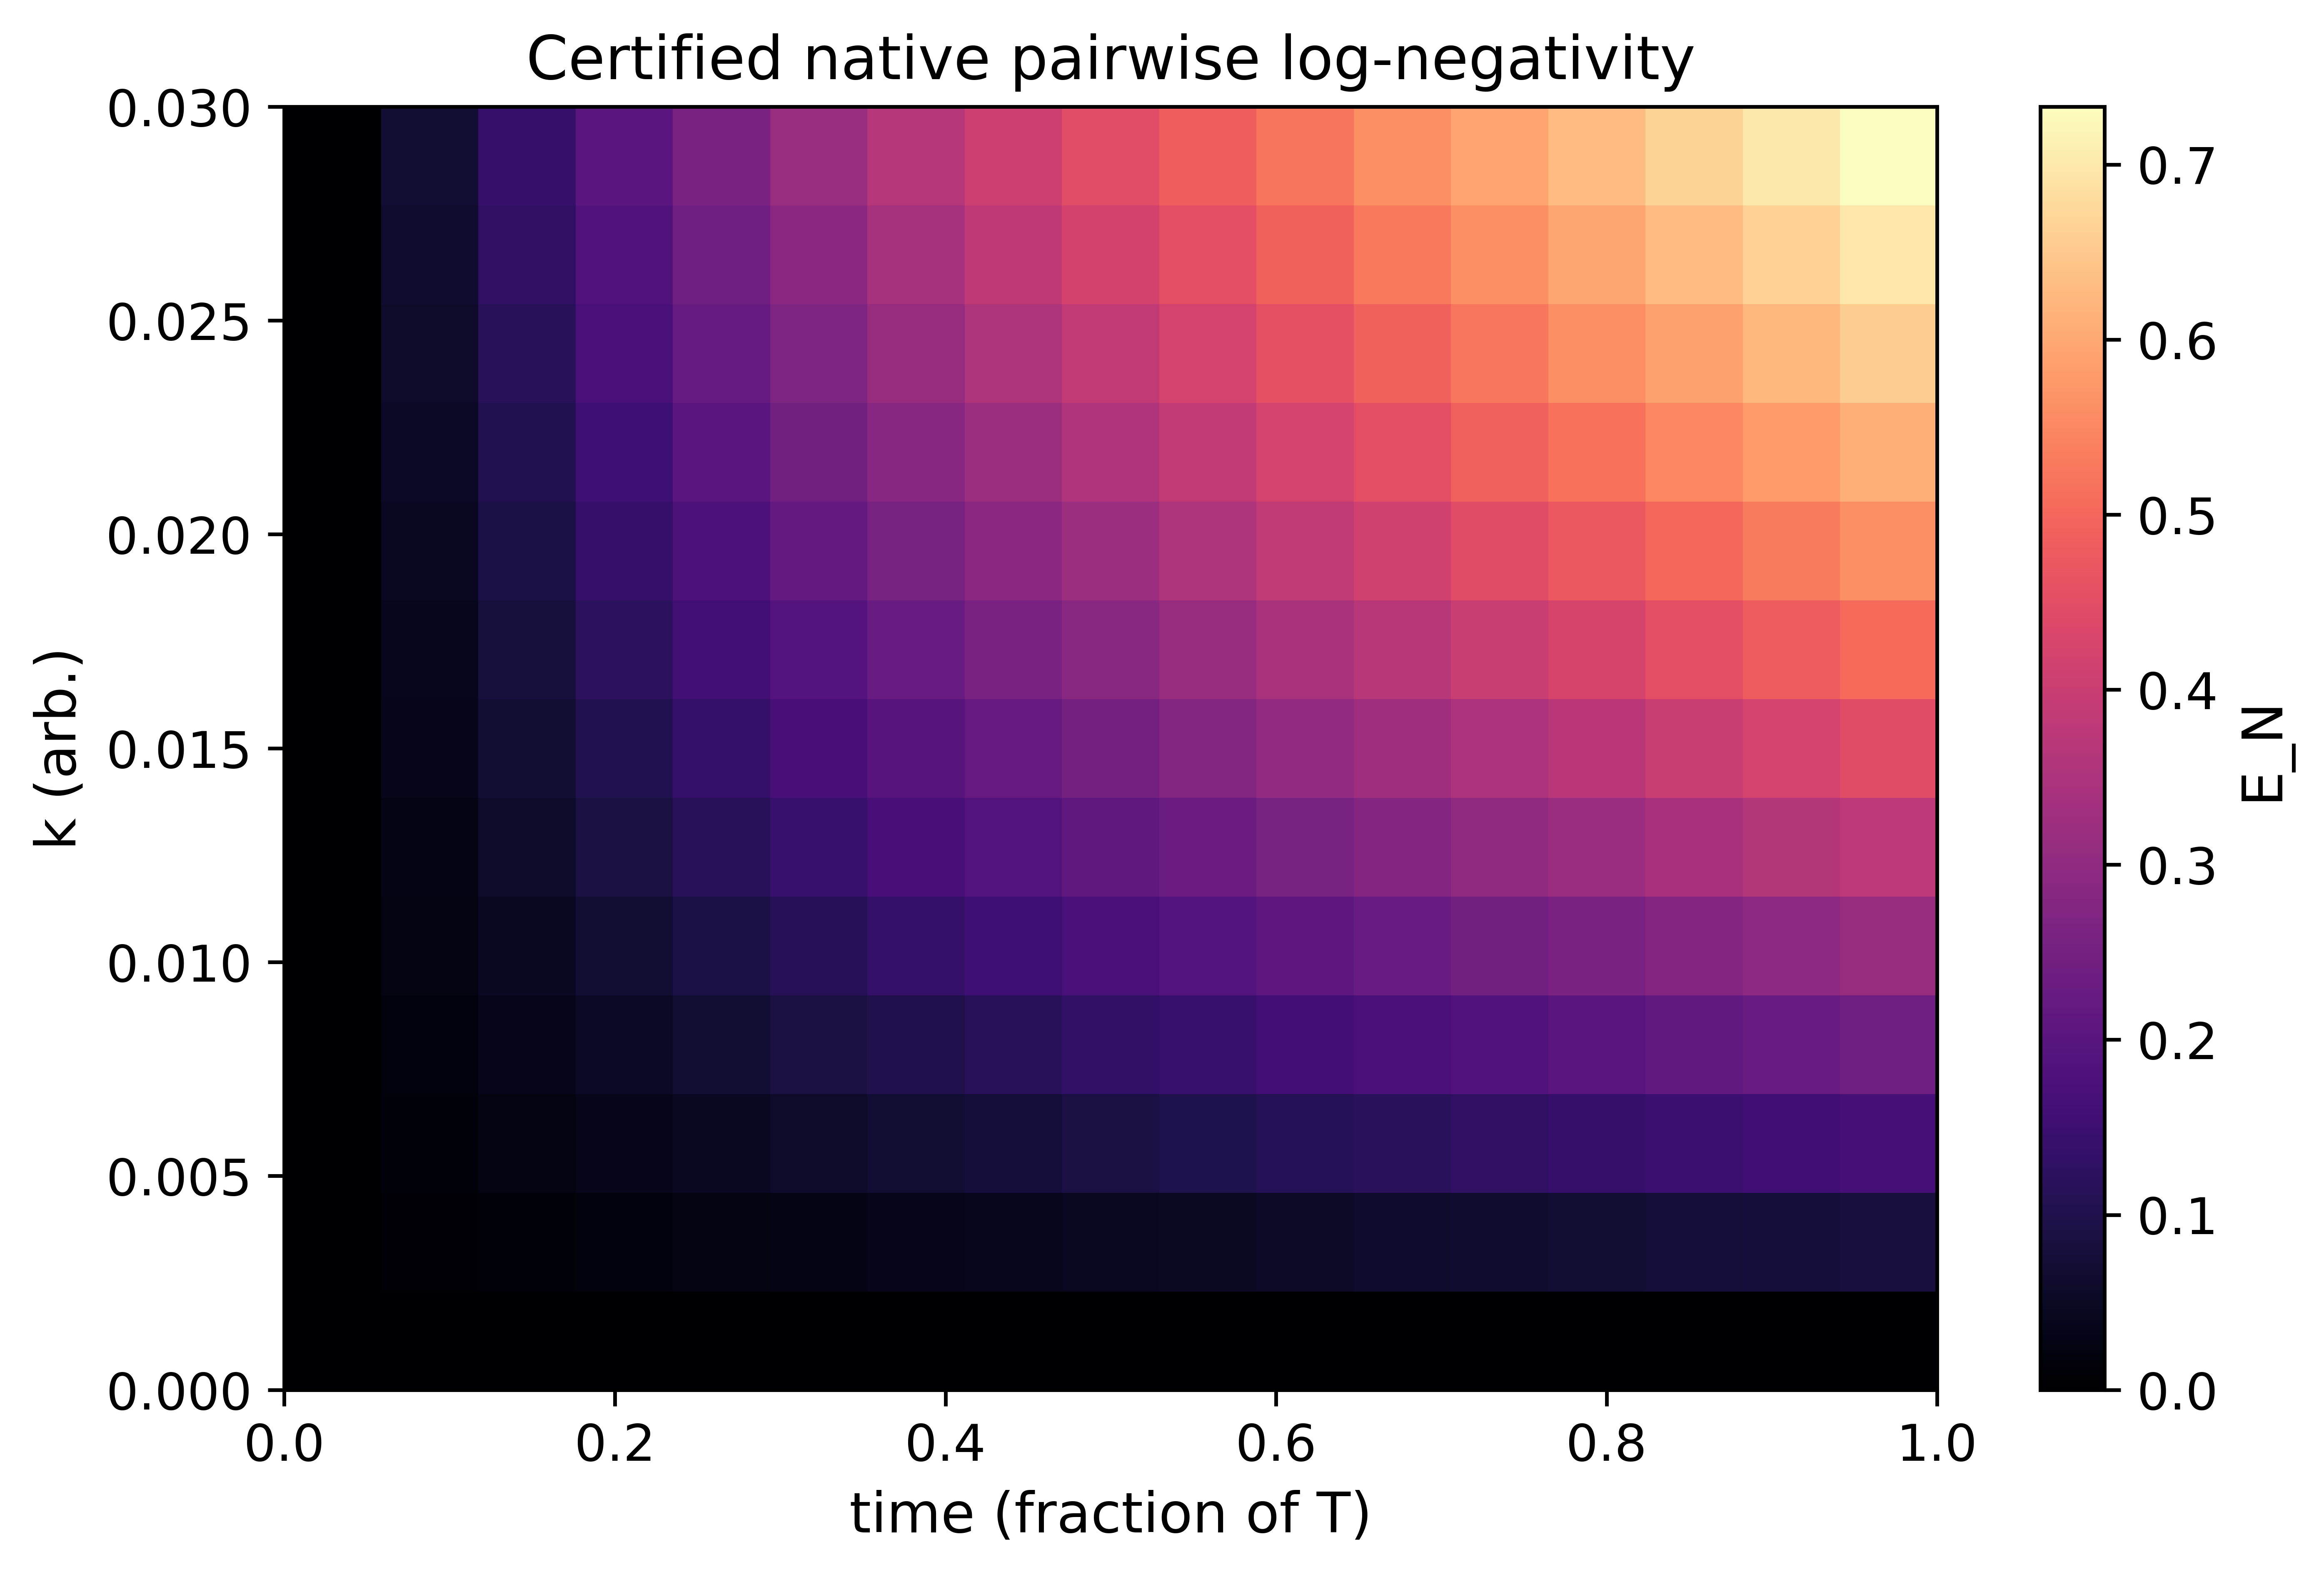

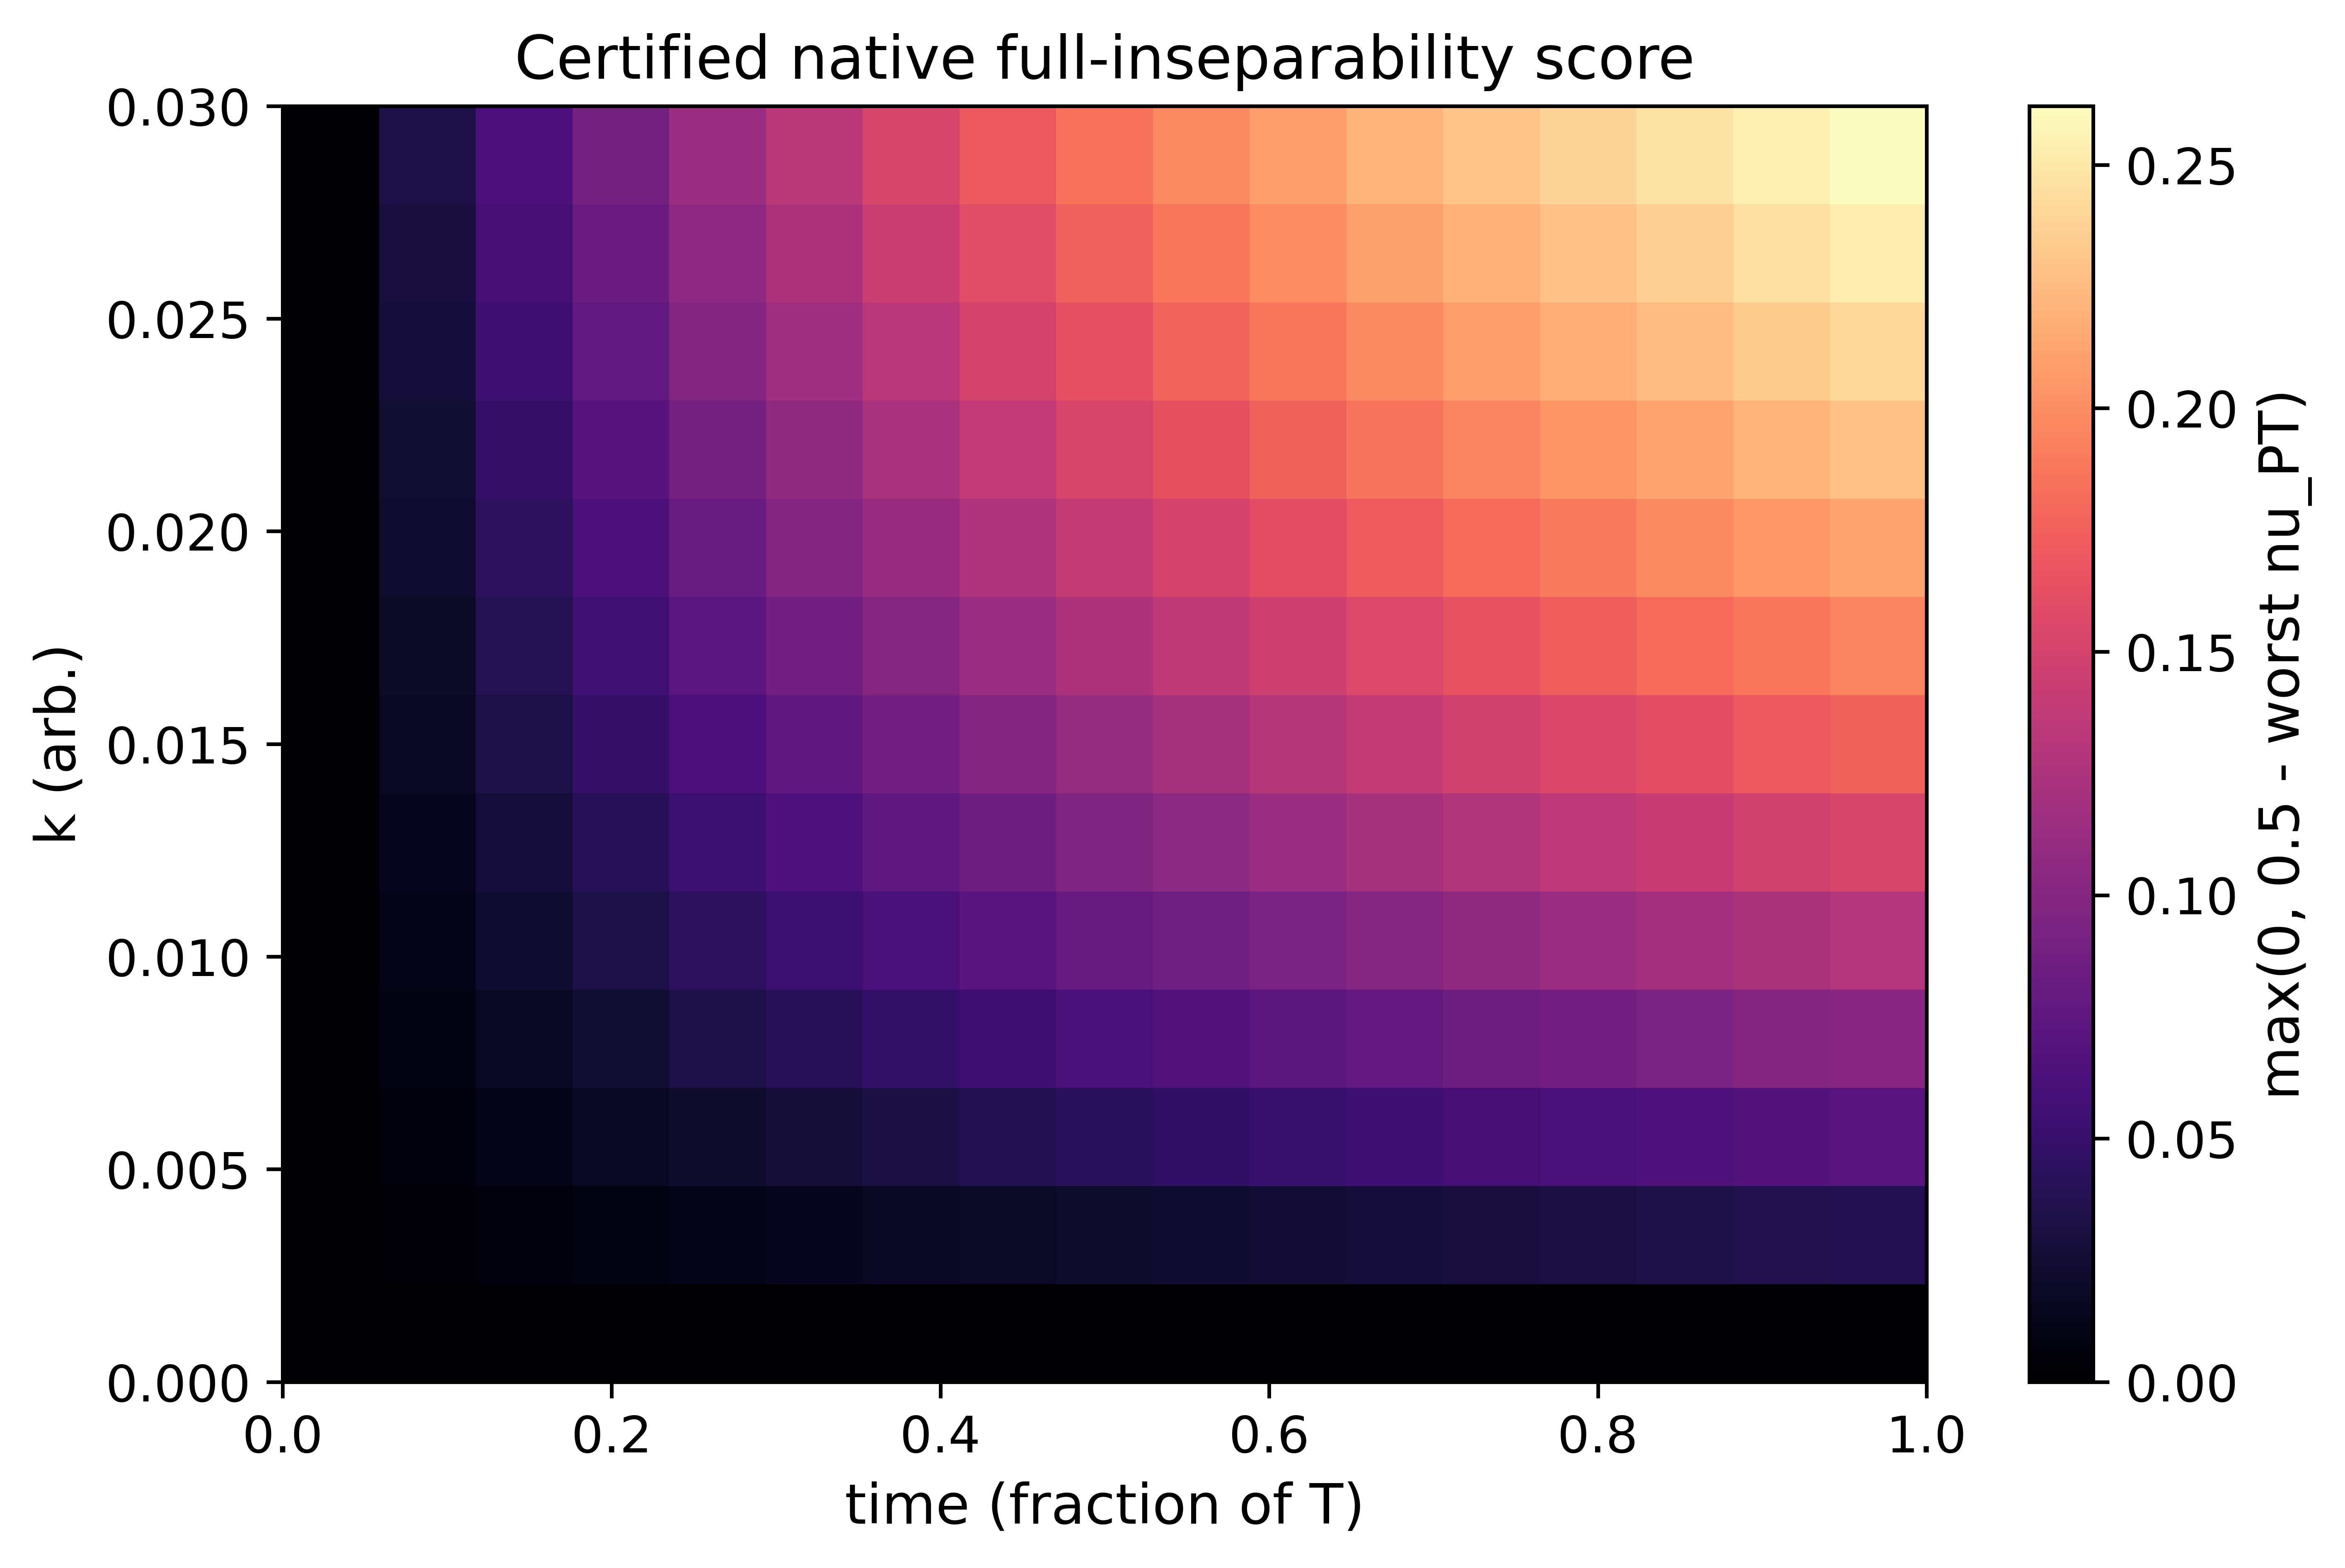

In [39]:
# Figure 4
args_str = """
  --mode none \
  --kmax 0.03 \
  --loops 4 \
  --sigma 2.00 5.00 10.00 \
  --Nvec 0.30 0 0 \
  --tip 0.05 \
  --pattern staggered \
  --ent 1 \
  --ent-save 1 \
  --ent-native-model frozen \
  --ent-native-source full \
  --ent-window 0.0:1.0 \
  --ent-NK 13 \
  --ent-NT 17 \
  --T 8.0 \
  --npts 2401 \
  --fig-dpi 800 \
  --fig-fontsize 12 \
  --fig-cmap magma \
  --fig-transparent 0 \
  --no-show 0
"""

_prev_argv = sys.argv[:] 
try:
    sys.argv = [sys.argv[0]] + shlex.split(args_str)
    main()
finally:
    sys.argv = _prev_argv

[info] Using loop corrections up to order: 4
[info] loop local sums at |N0|: alpha=4.945e-01 beta=0.000e+00 sigma=5.456e-01 kappa=5.456e-01
[ent] Pair set (12 pairs): [(0, 1), (0, 3), (0, 4), (1, 2), (1, 5), (2, 3), (2, 6), (3, 7), (4, 5), (4, 7), (5, 6), (6, 7)]
[ent] Multipartite subset count: 56  partition mode: all
[ent] Native certification status: certified=1  classical_invariant=0  reason_code=2
[ent] Certified native entanglement is computed within a frozen-background canonical packet-mode Gaussian native model in spinpacket.py. The covariance is propagated directly in the packet tangent-mode basis (Q_j,P_j), with the frozen projected native packet generator used only as a comparison to the time-dependent packet-mode model. A packet-basis symplectic certification diagnostic is reported.
[ent] Certified native output is computed from the selected native linearized Gaussian M,N model on the selected time window.
[ent] Native Gaussian model settings: model=frozen  source=full  nth

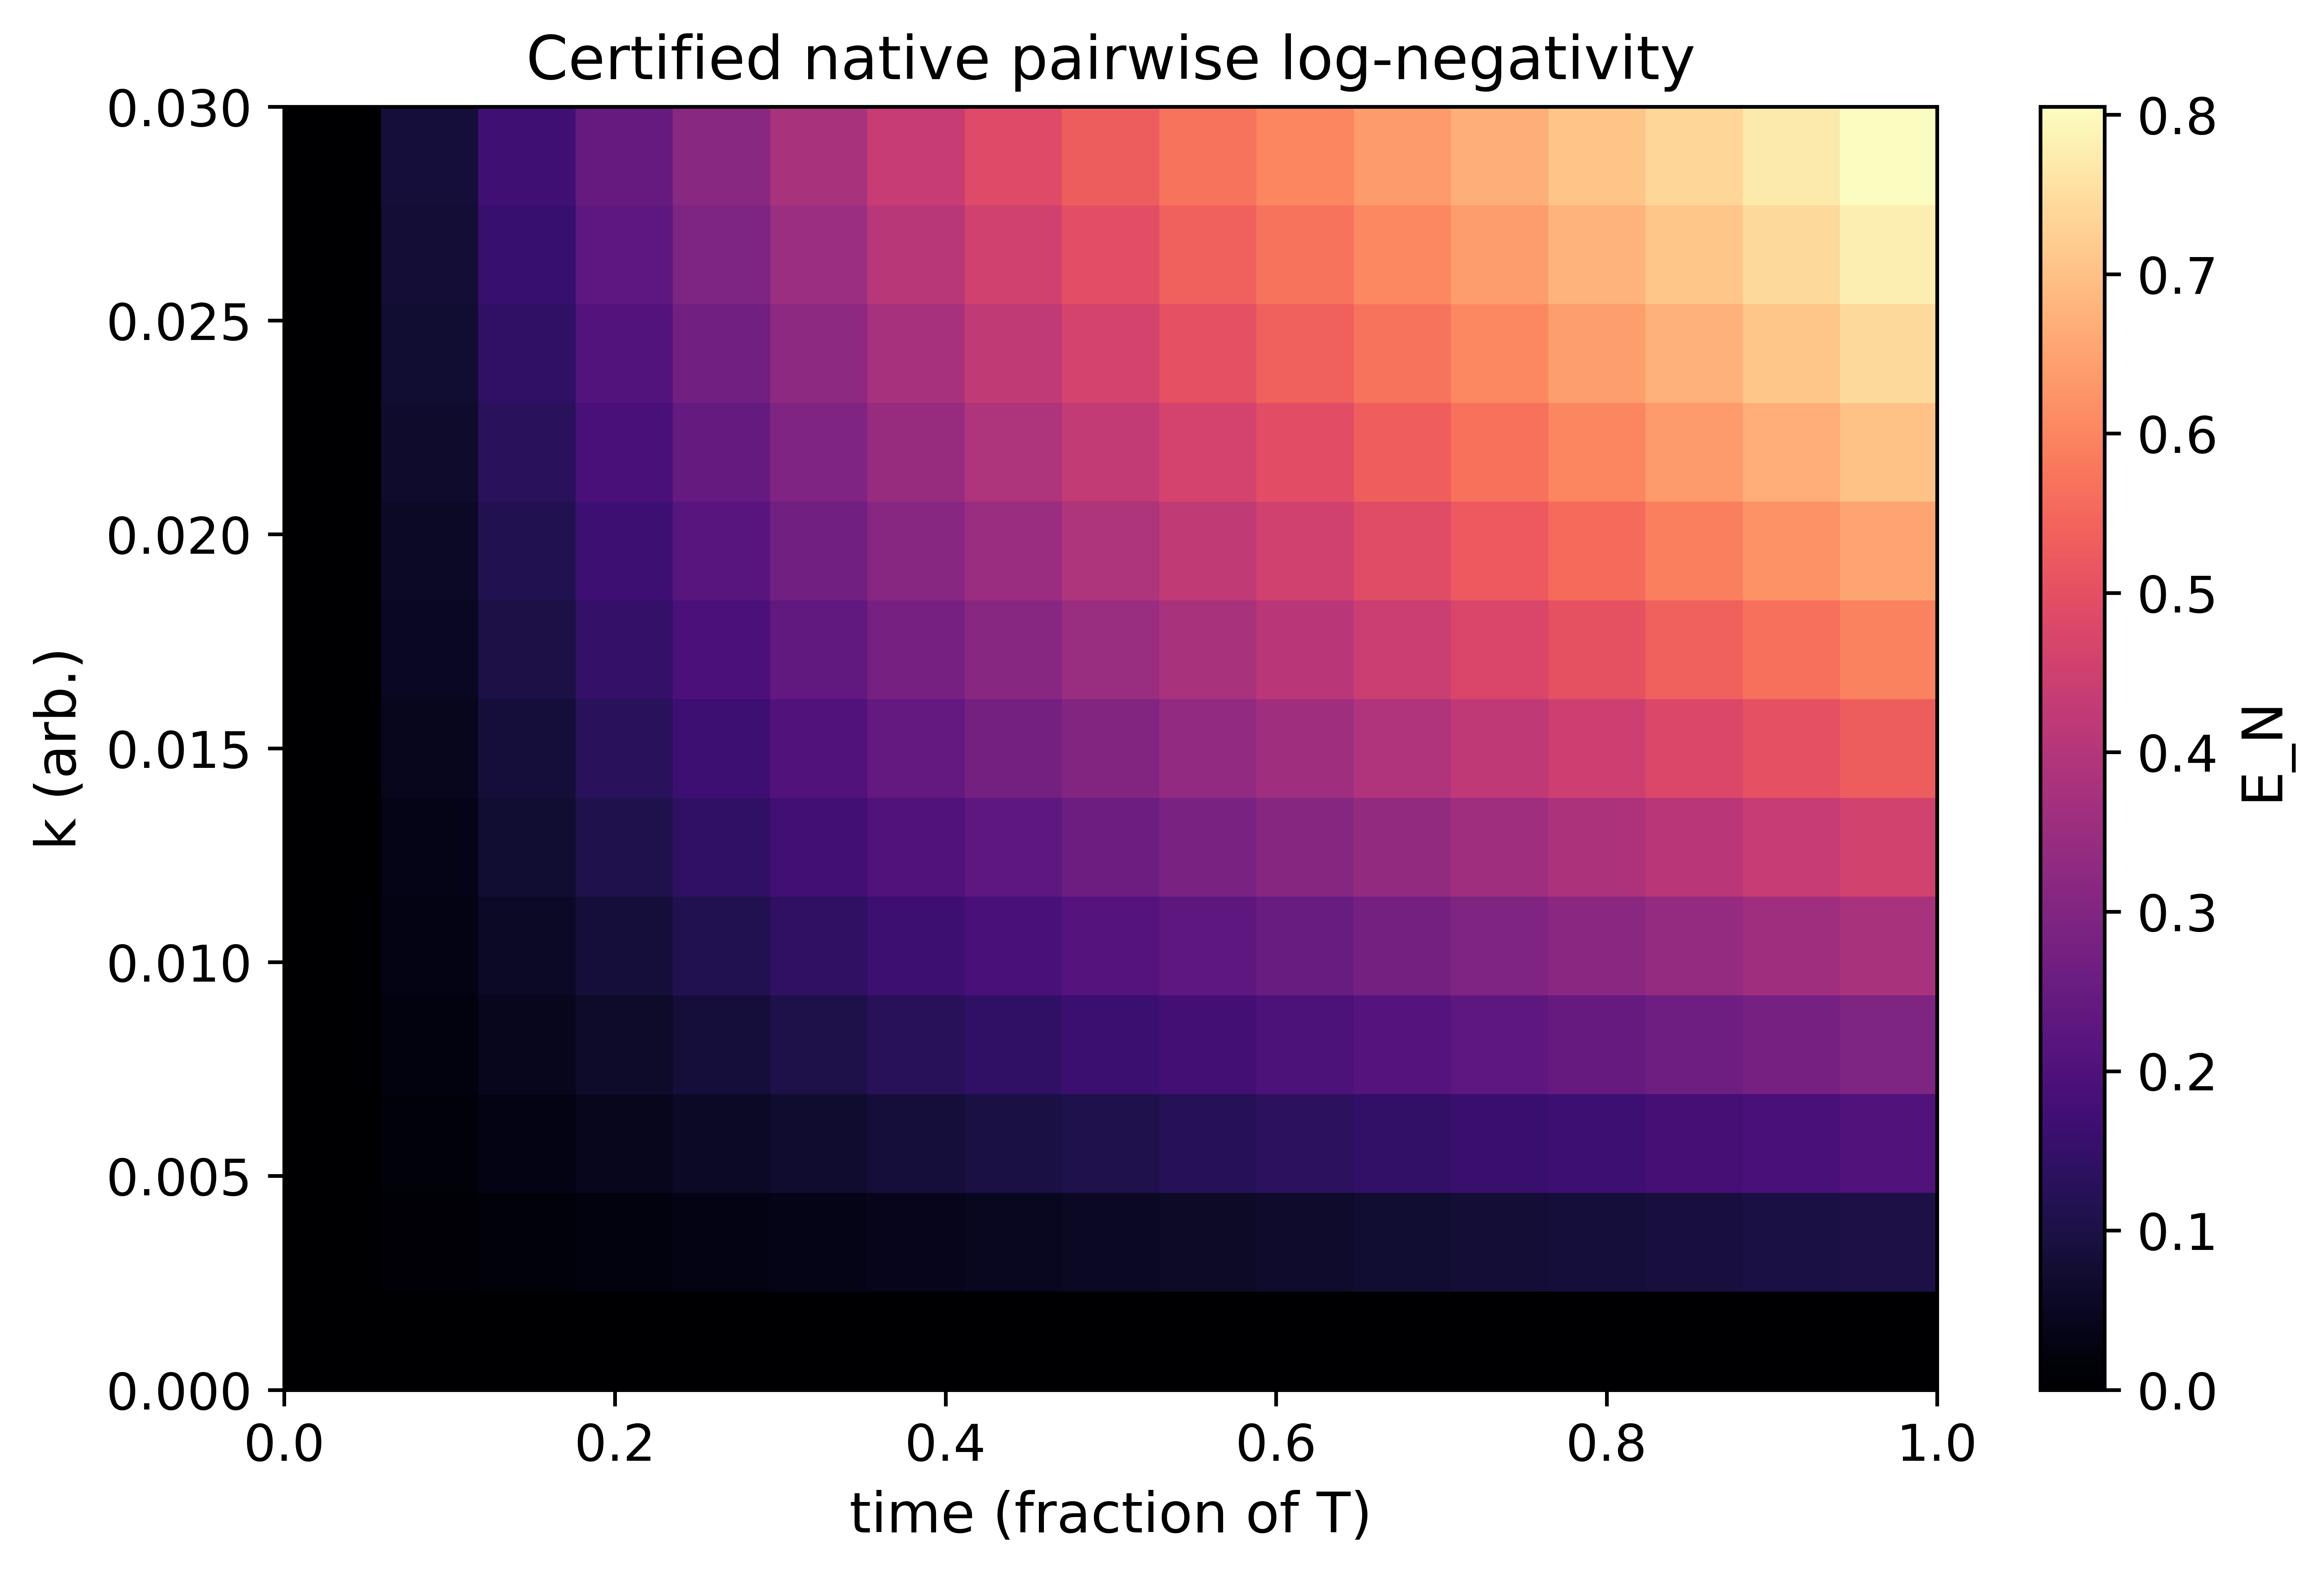

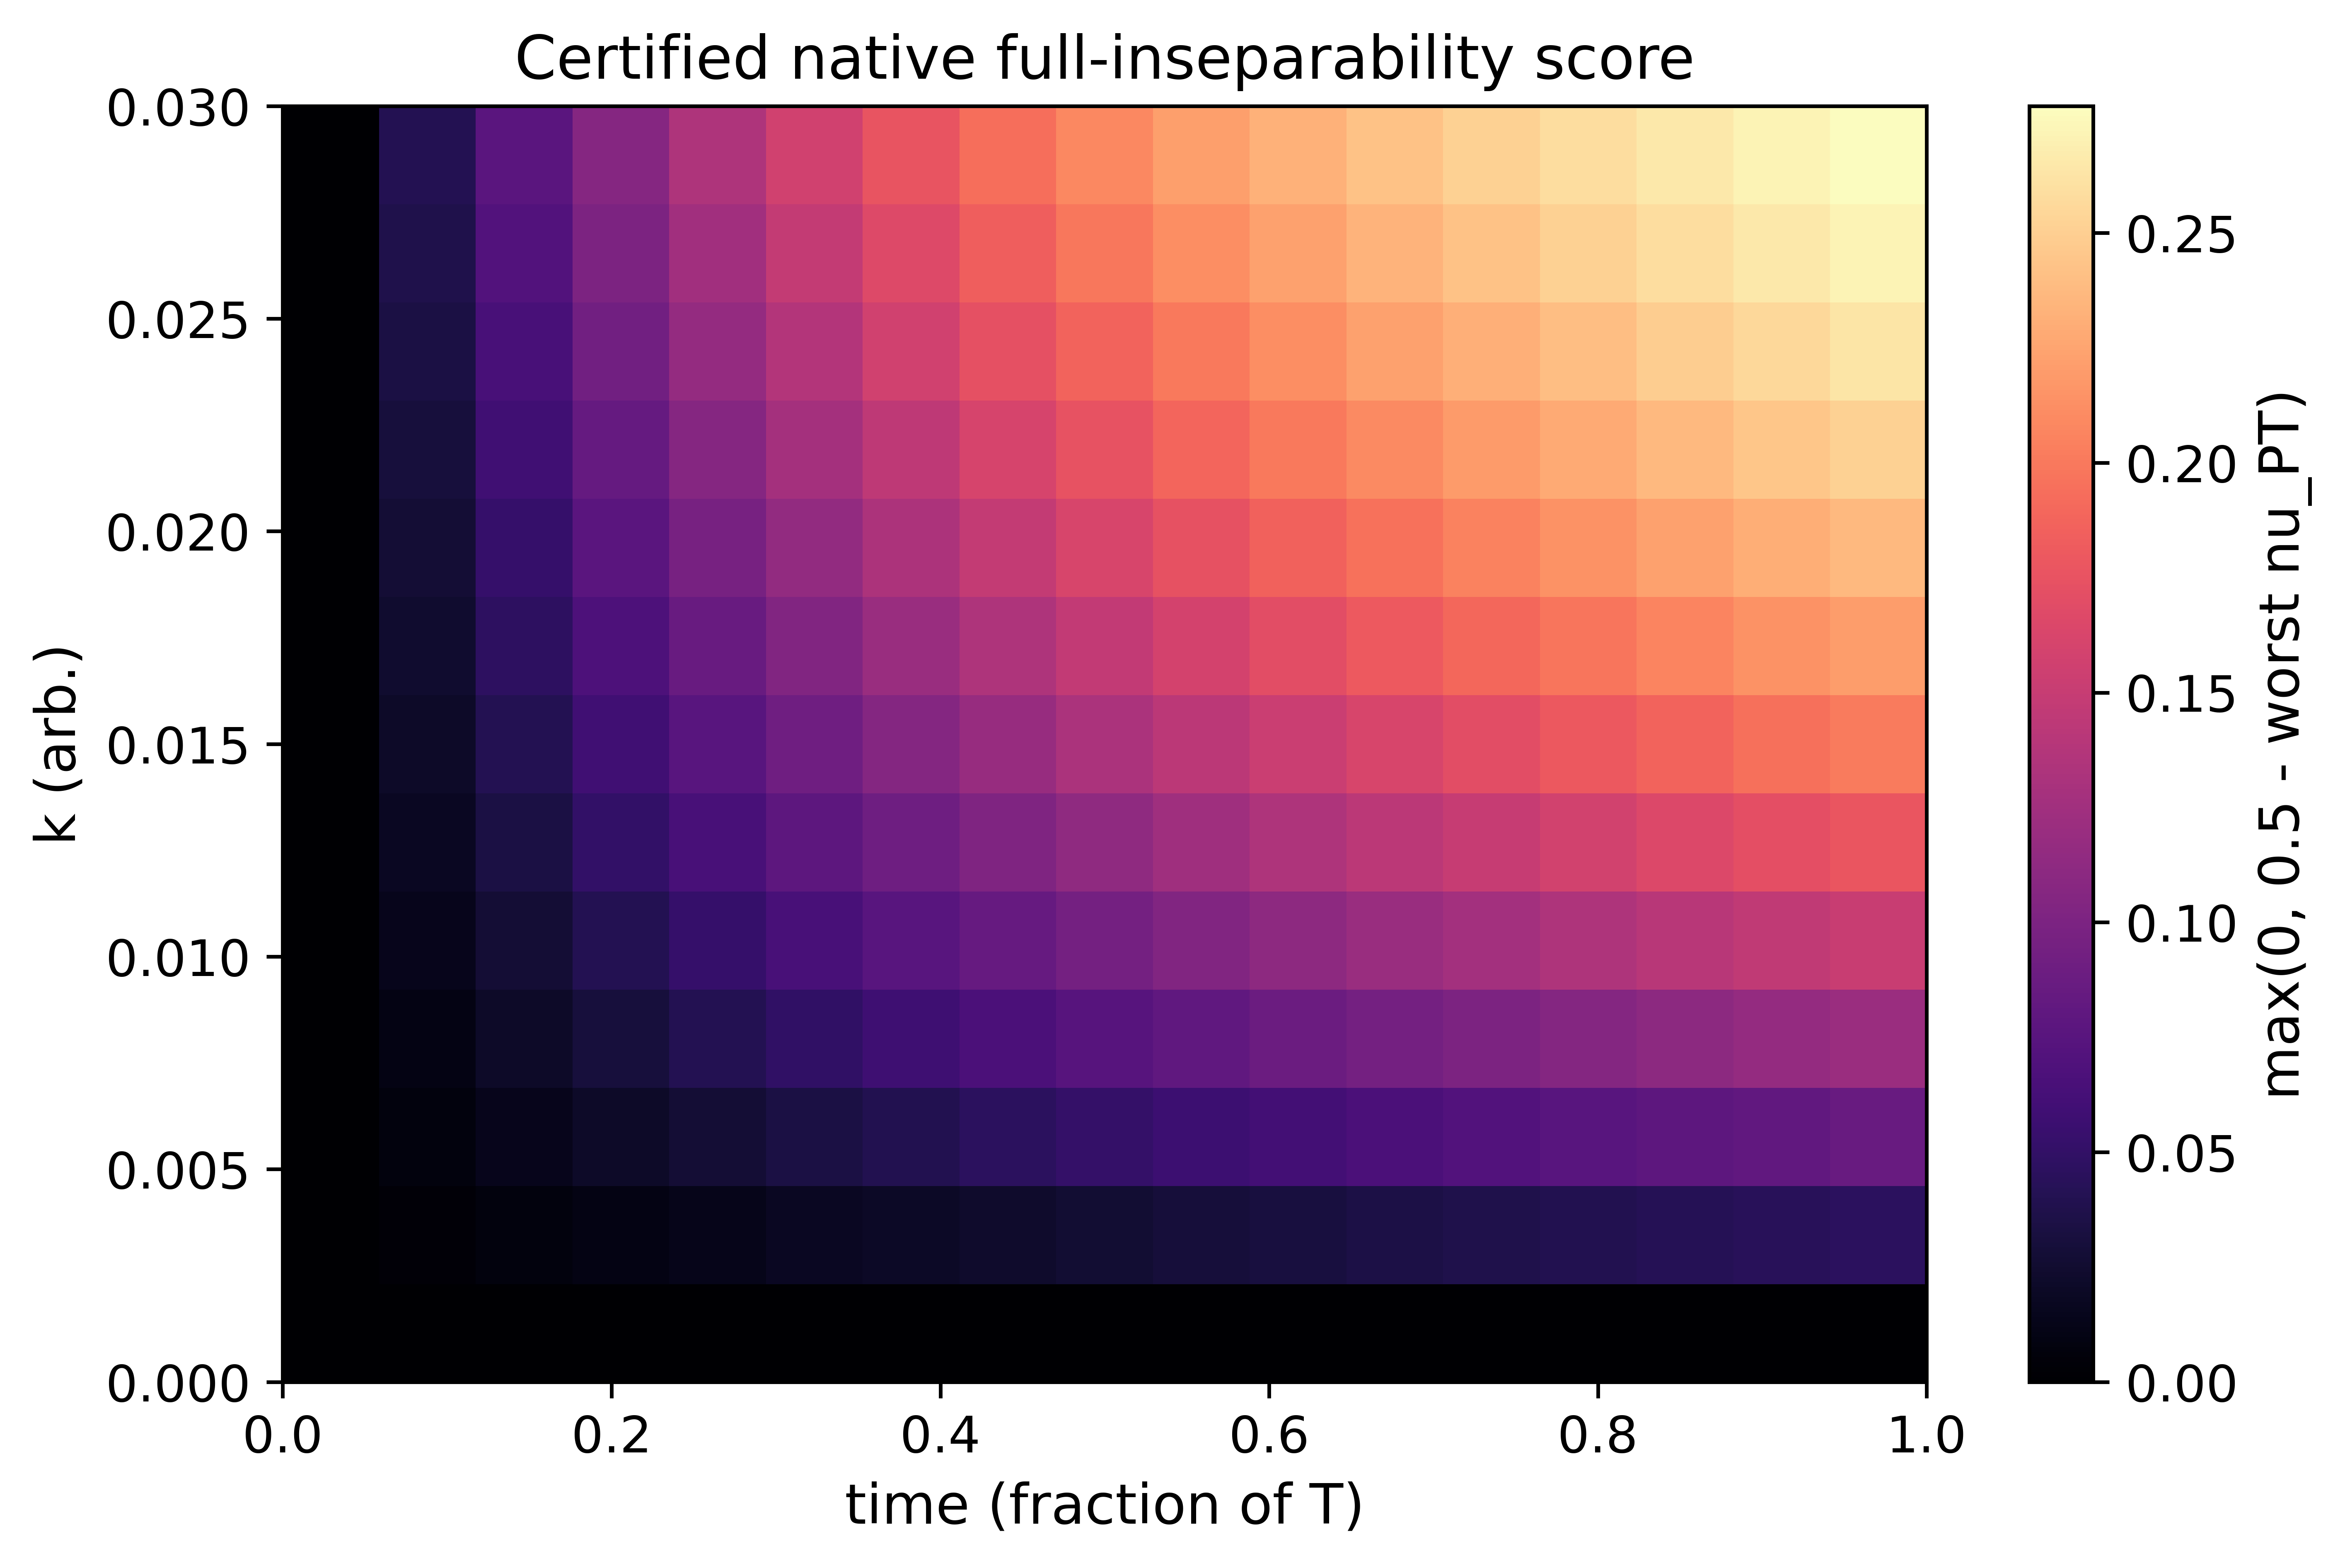

In [40]:
# Figure 5
args_str = """
  --mode none \
  --kmax 0.03 \
  --loops 4 \
  --alpha 5.00 5.00 5.00 5.00 \
  --sigma 5.00 10.00 20.00 \
  --kappa 5.00 10.00 20.00 \
  --Nvec 0.30 0 0 \
  --tip 0.05 \
  --pattern staggered \
  --ent 1 \
  --ent-save 1 \
  --ent-native-model frozen \
  --ent-native-source full \
  --ent-window 0.0:1.0 \
  --ent-NK 13 \
  --ent-NT 17 \
  --T 8.0 \
  --npts 2401 \
  --fig-dpi 800 \
  --fig-fontsize 12 \
  --fig-cmap magma \
  --fig-transparent 0 \
  --no-show 0
"""

_prev_argv = sys.argv[:] 
try:
    sys.argv = [sys.argv[0]] + shlex.split(args_str)
    main()
finally:
    sys.argv = _prev_argv

[info] Using loop corrections up to order: 0
[ent] Pair set (12 pairs): [(0, 1), (0, 3), (0, 4), (1, 2), (1, 5), (2, 3), (2, 6), (3, 7), (4, 5), (4, 7), (5, 6), (6, 7)]
[ent] Multipartite subset count: 56  partition mode: all
[ent] Native certification status: certified=1  classical_invariant=0  reason_code=2
[ent] Certified native entanglement is computed within a frozen-background canonical packet-mode Gaussian native model in spinpacket.py. The covariance is propagated directly in the packet tangent-mode basis (Q_j,P_j), with the frozen projected native packet generator used only as a comparison to the time-dependent packet-mode model. A packet-basis symplectic certification diagnostic is reported.
[ent] Certified native output is computed from the selected native linearized Gaussian M,N model on the selected time window.
[ent] Native Gaussian model settings: model=frozen  source=full  nth=0.100  nbath=0.000

[ent][certified] === Pairwise Gaussian summary (certified valid bins) ===


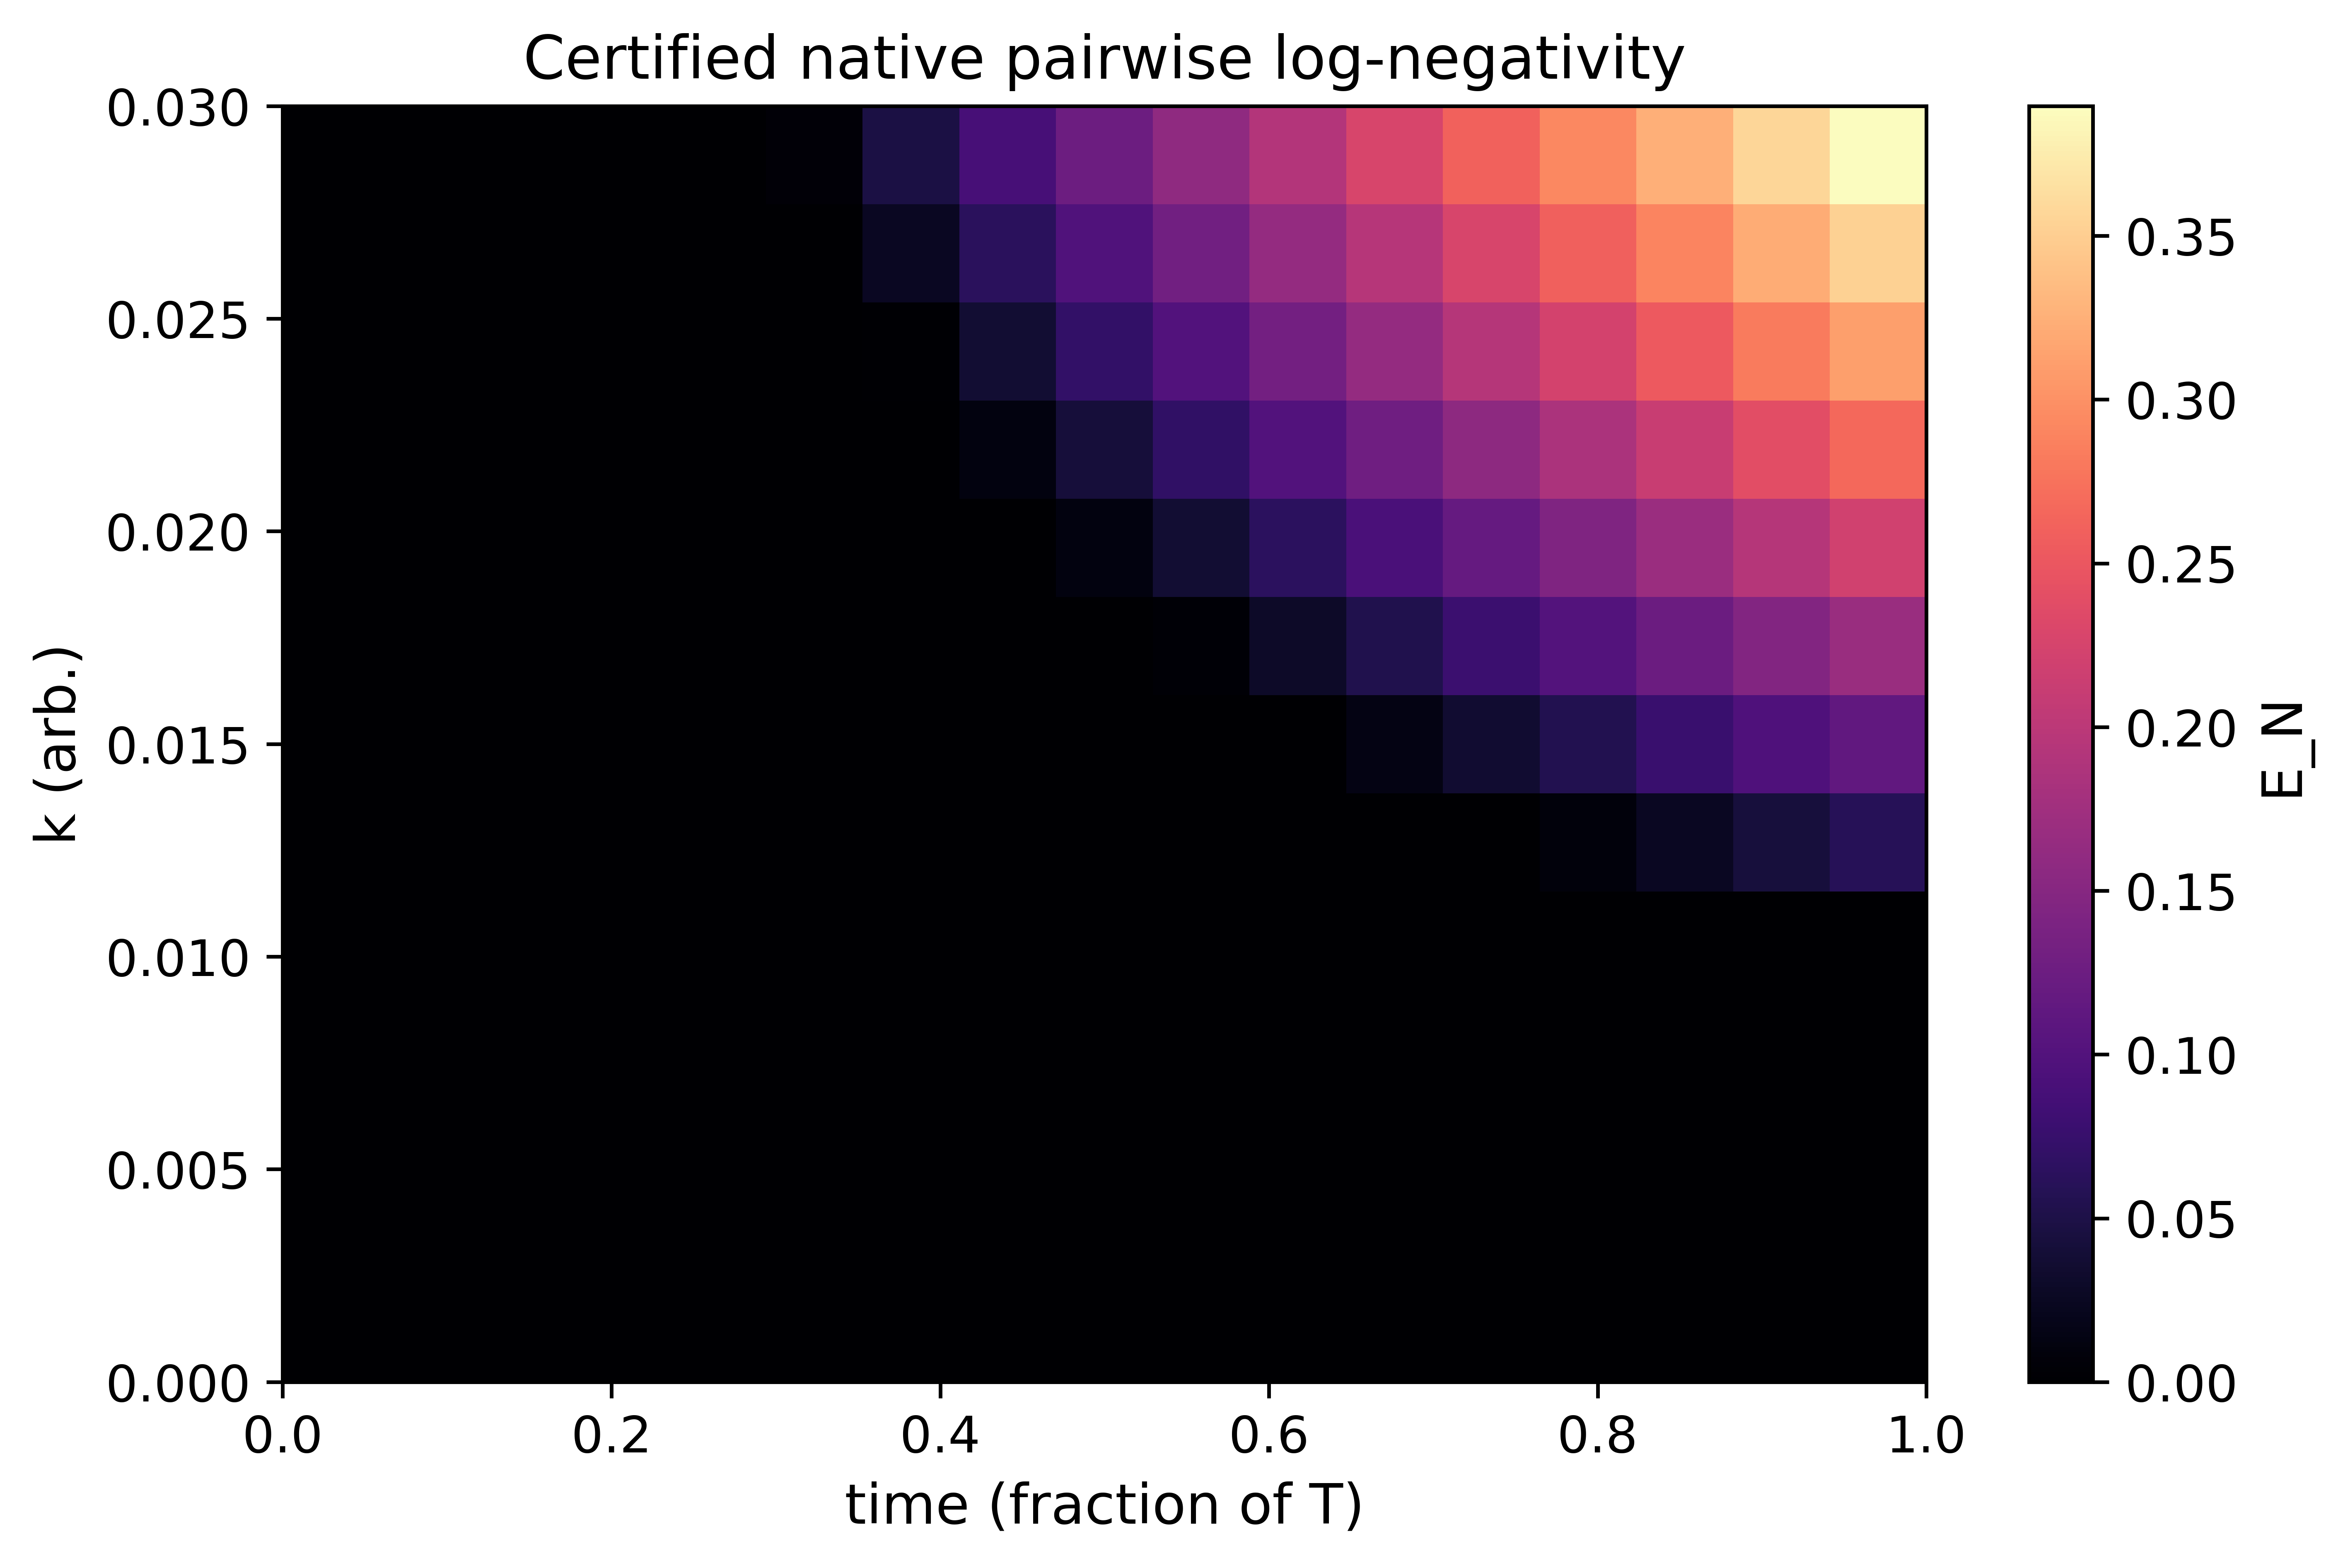

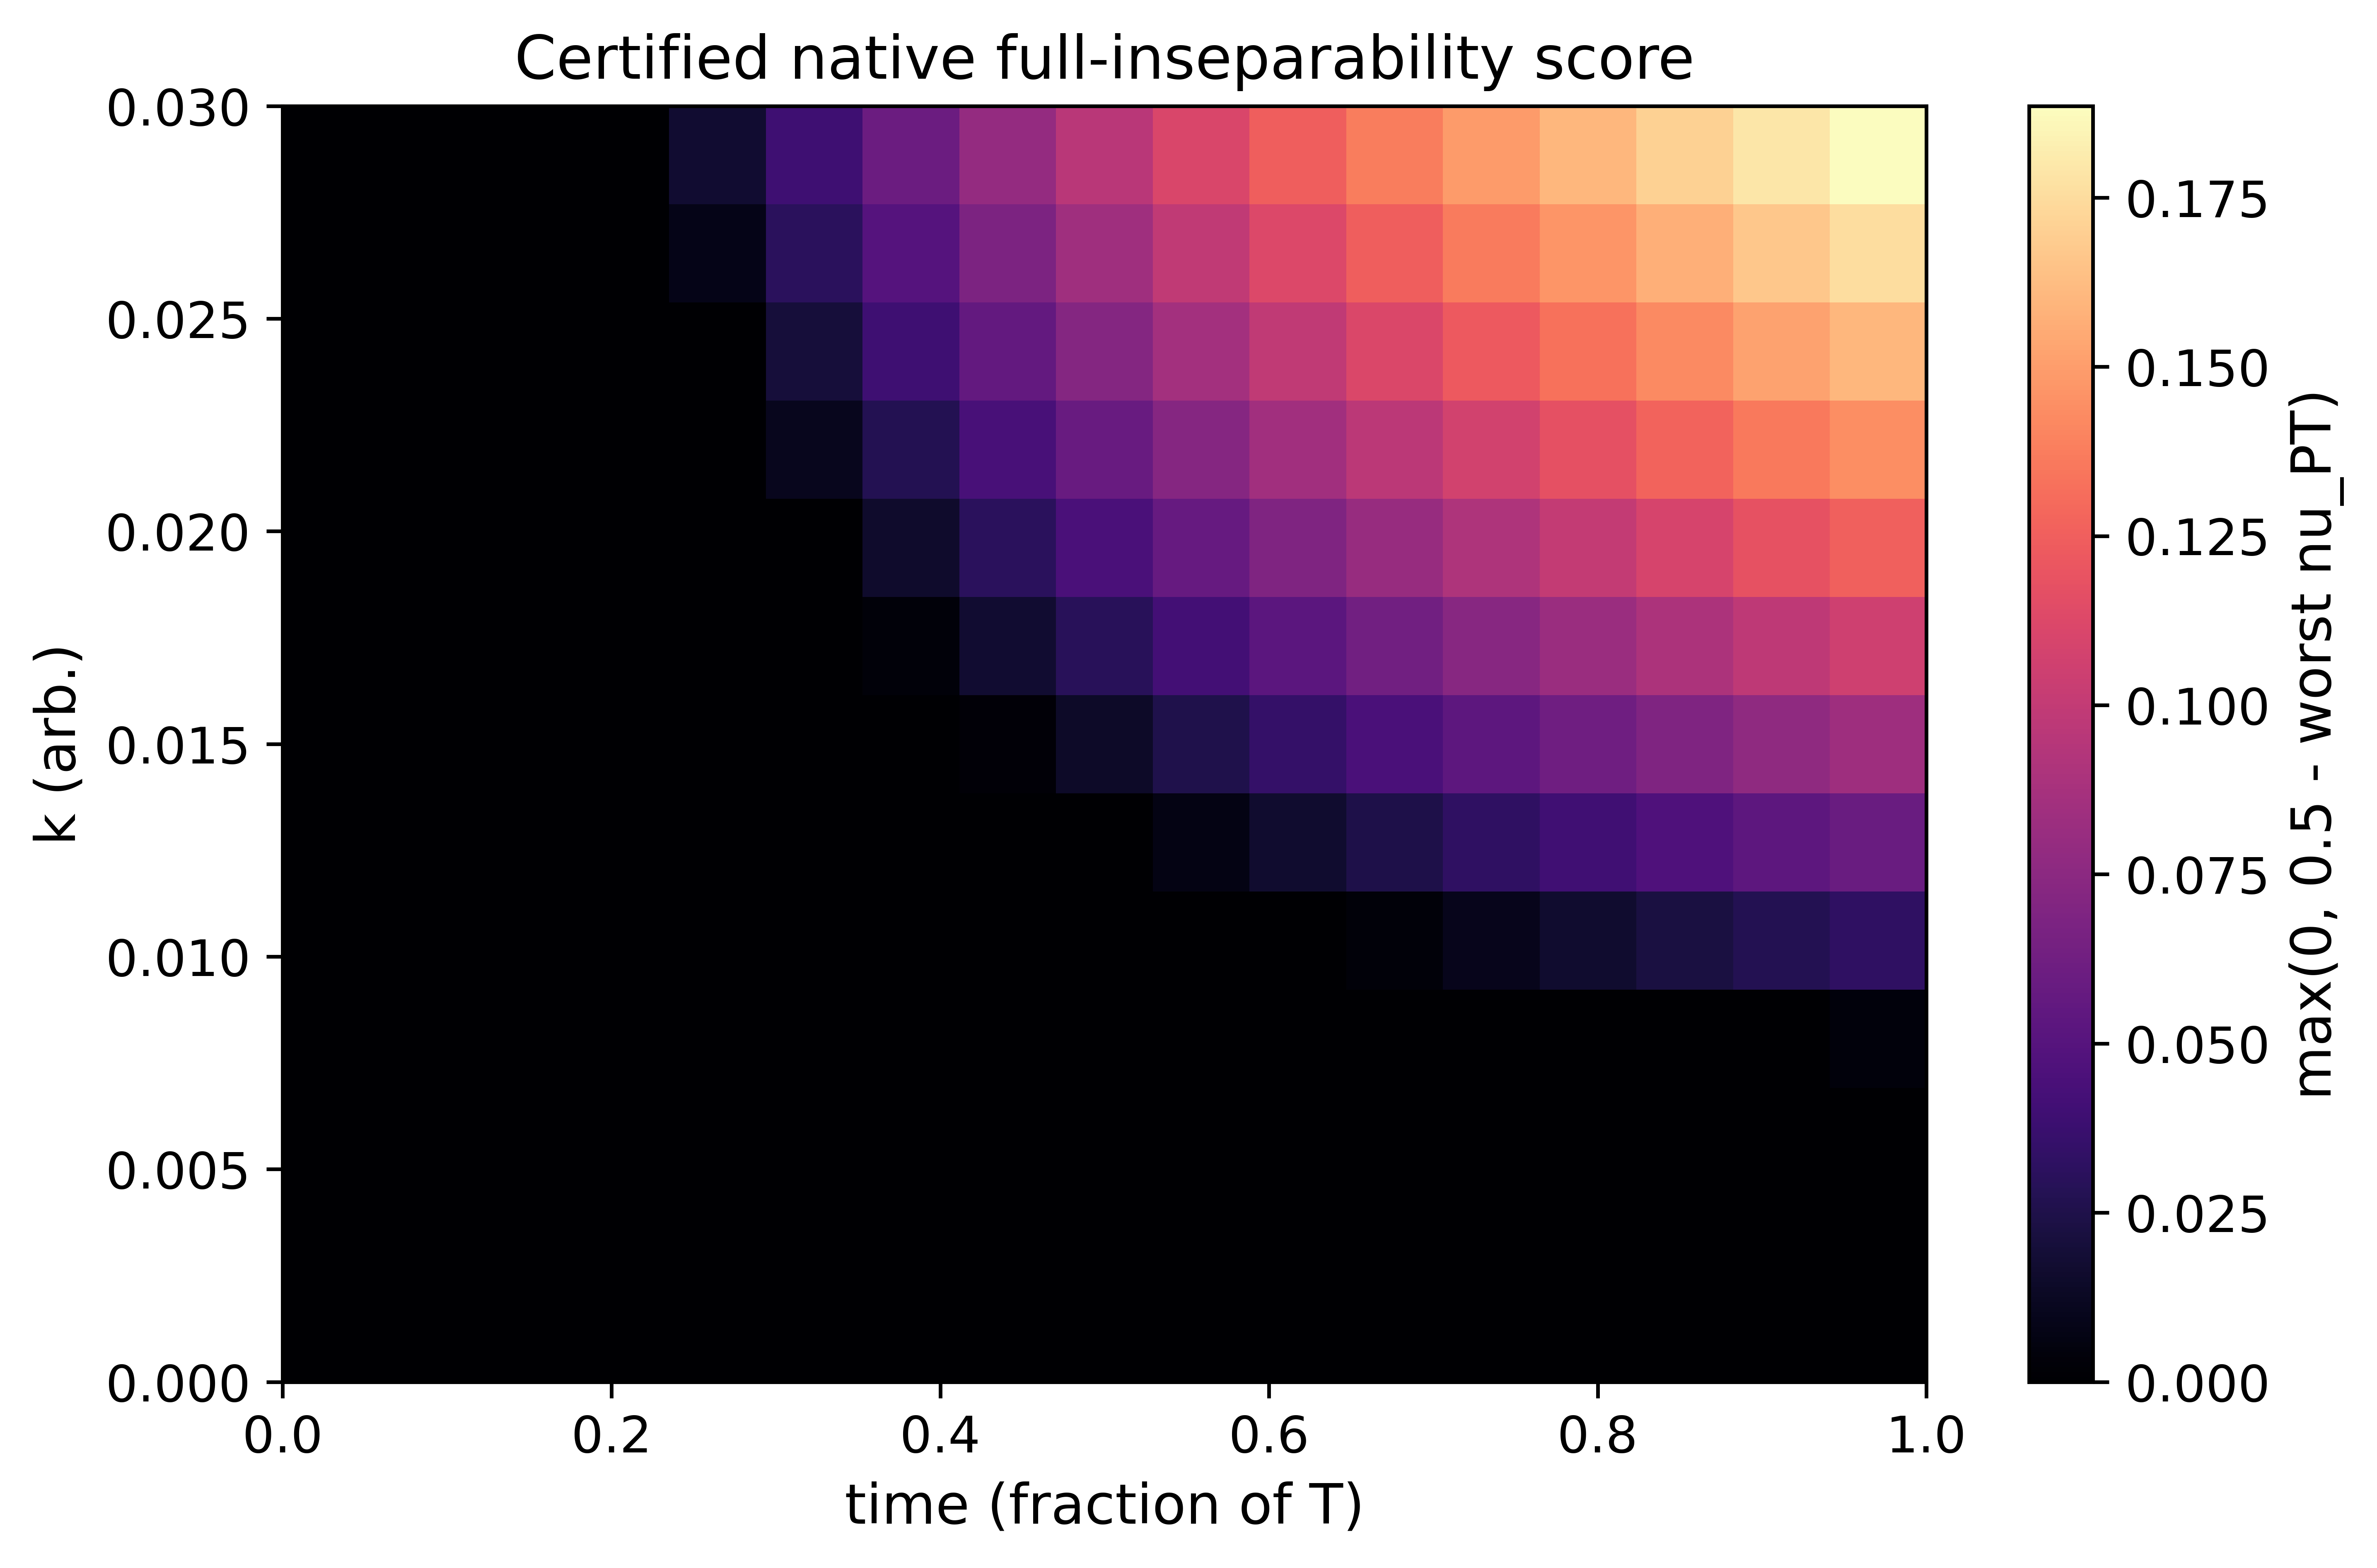

In [41]:
# Figure 6
args_str = """
  --mode none \
  --kmax 0.03 \
  --loops 0 \
  --Nvec 0.30 0 0 \
  --tip 0.05 \
  --pattern staggered \
  --ent 1 \
  --ent-layer both \
  --ent-save 1 \
  --ent-native-model frozen \
  --ent-native-source full \
  --ent-native-nth 0.10 \
  --ent-window 0.0:1.0 \
  --ent-NK 13 \
  --ent-NT 17 \
  --T 8.0 \
  --npts 2401 \
  --fig-dpi 800 \
  --fig-fontsize 12 \
  --fig-cmap magma \
  --fig-transparent 0 \
  --no-show 0
"""

_prev_argv = sys.argv[:] 
try:
    sys.argv = [sys.argv[0]] + shlex.split(args_str)
    main()
finally:
    sys.argv = _prev_argv